In [ ]:

import os
import glob
import pandas as pd

DATA_PATH = "/content"

csv_files = glob.glob(DATA_PATH + "/**/*.csv", recursive=True)

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))


CSV files found: 10
teams.csv
competition_team_player_mapping.csv
competitions.csv
ball_by_ball.csv
matches.csv
playing_eleven.csv
california_housing_test.csv
mnist_test.csv
mnist_train_small.csv
california_housing_train.csv


In [2]:

import os
import pandas as pd

required_files = [
    "ball_by_ball.csv",
    "matches.csv",
    "playing_eleven.csv",
    "competition_team_player_mapping.csv",
    "competitions.csv",
    "teams.csv"
]

DATA_PATH = "/content"

for filename in required_files:
    path = os.path.join(DATA_PATH, filename)

    if not os.path.exists(path):
        print("MISSING:", filename)
        continue

    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("ROWS & COLUMNS:", df.shape)
    print("COLUMN NAMES:", df.columns.tolist())
    print("MISSING VALUES:\n", df.isnull().sum().to_string())
    print("DATA TYPES:\n", df.dtypes.to_string())



FILE: ball_by_ball.csv
ROWS & COLUMNS: (200999, 33)
COLUMN NAMES: ['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time']
MISSING VALUES:
 match_id                    0
innings                     0
overid                      0
over_ball_num               0
innings_ball_num            0
batting_team_id             0
bowling_team_id             0
striker_id                  0
striker_name                0
non_striker_id              0
non_striker_name            0
bowler_id                   0
bowler_name                 0
batting_ty

In [3]:

for file in csv_files:
    df = pd.read_csv(file)

    print("\n" + "=" * 60)
    print("FILE:", os.path.basename(file))
    print("SHAPE:", df.shape)

    print("\nCOLUMNS:")
    print(df.columns.tolist())

    print("\nMISSING VALUES:")
    print(df.isnull().sum())

    print("\nDATA TYPES:")
    print(df.dtypes)



FILE: teams.csv
SHAPE: (353, 3)

COLUMNS:
['comp_id', 'team_id', 'team_name']

MISSING VALUES:
comp_id      0
team_id      0
team_name    0
dtype: int64

DATA TYPES:
comp_id       int64
team_id       int64
team_name    object
dtype: object

FILE: competition_team_player_mapping.csv
SHAPE: (6413, 6)

COLUMNS:
['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name']

MISSING VALUES:
comp_id        0
comp_name      0
team_id        0
team_name      0
player_id      0
player_name    0
dtype: int64

DATA TYPES:
comp_id         int64
comp_name      object
team_id         int64
team_name      object
player_id       int64
player_name    object
dtype: object

FILE: competitions.csv
SHAPE: (141, 4)

COLUMNS:
['comp_id', 'comp_name', 'match_format', 'season']

MISSING VALUES:
comp_id         0
comp_name       0
match_format    0
season          0
dtype: int64

DATA TYPES:
comp_id          int64
comp_name       object
match_format    object
season          object
dtype: object

In [4]:

import pandas as pd
import numpy as np
import os

DATA_PATH = "/content"

# Load all six competition datasets
files = {
    "balls": "ball_by_ball.csv",
    "matches": "matches.csv",
    "playing": "playing_eleven.csv",
    "mapping": "competition_team_player_mapping.csv",
    "competitions": "competitions.csv",
    "teams": "teams.csv"
}

data = {
    key: pd.read_csv(os.path.join(DATA_PATH, filename))
    for key, filename in files.items()
}

balls = data["balls"]
matches = data["matches"]
playing = data["playing"]
mapping = data["mapping"]
competitions = data["competitions"]

print("========== DATA VALIDATION ==========")

# 1. Duplicate deliveries
print("\n1. Duplicate delivery rows:")
print(balls.duplicated().sum())

# 2. Match and innings information
print("\n2. Innings distribution:")
print(balls["innings"].value_counts().sort_index())

# 3. Runs distribution
print("\n3. Runs distribution:")
print(balls["runs"].value_counts().sort_index())

# 4. Extras information
print("\n4. Extras types:")
print(balls["extras_type"].value_counts(dropna=False))

# 5. Dismissal types
print("\n5. Dismissal types:")
print(balls["dismissal_type"].value_counts(dropna=False))

# 6. Wicket flags
print("\n6. Wicket flag distribution:")
print(balls["is_wicket"].value_counts(dropna=False))

# 7. Competition formats
print("\n7. Competition formats:")
print(competitions["match_format"].value_counts())

# 8. Match results
print("\n8. Match results:")
print(matches["result"].value_counts(dropna=False).head(20))

# 9. Match dates
matches["match_date"] = pd.to_datetime(
    matches["match_date"], errors="coerce"
)

print("\n9. Match date range:")
print(matches["match_date"].min(), "to", matches["match_date"].max())

# 10. Missing match references
print("\n10. Ball records with unknown match IDs:")
print((~balls["match_id"].isin(matches["match_id"])).sum())

print("\n========== VALIDATION COMPLETE ==========")


========== DATA VALIDATION ==========

1. Duplicate delivery rows:
0

2. Innings distribution:
innings
1    105727
2     95234
3        25
4        13
Name: count, dtype: int64

3. Runs distribution:
runs
0    79387
1    72267
2    12547
3      656
4    23303
5       25
6    12814
Name: count, dtype: int64

4. Extras types:
extras_type
NaN         189167
wide          7714
legbyes       2748
Overstep       576
byes           529
other          264
Penalty          1
Name: count, dtype: int64

5. Dismissal types:
dismissal_type
NaN                      190118
Caught                     7557
Bowled                     1775
LBW                         709
RunOut                      600
Stump                       214
Hit Wicket                   17
Retire Out                    6
Obstracting the field         2
Obstructing the field         1
Name: count, dtype: int64

6. Wicket flag distribution:
is_wicket
False    190118
True      10881
Name: count, dtype: int64

7. Competition formats

In [5]:

# STEP 2.1: DEEP DATA VALIDATION

# 1. Inspect deliveries containing extras
print("\n===== EXTRAS SAMPLE =====")

print(
    balls.loc[
        balls["extras_type"].notna(),
        [
            "match_id", "innings", "overid",
            "runs", "extras_type",
            "extras1_runs", "extras_2_runs",
            "is_wicket", "dismissal_type"
        ]
    ].head(20).to_string(index=False)
)

# 2. Inspect all wicket deliveries
print("\n===== WICKET SAMPLE =====")

print(
    balls.loc[
        balls["is_wicket"],
        [
            "match_id", "innings", "overid",
            "striker_name", "bowler_name",
            "runs", "extras_type",
            "dismissal_type", "dismissed_player_id"
        ]
    ].head(20).to_string(index=False)
)

# 3. Identify matches with innings 3 or 4
print("\n===== SUPER OVER INVESTIGATION =====")

super_over = balls[balls["innings"] > 2]

print("Records in innings 3 and 4:", len(super_over))
print("Matches affected:", super_over["match_id"].nunique())
print(
    super_over.groupby(["match_id", "innings"])
    .size()
    .to_string()
)

# 4. Compare delivery runs and extras
print("\n===== RUNS AND EXTRAS SUMMARY =====")

print(
    balls.groupby("extras_type", dropna=False)[
        ["runs", "extras1_runs", "extras_2_runs"]
    ].agg(["count", "sum", "mean"]).to_string()
)

# 5. Check boundary flags
print("\n===== BOUNDARY VALIDATION =====")

print("Four flags:", balls["is_four"].sum())
print("Six flags:", balls["is_six"].sum())

print(
    balls.loc[
        (balls["is_four"]) | (balls["is_six"]),
        ["runs", "is_four", "is_six", "extras_type"]
    ].head(15).to_string(index=False)
)



===== EXTRAS SAMPLE =====
 match_id  innings  overid  runs extras_type  extras1_runs  extras_2_runs  is_wicket dismissal_type
    13511        1       7     0        wide             1              0      False            NaN
    13511        1       8     0        wide             1              0      False            NaN
    13511        1       8     0        wide             1              0      False            NaN
    13511        2       4     0     legbyes             4              0      False            NaN
    13511        2       7     0     legbyes             1              0      False            NaN
    13512        1      10     0        wide             1              0      False            NaN
    13512        1      10     0        wide             1              0      False            NaN
    13512        1      12     0        wide             1              0      False            NaN
    13512        1      14     0        wide             1              0

In [6]:

# STEP 2.2: RUNS, EXTRAS AND BOUNDARY INVESTIGATION

print("===== BOUNDARY MISMATCHES =====")

four_mismatch = balls[
    (balls["runs"] == 4) & (~balls["is_four"])
]

six_mismatch = balls[
    (balls["runs"] == 6) & (~balls["is_six"])
]

print("\nFour-run mismatches:", len(four_mismatch))
print(four_mismatch[
    ["match_id", "innings", "overid", "runs",
     "is_four", "is_six", "extras_type",
     "extras1_runs", "extras_2_runs"]
].head(30).to_string(index=False))

print("\nSix-run mismatches:", len(six_mismatch))
print(six_mismatch[
    ["match_id", "innings", "overid", "runs",
     "is_four", "is_six", "extras_type",
     "extras1_runs", "extras_2_runs"]
].head(20).to_string(index=False))


print("\n===== RUNS WITH EXTRAS =====")

print(
    balls.loc[
        balls["extras_type"].notna() & (balls["runs"] > 0),
        [
            "runs", "extras_type",
            "extras1_runs", "extras_2_runs",
            "is_four", "is_six"
        ]
    ].head(30).to_string(index=False)
)


print("\n===== RUNS WITHOUT EXTRAS =====")

print(
    balls.loc[
        balls["extras_type"].isna() & (balls["runs"] > 0),
        [
            "runs", "extras1_runs",
            "extras_2_runs", "is_four", "is_six"
        ]
    ].head(20).to_string(index=False)
)


print("\n===== DISMISSAL TYPE COUNTS =====")

print(
    balls.loc[balls["is_wicket"], "dismissal_type"]
    .value_counts(dropna=False)
)


print("\n===== BOWLER CREDIT INVESTIGATION =====")

print(
    balls.loc[
        balls["is_wicket"],
        ["dismissal_type", "bowler_name",
         "dismissed_player_id", "striker_id",
         "non_striker_id"]
    ].groupby("dismissal_type", dropna=False)
    .size()
)


===== BOUNDARY MISMATCHES =====

Four-run mismatches: 20
 match_id  innings  overid  runs  is_four  is_six extras_type  extras1_runs  extras_2_runs
    14113        1       1     4    False   False         NaN             0              0
    14123        1       3     4    False   False         NaN             0              0
    14149        1      12     4    False   False         NaN             0              0
    15609        2      17     4    False   False         NaN             0              0
    16425        2      13     4    False   False         NaN             0              0
    16754        1       6     4    False   False         NaN             0              0
    20236        2       2     4    False   False         NaN             0              0
    24350        2       6     4    False   False         NaN             0              0
    28958        1       3     4    False   False         NaN             0              0
    28959        1       5     4 

In [7]:

# STEP 2.3: VERIFY RUNS AND LEGAL DELIVERIES

# Keep original dataset unchanged
audit = balls.copy()

# 1. Calculate provisional team runs per delivery
audit["provisional_total_runs"] = (
    audit["runs"]
    + audit["extras1_runs"]
    + audit["extras_2_runs"]
)

print("===== TOTAL RUNS BY EXTRAS TYPE =====")

print(
    audit.groupby("extras_type", dropna=False)
    [["runs", "extras1_runs", "extras_2_runs",
      "provisional_total_runs"]]
    .sum()
    .to_string()
)

# 2. Inspect all extras categories and their run combinations
print("\n===== EXTRAS COMBINATIONS =====")

print(
    audit.groupby(
        ["extras_type", "extras1_runs", "extras_2_runs"],
        dropna=False
    ).size().sort_values(ascending=False).head(30)
)

# 3. Provisional legal delivery classification
audit["is_legal_ball_provisional"] = (
    ~audit["extras_type"].isin(["wide", "Overstep"])
)

print("\n===== PROVISIONAL LEGAL BALLS =====")

print(
    audit.groupby("extras_type", dropna=False)
    ["is_legal_ball_provisional"]
    .agg(["count", "sum"])
)

# 4. Dismissals not credited to bowler
not_bowler_credited = [
    "RunOut",
    "Retire Out",
    "Obstracting the field",
    "Obstructing the field"
]

audit["bowler_wicket_provisional"] = (
    audit["is_wicket"]
    & ~audit["dismissal_type"].isin(not_bowler_credited)
)

print("\n===== WICKET ATTRIBUTION =====")

print("Total wicket events:", audit["is_wicket"].sum())
print("Provisional bowler wickets:",
      audit["bowler_wicket_provisional"].sum())

# 5. Innings-level delivery and run summary
print("\n===== INNINGS SUMMARY =====")

print(
    audit.groupby(["match_id", "innings"])
    .agg(
        deliveries=("match_id", "size"),
        provisional_runs=("provisional_total_runs", "sum"),
        legal_balls=("is_legal_ball_provisional", "sum"),
        wickets=("is_wicket", "sum")
    )
    .head(15)
    .to_string()
)


===== TOTAL RUNS BY EXTRAS TYPE =====
               runs  extras1_runs  extras_2_runs  provisional_total_runs
extras_type                                                             
Overstep        852           576             48                    1476
Penalty           0             5              0                       5
byes              0          1000              0                    1000
legbyes           1          3603              0                    3604
other           412           264             35                     711
wide              0          9174              0                    9174
NaN          268285             1              1                  268287

===== EXTRAS COMBINATIONS =====
extras_type  extras1_runs  extras_2_runs
NaN          0             0                189165
wide         1             0                  7107
legbyes      1             0                  2376
Overstep     1             0                   555
byes         1             

In [8]:

# STEP 2.4: INVESTIGATE UNKNOWN EXTRAS AND INNINGS

print("===== OTHER EXTRAS DETAILS =====")

other = balls[balls["extras_type"] == "other"]

print(other[
    ["match_id", "innings", "overid", "runs",
     "extras1_runs", "extras_2_runs",
     "is_wicket", "dismissal_type"]
].to_string(index=False))


print("\n===== PENALTY DELIVERY =====")

print(
    balls[balls["extras_type"] == "Penalty"].to_string(index=False)
)


print("\n===== MISSING EXTRAS WITH NONZERO VALUES =====")

print(
    balls[
        balls["extras_type"].isna()
        & (
            (balls["extras1_runs"] != 0)
            | (balls["extras_2_runs"] != 0)
        )
    ].to_string(index=False)
)


print("\n===== INNINGS DELIVERY COUNTS =====")

innings_audit = (
    balls.groupby(["match_id", "innings"])
    .agg(
        rows=("match_id", "size"),
        legal_candidates=(
            "extras_type",
            lambda x: (~x.isin(["wide", "Overstep"])).sum()
        ),
        total_runs=(
            "runs", "sum"
        ),
        wickets=("is_wicket", "sum"),
        overs_recorded=("overid", "nunique")
    )
    .reset_index()
)

print(innings_audit.to_string(index=False))


print("\n===== OVER NUMBERING SAMPLE =====")

print(
    balls[balls["match_id"] == 13512][
        ["innings", "overid", "over_ball_num",
         "innings_ball_num", "extras_type"]
    ].head(30).to_string(index=False)
)


===== OTHER EXTRAS DETAILS =====
 match_id  innings  overid  runs  extras1_runs  extras_2_runs  is_wicket dismissal_type
    13513        1      10     0             1              0      False            NaN
    13515        1      16     0             1              0      False            NaN
    13515        2      19     2             1              0      False            NaN
    13614        1      18     0             1              4      False            NaN
    13614        2       2     0             1              0      False            NaN
    14094        1      19     6             1              0      False            NaN
    14098        2      20     0             1              0      False            NaN
    14101        1      17     0             1              0      False            NaN
    14102        2      19     0             1              0       True         RunOut
    14107        2      16     2             1              0      False            NaN

In [9]:

print("===== EXTRAS CATEGORY SUMMARY =====")

print(
    balls.groupby("extras_type", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        batter_runs=("runs", "sum"),
        extras1=("extras1_runs", "sum"),
        extras2=("extras_2_runs", "sum"),
        wickets=("is_wicket", "sum")
    )
    .to_string()
)

print("\n===== OTHER EXTRAS COMBINATIONS =====")

print(
    balls[balls["extras_type"] == "other"]
    .groupby(
        ["runs", "extras1_runs", "extras_2_runs", "is_wicket"],
        dropna=False
    ).size().sort_values(ascending=False).to_string()
)

print("\n===== PENALTY RECORD =====")

print(
    balls[balls["extras_type"] == "Penalty"][
        ["match_id", "innings", "overid", "runs",
         "extras1_runs", "extras_2_runs",
         "is_wicket", "dismissal_type"]
    ].to_string(index=False)
)

print("\n===== NULL EXTRAS WITH NONZERO EXTRAS =====")

print(
    balls[
        balls["extras_type"].isna()
        & (
            (balls["extras1_runs"] != 0)
            | (balls["extras_2_runs"] != 0)
        )
    ][
        ["match_id", "innings", "runs",
         "extras1_runs", "extras_2_runs"]
    ].to_string(index=False)
)

print("\n===== INNINGS 3 AND 4 MATCH DETAILS =====")

print(
    matches[matches["match_id"].isin(
        balls.loc[balls["innings"] > 2, "match_id"].unique()
    )][
        ["match_id", "match_date", "home_team",
         "away_team", "result"]
    ].to_string(index=False)
)


===== EXTRAS CATEGORY SUMMARY =====
             deliveries  batter_runs  extras1  extras2  wickets
extras_type                                                    
Overstep            576          852      576       48        5
Penalty               1            0        5        0        0
byes                529            0     1000        0        1
legbyes            2748            1     3603        0        0
other               264          412      264       35        3
wide               7714            0     9174        0       40
NaN              189167       268285        1        1    10832

===== OTHER EXTRAS COMBINATIONS =====
runs  extras1_runs  extras_2_runs  is_wicket
0     1             0              False        111
1     1             0              False         49
4     1             0              False         42
6     1             0              False         26
2     1             0              False         18
0     1             1              False    

In [10]:

# STEP 2.5: FINAL EXTRAS AND DISMISSAL INVESTIGATION

print("===== WICKETS BY EXTRAS CATEGORY =====")

print(
    balls[balls["is_wicket"]]
    .groupby(
        ["extras_type", "dismissal_type"],
        dropna=False
    ).size().to_string()
)


print("\n===== OTHER EXTRAS WITH WICKETS =====")

print(
    balls[
        (balls["extras_type"] == "other")
        & balls["is_wicket"]
    ][
        ["match_id", "innings", "overid",
         "runs", "extras1_runs", "extras_2_runs",
         "dismissal_type", "striker_name",
         "bowler_name"]
    ].to_string(index=False)
)


print("\n===== ALL OTHER EXTRAS EXAMPLES =====")

print(
    balls[balls["extras_type"] == "other"][
        ["match_id", "innings", "overid",
         "runs", "extras1_runs", "extras_2_runs",
         "is_wicket", "dismissal_type"]
    ].head(40).to_string(index=False)
)


print("\n===== TWO MISSING EXTRAS RECORDS =====")

anomalies = balls[
    balls["extras_type"].isna()
    & (
        (balls["extras1_runs"] != 0)
        | (balls["extras_2_runs"] != 0)
    )
]

print(
    anomalies[
        ["match_id", "innings", "overid",
         "over_ball_num", "innings_ball_num",
         "striker_name", "bowler_name",
         "runs", "extras1_runs", "extras_2_runs"]
    ].to_string(index=False)
)


print("\n===== PENALTY MATCH CONTEXT =====")

print(
    matches[matches["match_id"] == 16753].to_string(index=False)
)


===== WICKETS BY EXTRAS CATEGORY =====
extras_type  dismissal_type       
Overstep     RunOut                      5
byes         RunOut                      1
other        RunOut                      3
wide         RunOut                     15
             Stump                      25
NaN          Bowled                   1775
             Caught                   7557
             Hit Wicket                 17
             LBW                       709
             Obstracting the field       2
             Obstructing the field       1
             Retire Out                  6
             RunOut                    576
             Stump                     189

===== OTHER EXTRAS WITH WICKETS =====
 match_id  innings  overid  runs  extras1_runs  extras_2_runs dismissal_type         striker_name     bowler_name
    14102        2      19     0             1              0         RunOut       Kieron Pollard Prasidh Krishna
    14145        1      19     0             1           

In [11]:

# STEP 2.6 — FINAL EXTRAS AND DELIVERY SEQUENCE CHECKS

# 1. Inspect other extras by delivery style and bowling speed
other = balls[balls["extras_type"] == "other"]

print("OTHER EXTRAS — DELIVERY STYLE")
print(other["delivery_style"].value_counts(dropna=False).to_string())

print("\nOTHER EXTRAS — BOWLING SPEED")
print(other["bowl_speed"].describe().to_string())

# 2. Inspect the three other-extras wicket events
print("\nOTHER EXTRAS WICKETS")
print(
    other[other["is_wicket"]][[
        "match_id", "innings", "overid", "over_ball_num",
        "innings_ball_num", "runs", "extras1_runs",
        "extras_2_runs", "dismissal_type", "delivery_style"
    ]].to_string(index=False)
)

# 3. Inspect delivery sequence around the two missing extras records
for mid in [17555, 36097]:
    print(f"\nMATCH {mid} — NEIGHBOURING DELIVERIES")

    anomaly = balls[
        balls["match_id"].eq(mid)
        & balls["extras_type"].isna()
        & (
            balls["extras1_runs"].ne(0)
            | balls["extras_2_runs"].ne(0)
        )
    ]

    for _, row in anomaly.iterrows():
        nearby = balls[
            balls["match_id"].eq(mid)
            & balls["innings"].eq(row["innings"])
            & balls["innings_ball_num"].between(
                row["innings_ball_num"] - 2,
                row["innings_ball_num"] + 2
            )
        ]

        print(nearby[[
            "overid", "over_ball_num", "innings_ball_num",
            "striker_name", "bowler_name", "runs",
            "extras_type", "extras1_runs", "extras_2_runs",
            "is_wicket", "dismissal_type"
        ]].to_string(index=False))

# 4. Check the penalty event's delivery sequence
print("\nPENALTY EVENT")
print(
    balls[
        balls["match_id"].eq(16753)
        & (
            balls["extras_type"].eq("Penalty")
            | balls["extras1_runs"].eq(5)
        )
    ][[
        "innings", "overid", "over_ball_num", "innings_ball_num",
        "striker_name", "bowler_name", "runs",
        "extras_type", "extras1_runs", "extras_2_runs"
    ]].to_string(index=False)
)


OTHER EXTRAS — DELIVERY STYLE
delivery_style
Beamer               116
Full Toss             72
Bouncer               16
Slow Bouncer           8
Off Cutter             7
Seamed In              6
Back of Hand           5
Leg Cut                3
Googly                 3
Leg Break              3
Off Break              3
Yorker                 3
Straight               2
Orthodox               2
Knuckle                2
Seamed Out             2
Angled In              2
Out Swing              2
NaN                    1
Reverse Swing Out      1
Wide Yorker            1
Flipper                1
Arm ball               1
Carrom                 1
Inswing                1

OTHER EXTRAS — BOWLING SPEED
count    264.000000
mean      57.556212
std       64.485922
min        0.000000
25%        0.000000
50%        0.000000
75%      131.550000
max      147.900000

OTHER EXTRAS WICKETS
 match_id  innings  overid  over_ball_num  innings_ball_num  runs  extras1_runs  extras_2_runs dismissal_type delivery

In [12]:

import numpy as np
import pandas as pd

clean = balls.copy()

clean["extras_type_clean"] = (
    clean["extras_type"].astype("string").str.strip().str.lower()
)

clean["is_penalty_event"] = (
    clean["extras_type_clean"].eq("penalty").fillna(False)
)

clean["is_missing_extras_anomaly"] = (
    clean["extras_type"].isna()
    & (
        clean["extras1_runs"].fillna(0).ne(0)
        | clean["extras_2_runs"].fillna(0).ne(0)
    )
)

clean["is_unresolved_other"] = (
    clean["extras_type_clean"].eq("other").fillna(False)
)

# Convert conditions to standard NumPy Boolean arrays
conditions = [
    clean["is_penalty_event"].to_numpy(dtype=bool),
    clean["extras_type_clean"].isin(["wide", "overstep"]).to_numpy(dtype=bool),
    clean["extras_type_clean"].isin(["byes", "legbyes"]).to_numpy(dtype=bool),
    clean["is_unresolved_other"].to_numpy(dtype=bool),
    clean["is_missing_extras_anomaly"].to_numpy(dtype=bool)
]

clean["legal_ball_status"] = np.select(
    conditions,
    [
        "not_a_delivery",
        "illegal",
        "legal",
        "unresolved",
        "unresolved"
    ],
    default="provisional_legal"
)

# Bowler-creditable wickets
bowler_dismissals = [
    "Bowled", "Caught", "LBW", "Stump", "Hit Wicket"
]

clean["bowler_wicket"] = (
    clean["is_wicket"].fillna(False).astype(bool)
    & clean["dismissal_type"].isin(bowler_dismissals)
)

# Batter boundaries
clean["batter_four"] = clean["runs"].eq(4)
clean["batter_six"] = clean["runs"].eq(6)

# Exclude penalty events from player delivery statistics
clean["include_in_player_delivery_stats"] = (
    ~clean["is_penalty_event"]
)

# Audit
print("===== CLEANING AUDIT =====")
print("Original rows:", len(balls))
print("Working rows:", len(clean))

print("\nLegal-ball status:")
print(clean["legal_ball_status"].value_counts(dropna=False))

print("\nBowler-creditable wickets:", clean["bowler_wicket"].sum())
print("Total wicket events:", clean["is_wicket"].sum())

print("\nPenalty events:", clean["is_penalty_event"].sum())
print("Unresolved other events:", clean["is_unresolved_other"].sum())
print("Missing extras anomalies:", clean["is_missing_extras_anomaly"].sum())

print("\nBoundary counts:")
print("Fours:", clean["batter_four"].sum())
print("Sixes:", clean["batter_six"].sum())


===== CLEANING AUDIT =====
Original rows: 200999
Working rows: 200999

Legal-ball status:
legal_ball_status
provisional_legal    189165
illegal                8290
legal                  3277
unresolved              266
not_a_delivery            1
Name: count, dtype: int64

Bowler-creditable wickets: 10272
Total wicket events: 10881

Penalty events: 1
Unresolved other events: 264
Missing extras anomalies: 2

Boundary counts:
Fours: 23303
Sixes: 12814


In [13]:
import pandas as pd

teams = pd.read_csv("/content/teams.csv")

print("Teams loaded:", teams.shape)
print(teams.head())
print([name for name in ["balls", "clean", "matches", "competitions", "teams"]
       if name in globals()])

Teams loaded: (353, 3)
   comp_id  team_id    team_name
0     1331       22      England
1     1331       28  West Indies
2     1335       18        India
3     1335       28  West Indies
4     1345       20    Australia
['balls', 'clean', 'matches', 'competitions', 'teams']


In [14]:

# STEP 2.9 — INNINGS RECONSTRUCTION

# Merge competition format and season
innings_data = clean.merge(
    matches[["match_id", "comp_id", "match_date", "venue_country"]],
    on="match_id",
    how="left",
    validate="many_to_one"
)

innings_data = innings_data.merge(
    competitions[["comp_id", "comp_name", "match_format", "season"]],
    on="comp_id",
    how="left",
    validate="many_to_one"
)

# Team names
team_lookup = (
    teams[["comp_id", "team_id", "team_name"]]
    .drop_duplicates()
)

innings_data = innings_data.merge(
    team_lookup.rename(columns={
        "team_id": "batting_team_id",
        "team_name": "batting_team"
    }),
    on=["comp_id", "batting_team_id"],
    how="left"
)

# Runs: batter runs + both extras columns
innings_data["total_delivery_runs"] = (
    innings_data["runs"].fillna(0)
    + innings_data["extras1_runs"].fillna(0)
    + innings_data["extras_2_runs"].fillna(0)
)

# Include penalty in team innings total, but not player delivery statistics
innings_summary = (
    innings_data.groupby(
        ["match_id", "innings", "comp_name", "match_format",
         "season", "match_date", "batting_team"],
        dropna=False
    )
    .agg(
        total_runs=("total_delivery_runs", "sum"),
        batter_runs=("runs", "sum"),
        extras_runs=("extras1_runs", "sum"),
        extras2_runs=("extras_2_runs", "sum"),
        wickets=("is_wicket", "sum"),
        provisional_legal_balls=(
            "legal_ball_status",
            lambda x: (x == "provisional_legal").sum()
                    + (x == "legal").sum()
        ),
        illegal_balls=(
            "legal_ball_status",
            lambda x: (x == "illegal").sum()
        ),
        unresolved_balls=(
            "legal_ball_status",
            lambda x: (x == "unresolved").sum()
        ),
        penalty_events=("is_penalty_event", "sum"),
        recorded_rows=("match_id", "size")
    )
    .reset_index()
)

# Display selected innings
print("===== INNINGS SUMMARY SAMPLE =====")
print(innings_summary.head(20).to_string(index=False))

print("\n===== TOTALS AND DELIVERY COUNTS =====")
print(innings_summary[
    ["total_runs", "wickets", "provisional_legal_balls",
     "illegal_balls", "unresolved_balls"]
].describe().round(2).to_string())

print("\n===== INNINGS 3 AND 4 =====")
print(
    innings_summary[
        innings_summary["innings"].isin([3, 4])
    ].to_string(index=False)
)

print("\n===== MISSING TEAM NAMES =====")
print(
    innings_summary[innings_summary["batting_team"].isna()][
        ["match_id", "innings", "comp_name"]
    ].to_string(index=False)
)


===== INNINGS SUMMARY SAMPLE =====
 match_id  innings                               comp_name match_format season match_date batting_team  total_runs  batter_runs  extras_runs  extras2_runs  wickets  provisional_legal_balls  illegal_balls  unresolved_balls  penalty_events  recorded_rows
    13511        1 England in West Indies T20I Series 2022         T20I   2022 2022-01-22      England         103          100            3             0       10                      118              3                 0               0            121
    13511        2 England in West Indies T20I Series 2022         T20I   2022 2022-01-22  West Indies         104           99            5             0        1                      103              0                 0               0            103
    13512        1 England in West Indies T20I Series 2022         T20I   2022 2022-01-23      England         171          163            8             0        8                      120              8   

In [15]:

# STEP 2.10 — COMPETITION SCOPE AUDIT

print("===== ALL COMPETITIONS =====")
print(
    competitions.sort_values(["match_format", "season", "comp_name"])[
        ["comp_id", "comp_name", "match_format", "season"]
    ].to_string(index=False)
)

print("\n===== FORMAT DISTRIBUTION =====")
print(competitions["match_format"].value_counts(dropna=False))

print("\n===== INNINGS BY FORMAT =====")
print(
    innings_summary.groupby("match_format").agg(
        innings=("match_id", "size"),
        matches=("match_id", "nunique"),
        average_runs=("total_runs", "mean"),
        average_wickets=("wickets", "mean")
    ).round(2).to_string()
)

print("\n===== IPL COMPETITIONS =====")
print(
    competitions[
        competitions["comp_name"].str.contains(
            "IPL|Indian Premier League",
            case=False,
            na=False
        )
    ].to_string(index=False)
)

print("\n===== REGULATION INNINGS COUNT =====")
print(
    innings_summary[innings_summary["innings"].isin([1, 2])]
    .groupby("match_format")
    .size()
)


===== ALL COMPETITIONS =====
 comp_id                                               comp_name match_format  season
    1358                                                IPL 2022          T20    2022
    1715                                                IPL 2023          T20    2023
    2193                                                IPL 2024          T20    2024
    2670                   Mens T20 Emerging Teams Asia Cup 2024          T20    2024
    3289                              Asia Cup Rising Stars 2025          T20    2025
    2725                                                IPL 2025          T20    2025
    3298                                                IPL 2026          T20    2026
    1543                 Afghanistan in Ireland T20I Series 2022         T20I    2022
    1458                Afghanistan in Zimbabwe T20I Series 2022         T20I    2022
    1551                            Asia Cup T20 Qualifiers 2022         T20I    2022
    1584                 

In [16]:

# STEP 2.11 — FINAL COMPETITION FILTER

# IPL competitions only
ipl_comp_ids = competitions.loc[
    competitions["comp_name"].str.contains(
        r"\bIPL\b", case=False, na=False
    ),
    "comp_id"
].unique()

# All T20I competitions
t20i_comp_ids = competitions.loc[
    competitions["match_format"].eq("T20I"),
    "comp_id"
].unique()

# Exclude Super Overs (innings 1 and 2 only)
analysis = innings_data[
    innings_data["innings"].isin([1, 2])
].copy()

# Keep IPL and T20I only
analysis = analysis[
    analysis["comp_id"].isin(
        list(ipl_comp_ids) + list(t20i_comp_ids)
    )
].copy()

analysis["analysis_format"] = np.where(
    analysis["comp_id"].isin(ipl_comp_ids),
    "IPL",
    "T20I"
)

print("===== FINAL ANALYSIS POPULATION =====")

print(
    analysis.groupby("analysis_format").agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        competitions=("comp_id", "nunique"),
        players=("striker_id", "nunique")
    ).to_string()
)

print("\n===== IPL SEASON COVERAGE =====")
print(
    analysis[analysis["analysis_format"] == "IPL"]
    .groupby("season")
    .agg(
        matches=("match_id", "nunique"),
        deliveries=("match_id", "size")
    ).to_string()
)

print("\n===== T20I SEASON COVERAGE =====")
print(
    analysis[analysis["analysis_format"] == "T20I"]
    .groupby("season")
    .agg(
        matches=("match_id", "nunique"),
        deliveries=("match_id", "size")
    ).to_string()
)

print("\n===== EXCLUDED T20 COMPETITIONS =====")
print(
    competitions[
        competitions["match_format"].eq("T20")
        & ~competitions["comp_id"].isin(ipl_comp_ids)
    ][["comp_id", "comp_name", "season"]].to_string(index=False)
)


===== FINAL ANALYSIS POPULATION =====
                 deliveries  matches  competitions  players
analysis_format                                            
IPL                   87673      367             5      341
T20I                 106315      470           131      665

===== IPL SEASON COVERAGE =====
        matches  deliveries
season                     
2022         74       17909
2023         74       17863
2024         71       17103
2025         74       17275
2026         74       17523

===== T20I SEASON COVERAGE =====
         matches  deliveries
season                      
2022          94       21718
2022/23       12        2838
2023          63       14386
2023/24        3         739
2024         104       23667
2024/25        3         754
2025         121       26654
2026          70       15559

===== EXCLUDED T20 COMPETITIONS =====
 comp_id                             comp_name season
    2670 Mens T20 Emerging Teams Asia Cup 2024   2024
    3289            As

In [17]:

# STEP 3.1 — BUILD SECOND-INNINGS CHASE CONTEXT

# Build match-level innings totals from the analysis deliveries
match_innings = (
    analysis.groupby(["match_id", "innings"], as_index=False)
    .agg(
        innings_runs=("total_delivery_runs", "sum"),
        innings_wickets=("is_wicket", "sum"),
        batting_team_id=("batting_team_id", "first"),
        competition=("analysis_format", "first"),
        comp_id=("comp_id", "first")
    )
)

# First-innings totals
first_innings = (
    match_innings[match_innings["innings"] == 1]
    [["match_id", "innings_runs", "batting_team_id"]]
    .rename(columns={
        "innings_runs": "first_innings_runs",
        "batting_team_id": "first_batting_team_id"
    })
)

# Second-innings totals
second_innings = (
    match_innings[match_innings["innings"] == 2]
    [["match_id", "innings_runs", "batting_team_id"]]
    .rename(columns={
        "innings_runs": "second_innings_runs",
        "batting_team_id": "second_batting_team_id"
    })
)

# Attach match metadata, including revised targets
chase_context = (
    matches[[
        "match_id", "revised_target", "first_inn_revised_overs",
        "second_inn_revised_overs", "win_team_id", "result"
    ]]
    .merge(first_innings, on="match_id", how="inner")
    .merge(second_innings, on="match_id", how="inner")
)

# A revised target takes precedence when present
chase_context["target"] = np.where(
    chase_context["revised_target"].notna(),
    chase_context["revised_target"],
    chase_context["first_innings_runs"] + 1
)

chase_context["runs_required"] = (
    chase_context["target"] - chase_context["second_innings_runs"]
).clip(lower=0)

print("===== CHASE CONTEXT AUDIT =====")
print("Chases:", len(chase_context))
print("IPL chases:", (chase_context["match_id"].isin(
    analysis.loc[analysis["analysis_format"] == "IPL", "match_id"].unique()
)).sum())

print("\nMissing targets:", chase_context["target"].isna().sum())
print("Missing first innings totals:",
      chase_context["first_innings_runs"].isna().sum())

print("\nRevised targets:", chase_context["revised_target"].notna().sum())

print("\nSample:")
print(
    chase_context[[
        "match_id", "first_innings_runs", "target",
        "second_innings_runs", "runs_required",
        "result"
    ]].head(15).to_string(index=False)
)


===== CHASE CONTEXT AUDIT =====
Chases: 815
IPL chases: 363

Missing targets: 0
Missing first innings totals: 0

Revised targets: 23

Sample:
 match_id  first_innings_runs  target  second_innings_runs  runs_required                                result
    13511                 103   104.0                  104            0.0          West Indies Won by 9 Wickets
    13512                 171   172.0                  170            2.0                  England Won by 1 Run
    13513                 224   225.0                  204           21.0            West Indies Won by 20 runs
    13514                 193   194.0                  159           35.0                England Won by 34 runs
    13515                 179   180.0                  162           18.0            West Indies Won by 17 runs
    13522                 157   158.0                  162            0.0                India Won by 6 Wickets
    13523                 186   187.0                  178            9.0 

In [18]:

# STEP 3.2 — REVISED OVERS AND MISSING INNINGS AUDIT

# 1. Compare expected matches against recorded innings
match_scope = matches[
    matches["comp_id"].isin(
        list(ipl_comp_ids) + list(t20i_comp_ids)
    )
].copy()

innings_counts = (
    analysis.groupby("match_id")["innings"]
    .nunique()
    .rename("innings_recorded")
)

match_scope = match_scope.merge(
    innings_counts,
    on="match_id",
    how="left"
)

match_scope["innings_recorded"] = (
    match_scope["innings_recorded"].fillna(0)
)

print("===== MATCHES WITHOUT A SECOND INNINGS =====")
print(
    match_scope[match_scope["innings_recorded"] < 2][[
        "match_id", "match_date", "stage",
        "home_team", "away_team", "result",
        "innings_recorded"
    ]].to_string(index=False)
)

# 2. Inspect all revised-target matches
print("\n===== REVISED TARGET MATCHES =====")
print(
    chase_context[chase_context["revised_target"].notna()][[
        "match_id", "first_innings_runs", "target",
        "first_inn_revised_overs",
        "second_inn_revised_overs",
        "result"
    ]].to_string(index=False)
)

# 3. Distribution of revised overs
print("\n===== REVISED OVERS DISTRIBUTION =====")
print("First innings:")
print(matches["first_inn_revised_overs"].value_counts(dropna=False).head(20))

print("\nSecond innings:")
print(matches["second_inn_revised_overs"].value_counts(dropna=False).head(20))

# 4. Check for unusual targets
print("\n===== TARGET VALIDATION =====")
print("Targets <= 0:", (chase_context["target"] <= 0).sum())
print(
    "Targets below first innings score:",
    (chase_context["target"] < chase_context["first_innings_runs"]).sum()
)


===== MATCHES WITHOUT A SECOND INNINGS =====
 match_id match_date  stage                   home_team                away_team          result  innings_recorded
    15410 2022-06-19 League                       India             South Africa Match Abandoned               1.0
    15546 2022-07-02 League                 West Indies               Bangladesh       No Result               1.0
    20226 2023-05-03 League        Lucknow Super Giants      Chennai Super Kings Match Abandoned               1.0
    21406 2023-04-20 League                    Pakistan              New Zealand Match Abandoned               1.0
    28333 2023-12-29 Others                 New Zealand               Bangladesh       No Result               1.0
    31281 2024-05-13 League              Gujarat Titans    Kolkata Knight Riders Match Abandoned               0.0
    31284 2024-05-16 League         Sunrisers Hyderabad           Gujarat Titans Match Abandoned               0.0
    31288 2024-05-19 League        

In [19]:

# STEP 3.3 — REVISED MATCH DETAIL AUDIT

revised_ids = chase_context.loc[
    chase_context["revised_target"].notna(),
    "match_id"
].tolist()

for mid in revised_ids:
    print(f"\n{'='*65}")
    print("MATCH:", mid)

    print(
        matches[matches["match_id"].eq(mid)][[
            "match_id", "match_date", "home_team", "away_team",
            "first_inn_revised_overs", "second_inn_revised_overs",
            "revised_target", "result"
        ]].to_string(index=False)
    )

    print("\nINNINGS DELIVERY SUMMARY:")
    print(
        innings_summary[innings_summary["match_id"].eq(mid)][[
            "innings", "batting_team", "total_runs", "wickets",
            "provisional_legal_balls", "illegal_balls",
            "unresolved_balls", "recorded_rows"
        ]].to_string(index=False)
    )

# Check whether revised overs values are multiples of 6
print("\n===== REVISED OVERS MODULO 6 =====")

for col in ["first_inn_revised_overs", "second_inn_revised_overs"]:
    values = matches[col].dropna()
    print(f"\n{col}")
    print("Values not divisible by 6:", (values % 6 != 0).sum())
    print("Distinct values:", sorted(values.unique().tolist()))



MATCH: 13612
 match_id match_date home_team away_team  first_inn_revised_overs  second_inn_revised_overs  revised_target                                result
    13612 2022-02-11 Australia Sri Lanka                      NaN                     114.0           143.0 Australia Won by 20 runs (D/L method)

INNINGS DELIVERY SUMMARY:
 innings batting_team  total_runs  wickets  provisional_legal_balls  illegal_balls  unresolved_balls  recorded_rows
       1    Australia         149        9                      120              4                 0            124
       2    Sri Lanka         122        8                      114              4                 0            118

MATCH: 16754
 match_id match_date home_team   away_team  first_inn_revised_overs  second_inn_revised_overs  revised_target                               result
    16754 2022-08-17   Ireland Afghanistan                      NaN                      42.0            56.0 Ireland Won by 7 Wickets(D/L Method)

INNINGS DE

In [20]:

# STEP 3.4 — BALL-BY-BALL CHASE CONTEXT

# Keep only regulation second innings in IPL and T20I
chase_balls = analysis[
    analysis["innings"].eq(2)
].copy()

# Attach match-level chase context
context_cols = [
    "match_id",
    "target",
    "second_inn_revised_overs",
    "result"
]

chase_balls = chase_balls.merge(
    chase_context[context_cols],
    on="match_id",
    how="left"
)

# Exclude no-result and missing/incomplete chases
chase_balls = chase_balls[
    chase_balls["target"].notna()
    & chase_balls["result"].notna()
    & ~chase_balls["result"].str.contains(
        "No Result|Abandoned|Cancelled",
        case=False,
        na=False
    )
].copy()

# Chase ball limit: revised legal balls, otherwise 120
chase_balls["chase_ball_limit"] = (
    chase_balls["second_inn_revised_overs"].fillna(120)
)

# Sort deliveries in match order
chase_balls = chase_balls.sort_values(
    ["match_id", "innings_ball_num", "overid", "over_ball_num"]
).copy()

# Only deliveries with known legal status advance legal-ball count
chase_balls["legal_ball"] = (
    chase_balls["legal_ball_status"].isin(
        ["legal", "provisional_legal"]
    )
).astype(int)

# Cumulative score and wickets before each delivery
chase_balls["score_before"] = (
    chase_balls.groupby("match_id")["total_delivery_runs"]
    .cumsum() - chase_balls["total_delivery_runs"]
)

chase_balls["wickets_before"] = (
    chase_balls.groupby("match_id")["is_wicket"]
    .cumsum() - chase_balls["is_wicket"].astype(int)
)

chase_balls["legal_balls_used_before"] = (
    chase_balls.groupby("match_id")["legal_ball"]
    .cumsum() - chase_balls["legal_ball"]
)

# Current delivery state: after the delivery
chase_balls["score_after"] = (
    chase_balls.groupby("match_id")["total_delivery_runs"].cumsum()
)

chase_balls["wickets_after"] = (
    chase_balls.groupby("match_id")["is_wicket"].cumsum()
)

chase_balls["legal_balls_used_after"] = (
    chase_balls.groupby("match_id")["legal_ball"].cumsum()
)

# Pressure state before the delivery
chase_balls["runs_required_before"] = (
    chase_balls["target"] - chase_balls["score_before"]
).clip(lower=0)

chase_balls["balls_remaining_before"] = (
    chase_balls["chase_ball_limit"]
    - chase_balls["legal_balls_used_before"]
).clip(lower=0)

chase_balls["wickets_remaining_before"] = (
    10 - chase_balls["wickets_before"]
).clip(lower=0)

chase_balls["required_run_rate_before"] = (
    6 * chase_balls["runs_required_before"]
    / chase_balls["balls_remaining_before"].replace(0, float("nan"))
)

# Basic integrity checks
print("Chase deliveries:", len(chase_balls))
print("Matches:", chase_balls["match_id"].nunique())
print("Missing targets:", chase_balls["target"].isna().sum())
print("Missing ball limits:", chase_balls["chase_ball_limit"].isna().sum())
print("Negative balls remaining:", (chase_balls["balls_remaining_before"] < 0).sum())

print("\nSample pressure context:")
display(
    chase_balls[[
        "match_id", "innings_ball_num", "striker_name",
        "score_before", "runs_required_before",
        "balls_remaining_before", "wickets_remaining_before",
        "required_run_rate_before"
    ]].head(15)
)


Chase deliveries: 91902
Matches: 813
Missing targets: 0
Missing ball limits: 0
Negative balls remaining: 0

Sample pressure context:


,match_id,innings_ball_num,striker_name,score_before,runs_required_before,balls_remaining_before,wickets_remaining_before,required_run_rate_before
0,13511,1,Brandon King,0,104.0,120.0,10,5.200000
1,13511,2,Brandon King,0,104.0,119.0,10,5.243697
2,13511,3,Brandon King,4,100.0,118.0,10,5.084746
3,13511,4,Brandon King,4,100.0,117.0,10,5.128205
4,13511,5,Brandon King,4,100.0,116.0,10,5.172414
5,13511,6,Shai Hope,5,99.0,115.0,10,5.165217
6,13511,7,Shai Hope,6,98.0,114.0,10,5.157895
7,13511,8,Shai Hope,10,94.0,113.0,10,4.991150
8,13511,9,Brandon King,11,93.0,112.0,10,4.982143
9,13511,10,Brandon King,11,93.0,111.0,10,5.027027


In [21]:

# STEP 3.5 — PRESSURE DISTRIBUTION AUDIT

import numpy as np

# Use only meaningful pre-delivery states
pressure_audit = chase_balls[
    (chase_balls["balls_remaining_before"] > 0) &
    (chase_balls["runs_required_before"] > 0)
].copy()

# Initial pressure indicators
pressure_audit["high_rrr"] = (
    pressure_audit["required_run_rate_before"] >= 10
)

pressure_audit["low_wickets"] = (
    pressure_audit["wickets_remaining_before"] <= 4
)

pressure_audit["late_stage"] = (
    pressure_audit["balls_remaining_before"] <= 30
)

# Combined pressure dimensions
pressure_audit["pressure_conditions"] = (
    pressure_audit["high_rrr"].astype(int) +
    pressure_audit["low_wickets"].astype(int) +
    pressure_audit["late_stage"].astype(int)
)

print("===== PRESSURE DISTRIBUTION =====")

print(
    pressure_audit["pressure_conditions"]
    .value_counts()
    .sort_index()
)

print("\n===== INDIVIDUAL INDICATORS =====")

for col in ["high_rrr", "low_wickets", "late_stage"]:
    print(
        col,
        round(pressure_audit[col].mean() * 100, 2),
        "%"
    )

print("\n===== REQUIRED RUN RATE DISTRIBUTION =====")

display(
    pressure_audit["required_run_rate_before"]
    .describe(percentiles=[.50, .75, .90, .95, .99])
)

print("\n===== WICKETS REMAINING DISTRIBUTION =====")

display(
    pressure_audit["wickets_remaining_before"]
    .value_counts()
    .sort_index()
)


===== PRESSURE DISTRIBUTION =====
pressure_conditions
0    42646
1    33184
2     8532
3     7528
Name: count, dtype: int64

===== INDIVIDUAL INDICATORS =====
high_rrr 46.04 %
low_wickets 13.26 %
late_stage 19.97 %

===== REQUIRED RUN RATE DISTRIBUTION =====


,required_run_rate_before
count,91890.000000
mean,11.405032
std,13.519926
min,0.067416
50%,9.661017
75%,12.000000
90%,15.857143
95%,21.000000
99%,49.723714
max,810.000000



===== WICKETS REMAINING DISTRIBUTION =====


,count
wickets_remaining_before,
1,1498
2,2486
3,3403
4,4794
5,7238
6,10076
7,13288
8,15258
9,16424


In [22]:

# STEP 3.6 — CREATE PRESSURE TIERS

p = pressure_audit.copy()

rrr = p["required_run_rate_before"]
wkts = p["wickets_remaining_before"]
balls = p["balls_remaining_before"]

high_pressure = (
    (rrr >= 12) |
    ((rrr >= 10) & (wkts <= 4)) |
    ((balls <= 30) & (rrr >= 10))
)

medium_pressure = (
    (rrr >= 9) |
    (wkts <= 4) |
    (balls <= 30)
)

p["pressure_level"] = np.select(
    [high_pressure, medium_pressure],
    ["High", "Medium"],
    default="Normal"
)

print("===== PRESSURE TIER DISTRIBUTION =====")

print(
    p["pressure_level"]
    .value_counts()
)

print("\n===== PRESSURE TIER PERCENTAGE =====")

print(
    (p["pressure_level"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n===== PRESSURE BY FORMAT =====")

display(
    p.groupby(
        ["analysis_format", "pressure_level"]
    ).size().unstack(fill_value=0)
)

print("\n===== HIGH PRESSURE SAMPLE =====")

display(
    p[p["pressure_level"] == "High"][[
        "match_id", "striker_name",
        "score_before", "runs_required_before",
        "balls_remaining_before",
        "wickets_remaining_before",
        "required_run_rate_before"
    ]].head(10)
)


===== PRESSURE TIER DISTRIBUTION =====
pressure_level
Medium    34179
Normal    32085
High      25626
Name: count, dtype: int64

===== PRESSURE TIER PERCENTAGE =====
pressure_level
Medium    37.20
Normal    34.92
High      27.89
Name: proportion, dtype: float64

===== PRESSURE BY FORMAT =====


pressure_level,High,Medium,Normal
analysis_format,,,
IPL,12475,17186,12417
T20I,13151,16993,19668



===== HIGH PRESSURE SAMPLE =====


,match_id,striker_name,score_before,runs_required_before,balls_remaining_before,wickets_remaining_before,required_run_rate_before
167,13512,Romario Shepherd,57,115.0,57.0,5,12.105263
168,13512,Romario Shepherd,57,115.0,56.0,5,12.321429
169,13512,Romario Shepherd,57,115.0,55.0,5,12.545455
170,13512,Jason Holder,57,115.0,54.0,5,12.777778
171,13512,Odean Smith,57,115.0,53.0,4,13.018868
172,13512,Odean Smith,63,109.0,52.0,4,12.576923
173,13512,Romario Shepherd,64,108.0,51.0,4,12.705882
174,13512,Odean Smith,65,107.0,50.0,4,12.840000
175,13512,Romario Shepherd,65,107.0,49.0,3,13.102041
176,13512,Fabian Allen,65,107.0,48.0,3,13.375000


In [23]:

# STEP 3.7 — MATCH-LEVEL PRESSURE VALIDATION

# Summarise pressure by match
match_pressure = (
    p.groupby(["match_id", "analysis_format"])
    .agg(
        total_deliveries=("pressure_level", "size"),
        high_deliveries=("pressure_level", lambda x: (x == "High").sum()),
        medium_deliveries=("pressure_level", lambda x: (x == "Medium").sum()),
        normal_deliveries=("pressure_level", lambda x: (x == "Normal").sum())
    )
    .reset_index()
)

match_pressure["high_pressure_pct"] = (
    match_pressure["high_deliveries"]
    / match_pressure["total_deliveries"] * 100
)

# Matches with at least 12 high-pressure deliveries
match_pressure["sustained_high_pressure"] = (
    match_pressure["high_deliveries"] >= 12
)

print("===== MATCH-LEVEL SUMMARY =====")
print("Total matches:", len(match_pressure))
print(
    "Matches with high pressure:",
    (match_pressure["high_deliveries"] > 0).sum()
)
print(
    "Matches with >=12 high-pressure deliveries:",
    match_pressure["sustained_high_pressure"].sum()
)

print("\n===== FORMAT COMPARISON =====")

display(
    match_pressure.groupby("analysis_format").agg(
        matches=("match_id", "count"),
        avg_high_pressure_pct=("high_pressure_pct", "mean"),
        median_high_pressure_pct=("high_pressure_pct", "median"),
        matches_with_high=("high_deliveries", lambda x: (x > 0).sum()),
        sustained_matches=("sustained_high_pressure", "sum")
    ).round(2)
)

print("\n===== TOP 15 MATCHES BY HIGH-PRESSURE SHARE =====")

display(
    match_pressure.sort_values(
        "high_pressure_pct", ascending=False
    ).head(15)
)


===== MATCH-LEVEL SUMMARY =====
Total matches: 813
Matches with high pressure: 515
Matches with >=12 high-pressure deliveries: 460

===== FORMAT COMPARISON =====


,matches,avg_high_pressure_pct,median_high_pressure_pct,matches_with_high,sustained_matches
analysis_format,,,,,
IPL,362,28.22,22.97,240,214
T20I,451,25.40,18.55,275,246



===== TOP 15 MATCHES BY HIGH-PRESSURE SHARE =====


,match_id,analysis_format,total_deliveries,high_deliveries,medium_deliveries,normal_deliveries,high_pressure_pct,sustained_high_pressure
736,50350,IPL,127,127,0,0,100.0,True
774,50388,IPL,125,125,0,0,100.0,True
738,50352,IPL,127,127,0,0,100.0,True
561,40753,IPL,116,116,0,0,100.0,True
504,40040,T20I,65,65,0,0,100.0,True
614,45489,T20I,119,119,0,0,100.0,True
613,45394,T20I,124,124,0,0,100.0,True
690,48595,T20I,120,120,0,0,100.0,True
509,40698,IPL,128,128,0,0,100.0,True
506,40695,IPL,129,129,0,0,100.0,True


In [24]:

# STEP 3.7.1 — INVESTIGATE EXTREME MATCHES

extreme_ids = (
    match_pressure.loc[
        match_pressure["high_pressure_pct"] == 100,
        "match_id"
    ].tolist()
)

extreme_audit = (
    p[p["match_id"].isin(extreme_ids)]
    .groupby(["match_id", "analysis_format"])
    .agg(
        deliveries=("pressure_level", "size"),
        min_rrr=("required_run_rate_before", "min"),
        median_rrr=("required_run_rate_before", "median"),
        max_rrr=("required_run_rate_before", "max"),
        min_wickets=("wickets_remaining_before", "min"),
        min_balls=("balls_remaining_before", "min"),
        target=("target", "first"),
        result=("result", "first")
    )
    .reset_index()
)

print("===== EXTREME MATCH AUDIT =====")
display(extreme_audit.sort_values("median_rrr", ascending=False))

print("\n===== PRESSURE LEVEL COUNTS =====")
print(p["pressure_level"].value_counts())


===== EXTREME MATCH AUDIT =====


,match_id,analysis_format,deliveries,min_rrr,median_rrr,max_rrr,min_wickets,min_balls,target,result
13,37943,T20I,116,14.200000,20.314758,74.181818,1,11.0,284.0,India Won by 135 runs
11,37278,T20I,127,14.900000,20.225806,810.000000,3,1.0,298.0,India Won by 133 runs
12,37354,T20I,42,12.900000,19.259740,180.000000,2,1.0,94.0,Australia Won by 29 runs
17,40753,IPL,116,13.830508,18.884856,74.000000,1,9.0,279.0,Sunrisers Hyderabad Won by 110 runs
10,36209,T20I,100,15.203390,18.624542,36.750000,1,24.0,305.0,England Won by 146 runs
20,45489,T20I,119,12.750000,18.276923,102.857143,1,7.0,255.0,England Won by 119 runs
27,50942,IPL,124,12.559322,18.195928,139.500000,1,4.0,255.0,Royal Challengers Bengaluru Won by 92 runs
23,50137,IPL,72,13.551724,18.000000,174.000000,1,1.0,151.0,Rajasthan Royals Won by 27 runs
6,31248,IPL,133,14.389831,17.464286,180.000000,3,1.0,288.0,Sunrisers Hyderabad Won by 25 runs
15,40695,IPL,129,14.263158,17.275862,276.000000,4,1.0,287.0,Sunrisers Hyderabad Won by 44 runs



===== PRESSURE LEVEL COUNTS =====
pressure_level
Medium    34179
Normal    32085
High      25626
Name: count, dtype: int64


In [25]:

# STEP 3.7.2 — MATCH COMPETITIVENESS AUDIT

# Attach match-level result information
competitive_audit = match_pressure.merge(
    matches[[
        "match_id", "win_team_id", "result",
        "home_team", "away_team"
    ]],
    on="match_id",
    how="left",
    suffixes=("", "_match")
)

# Show matches with the highest high-pressure share
display(
    competitive_audit.sort_values(
        "high_pressure_pct", ascending=False
    )[[
        "match_id", "analysis_format",
        "total_deliveries", "high_pressure_pct",
        "result"
    ]].head(20)
)

print("\n===== RESULT DISTRIBUTION =====")

print(
    competitive_audit["result"].value_counts().head(20)
)

print("\n===== HIGH PRESSURE BY RESULT TYPE =====")

competitive_audit["result_type"] = np.select(
    [
        competitive_audit["result"].str.contains(
            "Won by 1 wicket|Won by 2 wickets|Won by 3 wickets|Won by 4 wickets",
            case=False, na=False
        ),
        competitive_audit["result"].str.contains(
            "Won by 1 run|Won by 2 runs|Won by 3 runs|Won by 4 runs",
            case=False, na=False
        ),
        competitive_audit["result"].str.contains(
            "Won by.*runs|Won by.*wickets",
            case=False, na=False
        )
    ],
    ["Close wicket win", "Close run win", "Other win"],
    default="Other/Unknown"
)

display(
    competitive_audit.groupby(
        ["analysis_format", "result_type"]
    ).agg(
        matches=("match_id", "count"),
        avg_high_pressure_pct=("high_pressure_pct", "mean")
    ).round(2)
)


,match_id,analysis_format,total_deliveries,high_pressure_pct,result
736,50350,IPL,127,100.0,Punjab Kings Won by 54 runs
774,50388,IPL,125,100.0,Sunrisers Hyderabad Won by 55 runs
738,50352,IPL,127,100.0,Sunrisers Hyderabad Won by 47 runs
561,40753,IPL,116,100.0,Sunrisers Hyderabad Won by 110 runs
504,40040,T20I,65,100.0,India Won by 150 runs
614,45489,T20I,119,100.0,England Won by 119 runs
613,45394,T20I,124,100.0,England Won by 56 runs
690,48595,T20I,120,100.0,India Won by 46 runs
509,40698,IPL,128,100.0,Punjab Kings Won by 11 runs
506,40695,IPL,129,100.0,Sunrisers Hyderabad Won by 44 runs



===== RESULT DISTRIBUTION =====
result
India Won by 7 wickets                          8
Delhi Capitals Won by 6 wickets                 7
Kolkata Knight Riders Won by 8 wickets          6
Punjab Kings Won by 5 wickets                   5
Gujarat Titans Won by 7 wickets                 5
India Won by 6 Wickets                          5
Rajasthan Royals Won by 6 wickets               4
Pakistan Won by 7 wickets                       4
West Indies Won by 5 wickets                    4
Australia Won by 3 wickets                      4
Bangladesh Won by 4 wickets                     4
Royal Challengers Bengaluru Won by 6 wickets    4
Bangladesh Won by 8 wickets                     4
Punjab Kings Won by 7 wickets                   4
New Zealand Won by 8 wickets                    4
Mumbai Indians Won by 6 wickets                 4
Gujarat Titans Won by 7 Wickets                 3
India Won by 48 runs                            3
India Won by 7 Wickets                          3
Royal Chal

matches  avg_high_pressure_pct
analysis_format result_type                                     
IPL             Close run win          15                  32.51
                Close wicket win       36                  16.52
                Other win             299                  29.73
                Other/Unknown          12                  20.32
T20I            Close run win          17                  27.21
                Close wicket win       52                   5.17
                Other win             371                  28.34
                Other/Unknown          11                  19.31

In [26]:

# STEP 3.7.3 — RESULT MARGIN ANALYSIS

import re

def extract_margin(result):
    if pd.isna(result):
        return np.nan, "Unknown"

    text = str(result).lower()

    run_match = re.search(r"won by\s+(\d+)\s+runs?", text)
    wicket_match = re.search(r"won by\s+(\d+)\s+wickets?", text)

    if run_match:
        margin = int(run_match.group(1))
        return margin, "Runs"

    if wicket_match:
        margin = int(wicket_match.group(1))
        return margin, "Wickets"

    return np.nan, "Unknown"


competitive_audit[["margin", "margin_type"]] = (
    competitive_audit["result"]
    .apply(lambda x: pd.Series(extract_margin(x)))
)

competitive_audit["close_result"] = (
    ((competitive_audit["margin_type"] == "Runs") &
     (competitive_audit["margin"] <= 10)) |
    ((competitive_audit["margin_type"] == "Wickets") &
     (competitive_audit["margin"] <= 2))
)

print("===== RESULT MARGIN DISTRIBUTION =====")
display(
    competitive_audit.groupby(
        ["analysis_format", "margin_type"]
    )["margin"].describe().round(2)
)

print("\n===== CLOSE RESULTS =====")
display(
    competitive_audit.groupby("analysis_format").agg(
        matches=("match_id", "count"),
        close_results=("close_result", "sum"),
        average_high_pressure_pct=("high_pressure_pct", "mean")
    ).round(2)
)

print("\n===== CLOSE RESULT MATCHES =====")
display(
    competitive_audit[
        competitive_audit["close_result"]
    ][[
        "match_id", "analysis_format", "margin",
        "margin_type", "high_pressure_pct", "result"
    ]].head(25)
)


===== RESULT MARGIN DISTRIBUTION =====


count   mean    std  min   25%   50%   75%    max
analysis_format margin_type                                                   
IPL             Runs         169.0  32.92  27.41  1.0  12.0  24.0  50.0  112.0
                Unknown        0.0    NaN    NaN  NaN   NaN   NaN   NaN    NaN
                Wickets      182.0   5.99   1.80  1.0   5.0   6.0   7.0   10.0
T20I            Runs         227.0  41.14  34.70  1.0  14.0  32.0  58.5  168.0
                Unknown        0.0    NaN    NaN  NaN   NaN   NaN   NaN    NaN
                Wickets      211.0   5.97   2.00  1.0   5.0   6.0   7.0   10.0


===== CLOSE RESULTS =====


,matches,close_results,average_high_pressure_pct
analysis_format,,,
IPL,362,45,28.22
T20I,451,57,25.40



===== CLOSE RESULT MATCHES =====


,match_id,analysis_format,margin,margin_type,high_pressure_pct,result
1,13512,T20I,1.0,Runs,48.387097,England Won by 1 Run
6,13523,T20I,8.0,Runs,40.944882,India Won by 8 Runs
32,14113,IPL,3.0,Runs,37.903226,Rajasthan Royals Won By 3 Runs
42,14123,IPL,7.0,Runs,12.977099,Rajasthan Royals Won by 7 Runs
47,14128,IPL,8.0,Runs,23.809524,Gujarat Titans Won by 8 Runs
57,14139,IPL,6.0,Runs,30.894309,Lucknow Super Giants won by 6 runs
63,14145,IPL,5.0,Runs,8.264463,Mumbai Indians won by 5 runs
77,14159,IPL,3.0,Runs,28.461538,Sunrisers Hyderabad Won by 3 Runs
78,14160,IPL,2.0,Runs,36.220472,Lucknow Super Giants Won by 2 Runs
100,15796,T20I,4.0,Runs,45.454545,India Won by 4 Runs


In [27]:

# STEP 3.7.4 — PRESSURE DETECTION VALIDATION

competitive_audit["has_high_pressure"] = (
    competitive_audit["high_deliveries"] > 0
)

competitive_audit["sustained_high_pressure"] = (
    competitive_audit["high_deliveries"] >= 12
)

validation = competitive_audit.groupby(
    ["analysis_format", "close_result"]
).agg(
    matches=("match_id", "count"),
    any_high_pressure=("has_high_pressure", "mean"),
    sustained_pressure=("sustained_high_pressure", "mean"),
    avg_high_pressure_pct=("high_pressure_pct", "mean")
).reset_index()

validation["any_high_pressure_pct"] = (
    validation["any_high_pressure"] * 100
)
validation["sustained_pressure_pct"] = (
    validation["sustained_pressure"] * 100
)

display(validation.round(2))

print("\n===== CLOSE MATCHES MISSED BY CURRENT MODEL =====")

display(
    competitive_audit[
        competitive_audit["close_result"] &
        (competitive_audit["high_deliveries"] == 0)
    ][[
        "match_id", "analysis_format", "margin",
        "margin_type", "high_pressure_pct", "result"
    ]].head(20)
)


,analysis_format,close_result,matches,any_high_pressure,sustained_pressure,avg_high_pressure_pct,any_high_pressure_pct,sustained_pressure_pct
0,IPL,False,317,0.62,0.55,27.93,61.51,55.21
1,IPL,True,45,1.00,0.87,30.30,100.00,86.67
2,T20I,False,394,0.57,0.52,25.65,56.85,52.28
3,T20I,True,57,0.89,0.70,23.69,89.47,70.18



===== CLOSE MATCHES MISSED BY CURRENT MODEL =====


,match_id,analysis_format,margin,margin_type,high_pressure_pct,result
278,23673,T20I,2.0,Wickets,0.0,Bangladesh Won by 2 wickets
281,24351,T20I,2.0,Wickets,0.0,West Indies Won by 2 wickets
288,24822,T20I,2.0,Runs,0.0,India Won by 2 Runs (DLS method)
445,35429,T20I,4.0,Runs,0.0,Netherlands Won by 4 runs
501,40037,T20I,2.0,Wickets,0.0,India Won by 2 wickets
660,46754,T20I,2.0,Wickets,0.0,Bangladesh Won by 2 wickets


In [28]:

# STEP 3.7.5 — INSPECT MISSED CLOSE MATCHES

missed_ids = [23673, 24351, 24822, 35429, 40037, 46754]

missed_balls = chase_balls[
    chase_balls["match_id"].isin(missed_ids)
].copy()

for match_id in missed_ids:
    m = missed_balls[missed_balls["match_id"] == match_id]

    print("\n" + "=" * 65)
    print("MATCH:", match_id)

    print(
        m[[
            "innings_ball_num",
            "score_before",
            "wickets_before",
            "runs_required_before",
            "balls_remaining_before",
            "required_run_rate_before"
        ]].tail(12).to_string(index=False)
    )

    print(
        "\nRRR percentiles:",
        m["required_run_rate_before"].quantile(
            [0.25, 0.50, 0.75, 0.90]
        ).round(2).to_dict()
    )



MATCH: 23673
 innings_ball_num  score_before  wickets_before  runs_required_before  balls_remaining_before  required_run_rate_before
              113           140               5                  15.0                    13.0                  6.923077
              114           141               5                  14.0                    12.0                  7.000000
              115           142               5                  13.0                    11.0                  7.090909
              116           143               5                  12.0                    10.0                  7.200000
              117           147               5                   8.0                     9.0                  5.333333
              118           148               5                   7.0                     8.0                  5.250000
              119           149               5                   6.0                     7.0                  5.142857
              120         

In [29]:

# STEP 3.7.6 — LATE-STAGE WICKET PRESSURE AUDIT

late_audit = chase_balls[
    (chase_balls["balls_remaining_before"] <= 30) &
    (chase_balls["runs_required_before"] > 0)
].copy()

late_audit["low_rrr"] = (
    late_audit["required_run_rate_before"] < 9
)

late_audit["wicket_pressure"] = (
    late_audit["wickets_remaining_before"] <= 4
)

print("Late-stage deliveries:", len(late_audit))

print("\n===== LATE-STAGE PRESSURE COMBINATIONS =====")
display(
    late_audit.groupby(
        ["low_rrr", "wicket_pressure"]
    ).agg(
        deliveries=("match_id", "count"),
        avg_rrr=("required_run_rate_before", "mean"),
        avg_wickets=("wickets_remaining_before", "mean")
    ).round(2)
)

print("\n===== MISSED CLOSE MATCHES: FINAL 30 BALLS =====")
display(
    late_audit[
        late_audit["match_id"].isin(missed_ids)
    ].groupby("match_id").agg(
        min_rrr=("required_run_rate_before", "min"),
        max_rrr=("required_run_rate_before", "max"),
        min_wickets=("wickets_remaining_before", "min"),
        low_rrr_deliveries=("low_rrr", "sum"),
        wicket_pressure_deliveries=("wicket_pressure", "sum")
    ).round(2)
)


Late-stage deliveries: 18346

===== LATE-STAGE PRESSURE COMBINATIONS =====


deliveries  avg_rrr  avg_wickets
low_rrr wicket_pressure                                  
False   False                  5094    16.98         5.90
        True                   7729    30.07         2.72
True    False                  4610     5.27         6.69
        True                    913     5.80         3.37


===== MISSED CLOSE MATCHES: FINAL 30 BALLS =====


,min_rrr,max_rrr,min_wickets,low_rrr_deliveries,wicket_pressure_deliveries
match_id,,,,,
23673,2.4,9.00,2,30,3
24351,1.5,7.00,2,23,22
35429,3.5,6.38,1,25,25
40037,4.8,8.28,2,26,26
46754,2.0,9.50,2,25,14


In [30]:

# STEP 3.7.7 — REVISED PRESSURE MODEL

p2 = pressure_audit.copy()

rrr = p2["required_run_rate_before"]
wkts = p2["wickets_remaining_before"]
balls = p2["balls_remaining_before"]

high_v2 = (
    (rrr >= 12) |
    ((rrr >= 10) & (wkts <= 4)) |
    ((balls <= 30) & (wkts <= 4))
)

medium_v2 = (
    (rrr >= 9) |
    (wkts <= 4) |
    (balls <= 30)
)

p2["pressure_level_v2"] = np.select(
    [high_v2, medium_v2],
    ["High", "Medium"],
    default="Normal"
)

print("===== REVISED PRESSURE DISTRIBUTION =====")
display(
    p2["pressure_level_v2"].value_counts().to_frame("deliveries")
)

print("\n===== ORIGINAL VS REVISED =====")
display(
    pd.crosstab(
        p["pressure_level"],
        p2["pressure_level_v2"],
        normalize="index"
    ).round(3) * 100
)

print("\n===== MISSED CLOSE MATCHES: REVISED HIGH PRESSURE =====")
display(
    p2[p2["match_id"].isin(missed_ids)]
    .groupby("match_id")
    .agg(
        total_deliveries=("match_id", "size"),
        high_v2=("pressure_level_v2",
                 lambda x: (x == "High").sum()),
        high_v2_pct=("pressure_level_v2",
                     lambda x: (x == "High").mean() * 100)
    ).round(2)
)


===== REVISED PRESSURE DISTRIBUTION =====


,deliveries
pressure_level_v2,
Medium,34093
Normal,32085
High,25712



===== ORIGINAL VS REVISED =====


pressure_level_v2,High,Medium,Normal
pressure_level,,,
High,96.0,4.0,0.0
Medium,3.3,96.7,0.0
Normal,0.0,0.0,100.0



===== MISSED CLOSE MATCHES: REVISED HIGH PRESSURE =====


,total_deliveries,high_v2,high_v2_pct
match_id,,,
23673,124,3,2.42
24351,114,22,19.30
24822,43,0,0.00
35429,116,25,21.55
40037,122,26,21.31
46754,118,14,11.86


In [31]:

# STEP 3.7.8 — FINAL PRESSURE MODEL VALIDATION

match_pressure_v2 = (
    p2.groupby(["match_id"])
    .agg(
        high_v2=("pressure_level_v2",
                 lambda x: (x == "High").sum()),
        total_v2=("pressure_level_v2", "size")
    )
    .reset_index()
)

match_pressure_v2["high_v2_pct"] = (
    match_pressure_v2["high_v2"] /
    match_pressure_v2["total_v2"] * 100
)

validation_v2 = (
    competitive_audit.drop(
        columns=["high_v2", "total_v2", "high_v2_pct"],
        errors="ignore"
    )
    .merge(match_pressure_v2, on="match_id", how="left")
)

validation_v2["any_high_v2"] = validation_v2["high_v2"] > 0
validation_v2["sustained_high_v2"] = validation_v2["high_v2"] >= 12

display(
    validation_v2.groupby(
        ["analysis_format", "close_result"]
    ).agg(
        matches=("match_id", "count"),
        any_high_v2_pct=("any_high_v2", "mean"),
        sustained_high_v2_pct=("sustained_high_v2", "mean"),
        avg_high_v2_pct=("high_v2_pct", "mean")
    ).mul(100).round(2)
)

print("\n===== CLOSE MATCH DETECTION: ORIGINAL VS V2 =====")

display(
    validation_v2[validation_v2["close_result"]]
    .groupby("analysis_format")
    .agg(
        close_matches=("match_id", "count"),
        original_detection=("has_high_pressure", "mean"),
        revised_detection=("any_high_v2", "mean"),
        original_sustained=("sustained_high_pressure", "mean"),
        revised_sustained=("sustained_high_v2", "mean")
    ).mul(100).round(2)
)


matches  any_high_v2_pct  sustained_high_v2_pct  \
analysis_format close_result                                                    
IPL             False           31700            63.41                  52.05   
                True             4500           100.00                  91.11   
T20I            False           39400            61.93                  53.55   
                True             5700            98.25                  85.96   

                              avg_high_v2_pct  
analysis_format close_result                   
IPL             False                 2739.97  
                True                  3128.10  
T20I            False                 2576.13  
                True                  2619.38


===== CLOSE MATCH DETECTION: ORIGINAL VS V2 =====


,close_matches,original_detection,revised_detection,original_sustained,revised_sustained
analysis_format,,,,,
IPL,4500,100.00,100.00,86.67,91.11
T20I,5700,89.47,98.25,70.18,85.96


In [32]:

# STEP 3.7.9 — CORRECTED VALIDATION TABLE

validation_summary = (
    validation_v2.groupby(
        ["analysis_format", "close_result"]
    )
    .agg(
        matches=("match_id", "count"),
        any_high=("any_high_v2", "mean"),
        sustained_high=("sustained_high_v2", "mean"),
        avg_high_pct=("high_v2_pct", "mean")
    )
    .reset_index()
)

# Convert only ratio columns to percentages
for col in ["any_high", "sustained_high"]:
    validation_summary[col] *= 100

validation_summary = validation_summary.rename(columns={
    "any_high": "any_high_v2_pct",
    "sustained_high": "sustained_high_v2_pct",
    "avg_high_pct": "avg_high_v2_pct"
})

display(validation_summary.round(2))

print("\n===== MODEL COMPARISON: CLOSE MATCHES =====")

close_comparison = (
    validation_v2[validation_v2["close_result"]]
    .groupby("analysis_format")
    .agg(
        close_matches=("match_id", "count"),
        original_detection=("has_high_pressure", "mean"),
        revised_detection=("any_high_v2", "mean"),
        original_sustained=("sustained_high_pressure", "mean"),
        revised_sustained=("sustained_high_v2", "mean")
    )
    .reset_index()
)

for col in [
    "original_detection", "revised_detection",
    "original_sustained", "revised_sustained"
]:
    close_comparison[col] *= 100

display(close_comparison.round(2))


,analysis_format,close_result,matches,any_high_v2_pct,sustained_high_v2_pct,avg_high_v2_pct
0,IPL,False,317,63.41,52.05,27.40
1,IPL,True,45,100.00,91.11,31.28
2,T20I,False,394,61.93,53.55,25.76
3,T20I,True,57,98.25,85.96,26.19



===== MODEL COMPARISON: CLOSE MATCHES =====


,analysis_format,close_matches,original_detection,revised_detection,original_sustained,revised_sustained
0,IPL,45,100.00,100.00,86.67,91.11
1,T20I,57,89.47,98.25,70.18,85.96


In [33]:

# STEP 4.1 — CREATE BATTING PRESSURE DATASET

# Attach revised pressure labels to delivery records
batting_data = p2.merge(
    analysis[[
        "match_id", "innings", "striker_id", "striker_name",
        "runs", "is_four", "is_six", "is_wicket",
        "bowler_id", "bowler_name", "analysis_format"
    ]],
    left_index=True,
    right_index=True,
    suffixes=("", "_source")
)

# Keep only actual player delivery records
batting_data = batting_data[
    batting_data["include_in_player_delivery_stats"] == True
].copy()

# Identify valid batter deliveries
batting_data["batter_runs"] = batting_data["runs_source"]

batting_data["batter_dismissed"] = (
    batting_data["is_wicket_source"] &
    (batting_data["dismissed_player_id"] == batting_data["striker_id_source"])
)

batting_data["boundary_runs"] = (
    batting_data["batter_runs"].isin([4, 6])
)

print("Batting records:", len(batting_data))
print("Unique batters:", batting_data["striker_id_source"].nunique())

print("\n===== FORMAT DISTRIBUTION =====")
display(batting_data["analysis_format_source"].value_counts())

print("\n===== PRESSURE DISTRIBUTION =====")
display(batting_data["pressure_level_v2"].value_counts())


Batting records: 91889
Unique batters: 544

===== FORMAT DISTRIBUTION =====


,count
analysis_format_source,
IPL,46089
T20I,45800



===== PRESSURE DISTRIBUTION =====


,count
pressure_level_v2,
Medium,34093
Normal,32084
High,25712


In [34]:

# Check the actual dismissal column
print([
    c for c in batting_data.columns
    if "dismissed_player_id" in c
])

# Use the existing column from p2
batting_data["batter_runs"] = batting_data["runs_source"].fillna(0)

batting_data["ball_faced"] = (
    batting_data["extras_type_clean"].ne("wide") &
    ~batting_data["is_penalty_event"].fillna(False)
)

batting_data["batter_dismissed"] = (
    batting_data["is_wicket_source"].fillna(False) &
    (
        batting_data["dismissed_player_id"] ==
        batting_data["striker_id_source"]
    )
)

batting_metrics = (
    batting_data.groupby([
        "analysis_format_source",
        "striker_id_source",
        "striker_name_source",
        "pressure_level_v2"
    ])
    .agg(
        runs=("batter_runs", "sum"),
        balls_faced=("ball_faced", "sum"),
        dismissals=("batter_dismissed", "sum"),
        fours=("batter_runs", lambda x: (x == 4).sum()),
        sixes=("batter_runs", lambda x: (x == 6).sum()),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

batting_metrics["strike_rate"] = np.where(
    batting_metrics["balls_faced"] > 0,
    batting_metrics["runs"] / batting_metrics["balls_faced"] * 100,
    np.nan
)

print("Metric records:", len(batting_metrics))
display(batting_metrics.head(10))


['dismissed_player_id']
Metric records: 1688


,analysis_format_source,striker_id_source,striker_name_source,pressure_level_v2,runs,balls_faced,dismissals,fours,sixes,matches,strike_rate
0,IPL,8,Mahendra Singh Dhoni,High,143,2,0,11,11,16,7150.000000
1,IPL,8,Mahendra Singh Dhoni,Medium,122,2,0,11,7,14,6100.000000
2,IPL,8,Mahendra Singh Dhoni,Normal,162,3,0,10,10,16,5400.000000
3,IPL,23,Piyush Chawla,High,3,0,0,0,0,2,NaN
4,IPL,23,Piyush Chawla,Medium,12,0,0,0,1,3,NaN
5,IPL,23,Piyush Chawla,Normal,14,0,0,1,0,4,NaN
6,IPL,28,Ishant Sharma,Medium,1,0,0,0,0,1,NaN
7,IPL,28,Ishant Sharma,Normal,1,0,0,0,0,1,NaN
8,IPL,47,Virat Kohli,High,395,3,0,31,15,19,13166.666667
9,IPL,47,Virat Kohli,Medium,589,9,0,58,18,32,6544.444444


In [35]:

print("Rows:", len(batting_data))
print("\nRelevant columns:")
display(batting_data[[
    "match_id",
    "innings",
    "striker_id_source",
    "striker_name_source",
    "runs_source",
    "extras_type_clean",
    "legal_ball_status",
    "is_penalty_event",
    "pressure_level_v2"
]].head(15))

print("\nDhoni high-pressure sample:")
display(
    batting_data[
        (batting_data["striker_name_source"] == "Mahendra Singh Dhoni") &
        (batting_data["pressure_level_v2"] == "High")
    ][[
        "match_id", "innings", "runs_source",
        "extras_type_clean", "legal_ball_status",
        "is_penalty_event"
    ]].head(30)
)

print("\nBall-faced flag distribution:")
display(batting_data["ball_faced"].value_counts(dropna=False))

print("\nExtras distribution:")
display(batting_data["extras_type_clean"].value_counts(dropna=False))


Rows: 91889

Relevant columns:


,match_id,innings,striker_id_source,striker_name_source,runs_source,extras_type_clean,legal_ball_status,is_penalty_event,pressure_level_v2
0,13511,2,1187,Jason Roy,0,<NA>,provisional_legal,False,Normal
1,13511,2,1187,Jason Roy,0,<NA>,provisional_legal,False,Normal
2,13511,2,1187,Jason Roy,0,<NA>,provisional_legal,False,Normal
3,13511,2,1187,Jason Roy,0,<NA>,provisional_legal,False,Normal
4,13511,2,1187,Jason Roy,6,<NA>,provisional_legal,False,Normal
5,13511,2,1187,Jason Roy,0,<NA>,provisional_legal,False,Normal
6,13511,2,6273,Tom Banton,0,<NA>,provisional_legal,False,Normal
7,13511,2,6273,Tom Banton,0,<NA>,provisional_legal,False,Normal
8,13511,2,6273,Tom Banton,0,<NA>,provisional_legal,False,Normal
9,13511,2,6273,Tom Banton,4,<NA>,provisional_legal,False,Normal



Dhoni high-pressure sample:


,match_id,innings,runs_source,extras_type_clean,legal_ball_status,is_penalty_event
4769,14120,2,6,<NA>,provisional_legal,False
4770,14120,2,4,<NA>,provisional_legal,False
4771,14120,2,0,<NA>,provisional_legal,False
4772,14120,2,0,<NA>,provisional_legal,False
4777,14120,2,2,<NA>,provisional_legal,False
5847,14130,2,1,legbyes,legal,False
5853,14130,2,6,<NA>,provisional_legal,False
5854,14130,2,0,<NA>,provisional_legal,False
5855,14130,2,4,wide,illegal,False
5856,14130,2,0,<NA>,provisional_legal,False



Ball-faced flag distribution:


,count
ball_faced,
<NA>,86552
False,3494
True,1843



Extras distribution:


,count
extras_type_clean,
<NA>,86552
wide,3494
legbyes,1243
overstep,261
byes,219
other,120


In [36]:

# STEP 4.2B — FIX BALLS FACED

batting_data["ball_faced"] = (
    batting_data["extras_type_clean"].ne("wide").fillna(True)
    & ~batting_data["is_penalty_event"].fillna(False)
)

# Batter dismissal
batting_data["batter_dismissed"] = (
    batting_data["is_wicket_source"].fillna(False)
    & (
        batting_data["dismissed_player_id"]
        == batting_data["striker_id_source"]
    )
).fillna(False)

# Rebuild metrics
batting_metrics = (
    batting_data.groupby([
        "analysis_format_source",
        "striker_id_source",
        "striker_name_source",
        "pressure_level_v2"
    ])
    .agg(
        runs=("runs_source", "sum"),
        balls_faced=("ball_faced", "sum"),
        dismissals=("batter_dismissed", "sum"),
        fours=("runs_source", lambda x: (x == 4).sum()),
        sixes=("runs_source", lambda x: (x == 6).sum()),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

batting_metrics["strike_rate"] = np.where(
    batting_metrics["balls_faced"] > 0,
    batting_metrics["runs"] * 100 / batting_metrics["balls_faced"],
    np.nan
)

print("Ball-faced distribution:")
display(batting_data["ball_faced"].value_counts(dropna=False))

print("\nDhoni metrics:")
display(
    batting_metrics[
        batting_metrics["striker_name_source"] == "Mahendra Singh Dhoni"
    ]
)

print("\nTop 15 high-pressure IPL batting records:")
display(
    batting_metrics[
        (batting_metrics["analysis_format_source"] == "IPL") &
        (batting_metrics["pressure_level_v2"] == "High")
    ].sort_values("runs", ascending=False).head(15)
)



Ball-faced distribution:


,count
ball_faced,
True,88395
False,3494



Dhoni metrics:


,analysis_format_source,striker_id_source,striker_name_source,pressure_level_v2,runs,balls_faced,dismissals,fours,sixes,matches,strike_rate
0,IPL,8,Mahendra Singh Dhoni,High,143,82,0,11,11,16,174.390244
1,IPL,8,Mahendra Singh Dhoni,Medium,122,83,0,11,7,14,146.987952
2,IPL,8,Mahendra Singh Dhoni,Normal,162,123,0,10,10,16,131.707317



Top 15 high-pressure IPL batting records:


,analysis_format_source,striker_id_source,striker_name_source,pressure_level_v2,runs,balls_faced,dismissals,fours,sixes,matches,strike_rate
109,IPL,953,Lokesh Rahul,High,459,329,0,33,23,23,139.513678
523,IPL,6819,Yashasvi Jaiswal,High,446,243,0,57,18,17,183.539095
183,IPL,2258,Sanju Samson,High,416,258,0,37,22,18,161.240310
180,IPL,2101,Quinton de Kock,High,407,273,0,36,21,19,149.084249
8,IPL,47,Virat Kohli,High,395,283,0,31,15,19,139.575972
433,IPL,6059,Ruturaj Gaikwad,High,392,277,0,43,9,20,141.516245
11,IPL,88,Faf du Plessis,High,391,260,0,33,17,21,150.384615
455,IPL,6288,Shubman Gill,High,376,265,0,50,5,25,141.886792
160,IPL,1699,Suryakumar Yadav,High,327,160,0,29,23,15,204.375000
88,IPL,813,Jos Buttler,High,319,235,0,31,13,22,135.744681


In [37]:

print("Total wickets in batting dataset:",
      batting_data["is_wicket_source"].fillna(False).sum())

print("\nDismissed player IDs available:")
print(batting_data["dismissed_player_id"].notna().sum())

print("\nDismissal rows:")
display(
    batting_data[
        batting_data["is_wicket_source"].fillna(False)
    ][[
        "match_id",
        "striker_id_source",
        "striker_name_source",
        "dismissed_player_id",
        "runs_source",
        "pressure_level_v2"
    ]].head(20)
)

print("\nDismissal attribution check:")
print(
    "Striker dismissals:",
    (
        batting_data["is_wicket_source"].fillna(False) &
        batting_data["dismissed_player_id"].eq(
            batting_data["striker_id_source"]
        )
    ).sum()
)



Total wickets in batting dataset: 4833

Dismissed player IDs available:
5065

Dismissal rows:


,match_id,striker_id_source,striker_name_source,dismissed_player_id,runs_source,pressure_level_v2
5,13511,1187,Jason Roy,NaN,0,Normal
10,13511,6273,Tom Banton,NaN,0,Normal
11,13511,1596,Moeen Ali,NaN,0,Normal
29,13511,1210,James Vince,NaN,0,Normal
42,13511,1924,Sam Billings,NaN,0,Normal
63,13511,722,Liam Dawson,NaN,0,Normal
72,13511,478,Eoin Morgan,NaN,0,Normal
101,13511,786,Chris Jordan,NaN,0,Medium
119,13512,4499,Saqib Mahmood,NaN,0,Medium
120,13512,479,Adil Rashid,NaN,0,Medium



Dismissal attribution check:
Striker dismissals: 1


In [38]:

# Inspect original wicket records before pressure-data merges

wicket_check = clean[
    clean["is_wicket"].fillna(False)
].copy()

print("Original wicket rows:", len(wicket_check))
print("Non-null dismissed IDs:",
      wicket_check["dismissed_player_id"].notna().sum())

print("\nDismissal type distribution:")
display(wicket_check["dismissal_type"].value_counts(dropna=False))

print("\nOriginal wicket examples:")
display(
    wicket_check[[
        "match_id",
        "innings",
        "striker_id",
        "striker_name",
        "non_striker_id",
        "dismissed_player_id",
        "dismissal_type",
        "runs"
    ]].head(25)
)



Original wicket rows: 10881
Non-null dismissed IDs: 10880

Dismissal type distribution:


,count
dismissal_type,
Caught,7557
Bowled,1775
LBW,709
RunOut,600
Stump,214
Hit Wicket,17
Retire Out,6
Obstracting the field,2
Obstructing the field,1



Original wicket examples:


,match_id,innings,striker_id,striker_name,non_striker_id,dismissed_player_id,dismissal_type,runs
5,13511,1,1187,Jason Roy,6273,1187.0,Bowled,0
10,13511,1,6273,Tom Banton,1210,6273.0,Caught,0
11,13511,1,1596,Moeen Ali,1210,1596.0,Caught,0
29,13511,1,1210,James Vince,478,1210.0,Caught,0
42,13511,1,1924,Sam Billings,478,1924.0,Stump,0
63,13511,1,722,Liam Dawson,478,722.0,RunOut,0
72,13511,1,478,Eoin Morgan,786,478.0,Caught,0
101,13511,1,786,Chris Jordan,479,786.0,Caught,0
119,13511,1,4499,Saqib Mahmood,479,4499.0,Caught,0
120,13511,1,479,Adil Rashid,2304,479.0,Bowled,0


In [39]:

print("p2 rows:", len(p2))
print("analysis rows:", len(analysis))

print("\np2 index unique:", p2.index.is_unique)
print("analysis index unique:", analysis.index.is_unique)

print("\nIndex equality:", p2.index.equals(analysis.index))
print("Common index count:", len(p2.index.intersection(analysis.index)))

print("\np2 sample:")
display(p2[["match_id", "innings", "innings_ball_num",
            "striker_id", "pressure_level_v2"]].head())

print("\nanalysis sample:")
display(analysis[["match_id", "innings", "innings_ball_num",
                  "striker_id"]].head())


p2 rows: 91890
analysis rows: 193988

p2 index unique: True
analysis index unique: True

Index equality: False
Common index count: 91890

p2 sample:


,match_id,innings,innings_ball_num,striker_id,pressure_level_v2
0,13511,2,1,3639,Normal
1,13511,2,2,3639,Normal
2,13511,2,3,3639,Normal
3,13511,2,4,3639,Normal
4,13511,2,5,3639,Normal



analysis sample:


,match_id,innings,innings_ball_num,striker_id
0,13511,1,1,1187
1,13511,1,2,1187
2,13511,1,3,1187
3,13511,1,4,1187
4,13511,1,5,1187


In [40]:

# STEP 4.2F — REBUILD USING VERIFIED DELIVERY KEYS

delivery_keys = [
    "match_id",
    "innings",
    "innings_ball_num"
]

# Check uniqueness before merging
print("p2 duplicate delivery keys:",
      p2.duplicated(delivery_keys).sum())

print("analysis duplicate delivery keys:",
      analysis.duplicated(delivery_keys).sum())

# Select pressure labels from p2
pressure_labels = p2[
    delivery_keys + ["pressure_level_v2"]
].copy()

# Select original delivery fields
source_columns = [
    "match_id", "innings", "innings_ball_num",
    "striker_id", "striker_name", "runs",
    "is_wicket", "dismissed_player_id",
    "extras_type_clean", "is_penalty_event",
    "include_in_player_delivery_stats",
    "analysis_format"
]

batting_data = pressure_labels.merge(
    analysis[source_columns],
    on=delivery_keys,
    how="inner",
    validate="one_to_one"
)

# Keep actual player delivery records
batting_data = batting_data[
    batting_data["include_in_player_delivery_stats"].fillna(False)
].copy()

# Calculate batting metrics
batting_data["ball_faced"] = (
    batting_data["extras_type_clean"].ne("wide").fillna(True)
    & ~batting_data["is_penalty_event"].fillna(False)
)

batting_data["batter_dismissed"] = (
    batting_data["is_wicket"].fillna(False)
    & batting_data["dismissed_player_id"].eq(
        batting_data["striker_id"]
    )
).fillna(False)

print("\nRebuilt batting records:", len(batting_data))
print("Unique batters:", batting_data["striker_id"].nunique())
print("Wicket rows:",
      batting_data["is_wicket"].fillna(False).sum())
print("Striker dismissals:",
      batting_data["batter_dismissed"].sum())

print("\nFormat distribution:")
display(batting_data["analysis_format"].value_counts())

print("\nPressure distribution:")
display(batting_data["pressure_level_v2"].value_counts())


p2 duplicate delivery keys: 0
analysis duplicate delivery keys: 0

Rebuilt batting records: 91889
Unique batters: 744
Wicket rows: 5060
Striker dismissals: 4952

Format distribution:


,count
analysis_format,
T20I,49811
IPL,42078



Pressure distribution:


,count
pressure_level_v2,
Medium,34093
Normal,32084
High,25712


In [41]:

# STEP 4.3 — PLAYER-LEVEL BATTING METRICS

batting_metrics = (
    batting_data.groupby([
        "analysis_format",
        "striker_id",
        "striker_name",
        "pressure_level_v2"
    ])
    .agg(
        runs=("runs", "sum"),
        balls_faced=("ball_faced", "sum"),
        dismissals=("batter_dismissed", "sum"),
        fours=("runs", lambda x: (x == 4).sum()),
        sixes=("runs", lambda x: (x == 6).sum()),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

batting_metrics["strike_rate"] = np.where(
    batting_metrics["balls_faced"] > 0,
    batting_metrics["runs"] * 100 /
    batting_metrics["balls_faced"],
    np.nan
)

batting_metrics["boundary_pct"] = np.where(
    batting_metrics["balls_faced"] > 0,
    (batting_metrics["fours"] + batting_metrics["sixes"])
    * 100 / batting_metrics["balls_faced"],
    np.nan
)

batting_metrics["runs_per_dismissal"] = np.where(
    batting_metrics["dismissals"] > 0,
    batting_metrics["runs"] / batting_metrics["dismissals"],
    np.nan
)

print("Metric rows:", len(batting_metrics))

print("\nHigh-pressure IPL batting leaders by runs:")
display(
    batting_metrics[
        (batting_metrics["analysis_format"] == "IPL") &
        (batting_metrics["pressure_level_v2"] == "High")
    ].sort_values("runs", ascending=False).head(15)
)

print("\nDismissal reconciliation:")
print("Source striker dismissals:",
      batting_data["batter_dismissed"].sum())
print("Metric-table dismissals:",
      batting_metrics["dismissals"].sum())


Metric rows: 1785

High-pressure IPL batting leaders by runs:


,analysis_format,striker_id,striker_name,pressure_level_v2,runs,balls_faced,dismissals,fours,sixes,matches,strike_rate,boundary_pct,runs_per_dismissal
125,IPL,1699,Suryakumar Yadav,High,418,240,15,50,17,16,174.166667,27.916667,27.866667
494,IPL,7897,Namboori Tilak Varma,High,412,230,12,31,26,19,179.130435,24.782609,34.333333
177,IPL,2639,Marcus Stoinis,High,400,226,13,30,27,15,176.991150,25.221239,30.769231
305,IPL,4708,Rinku Singh,High,389,195,6,30,30,14,199.487179,30.769231,64.833333
95,IPL,1077,David Miller,High,349,173,7,27,25,17,201.734104,30.057803,49.857143
314,IPL,4755,Shivam Dube,High,331,204,10,22,21,15,162.254902,21.078431,33.100000
180,IPL,2756,Shashank Singh,High,319,188,7,26,19,15,169.680851,23.936170,45.571429
392,IPL,6396,Tim David,High,317,159,8,17,26,16,199.371069,27.044025,39.625000
0,IPL,8,Mahendra Singh Dhoni,High,313,192,7,21,22,16,163.020833,22.395833,44.714286
537,IPL,20702,Tristan Stubbs,High,305,159,5,19,21,11,191.823899,25.157233,61.000000



Dismissal reconciliation:
Source striker dismissals: 4952
Metric-table dismissals: 4952


In [42]:

# STEP 4.4 — HIGH-PRESSURE BATTING SAMPLE AUDIT

high_batting = batting_metrics[
    batting_metrics["pressure_level_v2"] == "High"
].copy()

sample_audit = (
    high_batting.groupby("analysis_format")
    .agg(
        players=("striker_id", "nunique"),
        total_runs=("runs", "sum"),
        total_balls=("balls_faced", "sum"),
        median_balls=("balls_faced", "median"),
        median_matches=("matches", "median"),
        p75_balls=("balls_faced", lambda x: x.quantile(0.75)),
        max_balls=("balls_faced", "max")
    )
    .reset_index()
)

print("HIGH-PRESSURE SAMPLE SUMMARY")
display(sample_audit)

print("\nIPL sample-size distribution:")
display(
    high_batting[high_batting["analysis_format"] == "IPL"]
    ["balls_faced"].describe(
        percentiles=[.25, .50, .75, .90, .95]
    )
)

print("\nIPL players with at least 60 high-pressure balls:")
display(
    high_batting[
        (high_batting["analysis_format"] == "IPL") &
        (high_batting["balls_faced"] >= 60)
    ].sort_values("balls_faced", ascending=False)
    [[
        "striker_name", "runs", "balls_faced",
        "dismissals", "matches", "strike_rate"
    ]].head(20)
)


HIGH-PRESSURE SAMPLE SUMMARY


,analysis_format,players,total_runs,total_balls,median_balls,median_matches,p75_balls,max_balls
0,IPL,276,18209,11681,20.5,3.0,57,240
1,T20I,481,17727,12821,15.0,2.0,36,260



IPL sample-size distribution:


,balls_faced
count,276.0
mean,42.322464
std,51.520668
min,1.0
25%,7.0
50%,20.5
75%,57.0
90%,123.5
95%,160.25
max,240.0



IPL players with at least 60 high-pressure balls:


,striker_name,runs,balls_faced,dismissals,matches,strike_rate
125,Suryakumar Yadav,418,240,15,16,174.166667
494,Namboori Tilak Varma,412,230,12,19,179.130435
177,Marcus Stoinis,400,226,13,15,176.991150
314,Shivam Dube,331,204,10,15,162.254902
254,Rahul Tewatia,302,195,13,24,154.871795
305,Rinku Singh,389,195,6,14,199.487179
0,Mahendra Singh Dhoni,313,192,7,16,163.020833
22,Ravindra Jadeja,303,192,5,14,157.812500
180,Shashank Singh,319,188,7,15,169.680851
190,Axar Patel,278,183,13,20,151.912568


In [43]:

# STEP 4.5 — APPLY PROVISIONAL IPL ELIGIBILITY

ipl_high = batting_metrics[
    (batting_metrics["analysis_format"] == "IPL") &
    (batting_metrics["pressure_level_v2"] == "High")
].copy()

ipl_eligible = ipl_high[
    (ipl_high["balls_faced"] >= 60) &
    (ipl_high["matches"] >= 8)
].copy()

print("IPL high-pressure batters:", len(ipl_high))
print("Eligible batters:", len(ipl_eligible))

print("\nEligible player list:")
display(
    ipl_eligible.sort_values(
        ["balls_faced", "matches"],
        ascending=False
    )[[
        "striker_name", "runs", "balls_faced",
        "dismissals", "matches", "strike_rate",
        "boundary_pct", "runs_per_dismissal"
    ]]
)

print("\nEligibility coverage:")
print(
    f"{len(ipl_eligible) / len(ipl_high) * 100:.1f}% "
    "of IPL high-pressure batters retained"
)



IPL high-pressure batters: 276
Eligible batters: 45

Eligible player list:


,striker_name,runs,balls_faced,dismissals,matches,strike_rate,boundary_pct,runs_per_dismissal
125,Suryakumar Yadav,418,240,15,16,174.166667,27.916667,27.866667
494,Namboori Tilak Varma,412,230,12,19,179.130435,24.782609,34.333333
177,Marcus Stoinis,400,226,13,15,176.991150,25.221239,30.769231
314,Shivam Dube,331,204,10,15,162.254902,21.078431,33.100000
254,Rahul Tewatia,302,195,13,24,154.871795,22.051282,23.230769
305,Rinku Singh,389,195,6,14,199.487179,30.769231,64.833333
0,Mahendra Singh Dhoni,313,192,7,16,163.020833,22.395833,44.714286
22,Ravindra Jadeja,303,192,5,14,157.812500,19.270833,60.600000
180,Shashank Singh,319,188,7,15,169.680851,23.936170,45.571429
190,Axar Patel,278,183,13,20,151.912568,16.939891,21.384615



Eligibility coverage:
16.3% of IPL high-pressure batters retained


In [44]:

# STEP 4.6 — HIGH VS NORMAL PRESSURE COMPARISON

ipl_comparison = batting_metrics[
    batting_metrics["analysis_format"] == "IPL"
].copy()

comparison = ipl_comparison.pivot(
    index=["striker_id", "striker_name"],
    columns="pressure_level_v2",
    values=["runs", "balls_faced", "dismissals", "strike_rate"]
)

comparison.columns = [
    f"{metric}_{pressure.lower()}"
    for metric, pressure in comparison.columns
]

comparison = comparison.reset_index()

# Keep players who satisfy the high-pressure eligibility rule
comparison = comparison.merge(
    ipl_eligible[["striker_id"]],
    on="striker_id",
    how="inner"
)

comparison["normal_sr_change"] = (
    comparison["strike_rate_high"] -
    comparison["strike_rate_normal"]
)

comparison["medium_sr_change"] = (
    comparison["strike_rate_high"] -
    comparison["strike_rate_medium"]
)

comparison["high_vs_normal_ratio"] = np.where(
    comparison["strike_rate_normal"] > 0,
    comparison["strike_rate_high"] /
    comparison["strike_rate_normal"],
    np.nan
)

print("Eligible batters compared:", len(comparison))

display(
    comparison.sort_values(
        "high_vs_normal_ratio",
        ascending=False
    )[[
        "striker_name",
        "strike_rate_high",
        "strike_rate_medium",
        "strike_rate_normal",
        "normal_sr_change",
        "high_vs_normal_ratio",
        "balls_faced_high",
        "balls_faced_normal"
    ]]
)


Eligible batters compared: 45


,striker_name,strike_rate_high,strike_rate_medium,strike_rate_normal,normal_sr_change,high_vs_normal_ratio,balls_faced_high,balls_faced_normal
15,Shimron Hetmyer,170.886076,150.0,25.0,145.886076,6.835443,158,4
2,Dinesh Karthik,189.256198,167.1875,50.0,139.256198,3.785124,121,4
6,David Miller,201.734104,138.435374,72.916667,128.817437,2.766639,173,48
34,Ayush Badoni,166.901408,123.255814,77.777778,89.123631,2.145875,142,54
11,Shashank Singh,169.680851,180.165289,83.783784,85.897067,2.025223,188,37
26,Rinku Singh,199.487179,131.746032,105.555556,93.931624,1.889879,195,90
35,Lalit Yadav,136.633663,87.5,74.193548,62.440115,1.841584,101,31
42,Tristan Stubbs,191.823899,116.326531,107.936508,83.887391,1.777192,159,63
10,Marcus Stoinis,176.99115,134.545455,110.666667,66.324484,1.599318,226,75
33,Riyan Parag,175.362319,159.259259,111.111111,64.251208,1.578261,69,108


In [45]:

# STEP 4.7 — BASELINE SAMPLE-SIZE AUDIT

comparison["baseline_quality"] = np.select(
    [
        comparison["balls_faced_normal"] >= 100,
        comparison["balls_faced_normal"] >= 50,
        comparison["balls_faced_normal"] >= 30
    ],
    [
        "Strong",
        "Moderate",
        "Limited"
    ],
    default="Insufficient"
)

print("BASELINE QUALITY DISTRIBUTION")
display(
    comparison["baseline_quality"]
    .value_counts()
    .rename_axis("baseline_quality")
    .reset_index(name="players")
)

print("\nPlayers with at least 50 normal-pressure balls:")
display(
    comparison[
        comparison["balls_faced_normal"] >= 50
    ].sort_values(
        "balls_faced_normal",
        ascending=False
    )[[
        "striker_name",
        "balls_faced_high",
        "balls_faced_normal",
        "strike_rate_high",
        "strike_rate_normal",
        "normal_sr_change",
        "high_vs_normal_ratio",
        "baseline_quality"
    ]]
)


BASELINE QUALITY DISTRIBUTION


,baseline_quality,players
0,Moderate,15
1,Insufficient,14
2,Strong,12
3,Limited,4



Players with at least 50 normal-pressure balls:


,striker_name,balls_faced_high,balls_faced_normal,strike_rate_high,strike_rate_normal,normal_sr_change,high_vs_normal_ratio,baseline_quality
31,Shubman Gill,114,544,173.684211,127.757353,45.926858,1.359485,Strong
1,Rohit Sharma,65,336,166.153846,133.630952,32.522894,1.243378,Strong
43,Sai Sudharsan,164,310,165.853659,122.903226,42.950433,1.349465,Strong
5,Lokesh Rahul,96,271,134.375,115.867159,18.507841,1.159733,Strong
8,Suryakumar Yadav,240,237,174.166667,181.434599,-7.267932,0.959942,Strong
17,Aiden Markram,121,191,154.545455,126.17801,28.367444,1.224821,Strong
40,Namboori Tilak Varma,230,189,179.130435,118.518519,60.611916,1.511413,Strong
16,Hardik Pandya,172,153,158.72093,126.143791,32.577139,1.258254,Strong
25,Rishabh Pant,126,136,169.84127,110.294118,59.547152,1.539894,Strong
14,Nicholas Pooran,173,115,164.739884,143.478261,21.261624,1.148187,Strong


In [46]:

# STEP 4.8 — SAMPLE-ADJUSTED BATTING SCORE

# Minimum baseline exposure required for a baseline comparison
comparison["baseline_reliable"] = (
    comparison["balls_faced_normal"] >= 50
)

# Shrink the high-vs-normal difference toward zero
# Smaller baseline samples receive stronger shrinkage.
comparison["baseline_weight"] = (
    comparison["balls_faced_normal"] /
    (comparison["balls_faced_normal"] + 100)
).fillna(0)

comparison["adjusted_sr_lift"] = (
    comparison["normal_sr_change"].fillna(0) *
    comparison["baseline_weight"]
)

# Provisional score components
# Percentile ranks keep the components on a comparable scale.
comparison["high_sr_pct"] = (
    comparison["strike_rate_high"].rank(pct=True) * 100
)

comparison["volume_pct"] = (
    comparison["balls_faced_high"].rank(pct=True) * 100
)

comparison["adjusted_lift_pct"] = (
    comparison["adjusted_sr_lift"].rank(pct=True) * 100
)

# Baseline evidence is supporting evidence, not a hard exclusion.
comparison["batting_reliability_score"] = (
    0.50 * comparison["high_sr_pct"] +
    0.30 * comparison["volume_pct"] +
    0.20 * comparison["adjusted_lift_pct"]
)

display(
    comparison.sort_values(
        "batting_reliability_score",
        ascending=False
    )[[
        "striker_name",
        "strike_rate_high",
        "balls_faced_high",
        "balls_faced_normal",
        "adjusted_sr_lift",
        "baseline_quality",
        "batting_reliability_score"
    ]].head(20).round(2)
)


/tmp/ipykernel_11713/137690362.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)
/tmp/ipykernel_11713/137690362.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  comparison["normal_sr_change"].fillna(0) *


,striker_name,strike_rate_high,balls_faced_high,balls_faced_normal,adjusted_sr_lift,baseline_quality,batting_reliability_score
26,Rinku Singh,199.487179,195,90,44.49,Moderate,93.67
6,David Miller,201.734104,173,48,41.78,Limited,91.44
40,Namboori Tilak Varma,179.130435,230,189,39.64,Strong,87.33
10,Marcus Stoinis,176.99115,226,75,28.42,Moderate,82.00
42,Tristan Stubbs,191.823899,159,63,32.42,Moderate,81.67
32,Tim David,199.371069,159,52,12.28,Moderate,75.22
38,Dhruv Jurel,204.724409,127,61,8.62,Moderate,72.56
41,Ashutosh Sharma,201.515152,132,NaN,0.00,Insufficient,68.67
36,Sherfane Rutherford,183.064516,124,56,24.05,Moderate,68.00
11,Shashank Singh,169.680851,188,37,23.20,Limited,66.67


In [47]:

# STEP 4.9 — BASELINE RELIABILITY SAFEGUARD

comparison["normal_balls_numeric"] = pd.to_numeric(
    comparison["balls_faced_normal"],
    errors="coerce"
).fillna(0)

comparison["normal_sr_change_numeric"] = pd.to_numeric(
    comparison["normal_sr_change"],
    errors="coerce"
).fillna(0)

comparison["baseline_weight_v2"] = (
    comparison["normal_balls_numeric"] /
    (comparison["normal_balls_numeric"] + 100)
)

comparison["adjusted_lift_v2"] = (
    comparison["normal_sr_change_numeric"] *
    comparison["baseline_weight_v2"]
)

# Do not award baseline-lift credit below 50 normal balls
comparison.loc[
    comparison["normal_balls_numeric"] < 50,
    "adjusted_lift_v2"
] = 0

comparison["lift_pct_v2"] = (
    comparison["adjusted_lift_v2"].rank(pct=True) * 100
)

comparison["batting_score_v2"] = (
    0.50 * comparison["high_sr_pct"] +
    0.30 * comparison["volume_pct"] +
    0.20 * comparison["lift_pct_v2"]
)

print("PROVISIONAL RANKING — VERSION 2")

display(
    comparison.sort_values(
        "batting_score_v2",
        ascending=False
    )[[
        "striker_name",
        "strike_rate_high",
        "balls_faced_high",
        "balls_faced_normal",
        "baseline_quality",
        "adjusted_lift_v2",
        "batting_score_v2"
    ]].head(20).round(2)
)


PROVISIONAL RANKING — VERSION 2


,striker_name,strike_rate_high,balls_faced_high,balls_faced_normal,baseline_quality,adjusted_lift_v2,batting_score_v2
26,Rinku Singh,199.487179,195,90,Moderate,44.49,93.67
40,Namboori Tilak Varma,179.130435,230,189,Strong,39.64,87.78
10,Marcus Stoinis,176.99115,226,75,Moderate,28.42,82.44
42,Tristan Stubbs,191.823899,159,63,Moderate,32.42,82.11
6,David Miller,201.734104,173,48,Limited,0.00,76.56
32,Tim David,199.371069,159,52,Moderate,12.28,76.56
38,Dhruv Jurel,204.724409,127,61,Moderate,8.62,73.89
41,Ashutosh Sharma,201.515152,132,NaN,Insufficient,0.00,69.11
36,Sherfane Rutherford,183.064516,124,56,Moderate,24.05,68.44
24,Heinrich Klaasen,174.172185,151,75,Moderate,18.65,65.89


In [48]:

# STEP 4.10 — ELIGIBILITY THRESHOLD SENSITIVITY

# Existing 60 balls / 8 matches cohort
base_60_8 = comparison[
    (comparison["balls_faced_high"] >= 60) &
    (comparison["striker_id"].isin(
        high_batting.loc[
            high_batting["analysis_format"].eq("IPL"),
            "striker_id"
        ]
    ))
].copy()

# Stricter 80 balls / 10 matches cohort
# Recover match counts from IPL high-pressure metrics
ipl_high_samples = high_batting[
    high_batting["analysis_format"] == "IPL"
][["striker_id", "matches", "balls_faced"]].copy()

strict_80_10 = comparison.merge(
    ipl_high_samples[["striker_id", "matches"]],
    on="striker_id",
    how="left"
)

strict_80_10 = strict_80_10[
    (strict_80_10["balls_faced_high"] >= 80) &
    (strict_80_10["matches"] >= 10)
].copy()

top10_base = set(
    base_60_8.nlargest(10, "batting_score_v2")["striker_name"]
)

top10_strict = set(
    strict_80_10.nlargest(10, "batting_score_v2")["striker_name"]
)

print("Eligible at 60 balls / 8 matches:", len(base_60_8))
print("Eligible at 80 balls / 10 matches:", len(strict_80_10))
print("Top-10 overlap:", len(top10_base & top10_strict), "/ 10")

print("\nTOP 10 — 60 BALLS / 8 MATCHES")
display(
    base_60_8.nlargest(10, "batting_score_v2")[
        ["striker_name", "balls_faced_high", "batting_score_v2"]
    ].round(2)
)

print("\nTOP 10 — 80 BALLS / 10 MATCHES")
display(
    strict_80_10.nlargest(10, "batting_score_v2")[
        ["striker_name", "balls_faced_high", "matches", "batting_score_v2"]
    ].round(2)
)

print("\nIN BOTH TOP 10:")
print(sorted(top10_base & top10_strict))

print("\nONLY IN THE ORIGINAL TOP 10:")
print(sorted(top10_base - top10_strict))

print("\nONLY IN THE STRICT TOP 10:")
print(sorted(top10_strict - top10_base))


Eligible at 60 balls / 8 matches: 45
Eligible at 80 balls / 10 matches: 31
Top-10 overlap: 8 / 10

TOP 10 — 60 BALLS / 8 MATCHES


,striker_name,balls_faced_high,batting_score_v2
26,Rinku Singh,195,93.67
40,Namboori Tilak Varma,230,87.78
10,Marcus Stoinis,226,82.44
42,Tristan Stubbs,159,82.11
6,David Miller,173,76.56
32,Tim David,159,76.56
38,Dhruv Jurel,127,73.89
41,Ashutosh Sharma,132,69.11
36,Sherfane Rutherford,124,68.44
24,Heinrich Klaasen,151,65.89



TOP 10 — 80 BALLS / 10 MATCHES


,striker_name,balls_faced_high,matches,batting_score_v2
26,Rinku Singh,195,14,93.67
40,Namboori Tilak Varma,230,19,87.78
10,Marcus Stoinis,226,15,82.44
42,Tristan Stubbs,159,11,82.11
6,David Miller,173,17,76.56
32,Tim David,159,16,76.56
38,Dhruv Jurel,127,12,73.89
41,Ashutosh Sharma,132,12,69.11
28,Shivam Dube,204,15,64.44
27,Rashid Khan,151,19,64.11



IN BOTH TOP 10:
['Ashutosh Sharma', 'David Miller', 'Dhruv Jurel', 'Marcus Stoinis', 'Namboori Tilak Varma', 'Rinku Singh', 'Tim David', 'Tristan Stubbs']

ONLY IN THE ORIGINAL TOP 10:
['Heinrich Klaasen', 'Sherfane Rutherford']

ONLY IN THE STRICT TOP 10:
['Rashid Khan', 'Shivam Dube']


In [49]:

# STEP 4.11 — MATCH-LEVEL HIGH-PRESSURE CONSISTENCY

core_batters = [
    "Rinku Singh",
    "Namboori Tilak Varma",
    "Marcus Stoinis",
    "Tristan Stubbs",
    "David Miller",
    "Tim David",
    "Dhruv Jurel",
    "Ashutosh Sharma"
]

core_ids = comparison[
    comparison["striker_name"].isin(core_batters)
][["striker_id", "striker_name"]]

player_match = (
    batting_data[
        (batting_data["analysis_format"] == "IPL") &
        (batting_data["pressure_level_v2"] == "High") &
        (batting_data["striker_id"].isin(core_ids["striker_id"]))
    ]
    .groupby(["striker_id", "striker_name", "match_id"])
    .agg(
        runs=("runs", "sum"),
        balls=("ball_faced", "sum"),
        dismissals=("batter_dismissed", "sum")
    )
    .reset_index()
)

player_match["strike_rate"] = np.where(
    player_match["balls"] > 0,
    player_match["runs"] * 100 / player_match["balls"],
    np.nan
)

consistency = (
    player_match.groupby(["striker_id", "striker_name"])
    .agg(
        high_pressure_matches=("match_id", "nunique"),
        total_runs=("runs", "sum"),
        total_balls=("balls", "sum"),
        median_match_sr=("strike_rate", "median"),
        mean_match_sr=("strike_rate", "mean"),
        positive_match_pct=(
            "strike_rate",
            lambda x: (x >= 150).mean() * 100
        ),
        matches_with_10plus_runs=(
            "runs",
            lambda x: (x >= 10).sum()
        )
    )
    .reset_index()
)

consistency["aggregate_sr"] = (
    consistency["total_runs"] * 100 /
    consistency["total_balls"]
)

display(
    consistency.sort_values(
        ["positive_match_pct", "median_match_sr"],
        ascending=False
    ).round(2)
)


,striker_id,striker_name,high_pressure_matches,total_runs,total_balls,median_match_sr,mean_match_sr,positive_match_pct,matches_with_10plus_runs,aggregate_sr
0,1077,David Miller,17,349,173,200.00,223.14,76.47,12,201.73
4,7260,Dhruv Jurel,12,260,127,197.06,184.55,75.00,6,204.72
7,20702,Tristan Stubbs,11,305,159,170.00,177.19,72.73,7,191.82
2,4708,Rinku Singh,14,389,195,191.17,185.82,71.43,10,199.49
3,6396,Tim David,16,317,159,196.15,178.60,68.75,11,199.37
5,7897,Namboori Tilak Varma,19,412,230,157.14,195.41,63.16,11,179.13
1,2639,Marcus Stoinis,15,400,226,164.29,153.10,60.00,9,176.99
6,8101,Ashutosh Sharma,12,266,132,171.18,169.73,58.33,8,201.52


In [50]:

# STEP 4.12 — BATTING POSITION AUDIT

# Attach batting order from the original analysis data
position_source = analysis[
    [
        "match_id", "innings", "innings_ball_num",
        "striker_id", "batting_order"
    ]
].drop_duplicates(
    ["match_id", "innings", "innings_ball_num"]
)

position_data = batting_data.merge(
    position_source,
    on=["match_id", "innings", "innings_ball_num", "striker_id"],
    how="left",
    validate="one_to_one"
)

core_position_data = position_data[
    (position_data["analysis_format"] == "IPL") &
    (position_data["pressure_level_v2"] == "High") &
    (position_data["striker_id"].isin(core_ids["striker_id"]))
].copy()

position_summary = (
    core_position_data.groupby(
        ["striker_name", "batting_order"]
    )
    .agg(
        high_pressure_balls=("ball_faced", "sum"),
        runs=("runs", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

position_summary["strike_rate"] = (
    position_summary["runs"] * 100 /
    position_summary["high_pressure_balls"]
)

display(
    position_summary.sort_values(
        ["striker_name", "batting_order"]
    ).round(2)
)


,striker_name,batting_order,high_pressure_balls,runs,matches,strike_rate
0,Ashutosh Sharma,7,62,126,7,203.23
1,Ashutosh Sharma,8,70,140,5,200.0
2,David Miller,4,5,4,1,80.0
3,David Miller,5,110,237,11,215.45
4,David Miller,6,51,92,4,180.39
5,David Miller,7,7,16,1,228.57
6,Dhruv Jurel,5,90,180,7,200.0
7,Dhruv Jurel,6,16,34,1,212.5
8,Dhruv Jurel,7,6,14,3,233.33
9,Dhruv Jurel,8,15,32,1,213.33


In [51]:

# STEP 4.13 — ROLE-BASED PRESSURE PERFORMANCE

core_position_data["batting_role"] = pd.cut(
    core_position_data["batting_order"],
    bins=[0, 3, 5, 8, 11],
    labels=["Top order", "Middle order", "Finisher", "Other"]
)

role_summary = (
    core_position_data.groupby(
        ["striker_name", "batting_role"],
        observed=True
    )
    .agg(
        balls=("ball_faced", "sum"),
        runs=("runs", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

role_summary["strike_rate"] = (
    role_summary["runs"] * 100 /
    role_summary["balls"]
)

display(
    role_summary.sort_values(
        ["batting_role", "strike_rate"],
        ascending=[True, False]
    ).round(2)
)


,striker_name,batting_role,balls,runs,matches,strike_rate
5,Marcus Stoinis,Top order,64,124,2,193.75
14,Tristan Stubbs,Middle order,58,135,4,232.76
12,Tim David,Middle order,48,103,5,214.58
1,David Miller,Middle order,115,241,12,209.57
3,Dhruv Jurel,Middle order,90,180,7,200.0
10,Rinku Singh,Middle order,71,136,7,191.55
8,Namboori Tilak Varma,Middle order,226,409,18,180.97
6,Marcus Stoinis,Middle order,82,142,6,173.17
4,Dhruv Jurel,Finisher,37,80,5,216.22
11,Rinku Singh,Finisher,124,253,7,204.03


In [52]:

# STEP 4.14 — ROLE RECONCILIATION

print("TOTAL HIGH-PRESSURE BALLS BY CORE BATTERS")

overall_core = (
    core_position_data.groupby("striker_name")
    .agg(
        balls=("ball_faced", "sum"),
        runs=("runs", "sum")
    )
    .reset_index()
)

role_core = (
    role_summary.groupby("striker_name")
    .agg(
        role_balls=("balls", "sum"),
        role_runs=("runs", "sum")
    )
    .reset_index()
)

reconciliation = overall_core.merge(
    role_core,
    on="striker_name",
    how="outer"
)

reconciliation["balls_match"] = (
    reconciliation["balls"] == reconciliation["role_balls"]
)

reconciliation["runs_match"] = (
    reconciliation["runs"] == reconciliation["role_runs"]
)

display(reconciliation)

print("\nAll ball totals match:",
      reconciliation["balls_match"].all())

print("All run totals match:",
      reconciliation["runs_match"].all())


TOTAL HIGH-PRESSURE BALLS BY CORE BATTERS


,striker_name,balls,runs,role_balls,role_runs,balls_match,runs_match
0,Ashutosh Sharma,132,266,132,266,True,True
1,David Miller,173,349,173,349,True,True
2,Dhruv Jurel,127,260,127,260,True,True
3,Marcus Stoinis,226,400,226,400,True,True
4,Namboori Tilak Varma,230,412,230,412,True,True
5,Rinku Singh,195,389,195,389,True,True
6,Tim David,159,317,159,317,True,True
7,Tristan Stubbs,159,305,159,305,True,True



All ball totals match: True
All run totals match: True


In [53]:

# STEP 5.1 — BUILD BOWLING PRESSURE DATASET

delivery_keys = ["match_id", "innings", "innings_ball_num"]

bowling_source = [
    "match_id", "innings", "innings_ball_num",
    "bowler_id", "bowler_name",
    "runs", "extras1_runs", "extras_2_runs",
    "extras_type_clean", "is_wicket",
    "dismissal_type", "bowler_wicket",
    "is_penalty_event",
    "include_in_player_delivery_stats",
    "analysis_format"
]

bowling_data = p2[
    delivery_keys + ["pressure_level_v2"]
].merge(
    analysis[bowling_source],
    on=delivery_keys,
    how="inner",
    validate="one_to_one"
)

bowling_data = bowling_data[
    bowling_data["include_in_player_delivery_stats"].fillna(False)
].copy()

# Exclude penalty events and Super Overs (already restricted to innings 1 and 2)
# Bowler runs conceded: batter runs + wides + no-balls.
bowling_data["bowler_runs_conceded"] = (
    bowling_data["runs"].fillna(0)
    + bowling_data["extras1_runs"].fillna(0)
    + bowling_data["extras_2_runs"].fillna(0)
)

# Byes and leg-byes are not charged to the bowler.
bowling_data.loc[
    bowling_data["extras_type_clean"].isin(["byes", "legbyes"]),
    "bowler_runs_conceded"
] -= (
    bowling_data["extras1_runs"].fillna(0)
    + bowling_data["extras_2_runs"].fillna(0)
)[bowling_data["extras_type_clean"].isin(["byes", "legbyes"])]


In [54]:

# STEP 5.2 — BOWLING DELIVERY METRICS

# Legal balls: exclude wides, oversteps/no-balls and unresolved events.
bowling_data["legal_bowler_ball"] = (
    bowling_data["extras_type_clean"].isna()
    | bowling_data["extras_type_clean"].isin(
        ["byes", "legbyes"]
    )
)

# Explicitly exclude unresolved extras and penalty events.
bowling_data.loc[
    bowling_data["extras_type_clean"].isin(["other"])
    | bowling_data["extras_type_clean"].isna()
       & (
           bowling_data["extras1_runs"].fillna(0).ne(0)
           | bowling_data["extras_2_runs"].fillna(0).ne(0)
       ),
    "legal_bowler_ball"
] = False

bowling_data.loc[
    bowling_data["is_penalty_event"].fillna(False),
    "legal_bowler_ball"
] = False

# Dot balls: no runs charged to the batter or bowler.
bowling_data["dot_ball"] = (
    bowling_data["runs"].fillna(0).eq(0)
    & bowling_data["bowler_runs_conceded"].eq(0)
    & bowling_data["legal_bowler_ball"]
)

# Boundaries conceded by the bowler.
bowling_data["boundary_conceded"] = (
    bowling_data["runs"].fillna(0).isin([4, 6])
)

# Bowler-creditable wickets.
bowling_data["bowler_wicket_clean"] = (
    bowling_data["bowler_wicket"].fillna(False)
)

print("Bowling rows:", len(bowling_data))
print("\nLegal-ball classification:")
display(bowling_data["legal_bowler_ball"].value_counts(dropna=False))

print("\nBowler-creditable wickets:",
      bowling_data["bowler_wicket_clean"].sum())

print("\nDot balls:",
      bowling_data["dot_ball"].sum())

print("\nBoundaries conceded:",
      bowling_data["boundary_conceded"].sum())


Bowling rows: 91889

Legal-ball classification:


,count
legal_bowler_ball,
True,88013
False,3876



Bowler-creditable wickets: 4825

Dot balls: 33187

Boundaries conceded: 16596


In [55]:

# STEP 5.3 — AGGREGATE BOWLING METRICS

bowling_metrics = (
    bowling_data.groupby([
        "analysis_format",
        "bowler_id",
        "bowler_name",
        "pressure_level_v2"
    ])
    .agg(
        runs_conceded=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_bowler_ball", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

bowling_metrics["overs"] = (
    bowling_metrics["legal_balls"] / 6
)

bowling_metrics["economy"] = (
    bowling_metrics["runs_conceded"] * 6
    / bowling_metrics["legal_balls"].replace(0, np.nan)
)

bowling_metrics["wickets_per_over"] = (
    bowling_metrics["wickets"] * 6
    / bowling_metrics["legal_balls"].replace(0, np.nan)
)

bowling_metrics["bowling_strike_rate"] = (
    bowling_metrics["legal_balls"]
    / bowling_metrics["wickets"].replace(0, np.nan)
)

bowling_metrics["dot_ball_pct"] = (
    bowling_metrics["dot_balls"] * 100
    / bowling_metrics["legal_balls"].replace(0, np.nan)
)

bowling_metrics["boundary_pct"] = (
    bowling_metrics["boundaries"] * 100
    / bowling_metrics["legal_balls"].replace(0, np.nan)
)

print("Bowling metric rows:", len(bowling_metrics))

print("\nHigh-pressure IPL bowling leaders by wickets:")
display(
    bowling_metrics[
        (bowling_metrics["analysis_format"] == "IPL")
        & (bowling_metrics["pressure_level_v2"] == "High")
    ]
    .sort_values(
        ["wickets", "economy"],
        ascending=[False, True]
    )
    .head(20)
    .round(2)
)


Bowling metric rows: 1606

High-pressure IPL bowling leaders by wickets:


,analysis_format,bowler_id,bowler_name,pressure_level_v2,runs_conceded,legal_balls,wickets,dot_balls,boundaries,matches,overs,economy,wickets_per_over,bowling_strike_rate,dot_ball_pct,boundary_pct
82,IPL,1612,Yuzvendra Chahal,High,444,303,28,98,48,24,50.50,8.79,0.55,10.82,32.34,15.84
265,IPL,4722,Rashid Khan,High,411,256,22,87,53,20,42.67,9.63,0.52,11.64,33.98,20.70
336,IPL,6256,Varun Chakravarthy,High,303,212,20,89,39,17,35.33,8.58,0.57,10.60,41.98,18.40
163,IPL,2878,Mohit Sharma,High,215,162,19,59,23,11,27.00,7.96,0.70,8.53,36.42,14.20
103,IPL,2261,Harshal Patel,High,335,222,17,73,39,18,37.00,9.05,0.46,13.06,32.88,17.57
50,IPL,830,Josh Hazlewood,High,238,154,17,67,35,13,25.67,9.27,0.66,9.06,43.51,22.73
564,IPL,39657,Eshan Malinga,High,191,145,16,62,24,9,24.17,7.90,0.66,9.06,42.76,16.55
483,IPL,8661,Matheesha Pathirana,High,281,211,16,88,31,12,35.17,7.99,0.45,13.19,41.71,14.69
431,IPL,7503,Ravi Bishnoi,High,349,190,15,63,54,20,31.67,11.02,0.47,12.67,33.16,28.42
254,IPL,4489,Prasidh Krishna,High,237,182,13,86,31,17,30.33,7.81,0.43,14.00,47.25,17.03


In [56]:

# STEP 5.4 — INVESTIGATE MISSING BOWLING METRICS

jadeja = bowling_data[
    bowling_data["bowler_name"].str.contains(
        "Ravindra Jadeja", case=False, na=False
    )
    & (bowling_data["analysis_format"] == "IPL")
    & (bowling_data["pressure_level_v2"] == "High")
].copy()

print("Jadeja high-pressure IPL delivery rows:", len(jadeja))

print("\nRelevant columns:")
display(
    jadeja[[
        "bowler_id",
        "bowler_name",
        "runs",
        "bowler_runs_conceded",
        "legal_bowler_ball",
        "bowler_wicket_clean",
        "extras_type_clean",
        "is_penalty_event"
    ]].head(15)
)

print("\nNull audit:")
display(
    jadeja[[
        "runs",
        "bowler_runs_conceded",
        "legal_bowler_ball",
        "bowler_wicket_clean"
    ]].isna().sum()
)

print("\nAggregated Jadeja record:")
display(
    bowling_metrics[
        (bowling_metrics["bowler_name"] == "Ravindra Jadeja")
        & (bowling_metrics["analysis_format"] == "IPL")
        & (bowling_metrics["pressure_level_v2"] == "High")
    ]
)


Jadeja high-pressure IPL delivery rows: 150

Relevant columns:


,bowler_id,bowler_name,runs,bowler_runs_conceded,legal_bowler_ball,bowler_wicket_clean,extras_type_clean,is_penalty_event
4078,152,Ravindra Jadeja,4,4,True,False,<NA>,False
4079,152,Ravindra Jadeja,1,1,True,False,<NA>,False
4080,152,Ravindra Jadeja,2,2,True,False,<NA>,False
4081,152,Ravindra Jadeja,1,1,True,False,<NA>,False
4082,152,Ravindra Jadeja,0,0,True,True,<NA>,False
4083,152,Ravindra Jadeja,0,0,True,False,<NA>,False
4090,152,Ravindra Jadeja,4,4,True,False,<NA>,False
4091,152,Ravindra Jadeja,1,1,True,False,<NA>,False
4092,152,Ravindra Jadeja,2,2,True,False,<NA>,False
4093,152,Ravindra Jadeja,0,0,True,False,<NA>,False



Null audit:


,0
runs,0
bowler_runs_conceded,0
legal_bowler_ball,0
bowler_wicket_clean,0



Aggregated Jadeja record:


,analysis_format,bowler_id,bowler_name,pressure_level_v2,runs_conceded,legal_balls,wickets,dot_balls,boundaries,matches,overs,economy,wickets_per_over,bowling_strike_rate,dot_ball_pct,boundary_pct
7,IPL,152,Ravindra Jadeja,High,219,146,11,47,26,13,24.333333,9.0,0.452055,13.272727,32.191781,17.808219


In [57]:

# STEP 5.5 — HIGH-PRESSURE IPL BOWLER ELIGIBILITY

high_bowling = bowling_metrics[
    (bowling_metrics["analysis_format"] == "IPL")
    & (bowling_metrics["pressure_level_v2"] == "High")
].copy()

eligible_bowlers = high_bowling[
    (high_bowling["legal_balls"] >= 60)
    & (high_bowling["matches"] >= 8)
].copy()

print("Total high-pressure IPL bowlers:",
      len(high_bowling))

print("Eligible bowlers:",
      len(eligible_bowlers))

print("Eligibility coverage:",
      round(len(eligible_bowlers) / len(high_bowling) * 100, 2),
      "%")

print("\nEligible bowlers ranked by legal balls:")
display(
    eligible_bowlers.sort_values(
        "legal_balls", ascending=False
    )[[
        "bowler_name", "legal_balls", "matches",
        "wickets", "runs_conceded", "economy",
        "dot_ball_pct", "boundary_pct"
    ]].round(2)
)


Total high-pressure IPL bowlers: 188
Eligible bowlers: 56
Eligibility coverage: 29.79 %

Eligible bowlers ranked by legal balls:


,bowler_name,legal_balls,matches,wickets,runs_conceded,economy,dot_ball_pct,boundary_pct
82,Yuzvendra Chahal,303,24,28,444,8.79,32.34,15.84
25,Bhuvneshwar Kumar,264,19,11,494,11.23,29.17,27.65
265,Rashid Khan,256,20,22,411,9.63,33.98,20.70
362,Arshdeep Singh,249,23,11,364,8.77,35.74,19.68
103,Harshal Patel,222,18,17,335,9.05,32.88,17.57
336,Varun Chakravarthy,212,17,20,303,8.58,41.98,18.40
483,Matheesha Pathirana,211,12,16,281,7.99,41.71,14.69
91,Patrick Cummins,194,12,10,327,10.11,35.05,23.71
431,Ravi Bishnoi,190,20,15,349,11.02,33.16,28.42
37,Sunil Narine,186,16,11,196,6.32,43.01,9.68


In [58]:

# STEP 5.6 — HIGH VS NORMAL PRESSURE COMPARISON

bowling_comparison = bowling_metrics[
    (bowling_metrics["analysis_format"] == "IPL")
    & (bowling_metrics["pressure_level_v2"].isin(["High", "Normal"]))
].pivot_table(
    index=["bowler_id", "bowler_name"],
    columns="pressure_level_v2",
    values=[
        "legal_balls", "matches", "runs_conceded",
        "wickets", "economy", "dot_ball_pct",
        "boundary_pct", "bowling_strike_rate"
    ],
    aggfunc="first"
)

bowling_comparison.columns = [
    f"{metric}_{pressure.lower()}"
    for metric, pressure in bowling_comparison.columns
]

bowling_comparison = bowling_comparison.reset_index()

# Keep the 56 eligible high-pressure bowlers.
bowling_comparison = eligible_bowlers[
    ["bowler_id", "bowler_name", "legal_balls", "matches"]
].merge(
    bowling_comparison,
    on=["bowler_id", "bowler_name"],
    how="left",
    suffixes=("", "_duplicate")
)

# Economy change: positive means economy increased under pressure.
bowling_comparison["economy_change"] = (
    bowling_comparison["economy_high"]
    - bowling_comparison["economy_normal"]
)

# Dot-ball change: positive means more dot balls under pressure.
bowling_comparison["dot_ball_change"] = (
    bowling_comparison["dot_ball_pct_high"]
    - bowling_comparison["dot_ball_pct_normal"]
)

# Wicket rate change per over.
bowling_comparison["wicket_rate_change"] = (
    bowling_comparison["wickets_high"] * 6
    / bowling_comparison["legal_balls_high"].replace(0, np.nan)
    -
    bowling_comparison["wickets_normal"] * 6
    / bowling_comparison["legal_balls_normal"].replace(0, np.nan)
)

print("Eligible bowlers:", len(bowling_comparison))

print("\nNormal-pressure sample coverage:")
print(
    bowling_comparison["legal_balls_normal"]
    .fillna(0)
    .ge(50)
    .sum(),
    "bowlers have at least 50 normal-pressure legal balls"
)

display(
    bowling_comparison.sort_values(
        "legal_balls_high", ascending=False
    )[[
        "bowler_name",
        "legal_balls_high",
        "legal_balls_normal",
        "economy_high",
        "economy_normal",
        "economy_change",
        "dot_ball_change",
        "wicket_rate_change"
    ]].round(2)
)


Eligible bowlers: 56

Normal-pressure sample coverage:
49 bowlers have at least 50 normal-pressure legal balls


,bowler_name,legal_balls_high,legal_balls_normal,economy_high,economy_normal,economy_change,dot_ball_change,wicket_rate_change
10,Yuzvendra Chahal,303.0,189.0,8.79,6.54,2.25,-0.46,0.27
2,Bhuvneshwar Kumar,264.0,206.0,11.23,7.43,3.80,-20.35,-0.07
28,Rashid Khan,256.0,213.0,9.63,7.04,2.59,-3.57,0.21
38,Arshdeep Singh,249.0,184.0,8.77,8.32,0.46,-2.84,0.07
12,Harshal Patel,222.0,162.0,9.05,8.70,0.35,5.11,0.27
36,Varun Chakravarthy,212.0,253.0,8.58,7.33,1.25,2.06,0.31
50,Matheesha Pathirana,211.0,68.0,7.99,7.41,0.58,-5.35,0.28
11,Patrick Cummins,194.0,182.0,10.11,8.41,1.71,-8.36,-0.02
46,Ravi Bishnoi,190.0,210.0,11.02,8.11,2.91,-7.32,0.22
4,Sunil Narine,186.0,266.0,6.32,7.26,-0.94,6.54,0.20


In [59]:

# STEP 5.7 — NORMAL PRESSURE SAMPLE RELIABILITY

bowling_comparison["normal_sample"] = (
    bowling_comparison["legal_balls_normal"]
    .fillna(0)
)

bowling_comparison["baseline_reliability"] = pd.cut(
    bowling_comparison["normal_sample"],
    bins=[-1, 0, 49, 99, float("inf")],
    labels=[
        "No baseline",
        "Limited",
        "Moderate",
        "Strong"
    ]
)

print("Baseline reliability distribution:")
display(
    bowling_comparison["baseline_reliability"]
    .value_counts()
    .reindex([
        "Strong", "Moderate", "Limited", "No baseline"
    ])
)

print("\nBowler baseline classification:")
display(
    bowling_comparison[
        [
            "bowler_name",
            "legal_balls_high",
            "normal_sample",
            "baseline_reliability",
            "economy_high",
            "economy_normal",
            "economy_change"
        ]
    ]
    .sort_values(
        ["baseline_reliability", "legal_balls_high"],
        ascending=[True, False]
    )
    .round(2)
)


Baseline reliability distribution:


,count
baseline_reliability,
Strong,33
Moderate,16
Limited,7
No baseline,0



Bowler baseline classification:


,bowler_name,legal_balls_high,normal_sample,baseline_reliability,economy_high,economy_normal,economy_change
19,Mohit Sharma,162.0,36.0,Limited,7.96,14.50,-6.54
15,Jason Holder,154.0,47.0,Limited,9.97,7.66,2.31
44,Rasikh Salam,143.0,29.0,Limited,9.90,8.90,1.01
31,Mukesh Kumar,135.0,42.0,Limited,11.51,8.29,3.23
49,Nitish Reddy,101.0,45.0,Limited,10.04,9.73,0.31
16,Marcus Stoinis,87.0,40.0,Limited,13.52,7.20,6.32
40,Romario Shepherd,71.0,24.0,Limited,14.87,12.25,2.62
50,Matheesha Pathirana,211.0,68.0,Moderate,7.99,7.41,0.58
54,Suyash Sharma,171.0,89.0,Moderate,8.67,7.96,0.71
41,Tushar Deshpande,165.0,93.0,Moderate,10.55,8.06,2.48


In [60]:
# Inspect the exact columns and available high-pressure metrics

print("COLUMNS:")
print(bowling_comparison.columns.tolist())

print("\nBOWLING METRICS COLUMNS:")
print(bowling_metrics.columns.tolist())

print("\nHIGH-PRESSURE IPL SAMPLE:")
display(
    bowling_metrics[
        (bowling_metrics["analysis_format"] == "IPL") &
        (bowling_metrics["pressure_level_v2"] == "High")
    ].head(3)
)

COLUMNS:
['bowler_id', 'bowler_name', 'legal_balls', 'matches', 'boundary_pct_high', 'boundary_pct_normal', 'bowling_strike_rate_high', 'bowling_strike_rate_normal', 'dot_ball_pct_high', 'dot_ball_pct_normal', 'economy_high', 'economy_normal', 'legal_balls_high', 'legal_balls_normal', 'matches_high', 'matches_normal', 'runs_conceded_high', 'runs_conceded_normal', 'wickets_high', 'wickets_normal', 'economy_change', 'dot_ball_change', 'wicket_rate_change', 'normal_sample', 'baseline_reliability']

BOWLING METRICS COLUMNS:
['analysis_format', 'bowler_id', 'bowler_name', 'pressure_level_v2', 'runs_conceded', 'legal_balls', 'wickets', 'dot_balls', 'boundaries', 'matches', 'overs', 'economy', 'wickets_per_over', 'bowling_strike_rate', 'dot_ball_pct', 'boundary_pct']

HIGH-PRESSURE IPL SAMPLE:


,analysis_format,bowler_id,bowler_name,pressure_level_v2,runs_conceded,legal_balls,wickets,dot_balls,boundaries,matches,overs,economy,wickets_per_over,bowling_strike_rate,dot_ball_pct,boundary_pct
0,IPL,23,Piyush Chawla,High,83,45,2,11,12,4,7.500000,11.066667,0.266667,22.500000,24.444444,26.666667
3,IPL,28,Ishant Sharma,High,96,50,4,18,15,7,8.333333,11.520000,0.480000,12.500000,36.000000,30.000000
7,IPL,152,Ravindra Jadeja,High,219,146,11,47,26,13,24.333333,9.000000,0.452055,13.272727,32.191781,17.808219


In [62]:
print("bowling_comparison columns:")
for col in bowling_comparison.columns:
    print(col)

bowling_comparison columns:
bowler_id
bowler_name
legal_balls
matches
boundary_pct_high
boundary_pct_normal
bowling_strike_rate_high
bowling_strike_rate_normal
dot_ball_pct_high
dot_ball_pct_normal
economy_high
economy_normal
legal_balls_high
legal_balls_normal
matches_high
matches_normal
runs_conceded_high
runs_conceded_normal
wickets_high
wickets_normal
economy_change
dot_ball_change
wicket_rate_change
normal_sample
baseline_reliability


In [65]:

# STEP 5.8 — PROVISIONAL BOWLING RELIABILITY SCORE

bowling_score = bowling_comparison.copy()

# Derive high-pressure wickets per over (6 legal balls per over).
bowling_score["wickets_per_over_high"] = (
    bowling_score["wickets_high"] * 6
    / bowling_score["legal_balls_high"].replace(0, float("nan"))
)

# Shrink economy deterioration according to normal-pressure sample size.
bowling_score["baseline_weight"] = (
    bowling_score["normal_sample"]
    / (bowling_score["normal_sample"] + 100)
)

bowling_score["adjusted_economy_change"] = (
    bowling_score["economy_change"]
    * bowling_score["baseline_weight"]
)

# Percentile components: higher percentile = better performance.
bowling_score["economy_pct"] = (
    bowling_score["economy_high"].rank(pct=True, ascending=False) * 100
)

bowling_score["wicket_pct"] = (
    bowling_score["wickets_per_over_high"].rank(pct=True) * 100
)

bowling_score["dot_pct"] = (
    bowling_score["dot_ball_pct_high"].rank(pct=True) * 100
)

bowling_score["boundary_pct_score"] = (
    bowling_score["boundary_pct_high"].rank(pct=True, ascending=False) * 100
)

bowling_score["resilience_pct"] = (
    bowling_score["adjusted_economy_change"].rank(pct=True, ascending=False) * 100
)

bowling_score["volume_pct"] = (
    bowling_score["legal_balls_high"].rank(pct=True) * 100
)

# Weighted composite score.
bowling_score["bowling_score_v1"] = (
    0.30 * bowling_score["economy_pct"]
    + 0.25 * bowling_score["wicket_pct"]
    + 0.20 * bowling_score["dot_pct"]
    + 0.10 * bowling_score["boundary_pct_score"]
    + 0.10 * bowling_score["resilience_pct"]
    + 0.05 * bowling_score["volume_pct"]
)

print("Bowling score calculated for:",
      bowling_score["bowling_score_v1"].notna().sum())

print("\nTOP 20 PRESSURE BOWLERS — PROVISIONAL")

display(
    bowling_score.sort_values(
        "bowling_score_v1", ascending=False
    )[[
        "bowler_name",
        "legal_balls_high",
        "matches_high",
        "wickets_high",
        "economy_high",
        "wickets_per_over_high",
        "dot_ball_pct_high",
        "adjusted_economy_change",
        "baseline_reliability",
        "bowling_score_v1"
    ]].head(20).round(2)
)


Bowling score calculated for: 56

TOP 20 PRESSURE BOWLERS — PROVISIONAL


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,wickets_per_over_high,dot_ball_pct_high,adjusted_economy_change,baseline_reliability,bowling_score_v1
55,Eshan Malinga,145.0,9.0,16.0,7.90,0.66,42.76,-1.22,Moderate,89.02
19,Mohit Sharma,162.0,11.0,19.0,7.96,0.70,36.42,-1.73,Limited,87.05
39,Mohsin Khan,62.0,8.0,8.0,7.65,0.77,38.71,0.36,Strong,84.20
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,0.44,46.77,-0.26,Strong,82.68
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,0.57,41.98,0.89,Strong,79.64
4,Sunil Narine,186.0,16.0,11.0,6.32,0.35,43.01,-0.68,Strong,78.66
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,0.45,41.71,0.23,Moderate,78.12
43,Yash Dayal,114.0,13.0,10.0,8.74,0.53,39.47,-0.16,Strong,77.59
26,Prasidh Krishna,182.0,17.0,13.0,7.81,0.43,47.25,0.73,Strong,77.50
21,Kagiso Rabada,81.0,9.0,9.0,8.89,0.67,43.21,0.21,Strong,75.94


In [66]:

# STEP 5.8 — BOWLING RELIABILITY SCORE (CORRECTED)

bowling_score = bowling_comparison.copy()

# Derive wickets per over from bowling strike rate
bowling_score["wickets_per_over_high"] = (
    6 / bowling_score["bowling_strike_rate_high"].replace(0, np.nan)
)

# Reliability adjustment for normal-pressure sample
bowling_score["baseline_weight"] = (
    bowling_score["normal_sample"].fillna(0)
    / (bowling_score["normal_sample"].fillna(0) + 100)
)

# Adjust economy change for baseline reliability
bowling_score["adjusted_economy_change"] = (
    bowling_score["economy_change"]
    * bowling_score["baseline_weight"]
)

# Convert metrics into percentiles (higher = better)
bowling_score["economy_pct"] = (
    bowling_score["economy_high"].rank(pct=True, ascending=False) * 100
)

bowling_score["wicket_pct"] = (
    bowling_score["wickets_per_over_high"].rank(pct=True) * 100
)

bowling_score["dot_pct"] = (
    bowling_score["dot_ball_pct_high"].rank(pct=True) * 100
)

bowling_score["boundary_pct_score"] = (
    bowling_score["boundary_pct_high"].rank(pct=True, ascending=False) * 100
)

# Lower economy deterioration = better resilience
bowling_score["resilience_pct"] = (
    bowling_score["adjusted_economy_change"].rank(pct=True) * 100
)

bowling_score["volume_pct"] = (
    bowling_score["legal_balls_high"].rank(pct=True) * 100
)

# Weighted score
bowling_score["bowling_score_v1"] = (
    0.30 * bowling_score["economy_pct"]
    + 0.25 * bowling_score["wicket_pct"]
    + 0.20 * bowling_score["dot_pct"]
    + 0.10 * bowling_score["boundary_pct_score"]
    + 0.10 * bowling_score["resilience_pct"]
    + 0.05 * bowling_score["volume_pct"]
)

print("Scored bowlers:", bowling_score["bowling_score_v1"].notna().sum())

display(
    bowling_score.sort_values(
        "bowling_score_v1", ascending=False
    )[[
        "bowler_name",
        "legal_balls_high",
        "matches_high",
        "wickets_high",
        "economy_high",
        "wickets_per_over_high",
        "dot_ball_pct_high",
        "adjusted_economy_change",
        "baseline_reliability",
        "bowling_score_v1"
    ]].head(20).round(2)
)


Scored bowlers: 56


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,wickets_per_over_high,dot_ball_pct_high,adjusted_economy_change,baseline_reliability,bowling_score_v1
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,0.57,41.98,0.89,Strong,81.96
39,Mohsin Khan,62.0,8.0,8.0,7.65,0.77,38.71,0.36,Strong,81.52
55,Eshan Malinga,145.0,9.0,16.0,7.90,0.66,42.76,-1.22,Moderate,79.55
19,Mohit Sharma,162.0,11.0,19.0,7.96,0.70,36.42,-1.73,Limited,77.23
26,Prasidh Krishna,182.0,17.0,13.0,7.81,0.43,47.25,0.73,Strong,76.25
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,0.44,46.77,-0.26,Strong,75.00
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,0.45,41.71,0.23,Moderate,74.02
6,Josh Hazlewood,154.0,13.0,17.0,9.27,0.66,43.51,0.97,Strong,72.72
10,Yuzvendra Chahal,303.0,24.0,28.0,8.79,0.55,32.34,1.47,Strong,72.05
21,Kagiso Rabada,81.0,9.0,9.0,8.89,0.67,43.21,0.21,Strong,70.76


In [67]:

# STEP 5.9 — FIX RESILIENCE RANKING DIRECTION

bowling_score["resilience_pct"] = (
    bowling_score["adjusted_economy_change"]
    .rank(pct=True, ascending=False) * 100
)

bowling_score["bowling_score_v2"] = (
    0.30 * bowling_score["economy_pct"]
    + 0.25 * bowling_score["wicket_pct"]
    + 0.20 * bowling_score["dot_pct"]
    + 0.10 * bowling_score["boundary_pct_score"]
    + 0.10 * bowling_score["resilience_pct"]
    + 0.05 * bowling_score["volume_pct"]
)

display(
    bowling_score.sort_values(
        "bowling_score_v2", ascending=False
    )[[
        "bowler_name",
        "legal_balls_high",
        "matches_high",
        "wickets_high",
        "economy_high",
        "adjusted_economy_change",
        "baseline_reliability",
        "bowling_score_v2"
    ]].head(20).round(2)
)


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,adjusted_economy_change,baseline_reliability,bowling_score_v2
55,Eshan Malinga,145.0,9.0,16.0,7.90,-1.22,Moderate,89.02
19,Mohit Sharma,162.0,11.0,19.0,7.96,-1.73,Limited,87.05
39,Mohsin Khan,62.0,8.0,8.0,7.65,0.36,Strong,84.20
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,-0.26,Strong,82.68
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,0.89,Strong,79.64
4,Sunil Narine,186.0,16.0,11.0,6.32,-0.68,Strong,78.66
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,0.23,Moderate,78.12
43,Yash Dayal,114.0,13.0,10.0,8.74,-0.16,Strong,77.59
26,Prasidh Krishna,182.0,17.0,13.0,7.81,0.73,Strong,77.50
21,Kagiso Rabada,81.0,9.0,9.0,8.89,0.21,Strong,75.94


In [68]:

# STEP 5.10 — WEIGHT SENSITIVITY ANALYSIS (FIXED)

scenarios = {
    "Balanced": {
        "economy_pct": 0.30,
        "wicket_pct": 0.25,
        "dot_pct": 0.20,
        "boundary_pct_score": 0.10,
        "resilience_pct": 0.10,
        "volume_pct": 0.05
    },
    "Wicket_Focused": {
        "economy_pct": 0.20,
        "wicket_pct": 0.35,
        "dot_pct": 0.15,
        "boundary_pct_score": 0.10,
        "resilience_pct": 0.10,
        "volume_pct": 0.10
    },
    "Economy_Focused": {
        "economy_pct": 0.40,
        "wicket_pct": 0.15,
        "dot_pct": 0.20,
        "boundary_pct_score": 0.10,
        "resilience_pct": 0.10,
        "volume_pct": 0.05
    }
}

scenario_scores = bowling_score.copy()

for scenario, weights in scenarios.items():
    scenario_scores[scenario] = sum(
        scenario_scores[column] * weight
        for column, weight in weights.items()
    )

# Compare top 10 overlap
top10 = {
    scenario: set(
        scenario_scores.nlargest(10, scenario)["bowler_name"]
    )
    for scenario in scenarios
}

print("TOP-10 OVERLAP")

for scenario in scenarios:
    overlap = len(top10["Balanced"] & top10[scenario])
    print(f"{scenario}: {overlap}/10")

# Display all three rankings
for scenario in scenarios:
    print(f"\n{scenario} TOP 10")

    display(
        scenario_scores.nlargest(10, scenario)[
            [
                "bowler_name",
                "legal_balls_high",
                "matches_high",
                "wickets_high",
                "economy_high",
                "baseline_reliability",
                scenario
            ]
        ].round(2)
    )


TOP-10 OVERLAP
Balanced: 10/10
Wicket_Focused: 9/10
Economy_Focused: 9/10

Balanced TOP 10


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,baseline_reliability,Balanced
55,Eshan Malinga,145.0,9.0,16.0,7.90,Moderate,89.02
19,Mohit Sharma,162.0,11.0,19.0,7.96,Limited,87.05
39,Mohsin Khan,62.0,8.0,8.0,7.65,Strong,84.20
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,Strong,82.68
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,Strong,79.64
4,Sunil Narine,186.0,16.0,11.0,6.32,Strong,78.66
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,Moderate,78.12
43,Yash Dayal,114.0,13.0,10.0,8.74,Strong,77.59
26,Prasidh Krishna,182.0,17.0,13.0,7.81,Strong,77.50
21,Kagiso Rabada,81.0,9.0,9.0,8.89,Strong,75.94



Wicket_Focused TOP 10


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,baseline_reliability,Wicket_Focused
19,Mohit Sharma,162.0,11.0,19.0,7.96,Limited,87.86
55,Eshan Malinga,145.0,9.0,16.0,7.90,Moderate,87.05
39,Mohsin Khan,62.0,8.0,8.0,7.65,Strong,81.07
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,Strong,80.36
43,Yash Dayal,114.0,13.0,10.0,8.74,Strong,75.62
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,Moderate,75.62
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,Strong,74.91
21,Kagiso Rabada,81.0,9.0,9.0,8.89,Strong,73.97
26,Prasidh Krishna,182.0,17.0,13.0,7.81,Strong,71.96
6,Josh Hazlewood,154.0,13.0,17.0,9.27,Strong,71.43



Economy_Focused TOP 10


,bowler_name,legal_balls_high,matches_high,wickets_high,economy_high,baseline_reliability,Economy_Focused
55,Eshan Malinga,145.0,9.0,16.0,7.90,Moderate,89.20
20,Jasprit Bumrah,124.0,13.0,9.0,6.29,Strong,87.68
19,Mohit Sharma,162.0,11.0,19.0,7.96,Limited,86.34
4,Sunil Narine,186.0,16.0,11.0,6.32,Strong,85.62
39,Mohsin Khan,62.0,8.0,8.0,7.65,Strong,83.66
26,Prasidh Krishna,182.0,17.0,13.0,7.81,Strong,82.14
50,Matheesha Pathirana,211.0,12.0,16.0,7.99,Moderate,80.80
36,Varun Chakravarthy,212.0,17.0,20.0,8.58,Strong,79.11
52,Maheesh Theekshana,152.0,11.0,10.0,7.54,Strong,77.72
43,Yash Dayal,114.0,13.0,10.0,8.74,Strong,77.41


In [69]:

# STEP 5.11 — CROSS-MODEL RANKING STABILITY

scenario_names = [
    "Balanced",
    "Wicket_Focused",
    "Economy_Focused"
]

stability = scenario_scores[
    [
        "bowler_name",
        "legal_balls_high",
        "matches_high",
        "wickets_high",
        "economy_high",
        "baseline_reliability",
        *scenario_names
    ]
].copy()

# Count appearances in each model's top 10
stability["top10_appearances"] = stability["bowler_name"].apply(
    lambda name: sum(
        name in top10[scenario]
        for scenario in scenario_names
    )
)

# Average score across the three models
stability["average_score"] = stability[
    scenario_names
].mean(axis=1)

# Sort by stability, then average score
stability = stability.sort_values(
    ["top10_appearances", "average_score"],
    ascending=False
)

print("MOST STABLE BOWLERS")

display(
    stability[
        [
            "bowler_name",
            "top10_appearances",
            "average_score",
            "legal_balls_high",
            "matches_high",
            "wickets_high",
            "economy_high",
            "baseline_reliability"
        ]
    ].head(20).round(2)
)

print("\nTOP-10 APPEARANCE DISTRIBUTION")

display(
    stability["top10_appearances"]
    .value_counts()
    .sort_index()
)


MOST STABLE BOWLERS


,bowler_name,top10_appearances,average_score,legal_balls_high,matches_high,wickets_high,economy_high,baseline_reliability
55,Eshan Malinga,3,88.42,145.0,9.0,16.0,7.90,Moderate
19,Mohit Sharma,3,87.08,162.0,11.0,19.0,7.96,Limited
39,Mohsin Khan,3,82.98,62.0,8.0,8.0,7.65,Strong
20,Jasprit Bumrah,3,81.76,124.0,13.0,9.0,6.29,Strong
36,Varun Chakravarthy,3,79.70,212.0,17.0,20.0,8.58,Strong
50,Matheesha Pathirana,3,78.18,211.0,12.0,16.0,7.99,Moderate
26,Prasidh Krishna,3,77.20,182.0,17.0,13.0,7.81,Strong
43,Yash Dayal,3,76.88,114.0,13.0,10.0,8.74,Strong
4,Sunil Narine,2,78.51,186.0,16.0,11.0,6.32,Strong
21,Kagiso Rabada,2,74.48,81.0,9.0,9.0,8.89,Strong



TOP-10 APPEARANCE DISTRIBUTION


,count
top10_appearances,
0,44
1,2
2,2
3,8


In [70]:

print("BOWLING DATA COLUMNS:")
print(bowling_data.columns.tolist())

print("\nSAMPLE ROWS:")
display(bowling_data.head(3))

print("\nPOSSIBLE OVER / BALL COLUMNS:")
print([
    col for col in bowling_data.columns
    if any(word in col.lower() for word in ["over", "ball", "innings"])
])


BOWLING DATA COLUMNS:
['match_id', 'innings', 'innings_ball_num', 'pressure_level_v2', 'bowler_id', 'bowler_name', 'runs', 'extras1_runs', 'extras_2_runs', 'extras_type_clean', 'is_wicket', 'dismissal_type', 'bowler_wicket', 'is_penalty_event', 'include_in_player_delivery_stats', 'analysis_format', 'bowler_runs_conceded', 'legal_bowler_ball', 'dot_ball', 'boundary_conceded', 'bowler_wicket_clean']

SAMPLE ROWS:


,match_id,innings,innings_ball_num,pressure_level_v2,bowler_id,bowler_name,runs,extras1_runs,extras_2_runs,extras_type_clean,...,dismissal_type,bowler_wicket,is_penalty_event,include_in_player_delivery_stats,analysis_format,bowler_runs_conceded,legal_bowler_ball,dot_ball,boundary_conceded,bowler_wicket_clean
0,13511,2,1,Normal,4499,Saqib Mahmood,0,0,0,<NA>,...,NaN,False,False,True,T20I,0,True,True,False,False
1,13511,2,2,Normal,4499,Saqib Mahmood,4,0,0,<NA>,...,NaN,False,False,True,T20I,4,True,False,True,False
2,13511,2,3,Normal,4499,Saqib Mahmood,0,0,0,<NA>,...,NaN,False,False,True,T20I,0,True,True,False,False



POSSIBLE OVER / BALL COLUMNS:
['innings', 'innings_ball_num', 'legal_bowler_ball', 'dot_ball']


In [75]:

print("bowling_data available:", "bowling_data" in globals())

print("\nBowling data shape:", bowling_data.shape)

print("\nOver-related columns:")
print([col for col in bowling_data.columns if "over" in col.lower()])

print("\nRequired bowling metrics:")
required = [
    "bowler_id",
    "bowler_name",
    "pressure_level_v2",
    "legal_bowler_ball",
    "bowler_wicket_clean",
    "bowler_runs_conceded",
    "dot_ball",
    "boundary_conceded"
]

for col in required:
    print(f"{col}: {'FOUND' if col in bowling_data.columns else 'MISSING'}")


bowling_data available: True

Bowling data shape: (91889, 21)

Over-related columns:
[]

Required bowling metrics:
bowler_id: FOUND
bowler_name: FOUND
pressure_level_v2: FOUND
legal_bowler_ball: FOUND
bowler_wicket_clean: FOUND
bowler_runs_conceded: FOUND
dot_ball: FOUND
boundary_conceded: FOUND


In [76]:

import pandas as pd

print("Available DataFrame variables:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")
        print("Columns:", obj.columns.tolist())
        print("-" * 60)


Available DataFrame variables:

df: (17000, 9)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
------------------------------------------------------------
matches: (883, 22)
Columns: ['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result']
------------------------------------------------------------
playing: (28381, 9)
Columns: ['match_id', 'team_id', 'player_id', 'batting_order', 'is_played', 'is_captain', 'is_wk', 'is_impact', 'is_impact_off']
------------------------------------------------------------
mapping: (6413, 6)
Columns: ['comp_id', 'comp_name', 'team_id', 'team_nam

In [77]:

print("P2 OVER INFORMATION")

print("overid dtype:", p2["overid"].dtype)
print("Minimum overid:", p2["overid"].min())
print("Maximum overid:", p2["overid"].max())

print("\nUnique overid values:")
print(sorted(p2["overid"].dropna().unique()))

print("\nSample delivery records:")
display(
    p2[[
        "match_id", "innings", "overid",
        "over_ball_num", "innings_ball_num",
        "bowler_name", "pressure_level_v2"
    ]].head(12)
)

print("\nIPL over distribution:")
display(
    p2[p2["analysis_format"] == "IPL"]
    .groupby("overid")
    .size()
    .reset_index(name="deliveries")
    .sort_values("overid")
)


P2 OVER INFORMATION
overid dtype: int64
Minimum overid: 1
Maximum overid: 20

Unique overid values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

Sample delivery records:


,match_id,innings,overid,over_ball_num,innings_ball_num,bowler_name,pressure_level_v2
0,13511,2,1,1,1,Saqib Mahmood,Normal
1,13511,2,1,2,2,Saqib Mahmood,Normal
2,13511,2,1,3,3,Saqib Mahmood,Normal
3,13511,2,1,4,4,Saqib Mahmood,Normal
4,13511,2,1,5,5,Saqib Mahmood,Normal
5,13511,2,1,6,6,Saqib Mahmood,Normal
6,13511,2,2,1,7,Chris Jordan,Normal
7,13511,2,2,2,8,Chris Jordan,Normal
8,13511,2,2,3,9,Chris Jordan,Normal
9,13511,2,2,4,10,Chris Jordan,Normal



IPL over distribution:


,overid,deliveries
0,1,2286
1,2,2284
2,3,2240
3,4,2261
4,5,2264
5,6,2242
6,7,2228
7,8,2234
8,9,2226
9,10,2223


In [78]:

# STEP 5.12C — RESTORE OVER NUMBER & ANALYSE BOWLING PHASES

delivery_keys = ["match_id", "innings", "innings_ball_num"]

# Check that delivery keys are unique
assert not p2.duplicated(delivery_keys).any(), "Duplicate keys in p2"
assert not bowling_data.duplicated(delivery_keys).any(), "Duplicate keys in bowling_data"

# Restore overid using explicit delivery keys
over_lookup = p2[delivery_keys + ["overid"]].copy()

phase_data = bowling_data.merge(
    over_lookup,
    on=delivery_keys,
    how="left",
    validate="one_to_one"
)

# Verify merge
print("Bowling rows:", len(bowling_data))
print("Phase rows:", len(phase_data))
print("Missing overid:", phase_data["overid"].isna().sum())

assert len(phase_data) == len(bowling_data)
assert phase_data["overid"].notna().all()

# Assign standard T20 phases
phase_data["phase"] = np.select(
    [
        phase_data["overid"].between(1, 6),
        phase_data["overid"].between(7, 15),
        phase_data["overid"].between(16, 20)
    ],
    ["Powerplay", "Middle", "Death"],
    default="Other"
)

# Analyse legal bowling deliveries only
phase_data = phase_data[
    (phase_data["legal_bowler_ball"]) &
    (phase_data["phase"] != "Other")
].copy()

# Aggregate by format, bowler, pressure and phase
phase_metrics = (
    phase_data.groupby(
        ["analysis_format", "bowler_id", "bowler_name",
         "pressure_level_v2", "phase"]
    )
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

phase_metrics["overs"] = phase_metrics["legal_balls"] / 6

phase_metrics["economy"] = (
    phase_metrics["runs_conceded"] /
    phase_metrics["overs"].replace(0, np.nan)
)

phase_metrics["dot_ball_pct"] = (
    phase_metrics["dot_balls"] /
    phase_metrics["legal_balls"].replace(0, np.nan) * 100
)

phase_metrics["wickets_per_over"] = (
    phase_metrics["wickets"] /
    phase_metrics["overs"].replace(0, np.nan)
)

# IPL high-pressure phase results
ipl_phase = phase_metrics[
    (phase_metrics["analysis_format"] == "IPL") &
    (phase_metrics["pressure_level_v2"] == "High")
].sort_values(
    ["phase", "legal_balls"],
    ascending=[True, False]
)

print("\nIPL HIGH-PRESSURE BOWLING BY PHASE")
display(
    ipl_phase[
        ["bowler_name", "phase", "legal_balls", "matches",
         "wickets", "economy", "dot_ball_pct", "wickets_per_over"]
    ].round(2).head(50)
)

print("\nPHASE SAMPLE DISTRIBUTION")
display(
    ipl_phase.groupby("phase").agg(
        bowlers=("bowler_id", "nunique"),
        total_balls=("legal_balls", "sum"),
        total_wickets=("wickets", "sum")
    )
)


Bowling rows: 91889
Phase rows: 91889
Missing overid: 0

IPL HIGH-PRESSURE BOWLING BY PHASE


,bowler_name,phase,legal_balls,matches,wickets,economy,dot_ball_pct,wickets_per_over
51,Bhuvneshwar Kumar,Death,159,18,8,11.47,22.01,0.30
220,Harshal Patel,Death,159,18,15,8.26,35.85,0.57
742,Arshdeep Singh,Death,135,19,5,9.60,28.89,0.22
996,Matheesha Pathirana,Death,125,11,11,7.68,43.20,0.53
175,Yuzvendra Chahal,Death,115,18,16,8.35,39.13,0.83
664,Mohammed Siraj,Death,115,17,9,8.09,40.87,0.47
106,Josh Hazlewood,Death,112,13,14,7.77,43.75,0.75
517,Prasidh Krishna,Death,110,15,10,8.07,45.45,0.55
432,Avesh Khan,Death,109,16,8,8.97,34.86,0.44
801,Tushar Deshpande,Death,109,13,9,9.74,34.86,0.50



PHASE SAMPLE DISTRIBUTION


,bowlers,total_balls,total_wickets
phase,,,
Death,163,5150,452
Middle,158,5249,285
Powerplay,88,1210,64


In [79]:

# STEP 5.12D — CORRECT PHASE METRICS
# Keep ALL deliveries for runs and wickets.
# Count only legal deliveries for balls and overs.

delivery_keys = ["match_id", "innings", "innings_ball_num"]

phase_data = bowling_data.merge(
    p2[delivery_keys + ["overid"]],
    on=delivery_keys,
    how="left",
    validate="one_to_one"
)

assert phase_data["overid"].notna().all()

phase_data["phase"] = np.select(
    [
        phase_data["overid"].between(1, 6),
        phase_data["overid"].between(7, 15),
        phase_data["overid"].between(16, 20)
    ],
    ["Powerplay", "Middle", "Death"],
    default="Other"
)

phase_data = phase_data[phase_data["phase"] != "Other"].copy()

ipl_phase_corrected = (
    phase_data[
        (phase_data["analysis_format"] == "IPL") &
        (phase_data["pressure_level_v2"] == "High")
    ]
    .groupby(["bowler_id", "bowler_name", "phase"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

ipl_phase_corrected["overs"] = (
    ipl_phase_corrected["legal_balls"] / 6
)

ipl_phase_corrected["economy"] = (
    ipl_phase_corrected["runs_conceded"] /
    ipl_phase_corrected["overs"].replace(0, np.nan)
)

ipl_phase_corrected["dot_ball_pct"] = (
    ipl_phase_corrected["dot_balls"] /
    ipl_phase_corrected["legal_balls"].replace(0, np.nan) * 100
)

ipl_phase_corrected["wickets_per_over"] = (
    ipl_phase_corrected["wickets"] /
    ipl_phase_corrected["overs"].replace(0, np.nan)
)

print("CORRECTED IPL HIGH-PRESSURE PHASE METRICS")

for phase in ["Powerplay", "Middle", "Death"]:
    print(f"\n{phase.upper()} — TOP 15 BY LEGAL BALLS")

    display(
        ipl_phase_corrected[
            ipl_phase_corrected["phase"] == phase
        ]
        .sort_values("legal_balls", ascending=False)
        [[
            "bowler_name", "legal_balls", "matches",
            "wickets", "economy", "dot_ball_pct",
            "wickets_per_over"
        ]]
        .head(15)
        .round(2)
    )


CORRECTED IPL HIGH-PRESSURE PHASE METRICS

POWERPLAY — TOP 15 BY LEGAL BALLS


,bowler_name,legal_balls,matches,wickets,economy,dot_ball_pct,wickets_per_over
18,Bhuvneshwar Kumar,72,7,3,10.33,45.83,0.25
66,Patrick Cummins,56,7,2,13.29,33.93,0.21
248,Arshdeep Singh,51,4,3,6.35,60.78,0.35
315,Marco Jansen,42,5,2,9.86,45.24,0.29
356,Jacob Duffy,41,3,3,14.05,39.02,0.44
391,Eshan Malinga,36,4,2,8.50,47.22,0.33
55,Mohammed Shami,34,4,1,11.12,35.29,0.18
189,Khaleel Ahmed,31,3,3,8.13,54.84,0.58
292,Rasikh Salam,26,3,3,5.77,69.23,0.69
269,Tushar Deshpande,25,3,1,6.48,60.00,0.24



MIDDLE — TOP 15 BY LEGAL BALLS


,bowler_name,legal_balls,matches,wickets,economy,dot_ball_pct,wickets_per_over
59,Yuzvendra Chahal,188,18,11,8.87,28.19,0.35
181,Rashid Khan,175,18,12,10.08,29.14,0.41
386,Suyash Sharma,143,10,6,8.43,34.97,0.25
321,Noor Ahmad,138,10,9,9.26,34.06,0.39
5,Ravindra Jadeja,138,12,9,8.96,30.43,0.39
229,Varun Chakravarthy,136,11,11,10.01,33.82,0.49
141,Kuldeep Yadav,130,12,3,10.20,23.85,0.14
153,Krunal Pandya,120,10,5,8.90,30.00,0.25
25,Sunil Narine,115,12,5,6.78,38.26,0.26
300,Ravi Bishnoi,109,14,7,10.90,31.19,0.39



DEATH — TOP 15 BY LEGAL BALLS


,bowler_name,legal_balls,matches,wickets,economy,dot_ball_pct,wickets_per_over
16,Bhuvneshwar Kumar,159,18,8,12.15,22.01,0.30
74,Harshal Patel,159,18,15,8.98,35.85,0.57
246,Arshdeep Singh,135,19,5,9.96,28.89,0.22
340,Matheesha Pathirana,125,11,11,8.45,43.20,0.53
220,Mohammed Siraj,115,18,9,9.08,40.87,0.47
58,Yuzvendra Chahal,115,18,17,8.66,39.13,0.89
36,Josh Hazlewood,112,13,14,8.14,43.75,0.75
173,Prasidh Krishna,110,15,10,8.62,45.45,0.55
267,Tushar Deshpande,109,13,9,10.51,34.86,0.50
145,Avesh Khan,109,16,8,9.58,34.86,0.44


In [80]:

# STEP 5.13 — HIGH vs NORMAL PRESSURE BY BOWLING PHASE

phase_comparison = (
    phase_data[
        (phase_data["analysis_format"] == "IPL") &
        (phase_data["pressure_level_v2"].isin(["High", "Normal"]))
    ]
    .groupby([
        "bowler_id", "bowler_name",
        "phase", "pressure_level_v2"
    ])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

phase_comparison["overs"] = phase_comparison["legal_balls"] / 6

phase_comparison["economy"] = (
    phase_comparison["runs_conceded"] /
    phase_comparison["overs"].replace(0, np.nan)
)

phase_comparison["wickets_per_over"] = (
    phase_comparison["wickets"] /
    phase_comparison["overs"].replace(0, np.nan)
)

phase_comparison["dot_ball_pct"] = (
    phase_comparison["dot_balls"] /
    phase_comparison["legal_balls"].replace(0, np.nan) * 100
)

# Pivot high and normal results
phase_high_normal = phase_comparison.pivot(
    index=["bowler_id", "bowler_name", "phase"],
    columns="pressure_level_v2",
    values=[
        "legal_balls", "matches", "economy",
        "wickets_per_over", "dot_ball_pct"
    ]
)

phase_high_normal.columns = [
    f"{metric}_{pressure.lower()}"
    for metric, pressure in phase_high_normal.columns
]

phase_high_normal = phase_high_normal.reset_index()

# Keep meaningful samples on both sides
phase_high_normal = phase_high_normal[
    (phase_high_normal["legal_balls_high"] >= 30) &
    (phase_high_normal["legal_balls_normal"] >= 50)
].copy()

phase_high_normal["economy_change"] = (
    phase_high_normal["economy_high"] -
    phase_high_normal["economy_normal"]
)

phase_high_normal["dot_change"] = (
    phase_high_normal["dot_ball_pct_high"] -
    phase_high_normal["dot_ball_pct_normal"]
)

phase_high_normal["wicket_rate_change"] = (
    phase_high_normal["wickets_per_over_high"] -
    phase_high_normal["wickets_per_over_normal"]
)

for phase in ["Powerplay", "Middle", "Death"]:
    print(f"\n{phase.upper()} — PRESSURE COMPARISON")

    display(
        phase_high_normal[
            phase_high_normal["phase"] == phase
        ]
        .sort_values(
            ["legal_balls_high", "matches_high"],
            ascending=False
        )
        [[
            "bowler_name",
            "legal_balls_high", "matches_high",
            "economy_high", "economy_normal",
            "economy_change",
            "dot_change", "wicket_rate_change"
        ]]
        .head(15)
        .round(2)
    )

print("\nTOTAL QUALIFYING BOWLER-PHASE COMBINATIONS:",
      len(phase_high_normal))



POWERPLAY — PRESSURE COMPARISON


,bowler_name,legal_balls_high,matches_high,economy_high,economy_normal,economy_change,dot_change,wicket_rate_change
23,Bhuvneshwar Kumar,72.0,7.0,10.33,7.36,2.98,-5.58,-0.09
81,Patrick Cummins,56.0,7.0,13.29,9.06,4.23,-10.30,-0.07
319,Arshdeep Singh,51.0,4.0,6.35,9.13,-2.78,21.65,0.18
396,Marco Jansen,42.0,5.0,9.86,9.89,-0.03,-1.06,0.06
68,Mohammed Shami,34.0,4.0,11.12,6.49,4.62,-21.85,-0.02
240,Khaleel Ahmed,31.0,3.0,8.13,8.95,-0.83,0.29,0.44



MIDDLE — PRESSURE COMPARISON


,bowler_name,legal_balls_high,matches_high,economy_high,economy_normal,economy_change,dot_change,wicket_rate_change
72,Yuzvendra Chahal,188.0,18.0,8.87,6.56,2.31,-4.05,0.06
231,Rashid Khan,175.0,18.0,10.08,6.86,3.22,-7.64,0.07
487,Suyash Sharma,143.0,10.0,8.43,7.95,0.48,-1.18,0.11
8,Ravindra Jadeja,138.0,12.0,8.96,7.50,1.46,-0.70,0.22
403,Noor Ahmad,138.0,10.0,9.26,7.16,2.10,-3.94,0.07
293,Varun Chakravarthy,136.0,11.0,10.01,7.31,2.71,-3.94,0.23
178,Kuldeep Yadav,130.0,12.0,10.20,7.48,2.72,-10.96,-0.09
194,Krunal Pandya,120.0,10.0,8.90,6.89,2.01,-6.88,-0.09
32,Sunil Narine,115.0,12.0,6.78,6.58,0.20,4.93,0.12
380,Ravi Bishnoi,109.0,14.0,10.90,7.71,3.19,-8.59,0.13



DEATH — PRESSURE COMPARISON


,bowler_name,legal_balls_high,matches_high,economy_high,economy_normal,economy_change,dot_change,wicket_rate_change



TOTAL QUALIFYING BOWLER-PHASE COMBINATIONS: 42


In [81]:

# STEP 5.14 — DEATH OVER SAMPLE DIAGNOSTIC

death_diagnostic = (
    phase_comparison[
        phase_comparison["phase"] == "Death"
    ]
    .pivot_table(
        index=["bowler_id", "bowler_name"],
        columns="pressure_level_v2",
        values=["legal_balls", "matches"],
        aggfunc="sum",
        fill_value=0
    )
)

death_diagnostic.columns = [
    f"{metric}_{pressure.lower()}"
    for metric, pressure in death_diagnostic.columns
]

death_diagnostic = death_diagnostic.reset_index()

# Ensure missing pressure categories are represented
for col in [
    "legal_balls_high", "legal_balls_normal",
    "matches_high", "matches_normal"
]:
    if col not in death_diagnostic.columns:
        death_diagnostic[col] = 0

print("DEATH-OVER BOWLER COVERAGE")
print("Total bowlers:", len(death_diagnostic))
print("At least 30 high-pressure balls:",
      (death_diagnostic["legal_balls_high"] >= 30).sum())
print("At least 50 normal-pressure balls:",
      (death_diagnostic["legal_balls_normal"] >= 50).sum())
print("Meeting both thresholds:",
      (
          (death_diagnostic["legal_balls_high"] >= 30) &
          (death_diagnostic["legal_balls_normal"] >= 50)
      ).sum())

print("\nTOP DEATH BOWLERS BY HIGH-PRESSURE BALLS")

display(
    death_diagnostic.sort_values(
        "legal_balls_high", ascending=False
    )[
        [
            "bowler_name", "legal_balls_high",
            "matches_high", "legal_balls_normal",
            "matches_normal"
        ]
    ].head(20)
)

print("\nDEATH BOWLERS WITH AT LEAST 30 HIGH-PRESSURE BALLS")

display(
    death_diagnostic[
        death_diagnostic["legal_balls_high"] >= 30
    ].sort_values(
        "legal_balls_high", ascending=False
    ).head(20)
)


DEATH-OVER BOWLER COVERAGE
Total bowlers: 163
At least 30 high-pressure balls: 61
At least 50 normal-pressure balls: 0
Meeting both thresholds: 0

TOP DEATH BOWLERS BY HIGH-PRESSURE BALLS


,bowler_name,legal_balls_high,matches_high,legal_balls_normal,matches_normal
6,Bhuvneshwar Kumar,159,18,0,0
26,Harshal Patel,159,18,0,0
98,Arshdeep Singh,135,19,0,0
135,Matheesha Pathirana,125,11,0,0
87,Mohammed Siraj,115,18,0,0
21,Yuzvendra Chahal,115,18,0,0
14,Josh Hazlewood,112,13,0,0
67,Prasidh Krishna,110,15,0,0
107,Tushar Deshpande,109,13,0,0
55,Avesh Khan,109,16,0,0



DEATH BOWLERS WITH AT LEAST 30 HIGH-PRESSURE BALLS


,bowler_id,bowler_name,legal_balls_high,matches_high,legal_balls_normal,matches_normal
6,360,Bhuvneshwar Kumar,159,18,0,0
26,2261,Harshal Patel,159,18,0,0
98,6464,Arshdeep Singh,135,19,0,0
135,8661,Matheesha Pathirana,125,11,0,0
21,1612,Yuzvendra Chahal,115,18,0,0
87,5944,Mohammed Siraj,115,18,0,0
14,830,Josh Hazlewood,112,13,0,0
67,4489,Prasidh Krishna,110,15,0,0
107,6806,Tushar Deshpande,109,13,0,0
55,3653,Avesh Khan,109,16,0,0


In [82]:

# STEP 5.15 — PRESSURE DISTRIBUTION BY IPL BOWLING PHASE

ipl_phase_distribution = (
    phase_data[phase_data["analysis_format"] == "IPL"]
    .groupby(["phase", "pressure_level_v2"])
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique"),
        bowlers=("bowler_id", "nunique")
    )
    .reset_index()
)

print("IPL DELIVERY DISTRIBUTION BY PHASE AND PRESSURE")
display(
    ipl_phase_distribution.sort_values(
        ["phase", "pressure_level_v2"]
    )
)

print("\nDEATH-OVER PRESSURE LABEL DISTRIBUTION")

death_labels = (
    phase_data[
        (phase_data["analysis_format"] == "IPL") &
        (phase_data["phase"] == "Death")
    ]
    .groupby("pressure_level_v2")
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

display(death_labels)

print("\nDEATH-OVER HIGH-PRESSURE SCORE CONTEXT")

display(
    phase_data[
        (phase_data["analysis_format"] == "IPL") &
        (phase_data["phase"] == "Death") &
        (phase_data["pressure_level_v2"] == "High")
    ][
        ["match_id", "overid", "innings_ball_num",
         "pressure_level_v2"]
    ].head(10)
)


IPL DELIVERY DISTRIBUTION BY PHASE AND PRESSURE


,phase,pressure_level_v2,deliveries,legal_balls,matches,bowlers
0,Death,High,5542,5150,232,163
1,Death,Medium,3115,2932,190,154
2,Middle,High,5503,5249,181,158
3,Middle,Medium,7358,7072,246,180
4,Middle,Normal,6983,6792,187,183
5,Powerplay,High,1276,1210,52,88
6,Powerplay,Medium,6867,6595,235,147
7,Powerplay,Normal,5434,5227,185,139



DEATH-OVER PRESSURE LABEL DISTRIBUTION


,pressure_level_v2,deliveries,legal_balls,matches
0,High,5542,5150,232
1,Medium,3115,2932,190



DEATH-OVER HIGH-PRESSURE SCORE CONTEXT


,match_id,overid,innings_ball_num,pressure_level_v2
1763,14095,16,96,High
1764,14095,16,97,High
1765,14095,16,98,High
1766,14095,16,99,High
1767,14095,16,100,High
1768,14095,16,101,High
1769,14095,17,102,High
1770,14095,17,103,High
1771,14095,17,104,High
1772,14095,17,105,High


In [83]:

# STEP 5.16 — DEATH OVER: HIGH vs MEDIUM PRESSURE

death_comparison = (
    phase_data[
        (phase_data["analysis_format"] == "IPL") &
        (phase_data["phase"] == "Death") &
        (phase_data["pressure_level_v2"].isin(["High", "Medium"]))
    ]
    .groupby([
        "bowler_id", "bowler_name", "pressure_level_v2"
    ])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

death_comparison["overs"] = death_comparison["legal_balls"] / 6

death_comparison["economy"] = (
    death_comparison["runs_conceded"] /
    death_comparison["overs"].replace(0, np.nan)
)

death_comparison["wickets_per_over"] = (
    death_comparison["wickets"] /
    death_comparison["overs"].replace(0, np.nan)
)

death_comparison["dot_ball_pct"] = (
    death_comparison["dot_balls"] /
    death_comparison["legal_balls"].replace(0, np.nan) * 100
)

death_pivot = death_comparison.pivot(
    index=["bowler_id", "bowler_name"],
    columns="pressure_level_v2",
    values=[
        "legal_balls", "matches", "economy",
        "wickets_per_over", "dot_ball_pct"
    ]
)

death_pivot.columns = [
    f"{metric}_{pressure.lower()}"
    for metric, pressure in death_pivot.columns
]

death_pivot = death_pivot.reset_index()

# Require meaningful samples in both pressure categories
death_pivot = death_pivot[
    (death_pivot["legal_balls_high"] >= 30) &
    (death_pivot["legal_balls_medium"] >= 30)
].copy()

death_pivot["economy_high_vs_medium"] = (
    death_pivot["economy_high"] -
    death_pivot["economy_medium"]
)

death_pivot["dot_change_high_vs_medium"] = (
    death_pivot["dot_ball_pct_high"] -
    death_pivot["dot_ball_pct_medium"]
)

death_pivot["wicket_change_high_vs_medium"] = (
    death_pivot["wickets_per_over_high"] -
    death_pivot["wickets_per_over_medium"]
)

print("QUALIFYING DEATH-OVER BOWLERS:", len(death_pivot))

print("\nDEATH BOWLERS — HIGH vs MEDIUM PRESSURE")

display(
    death_pivot.sort_values(
        "legal_balls_high", ascending=False
    )[[
        "bowler_name",
        "legal_balls_high", "matches_high",
        "legal_balls_medium", "matches_medium",
        "economy_high", "economy_medium",
        "economy_high_vs_medium",
        "dot_change_high_vs_medium",
        "wicket_change_high_vs_medium"
    ]].head(20).round(2)
)


QUALIFYING DEATH-OVER BOWLERS: 32

DEATH BOWLERS — HIGH vs MEDIUM PRESSURE


,bowler_name,legal_balls_high,matches_high,legal_balls_medium,matches_medium,economy_high,economy_medium,economy_high_vs_medium,dot_change_high_vs_medium,wicket_change_high_vs_medium
7,Bhuvneshwar Kumar,159.0,18.0,45.0,8.0,12.15,9.07,3.08,-2.43,0.17
31,Harshal Patel,159.0,18.0,79.0,14.0,8.98,9.42,-0.44,-0.86,0.19
113,Arshdeep Singh,135.0,19.0,106.0,16.0,9.96,8.83,1.13,-5.07,-0.12
154,Matheesha Pathirana,125.0,11.0,71.0,10.0,8.45,11.15,-2.71,13.62,0.19
26,Yuzvendra Chahal,115.0,18.0,47.0,10.0,8.66,8.68,-0.02,5.09,0.12
101,Mohammed Siraj,115.0,18.0,41.0,7.0,9.08,10.10,-1.02,-0.59,-0.12
79,Prasidh Krishna,110.0,15.0,37.0,5.0,8.62,10.86,-2.25,15.72,0.38
65,Avesh Khan,109.0,16.0,93.0,11.0,9.58,8.97,0.61,6.91,-0.08
123,Tushar Deshpande,109.0,13.0,58.0,11.0,10.51,12.41,-1.90,3.83,0.19
94,Mukesh Kumar,84.0,8.0,39.0,5.0,11.93,14.62,-2.69,4.49,-0.03


In [84]:

# STEP 5.17 — DEATH-OVER PRESSURE DRIVER AUDIT

# Join ball-level chase context using explicit delivery keys
delivery_keys = ["match_id", "innings", "innings_ball_num"]

context_cols = [
    "runs_required_before",
    "balls_remaining_before",
    "wickets_remaining_before",
    "required_run_rate_before"
]

death_context = phase_data.merge(
    p2[delivery_keys + context_cols],
    on=delivery_keys,
    how="left",
    validate="one_to_one"
)

death_context = death_context[
    (death_context["analysis_format"] == "IPL") &
    (death_context["phase"] == "Death")
].copy()

print("DEATH-OVER PRESSURE CONTEXT BY LABEL")

display(
    death_context.groupby("pressure_level_v2").agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        avg_rrr=("required_run_rate_before", "mean"),
        median_rrr=("required_run_rate_before", "median"),
        avg_runs_required=("runs_required_before", "mean"),
        avg_balls_remaining=("balls_remaining_before", "mean"),
        avg_wickets_remaining=("wickets_remaining_before", "mean")
    ).round(2)
)

print("\nDEATH-OVER REQUIRED RUN RATE DISTRIBUTION")

display(
    death_context.groupby("pressure_level_v2")[
        "required_run_rate_before"
    ].describe().round(2)
)


DEATH-OVER PRESSURE CONTEXT BY LABEL


,deliveries,matches,avg_rrr,median_rrr,avg_runs_required,avg_balls_remaining,avg_wickets_remaining
pressure_level_v2,,,,,,,
High,5542,232,25.66,18.0,49.30,15.70,3.87
Medium,3115,190,6.82,7.0,23.32,19.87,6.64



DEATH-OVER REQUIRED RUN RATE DISTRIBUTION


,count,mean,std,min,25%,50%,75%,max
pressure_level_v2,,,,,,,,
High,5542.0,25.66,30.14,0.46,13.75,18.0,25.88,468.0
Medium,3115.0,6.82,2.98,0.20,4.57,7.0,9.27,11.8


In [85]:

# STEP 5.18 — HIGH-PRESSURE SEVERITY AUDIT

death_context["pressure_severity"] = np.select(
    [
        death_context["required_run_rate_before"] <= 12,
        death_context["required_run_rate_before"].between(12, 18, inclusive="right"),
        death_context["required_run_rate_before"].between(18, 24, inclusive="right"),
        death_context["required_run_rate_before"] > 24
    ],
    [
        "Up to 12",
        "12–18",
        "18–24",
        "Above 24"
    ],
    default="Missing"
)

print("DEATH-OVER HIGH-PRESSURE SEVERITY DISTRIBUTION")

display(
    death_context[
        death_context["pressure_level_v2"] == "High"
    ]
    .groupby("pressure_severity")
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique"),
        avg_rrr=("required_run_rate_before", "mean"),
        avg_wickets_remaining=("wickets_remaining_before", "mean"),
        avg_balls_remaining=("balls_remaining_before", "mean")
    )
    .round(2)
)

print("\nEXTREME REQUIRED RUN RATE RECORDS")

display(
    death_context[
        death_context["required_run_rate_before"] > 100
    ][[
        "match_id", "overid", "innings_ball_num",
        "runs_required_before", "balls_remaining_before",
        "wickets_remaining_before", "required_run_rate_before",
        "bowler_name"
    ]]
    .head(15)
)


DEATH-OVER HIGH-PRESSURE SEVERITY DISTRIBUTION


,deliveries,matches,avg_rrr,avg_wickets_remaining,avg_balls_remaining
pressure_severity,,,,,
12–18,2119,170,14.97,4.56,19.71
18–24,1099,162,20.83,3.79,17.14
Above 24,1560,150,51.74,3.02,9.07
Up to 12,764,106,8.99,3.78,16.08



EXTREME REQUIRED RUN RATE RECORDS


,match_id,overid,innings_ball_num,runs_required_before,balls_remaining_before,wickets_remaining_before,required_run_rate_before,bowler_name
2153,14098,20,122,74.0,4.0,3,111.0,Riyan Parag
2154,14098,20,123,73.0,3.0,3,146.0,Riyan Parag
2155,14098,20,124,69.0,2.0,3,207.0,Riyan Parag
2156,14098,20,125,63.0,1.0,3,378.0,Riyan Parag
2628,14102,20,130,24.0,1.0,3,144.0,Navdeep Saini
4170,14115,20,129,28.0,1.0,1,168.0,Dwayne Bravo
4416,14117,20,121,38.0,2.0,1,114.0,Yash Dayal
4417,14117,20,122,38.0,1.0,1,228.0,Yash Dayal
4653,14119,20,125,19.0,1.0,1,114.0,Dushmantha Chameera
4777,14120,20,124,18.0,1.0,3,108.0,Harshal Patel


In [86]:

# STEP 5.19 — CREATE SECONDARY PRESSURE SEVERITY LABELS

phase_data = phase_data.merge(
    p2[
        [
            "match_id", "innings", "innings_ball_num",
            "required_run_rate_before",
            "runs_required_before",
            "balls_remaining_before",
            "wickets_remaining_before"
        ]
    ],
    on=["match_id", "innings", "innings_ball_num"],
    how="left",
    validate="one_to_one"
)

rrr = phase_data["required_run_rate_before"]

conditions = [
    phase_data["pressure_level_v2"] == "Normal",
    phase_data["pressure_level_v2"] == "Medium",
    (phase_data["pressure_level_v2"] == "High") & (rrr <= 18),
    (phase_data["pressure_level_v2"] == "High") & (rrr.between(18, 24, inclusive="right")),
    (phase_data["pressure_level_v2"] == "High") & (rrr > 24)
]

labels = [
    "Normal",
    "Medium",
    "Competitive_High",
    "Severe_High",
    "Extreme_High"
]

phase_data["pressure_severity_v2"] = np.select(
    conditions,
    labels,
    default="Unclassified"
)

print("SECONDARY PRESSURE LABEL DISTRIBUTION — IPL")

display(
    phase_data[
        phase_data["analysis_format"] == "IPL"
    ]
    .groupby(["phase", "pressure_severity_v2"])
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
    .sort_values(["phase", "pressure_severity_v2"])
)

print("\nUNCLASSIFIED IPL DELIVERIES:",
      len(
          phase_data[
              (phase_data["analysis_format"] == "IPL") &
              (phase_data["pressure_severity_v2"] == "Unclassified")
          ]
      ))


SECONDARY PRESSURE LABEL DISTRIBUTION — IPL


,phase,pressure_severity_v2,deliveries,legal_balls,matches
0,Death,Competitive_High,2883,2692,202
1,Death,Extreme_High,1560,1442,150
2,Death,Medium,3115,2932,190
3,Death,Severe_High,1099,1016,162
4,Middle,Competitive_High,5118,4890,181
5,Middle,Extreme_High,34,33,5
6,Middle,Medium,7358,7072,246
7,Middle,Normal,6983,6792,187
8,Middle,Severe_High,351,326,31
9,Powerplay,Competitive_High,1274,1208,52



UNCLASSIFIED IPL DELIVERIES: 0


In [87]:
severity_audit = (
    phase_data[
        (phase_data["analysis_format"] == "IPL")
        & phase_data["legal_bowler_ball"]
    ]
    .groupby(["phase", "pressure_severity_v2"])
    .agg(
        legal_balls=("match_id", "size"),
        matches=("match_id", "nunique"),
        avg_rrr=("required_run_rate_before", "mean"),
        median_rrr=("required_run_rate_before", "median"),
        avg_wickets_remaining=("wickets_remaining_before", "mean"),
        avg_balls_remaining=("balls_remaining_before", "mean"),
        min_rrr=("required_run_rate_before", "min"),
        max_rrr=("required_run_rate_before", "max")
    )
    .round(2)
    .reset_index()
)

display(
    severity_audit.sort_values(
        ["phase", "pressure_severity_v2"]
    )
)

,phase,pressure_severity_v2,legal_balls,matches,avg_rrr,median_rrr,avg_wickets_remaining,avg_balls_remaining,min_rrr,max_rrr
0,Death,Competitive_High,2692,201,13.37,13.87,4.35,18.76,0.46,18.00
1,Death,Extreme_High,1442,148,52.36,35.55,2.99,9.09,24.21,468.00
2,Death,Medium,2932,190,6.79,7.00,6.65,19.92,0.20,11.80
3,Death,Severe_High,1016,160,20.84,20.62,3.79,17.23,18.20,24.00
4,Middle,Competitive_High,4890,180,13.66,13.33,6.20,52.82,10.00,18.00
5,Middle,Extreme_High,33,5,36.04,27.15,3.06,25.85,24.18,174.00
6,Middle,Medium,7072,246,10.34,10.40,7.47,60.33,0.30,11.93
7,Middle,Normal,6792,187,6.91,7.37,8.03,58.99,0.10,8.96
8,Middle,Severe_High,326,31,19.82,19.39,4.55,39.46,18.09,24.00
9,Powerplay,Competitive_High,1208,51,13.07,12.81,8.72,99.06,12.00,18.00


In [88]:
severity_bowling = (
    phase_data[
        (phase_data["analysis_format"] == "IPL")
        & phase_data["legal_bowler_ball"]
    ]
    .groupby([
        "bowler_id",
        "bowler_name",
        "phase",
        "pressure_severity_v2"
    ])
    .agg(
        legal_balls=("match_id", "size"),
        matches=("match_id", "nunique"),
        wickets=("bowler_wicket_clean", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

severity_bowling["overs"] = severity_bowling["legal_balls"] / 6

severity_bowling["economy"] = (
    severity_bowling["runs_conceded"] /
    severity_bowling["overs"]
)

severity_bowling["wickets_per_over"] = (
    severity_bowling["wickets"] /
    severity_bowling["overs"]
)

severity_bowling["dot_ball_pct"] = (
    severity_bowling["dot_balls"] /
    severity_bowling["legal_balls"] * 100
)

severity_bowling["boundary_pct"] = (
    severity_bowling["boundaries"] /
    severity_bowling["legal_balls"] * 100
)

display(
    severity_bowling[
        (severity_bowling["legal_balls"] >= 30)
    ]
    .sort_values(
        ["phase", "pressure_severity_v2", "economy"],
        ascending=[True, True, True]
    )
    .round(2)
    .head(40)
)

,bowler_id,bowler_name,phase,pressure_severity_v2,legal_balls,matches,wickets,runs_conceded,dot_balls,boundaries,overs,economy,wickets_per_over,dot_ball_pct,boundary_pct
835,6256,Varun Chakravarthy,Death,Competitive_High,49,10,7,33,32,4,8.17,4.04,0.86,65.31,8.16
664,4722,Rashid Khan,Death,Competitive_High,42,8,6,39,23,5,7.00,5.57,0.86,54.76,11.90
92,781,Sunil Narine,Death,Competitive_High,36,7,3,35,17,3,6.00,5.83,0.50,47.22,8.33
934,6669,Mohsin Khan,Death,Competitive_High,36,6,7,36,17,4,6.00,6.00,1.17,47.22,11.11
131,830,Josh Hazlewood,Death,Competitive_High,51,11,8,57,22,6,8.50,6.71,0.94,43.14,11.76
420,2933,Jasprit Bumrah,Death,Competitive_High,57,9,4,72,20,9,9.50,7.58,0.42,35.09,15.79
458,3298,Jofra Archer,Death,Competitive_High,34,4,2,43,11,5,5.67,7.59,0.35,32.35,14.71
791,5939,Cameron Green,Death,Competitive_High,31,5,1,40,16,7,5.17,7.74,0.19,51.61,22.58
1206,8661,Matheesha Pathirana,Death,Competitive_High,43,6,2,56,17,7,7.17,7.81,0.28,39.53,16.28
265,2261,Harshal Patel,Death,Competitive_High,80,13,8,112,20,12,13.33,8.40,0.60,25.00,15.00


In [89]:
competitive_bowling = severity_bowling[
    (severity_bowling["pressure_severity_v2"] == "Competitive_High")
    & (severity_bowling["legal_balls"] >= 30)
    & (severity_bowling["matches"] >= 5)
].copy()

for phase_name in ["Powerplay", "Middle", "Death"]:
    print(f"\n{'='*65}")
    print(f"{phase_name.upper()} — COMPETITIVE HIGH")
    print(f"{'='*65}")

    display(
        competitive_bowling[
            competitive_bowling["phase"] == phase_name
        ][[
            "bowler_id", "bowler_name", "legal_balls",
            "matches", "wickets", "economy",
            "wickets_per_over", "dot_ball_pct", "boundary_pct"
        ]]
        .sort_values(
            ["economy", "wickets_per_over"],
            ascending=[True, False]
        )
        .round(2)
    )



POWERPLAY — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,economy,wickets_per_over,dot_ball_pct,boundary_pct
1123,7808,Marco Jansen,42,5,2,9.71,0.29,45.24,28.57
69,360,Bhuvneshwar Kumar,72,7,3,9.92,0.25,45.83,30.56
243,1758,Patrick Cummins,56,7,2,12.96,0.21,33.93,39.29



MIDDLE — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,economy,wickets_per_over,dot_ball_pct,boundary_pct
424,2933,Jasprit Bumrah,34,5,4,4.24,0.71,52.94,5.88
1396,39657,Eshan Malinga,36,6,6,4.50,1.00,47.22,5.56
96,781,Sunil Narine,107,12,5,6.00,0.28,39.25,8.41
413,2878,Mohit Sharma,77,9,6,6.47,0.47,35.06,10.39
239,1758,Patrick Cummins,49,7,6,6.49,0.73,46.94,14.29
1210,8661,Matheesha Pathirana,67,8,4,6.63,0.36,34.33,10.45
812,5944,Mohammed Siraj,39,6,3,7.23,0.46,38.46,15.38
54,305,Ravichandran Ashwin,92,10,6,7.30,0.39,29.35,10.87
873,6287,Yash Thakur,41,5,3,7.46,0.44,31.71,14.63
636,4489,Prasidh Krishna,60,9,2,7.50,0.20,41.67,15.00



DEATH — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,economy,wickets_per_over,dot_ball_pct,boundary_pct
835,6256,Varun Chakravarthy,49,10,7,4.04,0.86,65.31,8.16
664,4722,Rashid Khan,42,8,6,5.57,0.86,54.76,11.90
92,781,Sunil Narine,36,7,3,5.83,0.50,47.22,8.33
934,6669,Mohsin Khan,36,6,7,6.00,1.17,47.22,11.11
131,830,Josh Hazlewood,51,11,8,6.71,0.94,43.14,11.76
420,2933,Jasprit Bumrah,57,9,4,7.58,0.42,35.09,15.79
791,5939,Cameron Green,31,5,1,7.74,0.19,51.61,22.58
1206,8661,Matheesha Pathirana,43,6,2,7.81,0.28,39.53,16.28
265,2261,Harshal Patel,80,13,8,8.40,0.60,25.00,15.00
781,5809,Naveen ul Haq,32,5,2,8.44,0.38,37.50,15.62


In [90]:
ipl_phase = phase_data[
    phase_data["analysis_format"] == "IPL"
].copy()

severity_bowling = (
    ipl_phase
    .groupby([
        "bowler_id",
        "bowler_name",
        "phase",
        "pressure_severity_v2"
    ])
    .agg(
        deliveries=("match_id", "size"),
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique"),
        wickets=("bowler_wicket_clean", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

severity_bowling["overs"] = severity_bowling["legal_balls"] / 6

severity_bowling["economy"] = np.where(
    severity_bowling["overs"] > 0,
    severity_bowling["runs_conceded"] / severity_bowling["overs"],
    np.nan
)

severity_bowling["wickets_per_over"] = (
    severity_bowling["wickets"] /
    severity_bowling["overs"].replace(0, np.nan)
)

severity_bowling["dot_ball_pct"] = (
    severity_bowling["dot_balls"] /
    severity_bowling["legal_balls"].replace(0, np.nan) * 100
)

severity_bowling["boundary_pct"] = (
    severity_bowling["boundaries"] /
    severity_bowling["legal_balls"].replace(0, np.nan) * 100
)

competitive_bowling = severity_bowling[
    (severity_bowling["pressure_severity_v2"] == "Competitive_High")
    & (severity_bowling["legal_balls"] >= 30)
    & (severity_bowling["matches"] >= 5)
].copy()

for phase_name in ["Powerplay", "Middle", "Death"]:
    print(f"\n{'='*60}")
    print(f"{phase_name.upper()} — COMPETITIVE HIGH")
    print(f"{'='*60}")

    display(
        competitive_bowling[
            competitive_bowling["phase"] == phase_name
        ][[
            "bowler_id", "bowler_name", "legal_balls",
            "matches", "wickets", "runs_conceded",
            "economy", "wickets_per_over",
            "dot_ball_pct", "boundary_pct"
        ]]
        .sort_values("economy")
        .round(2)
    )


POWERPLAY — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,runs_conceded,economy,wickets_per_over,dot_ball_pct,boundary_pct
1123,7808,Marco Jansen,42,5,2,69,9.86,0.29,45.24,28.57
69,360,Bhuvneshwar Kumar,72,7,3,124,10.33,0.25,45.83,30.56
243,1758,Patrick Cummins,56,7,2,124,13.29,0.21,33.93,39.29



MIDDLE — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,runs_conceded,economy,wickets_per_over,dot_ball_pct,boundary_pct
424,2933,Jasprit Bumrah,34,5,4,26,4.59,0.71,52.94,5.88
1397,39657,Eshan Malinga,36,6,6,30,5.00,1.00,47.22,5.56
96,781,Sunil Narine,107,12,5,108,6.06,0.28,39.25,8.41
413,2878,Mohit Sharma,77,9,6,86,6.70,0.47,35.06,10.39
239,1758,Patrick Cummins,49,7,6,58,7.10,0.73,46.94,14.29
1210,8661,Matheesha Pathirana,67,8,4,86,7.70,0.36,34.33,10.45
636,4489,Prasidh Krishna,60,9,2,78,7.80,0.20,41.67,15.00
812,5944,Mohammed Siraj,39,6,3,52,8.00,0.46,38.46,15.38
795,5939,Cameron Green,36,7,3,48,8.00,0.50,36.11,16.67
54,305,Ravichandran Ashwin,92,11,6,124,8.09,0.39,29.35,11.96



DEATH — COMPETITIVE HIGH


,bowler_id,bowler_name,legal_balls,matches,wickets,runs_conceded,economy,wickets_per_over,dot_ball_pct,boundary_pct
835,6256,Varun Chakravarthy,49,10,7,33,4.04,0.86,65.31,8.16
92,781,Sunil Narine,36,7,3,35,5.83,0.50,47.22,8.33
934,6669,Mohsin Khan,36,6,7,38,6.33,1.17,47.22,11.11
664,4722,Rashid Khan,42,8,6,45,6.43,0.86,54.76,11.90
131,830,Josh Hazlewood,51,11,8,61,7.18,0.94,43.14,11.76
420,2933,Jasprit Bumrah,57,9,4,73,7.68,0.42,35.09,15.79
791,5939,Cameron Green,31,5,1,41,7.94,0.19,51.61,22.58
1206,8661,Matheesha Pathirana,43,6,2,58,8.09,0.28,39.53,16.28
179,1318,Andre Russell,51,9,3,76,8.94,0.35,35.29,17.65
728,4900,Wanindu Hasaranga,36,6,2,54,9.00,0.33,36.11,19.44


In [91]:
severity_comparison = severity_bowling[
    (severity_bowling["phase"].isin(
        ["Powerplay", "Middle", "Death"]
    ))
].copy()

severity_comparison = severity_comparison[
    severity_comparison["pressure_severity_v2"].isin(
        ["Competitive_High", "Severe_High", "Extreme_High"]
    )
]

comparison_pivot = severity_comparison.pivot_table(
    index=["bowler_id", "bowler_name", "phase"],
    columns="pressure_severity_v2",
    values=[
        "legal_balls",
        "matches",
        "economy",
        "wickets_per_over",
        "dot_ball_pct",
        "boundary_pct"
    ],
    aggfunc="first"
)

comparison_pivot.columns = [
    f"{metric}_{severity}"
    for metric, severity in comparison_pivot.columns
]

comparison_pivot = comparison_pivot.reset_index()

comparison_pivot = comparison_pivot[
    (comparison_pivot["legal_balls_Competitive_High"] >= 30)
    & (comparison_pivot["legal_balls_Extreme_High"] >= 30)
]

display(
    comparison_pivot.sort_values(
        ["phase", "economy_Extreme_High"]
    ).round(2)
)

,bowler_id,bowler_name,phase,boundary_pct_Competitive_High,boundary_pct_Extreme_High,boundary_pct_Severe_High,dot_ball_pct_Competitive_High,dot_ball_pct_Extreme_High,dot_ball_pct_Severe_High,economy_Competitive_High,...,economy_Severe_High,legal_balls_Competitive_High,legal_balls_Extreme_High,legal_balls_Severe_High,matches_Competitive_High,matches_Extreme_High,matches_Severe_High,wickets_per_over_Competitive_High,wickets_per_over_Extreme_High,wickets_per_over_Severe_High
220,5944,Mohammed Siraj,Death,21.43,12.90,17.86,35.71,48.39,42.86,10.50,...,8.36,56.0,31.0,28.0,12.0,7.0,7.0,0.64,0.00,0.64
145,3653,Avesh Khan,Death,23.21,12.90,27.27,30.36,38.71,40.91,10.29,...,10.64,56.0,31.0,22.0,14.0,7.0,9.0,0.32,0.39,0.82
74,2261,Harshal Patel,Death,15.00,18.31,25.00,25.00,47.89,37.50,9.45,...,9.00,80.0,71.0,8.0,13.0,12.0,5.0,0.60,0.51,0.75
340,8661,Matheesha Pathirana,Death,16.28,21.82,11.11,39.53,45.45,44.44,8.09,...,6.67,43.0,55.0,27.0,6.0,8.0,6.0,0.28,0.44,1.11
246,6464,Arshdeep Singh,Death,24.10,21.21,5.26,30.12,27.27,26.32,10.70,...,6.63,83.0,33.0,19.0,14.0,6.0,7.0,0.14,0.36,0.32
36,830,Josh Hazlewood,Death,11.76,30.56,16.00,43.14,33.33,60.00,7.18,...,6.48,51.0,36.0,25.0,11.0,7.0,9.0,0.94,0.17,1.20
16,360,Bhuvneshwar Kumar,Death,24.05,27.91,35.14,22.78,23.26,18.92,11.62,...,13.78,79.0,43.0,37.0,12.0,7.0,9.0,0.46,0.28,0.00


In [92]:
phase_severity_summary = (
    severity_bowling[
        severity_bowling["pressure_severity_v2"].isin([
            "Normal",
            "Medium",
            "Competitive_High",
            "Severe_High",
            "Extreme_High"
        ])
    ]
    .groupby(["phase", "pressure_severity_v2"])
    .agg(
        bowlers=("bowler_id", "nunique"),
        matches=("matches", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        runs_conceded=("runs_conceded", "sum")
    )
    .reset_index()
)

phase_severity_summary["economy"] = (
    phase_severity_summary["runs_conceded"] /
    (phase_severity_summary["legal_balls"] / 6)
)

display(
    phase_severity_summary
    .sort_values(["phase", "pressure_severity_v2"])
    .round(2)
)

,phase,pressure_severity_v2,bowlers,matches,legal_balls,wickets,runs_conceded,economy
0,Death,Competitive_High,141,517,2692,223,4516,10.07
1,Death,Extreme_High,115,303,1442,141,2356,9.80
2,Death,Medium,154,514,2932,160,5235,10.71
3,Death,Severe_High,108,297,1016,90,1725,10.19
4,Middle,Competitive_High,156,619,4890,267,7724,9.48
5,Middle,Extreme_High,8,8,33,2,60,10.91
6,Middle,Medium,180,871,7072,314,10274,8.72
7,Middle,Normal,183,707,6792,279,9133,8.07
8,Middle,Severe_High,46,63,326,17,545,10.03
9,Powerplay,Competitive_High,88,156,1208,64,2078,10.32


In [93]:
phase_reliability = (
    severity_bowling[
        severity_bowling["pressure_severity_v2"] == "Competitive_High"
    ]
    .groupby(["bowler_id", "bowler_name", "phase"])
    .agg(
        legal_balls=("legal_balls", "sum"),
        matches=("matches", "sum"),
        wickets=("wickets", "sum"),
        runs_conceded=("runs_conceded", "sum"),
        dot_balls=("dot_balls", "sum"),
        boundaries=("boundaries", "sum")
    )
    .reset_index()
)

phase_reliability["economy"] = (
    phase_reliability["runs_conceded"] /
    (phase_reliability["legal_balls"] / 6)
)

phase_reliability["wickets_per_over"] = (
    phase_reliability["wickets"] /
    (phase_reliability["legal_balls"] / 6)
)

phase_reliability["dot_ball_pct"] = (
    phase_reliability["dot_balls"] /
    phase_reliability["legal_balls"] * 100
)

phase_reliability["boundary_pct"] = (
    phase_reliability["boundaries"] /
    phase_reliability["legal_balls"] * 100
)

phase_reliability["reliability"] = np.select(
    [
        (phase_reliability["legal_balls"] >= 60) &
        (phase_reliability["matches"] >= 8),

        (phase_reliability["legal_balls"] >= 30) &
        (phase_reliability["matches"] >= 5)
    ],
    ["Strong", "Moderate"],
    default="Limited"
)

display(
    phase_reliability
    .sort_values(
        ["phase", "reliability", "legal_balls"],
        ascending=[True, True, False]
    )
    .round(2)
)

,bowler_id,bowler_name,phase,legal_balls,matches,wickets,runs_conceded,dot_balls,boundaries,economy,wickets_per_over,dot_ball_pct,boundary_pct,reliability
119,3298,Jofra Archer,Death,34,4,2,44,11,5,7.76,0.35,32.35,14.71,Limited
300,7920,Nathan Ellis,Death,32,4,3,62,6,7,11.62,0.56,18.75,21.88,Limited
134,3644,Kuldeep Yadav,Death,29,7,6,36,11,4,7.45,1.24,37.93,13.79,Limited
149,4265,T Natarajan,Death,29,5,2,57,7,8,11.79,0.41,24.14,27.59,Limited
193,5041,Mukesh Kumar,Death,29,6,3,40,9,6,8.28,0.62,31.03,20.69,Limited
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
266,7270,Anrich Nortje,Powerplay,2,1,0,0,2,0,0.00,0.00,100.00,0.00,Limited
232,6460,Ayush Badoni,Powerplay,1,1,0,0,1,0,0.00,0.00,100.00,0.00,Limited
18,360,Bhuvneshwar Kumar,Powerplay,72,7,3,124,33,22,10.33,0.25,45.83,30.56,Moderate
62,1758,Patrick Cummins,Powerplay,56,7,2,124,19,22,13.29,0.21,33.93,39.29,Moderate


In [94]:
# Audit unresolved extras in IPL pressure bowling data

ipl_bowling = bowling_data[
    bowling_data["analysis_format"] == "IPL"
].copy()

extras_audit = (
    ipl_bowling
    .groupby("extras_type_clean", dropna=False)
    .agg(
        deliveries=("match_id", "size"),
        runs=("bowler_runs_conceded", "sum"),
        legal_balls=("legal_bowler_ball", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

print("IPL bowling extras audit:")
display(extras_audit)

print(
    "Unresolved other deliveries:",
    (ipl_bowling["extras_type_clean"] == "other").sum()
)

print(
    "Missing extras anomalies:",
    ipl_bowling["is_penalty_event"].sum()
    if "is_penalty_event" in ipl_bowling.columns else "Column unavailable"
)

print(
    "Total IPL bowling deliveries:",
    len(ipl_bowling)
)

IPL bowling extras audit:


,extras_type_clean,deliveries,runs,legal_balls,wickets
0,byes,85,0,85,0
1,legbyes,532,0,532,0
2,other,61,178,0,0
3,overstep,119,312,0,0
4,wide,1671,2009,0,7
5,<NA>,39610,58693,39610,2047


Unresolved other deliveries: 61
Missing extras anomalies: 0
Total IPL bowling deliveries: 42078


In [95]:
# Sensitivity test: exclude unresolved "other" runs

sensitivity_data = bowling_data.copy()

sensitivity_data["runs_conceded_sensitivity"] = (
    sensitivity_data["bowler_runs_conceded"].where(
        sensitivity_data["extras_type_clean"] != "other",
        0
    )
)

sensitivity_metrics = (
    sensitivity_data[
        sensitivity_data["analysis_format"] == "IPL"
    ]
    .groupby("bowler_id")
    .agg(
        bowler_name=("bowler_name", "first"),
        legal_balls=("legal_bowler_ball", "sum"),
        current_runs=("bowler_runs_conceded", "sum"),
        adjusted_runs=("runs_conceded_sensitivity", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

sensitivity_metrics = sensitivity_metrics[
    sensitivity_metrics["legal_balls"] > 0
].copy()

sensitivity_metrics["current_economy"] = (
    sensitivity_metrics["current_runs"] /
    (sensitivity_metrics["legal_balls"] / 6)
)

sensitivity_metrics["adjusted_economy"] = (
    sensitivity_metrics["adjusted_runs"] /
    (sensitivity_metrics["legal_balls"] / 6)
)

sensitivity_metrics["economy_difference"] = (
    sensitivity_metrics["adjusted_economy"] -
    sensitivity_metrics["current_economy"]
)

sensitivity_metrics["current_rank"] = (
    sensitivity_metrics["current_economy"]
    .rank(method="min")
)

sensitivity_metrics["adjusted_rank"] = (
    sensitivity_metrics["adjusted_economy"]
    .rank(method="min")
)

sensitivity_metrics["rank_change"] = (
    sensitivity_metrics["adjusted_rank"] -
    sensitivity_metrics["current_rank"]
)

display(
    sensitivity_metrics.sort_values(
        "economy_difference"
    ).head(15).round(3)
)

print(
    "Players whose economy changed:",
    (sensitivity_metrics["economy_difference"].abs() > 0.001).sum()
)

print(
    "Maximum economy difference:",
    sensitivity_metrics["economy_difference"].abs().max().round(3)
)

,bowler_id,bowler_name,legal_balls,current_runs,adjusted_runs,wickets,current_economy,adjusted_economy,economy_difference,current_rank,adjusted_rank,rank_change
154,6819,Yashasvi Jaiswal,1,6,0,0,36.000,0.000,-36.000,237.0,1.0,-236.0
122,5808,Karim Janat,6,30,0,0,30.000,0.000,-30.000,236.0,1.0,-235.0
141,6466,Atharwa Taide,1,4,0,0,24.000,0.000,-24.000,233.0,1.0,-232.0
87,4117,Ishan Kishan,1,4,0,0,24.000,0.000,-24.000,233.0,1.0,-232.0
165,7446,Abdul Samad,3,12,0,0,24.000,0.000,-24.000,233.0,1.0,-232.0
137,6396,Tim David,6,18,0,0,18.000,0.000,-18.000,230.0,1.0,-229.0
25,1195,Ben Stokes,6,18,0,0,18.000,0.000,-18.000,230.0,1.0,-229.0
199,20989,Vivrant Sharma,6,19,1,0,19.000,1.000,-18.000,232.0,218.0,-14.0
116,4986,Rovman Powell,6,17,1,0,17.000,1.000,-16.000,229.0,218.0,-11.0
104,4779,Pieter Willem Mulder,6,16,0,0,16.000,0.000,-16.000,225.0,1.0,-224.0


Players whose economy changed: 237


AttributeError: 'float' object has no attribute 'round'

In [96]:
# High-pressure sensitivity: exclude unresolved "other" runs

high_data = bowling_data[
    (bowling_data["analysis_format"] == "IPL") &
    (bowling_data["pressure_level_v2"] == "High")
].copy()

high_data["adjusted_runs"] = high_data[
    "bowler_runs_conceded"
].where(
    high_data["extras_type_clean"] != "other",
    0
)

sensitivity_high = (
    high_data.groupby(["bowler_id", "bowler_name"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique"),
        current_runs=("bowler_runs_conceded", "sum"),
        adjusted_runs=("adjusted_runs", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

# Same eligibility threshold as the original bowling model
sensitivity_high = sensitivity_high[
    (sensitivity_high["legal_balls"] >= 60) &
    (sensitivity_high["matches"] >= 8)
].copy()

sensitivity_high["current_economy"] = (
    sensitivity_high["current_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["adjusted_economy"] = (
    sensitivity_high["adjusted_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["economy_difference"] = (
    sensitivity_high["adjusted_economy"] -
    sensitivity_high["current_economy"]
)

sensitivity_high["current_rank"] = (
    sensitivity_high["current_economy"].rank(method="min")
)

sensitivity_high["adjusted_rank"] = (
    sensitivity_high["adjusted_economy"].rank(method="min")
)

sensitivity_high["rank_change"] = (
    sensitivity_high["adjusted_rank"] -
    sensitivity_high["current_rank"]
)

display(
    sensitivity_high.sort_values(
        "economy_difference"
    ).round(3)
)

print("Eligible bowlers:", len(sensitivity_high))
print(
    "Bowlers affected:",
    (sensitivity_high["economy_difference"].abs() > 0.001).sum()
)
print(
    "Maximum absolute economy change:",
    round(sensitivity_high["economy_difference"].abs().max(), 3)
)
print(
    "Maximum absolute rank movement:",
    sensitivity_high["rank_change"].abs().max()
)

,bowler_id,bowler_name,legal_balls,matches,current_runs,adjusted_runs,wickets,current_economy,adjusted_economy,economy_difference,current_rank,adjusted_rank,rank_change
125,6726,Romario Shepherd,71,8,176,4,2,14.873,0.338,-14.535,56.0,25.0,-31.0
47,2639,Marcus Stoinis,87,10,196,16,5,13.517,1.103,-12.414,55.0,56.0,1.0
137,7472,Shahbaz Ahmed,109,12,223,11,4,12.275,0.606,-11.670,54.0,47.0,-7.0
132,7270,Anrich Nortje,88,9,174,5,2,11.864,0.341,-11.523,53.0,27.0,-26.0
95,5041,Mukesh Kumar,135,9,259,6,10,11.511,0.267,-11.244,51.0,15.0,-36.0
145,7808,Marco Jansen,159,12,305,16,9,11.509,0.604,-10.906,50.0,46.0,-4.0
139,7503,Ravi Bishnoi,190,20,349,8,15,11.021,0.253,-10.768,46.0,13.0,-33.0
8,360,Bhuvneshwar Kumar,264,19,494,23,11,11.227,0.523,-10.705,48.0,39.0,-9.0
15,829,Mitchell Starc,72,9,140,12,8,11.667,1.000,-10.667,52.0,54.0,2.0
19,1071,Jaydev Unadkat,110,8,205,11,10,11.182,0.600,-10.582,47.0,45.0,-2.0


Eligible bowlers: 56
Bowlers affected: 56
Maximum absolute economy change: 14.535
Maximum absolute rank movement: 44.0


In [97]:
# Corrected high-pressure sensitivity test

high_data = bowling_data[
    (bowling_data["analysis_format"] == "IPL") &
    (bowling_data["pressure_level_v2"] == "High")
].copy()

# Preserve NA extras types; exclude only explicitly unresolved "other"
is_other = high_data["extras_type_clean"].eq("other").fillna(False)

high_data["adjusted_runs"] = high_data[
    "bowler_runs_conceded"
].where(~is_other, 0)

sensitivity_high = (
    high_data.groupby(["bowler_id", "bowler_name"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique"),
        current_runs=("bowler_runs_conceded", "sum"),
        adjusted_runs=("adjusted_runs", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

sensitivity_high = sensitivity_high[
    (sensitivity_high["legal_balls"] >= 60) &
    (sensitivity_high["matches"] >= 8)
].copy()

sensitivity_high["current_economy"] = (
    sensitivity_high["current_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["adjusted_economy"] = (
    sensitivity_high["adjusted_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["economy_difference"] = (
    sensitivity_high["adjusted_economy"] -
    sensitivity_high["current_economy"]
)

sensitivity_high["current_rank"] = (
    sensitivity_high["current_economy"].rank(method="min")
)

sensitivity_high["adjusted_rank"] = (
    sensitivity_high["adjusted_economy"].rank(method="min")
)

sensitivity_high["rank_change"] = (
    sensitivity_high["adjusted_rank"] -
    sensitivity_high["current_rank"]
)

display(
    sensitivity_high.sort_values(
        "economy_difference"
    ).round(3)
)

print("Eligible bowlers:", len(sensitivity_high))
print("Other deliveries in high-pressure data:", int(is_other.sum()))
print("Total runs excluded:", int(high_data.loc[is_other, "bowler_runs_conceded"].sum()))
print("Bowlers affected:", int(
    (sensitivity_high["economy_difference"].abs() > 0.001).sum()
))
print(
    "Maximum absolute economy change:",
    round(sensitivity_high["economy_difference"].abs().max(), 3)
)
print(
    "Maximum absolute rank movement:",
    int(sensitivity_high["rank_change"].abs().max())
)

,bowler_id,bowler_name,legal_balls,matches,current_runs,adjusted_runs,wickets,current_economy,adjusted_economy,economy_difference,current_rank,adjusted_rank,rank_change
99,5809,Naveen ul Haq,100,8,179,169,7,10.740,10.140,-0.600,43.0,38.0,-5.0
134,7322,Yash Dayal,114,13,166,159,10,8.737,8.368,-0.368,14.0,10.0,-4.0
83,4692,Lockie Ferguson,108,10,179,173,6,9.944,9.611,-0.333,30.0,28.0,-2.0
110,6287,Yash Thakur,108,8,195,190,13,10.833,10.556,-0.278,45.0,43.0,-2.0
87,4816,Khaleel Ahmed,118,14,201,196,10,10.220,9.966,-0.254,37.0,31.0,-6.0
126,6806,Tushar Deshpande,165,16,290,285,12,10.545,10.364,-0.182,41.0,40.0,-1.0
28,1758,Patrick Cummins,194,12,327,325,10,10.113,10.052,-0.062,35.0,36.0,1.0
95,5041,Mukesh Kumar,135,9,259,258,10,11.511,11.467,-0.044,51.0,50.0,-1.0
102,5944,Mohammed Siraj,166,21,251,250,12,9.072,9.036,-0.036,23.0,22.0,-1.0
81,4489,Prasidh Krishna,182,17,237,236,13,7.813,7.780,-0.033,5.0,5.0,0.0


Eligible bowlers: 56
Other deliveries in high-pressure data: 26
Total runs excluded: 77
Bowlers affected: 10
Maximum absolute economy change: 0.6
Maximum absolute rank movement: 6


In [98]:
# Corrected high-pressure sensitivity test

high_data = bowling_data[
    (bowling_data["analysis_format"] == "IPL") &
    (bowling_data["pressure_level_v2"] == "High")
].copy()

# Preserve NA extras types; exclude only explicitly unresolved "other"
is_other = high_data["extras_type_clean"].eq("other").fillna(False)

high_data["adjusted_runs"] = high_data[
    "bowler_runs_conceded"
].where(~is_other, 0)

sensitivity_high = (
    high_data.groupby(["bowler_id", "bowler_name"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        matches=("match_id", "nunique"),
        current_runs=("bowler_runs_conceded", "sum"),
        adjusted_runs=("adjusted_runs", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

sensitivity_high = sensitivity_high[
    (sensitivity_high["legal_balls"] >= 60) &
    (sensitivity_high["matches"] >= 8)
].copy()

sensitivity_high["current_economy"] = (
    sensitivity_high["current_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["adjusted_economy"] = (
    sensitivity_high["adjusted_runs"] /
    (sensitivity_high["legal_balls"] / 6)
)

sensitivity_high["economy_difference"] = (
    sensitivity_high["adjusted_economy"] -
    sensitivity_high["current_economy"]
)

sensitivity_high["current_rank"] = (
    sensitivity_high["current_economy"].rank(method="min")
)

sensitivity_high["adjusted_rank"] = (
    sensitivity_high["adjusted_economy"].rank(method="min")
)

sensitivity_high["rank_change"] = (
    sensitivity_high["adjusted_rank"] -
    sensitivity_high["current_rank"]
)

display(
    sensitivity_high.sort_values(
        "economy_difference"
    ).round(3)
)

print("Eligible bowlers:", len(sensitivity_high))
print("Other deliveries in high-pressure data:", int(is_other.sum()))
print("Total runs excluded:", int(high_data.loc[is_other, "bowler_runs_conceded"].sum()))
print("Bowlers affected:", int(
    (sensitivity_high["economy_difference"].abs() > 0.001).sum()
))
print(
    "Maximum absolute economy change:",
    round(sensitivity_high["economy_difference"].abs().max(), 3)
)
print(
    "Maximum absolute rank movement:",
    int(sensitivity_high["rank_change"].abs().max())
)

,bowler_id,bowler_name,legal_balls,matches,current_runs,adjusted_runs,wickets,current_economy,adjusted_economy,economy_difference,current_rank,adjusted_rank,rank_change
99,5809,Naveen ul Haq,100,8,179,169,7,10.740,10.140,-0.600,43.0,38.0,-5.0
134,7322,Yash Dayal,114,13,166,159,10,8.737,8.368,-0.368,14.0,10.0,-4.0
83,4692,Lockie Ferguson,108,10,179,173,6,9.944,9.611,-0.333,30.0,28.0,-2.0
110,6287,Yash Thakur,108,8,195,190,13,10.833,10.556,-0.278,45.0,43.0,-2.0
87,4816,Khaleel Ahmed,118,14,201,196,10,10.220,9.966,-0.254,37.0,31.0,-6.0
126,6806,Tushar Deshpande,165,16,290,285,12,10.545,10.364,-0.182,41.0,40.0,-1.0
28,1758,Patrick Cummins,194,12,327,325,10,10.113,10.052,-0.062,35.0,36.0,1.0
95,5041,Mukesh Kumar,135,9,259,258,10,11.511,11.467,-0.044,51.0,50.0,-1.0
102,5944,Mohammed Siraj,166,21,251,250,12,9.072,9.036,-0.036,23.0,22.0,-1.0
81,4489,Prasidh Krishna,182,17,237,236,13,7.813,7.780,-0.033,5.0,5.0,0.0


Eligible bowlers: 56
Other deliveries in high-pressure data: 26
Total runs excluded: 77
Bowlers affected: 10
Maximum absolute economy change: 0.6
Maximum absolute rank movement: 6


In [99]:
for name in [
    "bowling_score",
    "bowling_comparison",
    "scenario_scores",
    "sensitivity_high"
]:
    print(name, "->", name in globals())

bowling_score -> True
bowling_comparison -> True
scenario_scores -> True
sensitivity_high -> True


In [100]:
bowling_score_v2 = bowling_score.copy()

weights = {
    "economy_pct": 0.30,
    "wicket_pct": 0.25,
    "dot_pct": 0.20,
    "boundary_pct_score": 0.10,
    "resilience_pct": 0.10,
    "volume_pct": 0.05
}

bowling_score_v2["bowling_score_v2"] = sum(
    bowling_score_v2[col] * weight
    for col, weight in weights.items()
)

bowling_score_v2 = bowling_score_v2.sort_values(
    "bowling_score_v2", ascending=False
)

display(
    bowling_score_v2[
        ["bowler_name", "bowling_score_v2"]
    ].head(20).round(2)
)

,bowler_name,bowling_score_v2
55,Eshan Malinga,89.02
19,Mohit Sharma,87.05
39,Mohsin Khan,84.20
20,Jasprit Bumrah,82.68
36,Varun Chakravarthy,79.64
4,Sunil Narine,78.66
50,Matheesha Pathirana,78.12
43,Yash Dayal,77.59
26,Prasidh Krishna,77.50
21,Kagiso Rabada,75.94


In [101]:
top20_bowling = (
    bowling_score_v2
    .sort_values("bowling_score_v2", ascending=False)
    .head(20)
    .copy()
)

final_validation = top20_bowling.merge(
    sensitivity_high[
        [
            "bowler_id",
            "current_economy",
            "adjusted_economy",
            "economy_difference",
            "rank_change"
        ]
    ],
    on="bowler_id",
    how="left"
)

final_validation["score_rank"] = (
    final_validation["bowling_score_v2"]
    .rank(ascending=False, method="min")
)

display(
    final_validation[
        [
            "bowler_name",
            "bowling_score_v2",
            "score_rank",
            "current_economy",
            "adjusted_economy",
            "economy_difference",
            "rank_change"
        ]
    ].sort_values("score_rank").round(3)
)

,bowler_name,bowling_score_v2,score_rank,current_economy,adjusted_economy,economy_difference,rank_change
0,Eshan Malinga,89.018,1.0,7.903,7.903,0.000,0.0
1,Mohit Sharma,87.054,2.0,7.963,7.963,0.000,0.0
2,Mohsin Khan,84.196,3.0,7.645,7.645,0.000,0.0
3,Jasprit Bumrah,82.679,4.0,6.290,6.290,0.000,0.0
4,Varun Chakravarthy,79.643,5.0,8.575,8.575,0.000,1.0
5,Sunil Narine,78.661,6.0,6.323,6.323,0.000,0.0
6,Matheesha Pathirana,78.125,7.0,7.991,7.991,0.000,0.0
7,Yash Dayal,77.589,8.0,8.737,8.368,-0.368,-4.0
8,Prasidh Krishna,77.500,9.0,7.813,7.780,-0.033,0.0
9,Kagiso Rabada,75.938,10.0,8.889,8.889,0.000,0.0


In [102]:
top20_audit = final_validation.copy()

top20_audit["sensitivity_flag"] = (
    top20_audit["economy_difference"].abs() >= 0.25
).map({
    True: "Material sensitivity",
    False: "Stable"
})

display(
    top20_audit[
        [
            "bowler_name",
            "bowling_score_v2",
            "baseline_reliability",
            "legal_balls_high",
            "matches_high",
            "economy_difference",
            "sensitivity_flag"
        ]
    ].round(3)
)

,bowler_name,bowling_score_v2,baseline_reliability,legal_balls_high,matches_high,economy_difference,sensitivity_flag
0,Eshan Malinga,89.018,Moderate,145.0,9.0,0.000,Stable
1,Mohit Sharma,87.054,Limited,162.0,11.0,0.000,Stable
2,Mohsin Khan,84.196,Strong,62.0,8.0,0.000,Stable
3,Jasprit Bumrah,82.679,Strong,124.0,13.0,0.000,Stable
4,Varun Chakravarthy,79.643,Strong,212.0,17.0,0.000,Stable
5,Sunil Narine,78.661,Strong,186.0,16.0,0.000,Stable
6,Matheesha Pathirana,78.125,Moderate,211.0,12.0,0.000,Stable
7,Yash Dayal,77.589,Strong,114.0,13.0,-0.368,Material sensitivity
8,Prasidh Krishna,77.500,Strong,182.0,17.0,-0.033,Stable
9,Kagiso Rabada,75.938,Strong,81.0,9.0,0.000,Stable


In [103]:
bowling_final_evidence = top20_audit.copy()

bowling_final_evidence["high_pressure_wickets_per_over"] = (
    6 * bowling_final_evidence["wickets_high"] /
    bowling_final_evidence["legal_balls_high"]
)

display(
    bowling_final_evidence[
        [
            "bowler_name",
            "bowling_score_v2",
            "economy_high",
            "wickets_high",
            "high_pressure_wickets_per_over",
            "dot_ball_pct_high",
            "boundary_pct_high",
            "legal_balls_high",
            "matches_high",
            "baseline_reliability",
            "sensitivity_flag"
        ]
    ].round(2)
)

,bowler_name,bowling_score_v2,economy_high,wickets_high,high_pressure_wickets_per_over,dot_ball_pct_high,boundary_pct_high,legal_balls_high,matches_high,baseline_reliability,sensitivity_flag
0,Eshan Malinga,89.02,7.90,16.0,0.66,42.76,16.55,145.0,9.0,Moderate,Stable
1,Mohit Sharma,87.05,7.96,19.0,0.70,36.42,14.20,162.0,11.0,Limited,Stable
2,Mohsin Khan,84.20,7.65,8.0,0.77,38.71,12.90,62.0,8.0,Strong,Stable
3,Jasprit Bumrah,82.68,6.29,9.0,0.44,46.77,12.10,124.0,13.0,Strong,Stable
4,Varun Chakravarthy,79.64,8.58,20.0,0.57,41.98,18.40,212.0,17.0,Strong,Stable
5,Sunil Narine,78.66,6.32,11.0,0.35,43.01,9.68,186.0,16.0,Strong,Stable
6,Matheesha Pathirana,78.12,7.99,16.0,0.45,41.71,14.69,211.0,12.0,Moderate,Stable
7,Yash Dayal,77.59,8.74,10.0,0.53,39.47,16.67,114.0,13.0,Strong,Material sensitivity
8,Prasidh Krishna,77.50,7.81,13.0,0.43,47.25,17.03,182.0,17.0,Strong,Stable
9,Kagiso Rabada,75.94,8.89,9.0,0.67,43.21,20.99,81.0,9.0,Strong,Stable


In [104]:
top20_ids = bowling_final_evidence["bowler_id"].tolist()

phase_top20 = (
    phase_reliability[
        phase_reliability["bowler_id"].isin(top20_ids)
    ]
    .copy()
)

display(
    phase_top20[
        [
            "bowler_name",
            "phase",
            "legal_balls",
            "matches",
            "wickets",
            "economy",
            "reliability"
        ]
    ].sort_values(
        ["bowler_name", "phase"]
    ).round(2)
)

,bowler_name,phase,legal_balls,matches,wickets,economy,reliability
204,Cameron Green,Death,31,5,1,7.94,Moderate
205,Cameron Green,Middle,36,7,3,8.00,Moderate
206,Cameron Green,Powerplay,6,1,0,8.00,Limited
367,Eshan Malinga,Death,22,5,2,7.09,Limited
368,Eshan Malinga,Middle,36,6,6,5.00,Moderate
369,Eshan Malinga,Powerplay,36,4,2,8.50,Limited
70,Harshal Patel,Death,80,13,8,9.45,Strong
71,Harshal Patel,Middle,45,7,1,8.53,Moderate
72,Harshal Patel,Powerplay,6,1,0,11.00,Limited
355,Harshit Rana,Death,51,8,5,9.06,Moderate


In [105]:
phase_coverage = (
    phase_top20
    .groupby(["phase", "reliability"])
    .agg(
        bowlers=("bowler_id", "nunique"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum")
    )
    .reset_index()
)

display(
    phase_coverage.sort_values(
        ["phase", "reliability"]
    )
)

print("\nUnique shortlisted bowlers:",
      phase_top20["bowler_id"].nunique())

print("\nPhase-wise strong reliability:")
display(
    phase_top20[
        phase_top20["reliability"] == "Strong"
    ][["bowler_name", "phase", "legal_balls", "matches", "wickets", "economy"]]
    .sort_values(["phase", "economy"])
    .round(2)
)

,phase,reliability,bowlers,legal_balls,wickets
0,Death,Limited,6,121,9
1,Death,Moderate,11,470,49
2,Death,Strong,3,219,25
3,Middle,Limited,5,116,10
4,Middle,Moderate,7,282,24
5,Middle,Strong,8,805,49
6,Powerplay,Limited,15,202,9



Unique shortlisted bowlers: 20

Phase-wise strong reliability:


,bowler_name,phase,legal_balls,matches,wickets,economy
70,Harshal Patel,Death,80,13,8,9.45
55,Yuzvendra Chahal,Death,74,13,12,9.49
165,Prasidh Krishna,Death,65,12,5,9.60
25,Sunil Narine,Middle,107,12,5,6.06
109,Mohit Sharma,Middle,77,9,6,6.70
323,Matheesha Pathirana,Middle,67,8,4,7.70
166,Prasidh Krishna,Middle,60,9,2,7.80
329,Maheesh Theekshana,Middle,77,9,5,8.57
56,Yuzvendra Chahal,Middle,169,18,10,9.09
303,Noor Ahmad,Middle,132,10,9,9.50


In [106]:
powerplay_pool = (
    phase_reliability[
        phase_reliability["phase"] == "Powerplay"
    ]
    .copy()
)

powerplay_pool = powerplay_pool.sort_values(
    ["reliability", "wickets", "legal_balls"],
    ascending=[True, False, False]
)

print("Powerplay bowlers by reliability:")
display(
    powerplay_pool["reliability"].value_counts()
)

print("\nTop powerplay performers:")
display(
    powerplay_pool[
        [
            "bowler_name",
            "legal_balls",
            "matches",
            "wickets",
            "economy",
            "dot_ball_pct",
            "reliability"
        ]
    ].sort_values(
        ["reliability", "economy"],
        ascending=[True, True]
    ).head(20).round(2)
)

Powerplay bowlers by reliability:


,count
reliability,
Limited,85
Moderate,3



Top powerplay performers:


,bowler_name,legal_balls,matches,wickets,economy,dot_ball_pct,reliability
266,Anrich Nortje,2,1,0,0.00,100.00,Limited
232,Ayush Badoni,1,1,0,0.00,100.00,Limited
167,Prasidh Krishna,12,1,1,0.50,91.67,Limited
157,Mustafizur Rahman,3,1,0,2.00,66.67,Limited
174,Rashid Khan,6,1,0,3.00,50.00,Limited
352,Anshul Kamboj,10,2,1,3.60,70.00,Limited
319,William ORourke,6,1,1,4.00,83.33,Limited
88,Kyle Mayers,6,1,0,4.00,83.33,Limited
87,Sandeep Sharma,10,1,1,4.20,60.00,Limited
26,Sunil Narine,18,3,1,5.67,61.11,Limited


In [107]:
moderate_powerplay = (
    phase_reliability[
        (phase_reliability["phase"] == "Powerplay") &
        (phase_reliability["reliability"] == "Moderate")
    ]
    .copy()
    .sort_values(
        ["economy", "wickets", "legal_balls"],
        ascending=[True, False, False]
    )
)

display(
    moderate_powerplay[
        [
            "bowler_name",
            "legal_balls",
            "matches",
            "wickets",
            "economy",
            "dot_ball_pct",
            "boundary_pct",
            "reliability"
        ]
    ].round(2)
)

,bowler_name,legal_balls,matches,wickets,economy,dot_ball_pct,boundary_pct,reliability
297,Marco Jansen,42,5,2,9.86,45.24,28.57,Moderate
18,Bhuvneshwar Kumar,72,7,3,10.33,45.83,30.56,Moderate
62,Patrick Cummins,56,7,2,13.29,33.93,39.29,Moderate


In [108]:
powerplay_candidates = moderate_powerplay[
    ["bowler_id", "bowler_name", "legal_balls", "matches",
     "wickets", "economy"]
].copy()

candidate_ranking = powerplay_candidates.merge(
    bowling_score_v2[
        [
            "bowler_id",
            "bowling_score_v2",
            "legal_balls_high",
            "matches_high"
        ]
    ],
    on="bowler_id",
    how="left"
)

display(
    candidate_ranking.sort_values(
        "bowling_score_v2",
        ascending=False,
        na_position="last"
    ).round(2)
)

,bowler_id,bowler_name,legal_balls,matches,wickets,economy,bowling_score_v2,legal_balls_high,matches_high
2,1758,Patrick Cummins,56,7,2,13.29,37.23,194.0,12.0
0,7808,Marco Jansen,42,5,2,9.86,23.39,159.0,12.0
1,360,Bhuvneshwar Kumar,72,7,3,10.33,18.04,264.0,19.0


In [109]:
candidate_ranking["overall_rank"] = (
    candidate_ranking["bowling_score_v2"]
    .rank(ascending=False, method="min")
)

display(
    candidate_ranking[
        [
            "bowler_name",
            "overall_rank",
            "bowling_score_v2",
            "legal_balls_high",
            "matches_high",
            "economy"
        ]
    ].sort_values("overall_rank").round(2)
)

,bowler_name,overall_rank,bowling_score_v2,legal_balls_high,matches_high,economy
2,Patrick Cummins,1.0,37.23,194.0,12.0,13.29
0,Marco Jansen,2.0,23.39,159.0,12.0,9.86
1,Bhuvneshwar Kumar,3.0,18.04,264.0,19.0,10.33


In [110]:
candidate_ranking["actual_overall_rank"] = (
    candidate_ranking["bowler_id"].map(
        bowling_score_v2.set_index("bowler_id")["bowling_score_v2"]
        .rank(ascending=False, method="min")
    )
)

display(
    candidate_ranking[
        [
            "bowler_name",
            "actual_overall_rank",
            "bowling_score_v2",
            "legal_balls_high",
            "matches_high"
        ]
    ].sort_values("actual_overall_rank").round(2)
)

,bowler_name,actual_overall_rank,bowling_score_v2,legal_balls_high,matches_high
2,Patrick Cummins,42.0,37.23,194.0,12.0
0,Marco Jansen,49.0,23.39,159.0,12.0
1,Bhuvneshwar Kumar,52.0,18.04,264.0,19.0


In [111]:
# Freeze primary bowling shortlist
bowling_top20_final = bowling_final_evidence.copy()

# Freeze powerplay alternatives
powerplay_watchlist = candidate_ranking.copy()

# Freeze phase coverage summary
bowling_phase_coverage_final = phase_coverage.copy()

print("Bowling Top 20:", len(bowling_top20_final))
print("Powerplay watchlist:", len(powerplay_watchlist))
print("Phase coverage records:", len(bowling_phase_coverage_final))

print("\nBowling shortlist frozen successfully.")

Bowling Top 20: 20
Powerplay watchlist: 3
Phase coverage records: 7

Bowling shortlist frozen successfully.


In [112]:
top20_ids = bowling_top20_final["bowler_id"].tolist()

high_pressure_match_data = bowling_data[
    (bowling_data["analysis_format"] == "IPL") &
    (bowling_data["pressure_level_v2"] == "High") &
    (bowling_data["bowler_id"].isin(top20_ids))
].copy()

bowler_match_stats = (
    high_pressure_match_data
    .groupby(["bowler_id", "bowler_name", "match_id"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

bowler_match_stats = bowler_match_stats[
    bowler_match_stats["legal_balls"] > 0
].copy()

bowler_match_stats["match_economy"] = (
    bowler_match_stats["runs_conceded"] /
    (bowler_match_stats["legal_balls"] / 6)
)

consistency_audit = (
    bowler_match_stats
    .groupby(["bowler_id", "bowler_name"])
    .agg(
        matches=("match_id", "nunique"),
        total_balls=("legal_balls", "sum"),
        total_wickets=("wickets", "sum"),
        median_match_economy=("match_economy", "median"),
        mean_match_economy=("match_economy", "mean"),
        matches_economy_under_8=(
            "match_economy",
            lambda x: (x < 8).sum()
        )
    )
    .reset_index()
)

consistency_audit["pct_matches_economy_under_8"] = (
    consistency_audit["matches_economy_under_8"] /
    consistency_audit["matches"] * 100
)

display(
    consistency_audit.sort_values(
        "pct_matches_economy_under_8",
        ascending=False
    ).round(2)
)

,bowler_id,bowler_name,matches,total_balls,total_wickets,median_match_economy,mean_match_economy,matches_economy_under_8,pct_matches_economy_under_8
0,781,Sunil Narine,16,186,11,6.00,5.61,13,81.25
12,6669,Mohsin Khan,8,62,8,7.40,7.82,5,62.50
6,2933,Jasprit Bumrah,13,124,9,5.50,8.65,8,61.54
5,2878,Mohit Sharma,11,162,19,7.91,7.74,6,54.55
13,7322,Yash Dayal,13,114,10,7.00,8.96,7,53.85
4,2847,Shardul Thakur,12,115,10,8.08,10.28,6,50.00
18,29888,Harshit Rana,10,101,8,9.04,8.67,5,50.00
11,6256,Varun Chakravarthy,17,212,20,8.00,8.71,8,47.06
1,830,Josh Hazlewood,13,154,17,8.00,9.42,6,46.15
17,19316,Maheesh Theekshana,11,152,10,8.00,8.00,5,45.45


In [113]:
wicket_consistency = (
    bowler_match_stats
    .groupby(["bowler_id", "bowler_name"])
    .agg(
        matches=("match_id", "nunique"),
        wicket_matches=("wickets", lambda x: (x >= 1).sum()),
        two_wicket_matches=("wickets", lambda x: (x >= 2).sum()),
        wicketless_matches=("wickets", lambda x: (x == 0).sum()),
        total_wickets=("wickets", "sum")
    )
    .reset_index()
)

wicket_consistency["wicket_match_pct"] = (
    wicket_consistency["wicket_matches"] /
    wicket_consistency["matches"] * 100
)

wicket_consistency["two_wicket_match_pct"] = (
    wicket_consistency["two_wicket_matches"] /
    wicket_consistency["matches"] * 100
)

display(
    wicket_consistency.sort_values(
        "wicket_match_pct",
        ascending=False
    ).round(2)
)

,bowler_id,bowler_name,matches,wicket_matches,two_wicket_matches,wicketless_matches,total_wickets,wicket_match_pct,two_wicket_match_pct
1,830,Josh Hazlewood,13,11,5,2,17,84.62,38.46
16,8661,Matheesha Pathirana,12,10,6,2,16,83.33,50.00
19,39657,Eshan Malinga,9,7,6,2,16,77.78,66.67
5,2878,Mohit Sharma,11,8,6,3,19,72.73,54.55
15,7967,Noor Ahmad,10,7,3,3,12,70.00,30.00
14,7327,Rasikh Salam,9,6,4,3,13,66.67,44.44
7,3628,Kagiso Rabada,9,6,3,3,9,66.67,33.33
11,6256,Varun Chakravarthy,17,11,6,6,20,64.71,35.29
0,781,Sunil Narine,16,10,1,6,11,62.50,6.25
12,6669,Mohsin Khan,8,5,3,3,8,62.50,37.50


In [114]:
wicket_consistency = (
    bowler_match_stats
    .groupby(["bowler_id", "bowler_name"])
    .agg(
        matches=("match_id", "nunique"),
        wicket_matches=("wickets", lambda x: (x >= 1).sum()),
        two_wicket_matches=("wickets", lambda x: (x >= 2).sum()),
        wicketless_matches=("wickets", lambda x: (x == 0).sum()),
        total_wickets=("wickets", "sum")
    )
    .reset_index()
)

wicket_consistency["wicket_match_pct"] = (
    wicket_consistency["wicket_matches"] /
    wicket_consistency["matches"] * 100
)

wicket_consistency["two_wicket_match_pct"] = (
    wicket_consistency["two_wicket_matches"] /
    wicket_consistency["matches"] * 100
)

display(
    wicket_consistency.sort_values(
        "wicket_match_pct",
        ascending=False
    ).round(2)
)

,bowler_id,bowler_name,matches,wicket_matches,two_wicket_matches,wicketless_matches,total_wickets,wicket_match_pct,two_wicket_match_pct
1,830,Josh Hazlewood,13,11,5,2,17,84.62,38.46
16,8661,Matheesha Pathirana,12,10,6,2,16,83.33,50.00
19,39657,Eshan Malinga,9,7,6,2,16,77.78,66.67
5,2878,Mohit Sharma,11,8,6,3,19,72.73,54.55
15,7967,Noor Ahmad,10,7,3,3,12,70.00,30.00
14,7327,Rasikh Salam,9,6,4,3,13,66.67,44.44
7,3628,Kagiso Rabada,9,6,3,3,9,66.67,33.33
11,6256,Varun Chakravarthy,17,11,6,6,20,64.71,35.29
0,781,Sunil Narine,16,10,1,6,11,62.50,6.25
12,6669,Mohsin Khan,8,5,3,3,8,62.50,37.50


In [115]:
bowling_consistency_final = (
    consistency_audit.merge(
        wicket_consistency,
        on=["bowler_id", "bowler_name", "matches", "total_wickets"],
        suffixes=("_economy", "_wicket")
    )
)

bowling_consistency_final = bowling_consistency_final.merge(
    bowling_top20_final[
        ["bowler_id", "bowling_score_v2", "baseline_reliability"]
    ],
    on="bowler_id",
    how="left"
)

display(
    bowling_consistency_final[
        [
            "bowler_name",
            "bowling_score_v2",
            "matches",
            "total_balls",
            "total_wickets",
            "median_match_economy",
            "pct_matches_economy_under_8",
            "wicket_match_pct",
            "two_wicket_match_pct",
            "baseline_reliability"
        ]
    ].sort_values(
        "bowling_score_v2",
        ascending=False
    ).round(2)
)

,bowler_name,bowling_score_v2,matches,total_balls,total_wickets,median_match_economy,pct_matches_economy_under_8,wicket_match_pct,two_wicket_match_pct,baseline_reliability
19,Eshan Malinga,89.02,9,145,16,8.00,44.44,77.78,66.67,Moderate
5,Mohit Sharma,87.05,11,162,19,7.91,54.55,72.73,54.55,Limited
12,Mohsin Khan,84.20,8,62,8,7.40,62.50,62.50,37.50,Strong
6,Jasprit Bumrah,82.68,13,124,9,5.50,61.54,38.46,23.08,Strong
11,Varun Chakravarthy,79.64,17,212,20,8.00,47.06,64.71,35.29,Strong
0,Sunil Narine,78.66,16,186,11,6.00,81.25,62.50,6.25,Strong
16,Matheesha Pathirana,78.12,12,211,16,8.38,41.67,83.33,50.00,Moderate
13,Yash Dayal,77.59,13,114,10,7.00,53.85,61.54,15.38,Strong
8,Prasidh Krishna,77.50,17,182,13,8.67,41.18,58.82,11.76,Strong
7,Kagiso Rabada,75.94,9,81,9,8.50,44.44,66.67,33.33,Strong


In [116]:
def classify_bowling_profile(row):
    economy_control = row["pct_matches_economy_under_8"] >= 50
    wicket_threat = row["wicket_match_pct"] >= 60

    if economy_control and wicket_threat:
        return "Balanced"
    elif economy_control:
        return "Economy Control"
    elif wicket_threat:
        return "Wicket Threat"
    else:
        return "Needs Further Review"


bowling_consistency_final["bowling_profile"] = (
    bowling_consistency_final.apply(
        classify_bowling_profile,
        axis=1
    )
)

display(
    bowling_consistency_final[
        [
            "bowler_name",
            "bowling_score_v2",
            "matches",
            "total_balls",
            "total_wickets",
            "pct_matches_economy_under_8",
            "wicket_match_pct",
            "baseline_reliability",
            "bowling_profile"
        ]
    ].sort_values(
        "bowling_score_v2",
        ascending=False
    ).round(2)
)

print("\nProfile distribution:")
display(
    bowling_consistency_final["bowling_profile"]
    .value_counts()
    .rename_axis("profile")
    .to_frame("bowlers")
)

,bowler_name,bowling_score_v2,matches,total_balls,total_wickets,pct_matches_economy_under_8,wicket_match_pct,baseline_reliability,bowling_profile
19,Eshan Malinga,89.02,9,145,16,44.44,77.78,Moderate,Wicket Threat
5,Mohit Sharma,87.05,11,162,19,54.55,72.73,Limited,Balanced
12,Mohsin Khan,84.20,8,62,8,62.50,62.50,Strong,Balanced
6,Jasprit Bumrah,82.68,13,124,9,61.54,38.46,Strong,Economy Control
11,Varun Chakravarthy,79.64,17,212,20,47.06,64.71,Strong,Wicket Threat
0,Sunil Narine,78.66,16,186,11,81.25,62.50,Strong,Balanced
16,Matheesha Pathirana,78.12,12,211,16,41.67,83.33,Moderate,Wicket Threat
13,Yash Dayal,77.59,13,114,10,53.85,61.54,Strong,Balanced
8,Prasidh Krishna,77.50,17,182,13,41.18,58.82,Strong,Needs Further Review
7,Kagiso Rabada,75.94,9,81,9,44.44,66.67,Strong,Wicket Threat



Profile distribution:


,bowlers
profile,
Wicket Threat,8
Needs Further Review,5
Balanced,4
Economy Control,3


In [117]:
bowling_final_master = bowling_top20_final.merge(
    bowling_consistency_final[
        [
            "bowler_id",
            "median_match_economy",
            "pct_matches_economy_under_8",
            "wicket_match_pct",
            "two_wicket_match_pct",
            "bowling_profile"
        ]
    ],
    on="bowler_id",
    how="left"
)

bowling_final_master = bowling_final_master.sort_values(
    "bowling_score_v2",
    ascending=False
).reset_index(drop=True)

assert len(bowling_final_master) == 20
assert bowling_final_master["bowler_id"].nunique() == 20
assert bowling_final_master["bowling_profile"].notna().all()

print("Final bowling shortlist:", len(bowling_final_master))
print("Unique bowlers:", bowling_final_master["bowler_id"].nunique())
print("Missing profiles:", bowling_final_master["bowling_profile"].isna().sum())

display(bowling_final_master)

Final bowling shortlist: 20
Unique bowlers: 20
Missing profiles: 0


,bowler_id,bowler_name,legal_balls,matches,boundary_pct_high,boundary_pct_normal,bowling_strike_rate_high,bowling_strike_rate_normal,dot_ball_pct_high,dot_ball_pct_normal,...,economy_difference,rank_change,score_rank,sensitivity_flag,high_pressure_wickets_per_over,median_match_economy,pct_matches_economy_under_8,wicket_match_pct,two_wicket_match_pct,bowling_profile
0,39657,Eshan Malinga,145,9,16.551724,25.000000,9.062500,22.000000,42.758621,35.227273,...,0.000000,0.0,1.0,Stable,0.662069,8.000000,44.444444,77.777778,66.666667,Wicket Threat
1,2878,Mohit Sharma,162,11,14.197531,38.888889,8.526316,NaN,36.419753,16.666667,...,0.000000,0.0,2.0,Stable,0.703704,7.909091,54.545455,72.727273,54.545455,Balanced
2,6669,Mohsin Khan,62,8,12.903226,14.705882,7.750000,20.400000,38.709677,50.000000,...,0.000000,0.0,3.0,Stable,0.774194,7.400000,62.500000,62.500000,37.500000,Balanced
3,2933,Jasprit Bumrah,124,13,12.096774,13.861386,13.777778,67.333333,46.774194,51.485149,...,0.000000,0.0,4.0,Stable,0.435484,5.500000,61.538462,38.461538,23.076923,Economy Control
4,6256,Varun Chakravarthy,212,17,18.396226,14.624506,10.600000,23.000000,41.981132,39.920949,...,0.000000,1.0,5.0,Stable,0.566038,8.000000,47.058824,64.705882,35.294118,Wicket Threat
5,781,Sunil Narine,186,16,9.677419,13.533835,16.909091,38.000000,43.010753,36.466165,...,0.000000,0.0,6.0,Stable,0.354839,6.000000,81.250000,62.500000,6.250000,Balanced
6,8661,Matheesha Pathirana,211,12,14.691943,11.764706,13.187500,34.000000,41.706161,47.058824,...,0.000000,0.0,7.0,Stable,0.454976,8.375000,41.666667,83.333333,50.000000,Wicket Threat
7,7322,Yash Dayal,114,13,16.666667,22.222222,11.400000,23.400000,39.473684,41.025641,...,-0.368421,-4.0,8.0,Material sensitivity,0.526316,7.000000,53.846154,61.538462,15.384615,Balanced
8,4489,Prasidh Krishna,182,17,17.032967,15.277778,14.000000,16.000000,47.252747,56.250000,...,-0.032967,0.0,9.0,Stable,0.428571,8.666667,41.176471,58.823529,11.764706,Needs Further Review
9,3628,Kagiso Rabada,81,9,20.987654,22.222222,9.000000,14.250000,43.209877,45.029240,...,0.000000,0.0,10.0,Stable,0.666667,8.500000,44.444444,66.666667,33.333333,Wicket Threat


In [118]:
# Final Phase 5 validation

checks = {
    "Exactly 20 bowlers": len(bowling_final_master) == 20,
    "Unique player IDs": bowling_final_master["bowler_id"].nunique() == 20,
    "No missing profiles": bowling_final_master["bowling_profile"].notna().all(),
    "No missing scores": bowling_final_master["bowling_score_v2"].notna().all(),
    "No missing pressure samples": bowling_final_master["legal_balls"].notna().all(),
    "All bowlers meet minimum sample": (
        (bowling_final_master["legal_balls"] >= 60).all()
        and (bowling_final_master["matches"] >= 8).all()
    ),
    "Powerplay watchlist has 3 players": len(powerplay_watchlist) == 3,
    "Phase coverage available": len(bowling_phase_coverage_final) > 0
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nFinal result:",
      "PHASE 5 VALIDATED" if all(checks.values())
      else "REVIEW REQUIRED")

PASS: Exactly 20 bowlers
PASS: Unique player IDs
PASS: No missing profiles
PASS: No missing scores
PASS: No missing pressure samples
PASS: All bowlers meet minimum sample
PASS: Powerplay watchlist has 3 players
PASS: Phase coverage available

Final result: PHASE 5 VALIDATED


In [119]:

import pandas as pd

# Load the three source files
mapping = pd.read_csv("/content/competition_team_player_mapping.csv")
competitions = pd.read_csv("/content/competitions.csv")
teams = pd.read_csv("/content/teams.csv")

# Inspect exact schemas before joining
print("MAPPING COLUMNS:")
print(mapping.columns.tolist())

print("\nCOMPETITIONS COLUMNS:")
print(competitions.columns.tolist())

print("\nTEAMS COLUMNS:")
print(teams.columns.tolist())

print("\nMAPPING SAMPLE:")
display(mapping.head(5))

print("\nCOMPETITIONS SAMPLE:")
display(competitions.head(5))

print("\nTEAMS SAMPLE:")
display(teams.head(5))


MAPPING COLUMNS:
['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name']

COMPETITIONS COLUMNS:
['comp_id', 'comp_name', 'match_format', 'season']

TEAMS COLUMNS:
['comp_id', 'team_id', 'team_name']

MAPPING SAMPLE:


,comp_id,comp_name,team_id,team_name,player_id,player_name
0,1331,England in West Indies T20I Series 2022,22,England,478,Eoin Morgan
1,1331,England in West Indies T20I Series 2022,22,England,479,Adil Rashid
2,1331,England in West Indies T20I Series 2022,22,England,722,Liam Dawson
3,1331,England in West Indies T20I Series 2022,22,England,786,Chris Jordan
4,1331,England in West Indies T20I Series 2022,22,England,1187,Jason Roy



COMPETITIONS SAMPLE:


,comp_id,comp_name,match_format,season
0,3395,South Africa in New Zealand T20I Series 2026,T20I,2026
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
2,3465,India in Zimbabwe T20I Series 2026,T20I,2026
3,3568,Bangladesh in Zimbabwe T20I Series 2026,T20I,2026
4,3482,Australia in Bangladesh T20I Series 2026,T20I,2026



TEAMS SAMPLE:


,comp_id,team_id,team_name
0,1331,22,England
1,1331,28,West Indies
2,1335,18,India
3,1335,28,West Indies
4,1345,20,Australia


In [120]:

# Merge player mapping with competition metadata
ipl_pool = mapping.merge(
    competitions[["comp_id", "match_format", "season"]],
    on="comp_id",
    how="left",
    validate="many_to_one"
)

# Convert season to numeric safely
ipl_pool["season"] = pd.to_numeric(
    ipl_pool["season"],
    errors="coerce"
)

# Keep IPL competitions from 2022–2026
ipl_pool = ipl_pool[
    (ipl_pool["match_format"].str.strip().str.upper() == "IPL") &
    (ipl_pool["season"].between(2022, 2026))
].copy()

# Remove duplicate player-team-competition records
ipl_pool = ipl_pool.drop_duplicates(
    subset=["comp_id", "team_id", "player_id"]
)

print("IPL player-team records:", len(ipl_pool))
print("Unique players:", ipl_pool["player_id"].nunique())
print("Unique teams:", ipl_pool["team_id"].nunique())

print("\nRecords by season:")
display(
    ipl_pool.groupby("season").agg(
        records=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        teams=("team_id", "nunique"),
        competitions=("comp_id", "nunique")
    ).reset_index()
)

print("\nTop 20 most frequently represented players:")
display(
    ipl_pool.groupby(["player_id", "player_name"])
    .agg(
        seasons=("season", "nunique"),
        teams=("team_id", "nunique"),
        competitions=("comp_id", "nunique")
    )
    .reset_index()
    .sort_values(
        ["seasons", "competitions"],
        ascending=False
    )
    .head(20)
)


IPL player-team records: 0
Unique players: 0
Unique teams: 0

Records by season:


,season,records,unique_players,teams,competitions



Top 20 most frequently represented players:


,player_id,player_name,seasons,teams,competitions


In [121]:

print("1. Competition formats:")
display(
    competitions["match_format"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\n2. Competition names containing IPL:")
display(
    competitions[
        competitions["comp_name"].str.contains(
            "IPL", case=False, na=False
        )
    ][["comp_id", "comp_name", "match_format", "season"]]
    .sort_values("season")
)

print("\n3. Season values:")
display(
    competitions["season"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\n4. Mapping competition IDs:")
print("Mapping unique comp IDs:", mapping["comp_id"].nunique())
print("Competition unique IDs:", competitions["comp_id"].nunique())
print("Mapping rows:", len(mapping))


1. Competition formats:


,count
match_format,
T20I,134
T20,7



2. Competition names containing IPL:


,comp_id,comp_name,match_format,season
12,1358,IPL 2022,T20,2022
13,1715,IPL 2023,T20,2023
15,2193,IPL 2024,T20,2024
16,2725,IPL 2025,T20,2025
18,3298,IPL 2026,T20,2026



3. Season values:


,count
season,
2024,33
2025,33
2022,25
2026,25
2023,20
2022/23,3
2023/24,1
2024/25,1



4. Mapping competition IDs:
Mapping unique comp IDs: 140
Competition unique IDs: 141
Mapping rows: 6413


In [122]:

print("Mapping columns:")
print(mapping.columns.tolist())

print("\nCompetition columns:")
print(competitions.columns.tolist())

print("\nMerged columns:")
test_merge = mapping.merge(
    competitions[["comp_id", "match_format", "season"]],
    on="comp_id",
    how="inner"
)
print(test_merge.columns.tolist())


Mapping columns:
['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name']

Competition columns:
['comp_id', 'comp_name', 'match_format', 'season']

Merged columns:
['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name', 'match_format', 'season']


In [123]:

ipl_pool = mapping.merge(
    competitions[["comp_id", "match_format", "season"]],
    on="comp_id",
    how="inner",
    validate="many_to_one"
)

ipl_pool["season"] = pd.to_numeric(
    ipl_pool["season"], errors="coerce"
)

ipl_pool = ipl_pool[
    ipl_pool["comp_name"].str.contains(
        r"\bIPL\b", case=False, na=False
    )
    & ipl_pool["season"].between(2022, 2026)
].drop_duplicates(
    subset=["comp_id", "team_id", "player_id"]
).copy()

print("IPL player-team records:", len(ipl_pool))
print("Unique players:", ipl_pool["player_id"].nunique())
print("Unique teams:", ipl_pool["team_id"].nunique())

print("\nSeason-wise audit:")
display(
    ipl_pool.groupby("season").agg(
        records=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        teams=("team_id", "nunique"),
        competitions=("comp_id", "nunique")
    ).reset_index()
)

print("\nTop 20 most frequently represented players:")
display(
    ipl_pool.groupby(["player_id", "player_name"]).agg(
        seasons=("season", "nunique"),
        teams=("team_id", "nunique"),
        competitions=("comp_id", "nunique")
    ).reset_index().sort_values(
        ["seasons", "competitions"],
        ascending=False
    ).head(20)
)


IPL player-team records: 1308
Unique players: 477
Unique teams: 10

Season-wise audit:


,season,records,unique_players,teams,competitions
0,2022.0,251,251,10,1
1,2023.0,264,264,10,1
2,2024.0,263,263,10,1
3,2025.0,255,255,10,1
4,2026.0,275,275,10,1



Top 20 most frequently represented players:


,player_id,player_name,seasons,teams,competitions
0,8,Mahendra Singh Dhoni,5,1,5
4,47,Virat Kohli,5,1,5
7,126,Rohit Sharma,5,1,5
11,152,Ravindra Jadeja,5,2,5
14,167,Ajinkya Rahane,5,2,5
16,198,Manish Pandey,5,3,5
23,360,Bhuvneshwar Kumar,5,2,5
32,781,Sunil Narine,5,1,5
35,813,Jos Buttler,5,2,5
36,818,Mitchell Marsh,5,2,5


In [124]:

# Inspect exact RR team-name representation
print(
    ipl_pool[
        ipl_pool["team_name"].str.contains(
            "Rajasthan", case=False, na=False
        )
    ]["team_name"].value_counts()
)


team_name
Rajasthan Royals    125
Name: count, dtype: int64


In [125]:

rr_history = ipl_pool[
    ipl_pool["team_name"].eq("Rajasthan Royals")
].copy()

print("RR total records:", len(rr_history))
print("RR unique players:", rr_history["player_id"].nunique())

print("\nSeason-wise RR squad:")
display(
    rr_history.groupby("season").agg(
        players=("player_id", "nunique"),
        records=("player_id", "size")
    ).reset_index()
)

print("\nRR players with multi-season history:")
rr_player_history = (
    rr_history.groupby(["player_id", "player_name"])
    .agg(
        seasons=("season", lambda x: sorted(x.unique().tolist())),
        seasons_count=("season", "nunique")
    )
    .reset_index()
    .sort_values(
        ["seasons_count", "player_name"],
        ascending=[False, True]
    )
)

display(rr_player_history)

print("\nRR players who represented multiple IPL teams:")
team_history = (
    ipl_pool.groupby(["player_id", "player_name"])
    .agg(
        all_teams=("team_name", lambda x: sorted(x.unique().tolist())),
        total_teams=("team_name", "nunique")
    )
    .reset_index()
)

rr_movers = rr_player_history.merge(
    team_history,
    on=["player_id", "player_name"],
    how="left"
)

display(
    rr_movers[rr_movers["total_teams"] > 1]
    .sort_values(["total_teams", "player_name"], ascending=[False, True])
)


RR total records: 125
RR unique players: 69

Season-wise RR squad:


,season,players,records
0,2022.0,26,26
1,2023.0,26,26
2,2024.0,24,24
3,2025.0,22,22
4,2026.0,27,27



RR players with multi-season history:


,player_id,player_name,seasons,seasons_count
41,7260,Dhruv Jurel,"[2022.0, 2023.0, 2024.0, 2025.0, 2026.0]",5
35,6423,Riyan Parag,"[2022.0, 2023.0, 2024.0, 2025.0, 2026.0]",5
16,3297,Shimron Hetmyer,"[2022.0, 2023.0, 2024.0, 2025.0, 2026.0]",5
39,6819,Yashasvi Jaiswal,"[2022.0, 2023.0, 2024.0, 2025.0, 2026.0]",5
45,7545,Kuldeep Sen,"[2022.0, 2023.0, 2024.0, 2026.0]",4
...,...,...,...,...
33,6036,Tejas Baroka,[2022.0],1
21,3967,Tom Kohler,[2024.0],1
65,48557,Vignesh Puthur,[2026.0],1
29,4900,Wanindu Hasaranga,[2025.0],1



RR players who represented multiple IPL teams:


,player_id,player_name,seasons,seasons_count,all_teams,total_teams
67,4900,Wanindu Hasaranga,[2025.0],1,"[Lucknow Super Giants, Rajasthan Royals, Royal...",4
31,8177,Akash Madhwal,[2025.0],1,"[Chennai Super Kings, Mumbai Indians, Rajastha...",3
35,28018,Ashok Sharma,[2025.0],1,"[Gujarat Titans, Kolkata Knight Riders, Rajast...",3
18,6314,Devdutt Padikkal,"[2022.0, 2023.0]",2,"[Lucknow Super Giants, Rajasthan Royals, Royal...",3
44,2633,Jason Holder,[2023.0],1,"[Gujarat Titans, Lucknow Super Giants, Rajasth...",3
48,930,Karun Nair,[2022.0],1,"[Delhi Capitals, Lucknow Super Giants, Rajasth...",3
54,4246,Nitish Rana,[2025.0],1,"[Delhi Capitals, Kolkata Knight Riders, Rajast...",3
59,4986,Rovman Powell,[2024.0],1,"[Delhi Capitals, Kolkata Knight Riders, Rajast...",3
60,4409,Sam Curran,[2026.0],1,"[Chennai Super Kings, Punjab Kings, Rajasthan ...",3
62,7269,Sushant Mishra,[2026.0],1,"[Gujarat Titans, Rajasthan Royals, Sunrisers H...",3


In [126]:

for season in sorted(rr_history["season"].dropna().unique()):
    season_players = (
        rr_history[rr_history["season"] == season]
        [["player_id", "player_name"]]
        .drop_duplicates()
        .sort_values("player_name")
    )

    print(f"\nRR {int(season)} — {len(season_players)} players")
    display(season_players.reset_index(drop=True))



RR 2022 — 26 players


,player_id,player_name
0,25667,Anunay Singh
1,3629,Corbin Bosch
2,4106,Daryl Mitchell
3,6314,Devdutt Padikkal
4,7260,Dhruv Jurel
5,34118,Irfan Taufiq
6,3323,Jimmy Neesham
7,813,Jos Buttler
8,4080,KC Cariappa
9,930,Karun Nair



RR 2023 — 26 players


,player_id,player_name
0,20802,Abdul Basith
1,2636,Adam Zampa
2,5071,Akash Vasisht
3,6314,Devdutt Padikkal
4,7260,Dhruv Jurel
5,8182,Donovan Ferreira
6,2633,Jason Holder
7,2531,Joe Root
8,813,Jos Buttler
9,4080,KC Cariappa



RR 2024 — 24 players


,player_id,player_name
0,8140,Abid Mangnoo
1,2636,Adam Zampa
2,3653,Avesh Khan
3,7260,Dhruv Jurel
4,8182,Donovan Ferreira
5,813,Jos Buttler
6,1944,Keshav Maharaj
7,7545,Kuldeep Sen
8,35071,Kunal Rathore
9,7312,Nandre Burger



RR 2025 — 22 players


,player_id,player_name
0,8177,Akash Madhwal
1,28018,Ashok Sharma
2,7260,Dhruv Jurel
3,7240,FazalHaq Farooqi
4,3298,Jofra Archer
5,7574,Kumar Kartikeya Singh
6,35071,Kunal Rathore
7,26663,Kwena Maphaka
8,43798,Lhuan Pretorius
9,19316,Maheesh Theekshana



RR 2026 — 27 players


,player_id,player_name
0,1487,Adam Milne
1,47523,Aman Rao Perala
2,67036,Brijesh Sharma
3,2436,Dasun Shanaka
4,7260,Dhruv Jurel
5,8182,Donovan Ferreira
6,43965,Emanjot Singh Chahal
7,3298,Jofra Archer
8,7545,Kuldeep Sen
9,26663,Kwena Maphaka


In [127]:

rr_2025 = set(
    rr_history.loc[rr_history["season"] == 2025, "player_id"]
)

rr_2026 = set(
    rr_history.loc[rr_history["season"] == 2026, "player_id"]
)

retained_in_dataset = rr_2025 & rr_2026
not_in_2026 = rr_2025 - rr_2026
new_in_2026 = rr_2026 - rr_2025

player_names = (
    rr_history[["player_id", "player_name"]]
    .drop_duplicates("player_id")
    .set_index("player_id")["player_name"]
)

print("2025 to 2026 RR historical transition")
print("Players in both seasons:", len(retained_in_dataset))
print("2025 players absent in 2026:", len(not_in_2026))
print("2026 players absent in 2025:", len(new_in_2026))

print("\nPresent in both seasons:")
display(pd.DataFrame({
    "player_id": sorted(retained_in_dataset)
}).assign(
    player_name=lambda x: x["player_id"].map(player_names)
).sort_values("player_name"))

print("\n2025 players absent from 2026:")
display(pd.DataFrame({
    "player_id": sorted(not_in_2026)
}).assign(
    player_name=lambda x: x["player_id"].map(player_names)
).sort_values("player_name"))

print("\n2026 players absent from 2025:")
display(pd.DataFrame({
    "player_id": sorted(new_in_2026)
}).assign(
    player_name=lambda x: x["player_id"].map(player_names)
).sort_values("player_name"))


2025 to 2026 RR historical transition
Players in both seasons: 13
2025 players absent in 2026: 9
2026 players absent in 2025: 14

Present in both seasons:


,player_id,player_name
6,7260,Dhruv Jurel
2,3298,Jofra Archer
10,26663,Kwena Maphaka
11,43798,Lhuan Pretorius
7,7312,Nandre Burger
3,6423,Riyan Parag
0,2411,Sandeep Sharma
1,3297,Shimron Hetmyer
9,25139,Shubham Dubey
4,6806,Tushar Deshpande



2025 players absent from 2026:


,player_id,player_name
5,8177,Akash Madhwal
7,28018,Ashok Sharma
3,7240,FazalHaq Farooqi
4,7574,Kumar Kartikeya Singh
8,35071,Kunal Rathore
6,19316,Maheesh Theekshana
1,4246,Nitish Rana
0,2258,Sanju Samson
2,4900,Wanindu Hasaranga



2026 players absent from 2025:


,player_id,player_name
1,1487,Adam Milne
10,47523,Aman Rao Perala
13,67036,Brijesh Sharma
2,2436,Dasun Shanaka
7,8182,Donovan Ferreira
9,43965,Emanjot Singh Chahal
6,7545,Kuldeep Sen
5,7503,Ravi Bishnoi
12,60700,Ravi Singh
0,152,Ravindra Jadeja


In [129]:

required_vars = [
    "playing_eleven",
    "rr_history",
    "mapping",
    "competitions",
    "ipl_pool",
    "bowling_data",
    "bowling_comparison"
]

for var in required_vars:
    print(f"{var}: {'AVAILABLE' if var in globals() else 'MISSING'}")


playing_eleven: MISSING
rr_history: AVAILABLE
mapping: AVAILABLE
competitions: AVAILABLE
ipl_pool: AVAILABLE
bowling_data: AVAILABLE
bowling_comparison: AVAILABLE


In [130]:

import os
import pandas as pd

# Check common locations for the original CSV
possible_paths = [
    "/content/playing_eleven.csv",
    "/content/drive/MyDrive/playing_eleven.csv"
]

playing_eleven_path = next(
    (p for p in possible_paths if os.path.exists(p)),
    None
)

if playing_eleven_path:
    playing_eleven = pd.read_csv(playing_eleven_path)
    print("Loaded from:", playing_eleven_path)
    print("Shape:", playing_eleven.shape)
    print("Columns:", playing_eleven.columns.tolist())
else:
    print("playing_eleven.csv not found in the expected locations.")
    print("Please upload the CSV or tell me its Drive folder path.")


Loaded from: /content/playing_eleven.csv
Shape: (28381, 9)
Columns: ['match_id', 'team_id', 'player_id', 'batting_order', 'is_played', 'is_captain', 'is_wk', 'is_impact', 'is_impact_off']


In [131]:

print("playing_eleven shape:", playing_eleven.shape)
print("playing_eleven columns:", playing_eleven.columns.tolist())
print("rr_history shape:", rr_history.shape)

print(
    "\nRR history duplicate keys:",
    rr_history.duplicated(
        ["comp_id", "team_id", "player_id"]
    ).sum()
)


playing_eleven shape: (28381, 9)
playing_eleven columns: ['match_id', 'team_id', 'player_id', 'batting_order', 'is_played', 'is_captain', 'is_wk', 'is_impact', 'is_impact_off']
rr_history shape: (125, 8)

RR history duplicate keys: 0


In [132]:

rr_xi = playing_eleven.merge(
    rr_history[
        ["comp_id", "team_id", "player_id", "player_name", "season"]
    ].drop_duplicates(),
    on=["comp_id", "team_id", "player_id"],
    how="inner"
)

print("RR playing-XI records:", len(rr_xi))
print("Unique players:", rr_xi["player_id"].nunique())

print("\nAvailable columns:")
print(rr_xi.columns.tolist())

print("\nSample records:")
display(rr_xi.head(10))


KeyError: 'comp_id'

In [133]:

print("playing_eleven columns:", playing_eleven.columns.tolist())
print("rr_history columns:", rr_history.columns.tolist())

print("\nmatches available:", "matches" in globals())

if "matches" in globals():
    print("matches shape:", matches.shape)
    print("matches columns:", matches.columns.tolist())


playing_eleven columns: ['match_id', 'team_id', 'player_id', 'batting_order', 'is_played', 'is_captain', 'is_wk', 'is_impact', 'is_impact_off']
rr_history columns: ['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name', 'match_format', 'season']

matches available: True
matches shape: (883, 22)
matches columns: ['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result']


In [134]:

# Attach competition ID using match_id
playing_eleven_enriched = playing_eleven.merge(
    matches[["match_id", "comp_id"]].drop_duplicates(),
    on="match_id",
    how="left",
    validate="many_to_one"
)

# Validate competition mapping
print("Missing competition IDs:",
      playing_eleven_enriched["comp_id"].isna().sum())

# Build RR playing-XI history
rr_xi = playing_eleven_enriched.merge(
    rr_history[
        ["comp_id", "team_id", "player_id",
         "player_name", "season"]
    ].drop_duplicates(),
    on=["comp_id", "team_id", "player_id"],
    how="inner",
    validate="many_to_one"
)

print("\nRR playing-XI records:", len(rr_xi))
print("Unique RR players:", rr_xi["player_id"].nunique())

print("\nSeason-wise records:")
display(
    rr_xi.groupby("season").agg(
        records=("player_id", "size"),
        unique_players=("player_id", "nunique")
    )
)

print("\nSample records:")
display(rr_xi.head(10))


Missing competition IDs: 0

RR playing-XI records: 1380
Unique RR players: 61

Season-wise records:


,records,unique_players
season,,
2022.0,187,18
2023.0,167,21
2024.0,347,22
2025.0,279,22
2026.0,400,26



Sample records:


,match_id,team_id,player_id,batting_order,is_played,is_captain,is_wk,is_impact,is_impact_off,comp_id,player_name,season
0,14098,3,813,1.0,True,False,False,0,0,1358,Jos Buttler,2022.0
1,14098,3,6819,2.0,True,False,False,0,0,1358,Yashasvi Jaiswal,2022.0
2,14098,3,2258,3.0,True,True,True,0,0,1358,Sanju Samson,2022.0
3,14098,3,6314,4.0,True,False,False,0,0,1358,Devdutt Padikkal,2022.0
4,14098,3,3297,5.0,True,False,False,0,0,1358,Shimron Hetmyer,2022.0
5,14098,3,6423,6.0,True,False,False,0,0,1358,Riyan Parag,2022.0
6,14098,3,820,7.0,True,False,False,0,0,1358,Nathan Coulter Nile,2022.0
7,14098,3,305,8.0,True,False,False,0,0,1358,Ravichandran Ashwin,2022.0
8,14098,3,4489,9.0,True,False,False,0,0,1358,Prasidh Krishna,2022.0
9,14098,3,2320,10.0,True,False,False,0,0,1358,Trent Boult,2022.0


In [135]:


print("RR XI validation")

print("\n1. is_played distribution:")
display(rr_xi["is_played"].value_counts(dropna=False))

print("\n2. Duplicate match-player records:")
print(
    rr_xi.duplicated(
        ["match_id", "team_id", "player_id"]
    ).sum()
)

print("\n3. Unique RR matches by season:")
display(
    rr_xi.groupby("season")["match_id"].nunique()
)

print("\n4. Batting order distribution:")
display(
    rr_xi["batting_order"].value_counts(
        dropna=False
    ).sort_index()
)

print("\n5. Impact player records:")
display(
    rr_xi[["is_impact", "is_impact_off"]].value_counts(
        dropna=False
    )
)


RR XI validation

1. is_played distribution:


,count
is_played,
True,903
False,477



2. Duplicate match-player records:
0

3. Unique RR matches by season:


,match_id
season,
2022.0,17
2023.0,14
2024.0,16
2025.0,14
2026.0,16



4. Batting order distribution:


,count
batting_order,
1.0,77
2.0,77
3.0,77
4.0,77
5.0,77
6.0,77
7.0,77
8.0,77
9.0,77



5. Impact player records:


is_impact  is_impact_off
0          0                1268
           1                  56
1          0                  56
Name: count, dtype: int64

In [136]:

print("1. Impact flag data types:")
print(rr_xi[["is_played", "is_impact", "is_impact_off"]].dtypes)

print("\n2. Unique values in impact columns:")
print("is_impact:", rr_xi["is_impact"].unique())
print("is_impact_off:", rr_xi["is_impact_off"].unique())

print("\n3. Impact flag counts:")
for col in ["is_impact", "is_impact_off"]:
    print(f"\n{col}:")
    print(rr_xi[col].value_counts(dropna=False))

print("\n4. Actual playing records by season:")
display(
    rr_xi[rr_xi["is_played"] == True]
    .groupby("season")
    .agg(
        appearances=("player_id", "size"),
        unique_players=("player_id", "nunique"),
        matches=("match_id", "nunique")
    )
)

print("\n5. Players per RR match:")
display(
    rr_xi[rr_xi["is_played"] == True]
    .groupby(["season", "match_id"])
    .size()
    .describe()
)


1. Impact flag data types:
is_played         bool
is_impact        int64
is_impact_off    int64
dtype: object

2. Unique values in impact columns:
is_impact: [0 1]
is_impact_off: [0 1]

3. Impact flag counts:

is_impact:
is_impact
0    1324
1      56
Name: count, dtype: int64

is_impact_off:
is_impact_off
0    1324
1      56
Name: count, dtype: int64

4. Actual playing records by season:


,appearances,unique_players,matches
season,,,
2022.0,187,18,17
2023.0,167,21,14
2024.0,191,19,16
2025.0,167,20,14
2026.0,191,20,16



5. Players per RR match:


,0
count,77.000000
mean,11.727273
std,0.448282
min,11.000000
25%,11.000000
50%,12.000000
75%,12.000000
max,12.000000


In [137]:

print("1. Playing status vs impact flag:")
display(pd.crosstab(
    rr_xi["is_played"],
    rr_xi["is_impact"],
    margins=True
))

print("\n2. Playing status vs impact-off flag:")
display(pd.crosstab(
    rr_xi["is_played"],
    rr_xi["is_impact_off"],
    margins=True
))

print("\n3. Impact records with player details:")
display(
    rr_xi[
        (rr_xi["is_impact"] == 1)
        | (rr_xi["is_impact_off"] == 1)
    ][[
        "season",
        "match_id",
        "player_name",
        "is_played",
        "batting_order",
        "is_impact",
        "is_impact_off"
    ]].head(20)
)


1. Playing status vs impact flag:


is_impact,0,1,All
is_played,,,
False,477,0,477
True,847,56,903
All,1324,56,1380



2. Playing status vs impact-off flag:


is_impact_off,0,1,All
is_played,,,
False,477,0,477
True,847,56,903
All,1324,56,1380



3. Impact records with player details:


,season,match_id,player_name,is_played,batting_order,is_impact,is_impact_off
187,2023.0,20184,Yashasvi Jaiswal,True,1.0,0,1
198,2023.0,20184,Navdeep Saini,True,12.0,1,0
206,2023.0,20188,Dhruv Jurel,True,8.0,1,0
210,2023.0,20188,Yuzvendra Chahal,True,12.0,0,1
212,2023.0,20191,Jos Buttler,True,2.0,0,1
222,2023.0,20191,Murugan Ashwin,True,12.0,1,0
224,2023.0,20197,Jos Buttler,True,2.0,0,1
231,2023.0,20197,Adam Zampa,True,9.0,1,0
237,2023.0,20203,Devdutt Padikkal,True,3.0,1,0
246,2023.0,20203,Yuzvendra Chahal,True,12.0,0,1


In [138]:

rr_played = rr_xi[rr_xi["is_played"] == True].copy()

print("Overall RR batting-position distribution:")

display(
    rr_played
    .dropna(subset=["batting_order"])
    .groupby("batting_order")
    .agg(
        appearances=("player_id", "size"),
        unique_players=("player_id", "nunique")
    )
    .sort_index()
)

print("\nMost frequently used RR batters:")

display(
    rr_played
    .groupby("player_name")
    .agg(
        appearances=("player_id", "size"),
        seasons=("season", "nunique"),
        batting_positions=("batting_order", "nunique")
    )
    .sort_values("appearances", ascending=False)
    .head(20)
)


Overall RR batting-position distribution:


,appearances,unique_players
batting_order,,
1.0,77,2
2.0,77,8
3.0,77,8
4.0,77,12
5.0,77,15
6.0,77,15
7.0,77,13
8.0,77,18
9.0,77,18



Most frequently used RR batters:


,appearances,seasons,batting_positions
player_name,,,
Yashasvi Jaiswal,70,5,2
Riyan Parag,68,5,5
Shimron Hetmyer,63,5,5
Dhruv Jurel,58,4,6
Sanju Samson,56,4,4
Yuzvendra Chahal,46,3,3
Ravichandran Ashwin,45,3,6
Jos Buttler,42,3,3
Trent Boult,42,3,3


In [139]:

print("Available batting-related DataFrames:")

for name in [
    "batting_data",
    "ball_by_ball",
    "batting_metrics",
    "matches"
]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}:")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
    else:
        print(f"\n{name}: NOT AVAILABLE")


Available batting-related DataFrames:

batting_data:
Shape: (91889, 15)
Columns: ['match_id', 'innings', 'innings_ball_num', 'pressure_level_v2', 'striker_id', 'striker_name', 'runs', 'is_wicket', 'dismissed_player_id', 'extras_type_clean', 'is_penalty_event', 'include_in_player_delivery_stats', 'analysis_format', 'ball_faced', 'batter_dismissed']

ball_by_ball: NOT AVAILABLE

batting_metrics:
Shape: (1785, 13)
Columns: ['analysis_format', 'striker_id', 'striker_name', 'pressure_level_v2', 'runs', 'balls_faced', 'dismissals', 'fours', 'sixes', 'matches', 'strike_rate', 'boundary_pct', 'runs_per_dismissal']

matches:
Shape: (883, 22)
Columns: ['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id

In [140]:

# 1. Keep actual RR player appearances
rr_appearance_keys = (
    rr_played[["match_id", "player_id", "player_name", "season"]]
    .drop_duplicates()
)

# 2. Match RR appearances to delivery-level batting data
rr_batting_deliveries = batting_data.merge(
    rr_appearance_keys,
    left_on=["match_id", "striker_id"],
    right_on=["match_id", "player_id"],
    how="inner",
    validate="many_to_one"
)

# 3. Keep valid player delivery records
rr_batting_deliveries = rr_batting_deliveries[
    rr_batting_deliveries["include_in_player_delivery_stats"] == True
].copy()

print("RR batting delivery records:", len(rr_batting_deliveries))
print("Unique RR batters:", rr_batting_deliveries["striker_id"].nunique())

# 4. Find each batter's first delivery in each innings
rr_first_ball = (
    rr_batting_deliveries
    .groupby(
        ["match_id", "innings", "striker_id", "striker_name", "season"],
        as_index=False
    )
    .agg(
        first_ball=("innings_ball_num", "min"),
        balls_faced=("ball_faced", "sum"),
        runs=("runs", "sum"),
        dismissals=("batter_dismissed", "sum")
    )
)

# 5. Derive actual batting position from order of first appearance
rr_first_ball["actual_batting_position"] = (
    rr_first_ball
    .groupby(["match_id", "innings"])["first_ball"]
    .rank(method="first")
    .astype(int)
)

print("\nActual RR batting-position distribution:")
display(
    rr_first_ball
    .groupby("actual_batting_position")
    .agg(
        innings=("match_id", "size"),
        unique_batters=("striker_id", "nunique"),
        average_runs=("runs", "mean")
    )
    .round(2)
)

print("\nMost frequently used RR batters by actual position:")
display(
    rr_first_ball
    .groupby("striker_name")
    .agg(
        innings=("match_id", "size"),
        seasons=("season", "nunique"),
        positions_used=("actual_batting_position", "nunique"),
        average_position=("actual_batting_position", "mean"),
        total_runs=("runs", "sum")
    )
    .sort_values("innings", ascending=False)
    .head(20)
    .round(2)
)


RR batting delivery records: 4276
Unique RR batters: 44

Actual RR batting-position distribution:


,innings,unique_batters,average_runs
actual_batting_position,,,
1,37,2,36.22
2,37,7,34.38
3,37,8,23.76
4,35,7,24.43
5,33,9,22.52
6,30,9,18.17
7,23,7,14.39
8,20,12,9.05
9,14,9,4.64



Most frequently used RR batters by actual position:


,innings,seasons,positions_used,average_position,total_runs
striker_name,,,,,
Yashasvi Jaiswal,36,5,1,1.00,1286
Riyan Parag,30,5,5,4.53,671
Dhruv Jurel,28,4,5,5.07,663
Shimron Hetmyer,27,5,4,5.81,517
Sanju Samson,26,4,3,2.96,784
Jos Buttler,18,3,3,2.17,559
Vaibhav Sooryavanshi,13,2,1,2.00,554
Ravichandran Ashwin,11,3,6,6.00,101
Shubham Dubey,11,3,4,6.64,176


In [141]:

rr_role_summary = (
    rr_batting_deliveries
    .groupby(
        ["striker_id", "striker_name", "actual_batting_position"]
        if "actual_batting_position" in rr_batting_deliveries.columns
        else ["striker_id", "striker_name"],
        dropna=False
    )
    .agg(
        balls=("ball_faced", "sum"),
        runs=("runs", "sum"),
        innings=("match_id", "nunique"),
        dismissals=("batter_dismissed", "sum")
    )
    .reset_index()
)

if "actual_batting_position" not in rr_batting_deliveries.columns:
    rr_role_summary = (
        rr_first_ball
        .groupby(["striker_id", "striker_name", "actual_batting_position"])
        .agg(
            innings=("match_id", "nunique"),
            runs=("runs", "sum"),
            balls=("balls_faced", "sum"),
            dismissals=("dismissals", "sum")
        )
        .reset_index()
    )

rr_role_summary["strike_rate"] = (
    100 * rr_role_summary["runs"] /
    rr_role_summary["balls"].replace(0, float("nan"))
)

print("RR middle-order and finishing role summary (positions 4–8):")

display(
    rr_role_summary[
        rr_role_summary["actual_batting_position"].between(4, 8)
    ]
    .sort_values(
        ["actual_batting_position", "balls"],
        ascending=[True, False]
    )
    .round(2)
    .reset_index(drop=True)
)


RR middle-order and finishing role summary (positions 4–8):


,striker_id,striker_name,actual_batting_position,innings,runs,balls,dismissals,strike_rate
0,6423,Riyan Parag,4,19,564,353,16,159.77
1,2258,Sanju Samson,4,5,137,86,5,159.3
2,6314,Devdutt Padikkal,4,4,69,74,4,93.24
3,4246,Nitish Rana,4,2,62,36,2,172.22
4,2531,Joe Root,4,1,10,15,1,66.67
5,3297,Shimron Hetmyer,4,2,6,8,2,75.0
6,43798,Lhuan Pretorius,4,2,7,8,1,87.5
7,7260,Dhruv Jurel,5,15,375,245,10,153.06
8,3297,Shimron Hetmyer,5,6,97,70,4,138.57
9,152,Ravindra Jadeja,5,2,83,57,2,145.61


In [142]:

rr_middle_pressure = rr_batting_deliveries.merge(
    rr_first_ball[
        [
            "match_id",
            "innings",
            "striker_id",
            "actual_batting_position"
        ]
    ],
    on=["match_id", "innings", "striker_id"],
    how="left",
    validate="many_to_one"
)

rr_middle_pressure = rr_middle_pressure[
    rr_middle_pressure["actual_batting_position"].between(4, 8)
].copy()

rr_middle_pressure_summary = (
    rr_middle_pressure
    .groupby(["striker_name", "pressure_level_v2"])
    .agg(
        balls=("ball_faced", "sum"),
        runs=("runs", "sum"),
        dismissals=("batter_dismissed", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

rr_middle_pressure_summary["strike_rate"] = (
    100 * rr_middle_pressure_summary["runs"] /
    rr_middle_pressure_summary["balls"].replace(0, float("nan"))
)

print("RR middle-order pressure performance:")

display(
    rr_middle_pressure_summary
    .sort_values(["striker_name", "pressure_level_v2"])
    .round(2)
    .reset_index(drop=True)
)


RR middle-order pressure performance:


,striker_name,pressure_level_v2,balls,runs,dismissals,matches,strike_rate
0,Abdul Basith,High,1,1,0,1,100.0
1,Adam Zampa,High,6,2,1,1,33.33
2,Dasun Shanaka,High,11,16,1,1,145.45
3,Devdutt Padikkal,High,18,26,2,2,144.44
4,Devdutt Padikkal,Medium,60,48,3,5,80.0
5,Devdutt Padikkal,Normal,26,20,1,4,76.92
6,Dhruv Jurel,High,127,260,6,12,204.72
7,Dhruv Jurel,Medium,159,192,8,18,120.75
8,Dhruv Jurel,Normal,15,19,0,4,126.67
9,Donovan Ferreira,High,53,84,2,3,158.49


In [143]:

print("Bowling-related DataFrame schemas:")

for name in ["bowling_data", "bowling_metrics", "bowling_comparison"]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}:")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
    else:
        print(f"\n{name}: NOT AVAILABLE")


Bowling-related DataFrame schemas:

bowling_data:
Shape: (91889, 21)
Columns: ['match_id', 'innings', 'innings_ball_num', 'pressure_level_v2', 'bowler_id', 'bowler_name', 'runs', 'extras1_runs', 'extras_2_runs', 'extras_type_clean', 'is_wicket', 'dismissal_type', 'bowler_wicket', 'is_penalty_event', 'include_in_player_delivery_stats', 'analysis_format', 'bowler_runs_conceded', 'legal_bowler_ball', 'dot_ball', 'boundary_conceded', 'bowler_wicket_clean']

bowling_metrics:
Shape: (1606, 16)
Columns: ['analysis_format', 'bowler_id', 'bowler_name', 'pressure_level_v2', 'runs_conceded', 'legal_balls', 'wickets', 'dot_balls', 'boundaries', 'matches', 'overs', 'economy', 'wickets_per_over', 'bowling_strike_rate', 'dot_ball_pct', 'boundary_pct']

bowling_comparison:
Shape: (56, 25)
Columns: ['bowler_id', 'bowler_name', 'legal_balls', 'matches', 'boundary_pct_high', 'boundary_pct_normal', 'bowling_strike_rate_high', 'bowling_strike_rate_normal', 'dot_ball_pct_high', 'dot_ball_pct_normal', 'econo

In [144]:

# Actual RR player appearances
rr_player_keys = (
    rr_played[["match_id", "player_id", "player_name", "season"]]
    .drop_duplicates()
)

# Match RR appearances to bowling deliveries
rr_bowling_deliveries = bowling_data.merge(
    rr_player_keys,
    left_on=["match_id", "bowler_id"],
    right_on=["match_id", "player_id"],
    how="inner",
    validate="many_to_one"
)

# Keep valid player bowling records
rr_bowling_deliveries = rr_bowling_deliveries[
    rr_bowling_deliveries["include_in_player_delivery_stats"] == True
].copy()

print("RR bowling delivery records:", len(rr_bowling_deliveries))
print("Unique RR bowlers:", rr_bowling_deliveries["bowler_id"].nunique())

# Aggregate by bowler and pressure level
rr_bowling_summary = (
    rr_bowling_deliveries
    .groupby(["bowler_id", "bowler_name", "pressure_level_v2"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

rr_bowling_summary["overs"] = rr_bowling_summary["legal_balls"] / 6
rr_bowling_summary["economy"] = (
    rr_bowling_summary["runs_conceded"] /
    rr_bowling_summary["overs"].replace(0, float("nan"))
)
rr_bowling_summary["wickets_per_over"] = (
    rr_bowling_summary["wickets"] /
    rr_bowling_summary["overs"].replace(0, float("nan"))
)
rr_bowling_summary["dot_ball_pct"] = (
    100 * rr_bowling_summary["dot_balls"] /
    rr_bowling_summary["legal_balls"].replace(0, float("nan"))
)

print("\nRR bowlers under HIGH pressure:")
display(
    rr_bowling_summary[
        rr_bowling_summary["pressure_level_v2"] == "High"
    ]
    .sort_values("legal_balls", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

print("\nRR overall bowling workload:")
display(
    rr_bowling_summary
    .groupby("bowler_name")
    .agg(
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        matches=("matches", "sum"),
        pressure_categories=("pressure_level_v2", "nunique")
    )
    .sort_values("legal_balls", ascending=False)
    .head(25)
    .reset_index()
)


RR bowling delivery records: 4693
Unique RR bowlers: 35

RR bowlers under HIGH pressure:


,bowler_id,bowler_name,pressure_level_v2,legal_balls,runs_conceded,wickets,dot_balls,boundaries,matches,overs,economy,wickets_per_over,dot_ball_pct
0,1612,Yuzvendra Chahal,High,217,280,26,79,28,17,36.17,7.74,0.72,36.41
1,305,Ravichandran Ashwin,High,152,202,9,45,18,15,25.33,7.97,0.36,29.61
2,2411,Sandeep Sharma,High,120,199,6,27,22,11,20.00,9.95,0.30,22.50
3,2320,Trent Boult,High,83,153,4,23,21,10,13.83,11.06,0.29,27.71
4,4489,Prasidh Krishna,High,78,114,4,40,16,9,13.00,8.77,0.31,51.28
5,3298,Jofra Archer,High,75,112,7,27,17,7,12.50,8.96,0.56,36.00
6,2633,Jason Holder,High,63,122,1,15,17,5,10.50,11.62,0.10,23.81
7,7545,Kuldeep Sen,High,45,84,4,16,12,4,7.50,11.20,0.53,35.56
8,41503,Yash Punja,High,38,61,3,9,6,3,6.33,9.63,0.47,23.68
9,67036,Brijesh Sharma,High,37,42,3,17,5,4,6.17,6.81,0.49,45.95



RR overall bowling workload:


,bowler_name,legal_balls,wickets,matches,pressure_categories
0,Ravichandran Ashwin,570,22,45,3
1,Yuzvendra Chahal,569,43,46,3
2,Trent Boult,476,23,38,3
3,Sandeep Sharma,327,9,30,3
4,Jofra Archer,309,21,25,3
5,Prasidh Krishna,303,15,29,3
6,Nandre Burger,225,15,21,3
7,Brijesh Sharma,159,9,13,3
8,Kuldeep Sen,145,10,15,3
9,Tushar Deshpande,132,3,11,3


In [145]:

print("Available columns in original matches and delivery data:")

print("\nMatches:")
print(matches.columns.tolist())

print("\nBowling delivery data:")
print(bowling_data.columns.tolist())

print("\nSample innings-ball values:")
display(
    bowling_data[
        ["match_id", "innings", "innings_ball_num", "bowler_name"]
    ].head(10)
)


Available columns in original matches and delivery data:

Matches:
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result']

Bowling delivery data:
['match_id', 'innings', 'innings_ball_num', 'pressure_level_v2', 'bowler_id', 'bowler_name', 'runs', 'extras1_runs', 'extras_2_runs', 'extras_type_clean', 'is_wicket', 'dismissal_type', 'bowler_wicket', 'is_penalty_event', 'include_in_player_delivery_stats', 'analysis_format', 'bowler_runs_conceded', 'legal_bowler_ball', 'dot_ball', 'boundary_conceded', 'bowler_wicket_clean']

Sample innings-ball values:


,match_id,innings,innings_ball_num,bowler_name
0,13511,2,1,Saqib Mahmood
1,13511,2,2,Saqib Mahmood
2,13511,2,3,Saqib Mahmood
3,13511,2,4,Saqib Mahmood
4,13511,2,5,Saqib Mahmood
5,13511,2,6,Saqib Mahmood
6,13511,2,7,Chris Jordan
7,13511,2,8,Chris Jordan
8,13511,2,9,Chris Jordan
9,13511,2,10,Chris Jordan


In [146]:

import numpy as np

rr_phase_data = rr_bowling_deliveries.copy()

# Derive over number from sequential delivery number
rr_phase_data["over_number"] = (
    (rr_phase_data["innings_ball_num"] - 1) // 6
) + 1

rr_phase_data["bowling_phase"] = np.select(
    [
        rr_phase_data["over_number"].between(1, 6),
        rr_phase_data["over_number"].between(7, 15),
        rr_phase_data["over_number"].between(16, 20)
    ],
    ["Powerplay", "Middle", "Death"],
    default="Outside regulation overs"
)

# Exclude deliveries outside the standard 20-over phase definitions
rr_phase_data = rr_phase_data[
    rr_phase_data["bowling_phase"] != "Outside regulation overs"
].copy()

rr_phase_summary = (
    rr_phase_data
    .groupby(["bowler_name", "bowling_phase"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        matches=("match_id", "nunique"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

rr_phase_summary["overs"] = rr_phase_summary["legal_balls"] / 6

rr_phase_summary["economy"] = (
    rr_phase_summary["runs_conceded"] /
    rr_phase_summary["overs"].replace(0, np.nan)
)

rr_phase_summary["wickets_per_over"] = (
    rr_phase_summary["wickets"] /
    rr_phase_summary["overs"].replace(0, np.nan)
)

rr_phase_summary["dot_ball_pct"] = (
    100 * rr_phase_summary["dot_balls"] /
    rr_phase_summary["legal_balls"].replace(0, np.nan)
)

print("RR bowling workload by phase:")
display(
    rr_phase_summary
    .sort_values(["bowling_phase", "legal_balls"], ascending=[True, False])
    .round(2)
    .reset_index(drop=True)
)

print("\nRR phase-level workload totals:")
display(
    rr_phase_summary
    .groupby("bowling_phase")
    .agg(
        bowlers=("bowler_name", "nunique"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        matches=("matches", "sum")
    )
)


RR bowling workload by phase:


,bowler_name,bowling_phase,legal_balls,runs_conceded,wickets,matches,dot_balls,boundaries,overs,economy,wickets_per_over,dot_ball_pct
0,Yuzvendra Chahal,Death,171,222,23,21,67,21,28.50,7.79,0.81,39.18
1,Jofra Archer,Death,84,133,6,11,25,18,14.00,9.50,0.43,29.76
2,Trent Boult,Death,82,172,3,12,19,24,13.67,12.59,0.22,23.17
3,Sandeep Sharma,Death,80,132,3,12,13,15,13.33,9.90,0.22,16.25
4,Ravichandran Ashwin,Death,78,109,4,14,20,10,13.00,8.38,0.31,25.64
...,...,...,...,...,...,...,...,...,...,...,...,...
81,Keshav Maharaj,Powerplay,6,8,0,1,3,1,1.00,8.00,0.00,50.00
82,Navdeep Saini,Powerplay,6,16,1,1,3,3,1.00,16.00,1.00,50.00
83,Riyan Parag,Powerplay,6,6,0,1,3,1,1.00,6.00,0.00,50.00
84,Yudhvir Singh,Powerplay,6,5,0,1,4,1,1.00,5.00,0.00,66.67



RR phase-level workload totals:


,bowlers,legal_balls,wickets,matches
bowling_phase,,,,
Death,29,976,66,149
Middle,33,1988,84,187
Powerplay,24,1350,61,133


In [147]:

rr_phase_qualified = rr_phase_summary[
    (rr_phase_summary["legal_balls"] >= 60) &
    (rr_phase_summary["matches"] >= 5)
].copy()

print("Qualified RR bowlers by phase:")
display(
    rr_phase_qualified[
        [
            "bowler_name",
            "bowling_phase",
            "legal_balls",
            "matches",
            "wickets",
            "economy",
            "wickets_per_over",
            "dot_ball_pct"
        ]
    ]
    .sort_values(
        ["bowling_phase", "legal_balls"],
        ascending=[True, False]
    )
    .round(2)
    .reset_index(drop=True)
)

print("\nPhase coverage — number of qualified bowlers:")
display(
    rr_phase_qualified
    .groupby("bowling_phase")
    .agg(
        qualified_bowlers=("bowler_name", "nunique"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum")
    )
)


Qualified RR bowlers by phase:


,bowler_name,bowling_phase,legal_balls,matches,wickets,economy,wickets_per_over,dot_ball_pct
0,Yuzvendra Chahal,Death,171,21,23,7.79,0.81,39.18
1,Jofra Archer,Death,84,11,6,9.50,0.43,29.76
2,Trent Boult,Death,82,12,3,12.59,0.22,23.17
3,Sandeep Sharma,Death,80,12,3,9.90,0.22,16.25
4,Ravichandran Ashwin,Death,78,14,4,8.38,0.31,25.64
5,Prasidh Krishna,Death,72,9,3,9.50,0.25,40.28
6,Yuzvendra Chahal,Middle,387,25,18,7.44,0.28,31.01
7,Ravichandran Ashwin,Middle,372,25,15,7.39,0.24,31.45
8,Ravindra Jadeja,Middle,114,8,5,8.79,0.26,27.19
9,Kuldeep Sen,Middle,96,8,6,8.25,0.38,35.42



Phase coverage — number of qualified bowlers:


,qualified_bowlers,legal_balls,wickets
bowling_phase,,,
Death,6,567,42
Middle,8,1256,54
Powerplay,6,1092,51


In [148]:

print("Checking original uploaded CSV files for over-related columns...")

import os
import pandas as pd

for filename in [
    "ball_by_ball.csv",
    "matches.csv",
    "playing_eleven.csv"
]:
    path = f"/content/{filename}"

    if os.path.exists(path):
        sample = pd.read_csv(path, nrows=5)
        over_columns = [
            c for c in sample.columns
            if "over" in c.lower() or "ball" in c.lower()
        ]

        print(f"\n{filename}")
        print("Relevant columns:", over_columns)
        print("All columns:", sample.columns.tolist())
    else:
        print(f"\n{filename}: not currently uploaded")


Checking original uploaded CSV files for over-related columns...

ball_by_ball.csv
Relevant columns: ['overid', 'over_ball_num', 'innings_ball_num', 'over_or_around']
All columns: ['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time']

matches.csv
Relevant columns: ['first_inn_revised_overs', 'second_inn_revised_overs']
All columns: ['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_

In [149]:

ball_by_ball_path = "/content/ball_by_ball.csv"

ball_sample = pd.read_csv(ball_by_ball_path, nrows=20)

print("Sample over identifiers:")
display(
    ball_sample[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "innings_ball_num",
            "bowler_name"
        ]
    ]
)

print("\nOver ID summary:")
print(ball_sample["overid"].describe())

print("\nUnique over IDs in sample:")
print(sorted(ball_sample["overid"].dropna().unique()))


Sample over identifiers:


,match_id,innings,overid,over_ball_num,innings_ball_num,bowler_name
0,13511,1,1,1,1,Sheldon Cottrell
1,13511,1,1,2,2,Sheldon Cottrell
2,13511,1,1,3,3,Sheldon Cottrell
3,13511,1,1,4,4,Sheldon Cottrell
4,13511,1,1,5,5,Sheldon Cottrell
5,13511,1,1,6,6,Sheldon Cottrell
6,13511,1,2,1,7,Jason Holder
7,13511,1,2,2,8,Jason Holder
8,13511,1,2,3,9,Jason Holder
9,13511,1,2,4,10,Jason Holder



Over ID summary:
count    20.000000
mean      2.200000
std       1.005249
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       4.000000
Name: overid, dtype: float64

Unique over IDs in sample:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [150]:

import numpy as np
import pandas as pd

# Load only the required columns from the original source
over_lookup = pd.read_csv(
    "/content/ball_by_ball.csv",
    usecols=[
        "match_id",
        "innings",
        "innings_ball_num",
        "bowler_id",
        "overid"
    ]
)

# Check whether the delivery keys are unique
duplicate_over_keys = over_lookup.duplicated(
    subset=["match_id", "innings", "innings_ball_num", "bowler_id"]
).sum()

print("Duplicate over-lookup keys:", duplicate_over_keys)

# Attach actual over identifiers to RR bowling deliveries
rr_bowling_actual = rr_bowling_deliveries.merge(
    over_lookup,
    on=["match_id", "innings", "innings_ball_num", "bowler_id"],
    how="left",
    validate="many_to_one"
)

print("RR bowling deliveries:", len(rr_bowling_actual))
print("Missing over IDs:", rr_bowling_actual["overid"].isna().sum())

# Classify by actual over number
rr_bowling_actual["overid"] = pd.to_numeric(
    rr_bowling_actual["overid"], errors="coerce"
)

rr_bowling_actual["bowling_phase"] = np.select(
    [
        rr_bowling_actual["overid"].between(1, 6),
        rr_bowling_actual["overid"].between(7, 15),
        rr_bowling_actual["overid"].between(16, 20)
    ],
    ["Powerplay", "Middle", "Death"],
    default="Excluded"
)

rr_bowling_actual = rr_bowling_actual[
    rr_bowling_actual["bowling_phase"] != "Excluded"
].copy()

# Recalculate phase-level performance
rr_phase_actual = (
    rr_bowling_actual
    .groupby(["bowler_name", "bowling_phase"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs_conceded=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum"),
        matches=("match_id", "nunique"),
        dot_balls=("dot_ball", "sum"),
        boundaries=("boundary_conceded", "sum")
    )
    .reset_index()
)

rr_phase_actual["overs"] = rr_phase_actual["legal_balls"] / 6
rr_phase_actual["economy"] = (
    rr_phase_actual["runs_conceded"] /
    rr_phase_actual["overs"].replace(0, np.nan)
)
rr_phase_actual["wickets_per_over"] = (
    rr_phase_actual["wickets"] /
    rr_phase_actual["overs"].replace(0, np.nan)
)
rr_phase_actual["dot_ball_pct"] = (
    rr_phase_actual["dot_balls"] /
    rr_phase_actual["legal_balls"].replace(0, np.nan) * 100
)

# Same qualification thresholds as before
rr_phase_actual_qualified = rr_phase_actual[
    (rr_phase_actual["legal_balls"] >= 60) &
    (rr_phase_actual["matches"] >= 5)
].copy()

print("\nQualified RR bowlers by actual phase:")
display(
    rr_phase_actual_qualified[
        [
            "bowler_name",
            "bowling_phase",
            "legal_balls",
            "matches",
            "wickets",
            "economy",
            "wickets_per_over",
            "dot_ball_pct"
        ]
    ]
    .sort_values(
        ["bowling_phase", "legal_balls"],
        ascending=[True, False]
    )
    .round(2)
    .reset_index(drop=True)
)

print("\nActual phase coverage:")
display(
    rr_phase_actual_qualified
    .groupby("bowling_phase")
    .agg(
        qualified_bowlers=("bowler_name", "nunique"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum")
    )
)


Duplicate over-lookup keys: 0
RR bowling deliveries: 4693
Missing over IDs: 0

Qualified RR bowlers by actual phase:


,bowler_name,bowling_phase,legal_balls,matches,wickets,economy,wickets_per_over,dot_ball_pct
0,Yuzvendra Chahal,Death,138,20,21,7.91,0.91,40.58
1,Sandeep Sharma,Death,99,13,4,10.61,0.24,17.17
2,Prasidh Krishna,Death,93,12,4,10.39,0.26,38.71
3,Jofra Archer,Death,81,11,6,9.85,0.44,32.10
4,Trent Boult,Death,80,11,3,12.68,0.22,23.75
5,Ravichandran Ashwin,Death,60,9,3,8.90,0.30,25.00
6,Yuzvendra Chahal,Middle,419,25,21,7.39,0.30,31.26
7,Ravichandran Ashwin,Middle,378,25,15,7.33,0.24,30.95
8,Ravindra Jadeja,Middle,120,8,6,8.95,0.30,26.67
9,Kuldeep Sen,Middle,96,8,6,8.25,0.38,35.42



Actual phase coverage:


,qualified_bowlers,legal_balls,wickets
bowling_phase,,,
Death,6,551,41
Middle,10,1415,66
Powerplay,6,1128,53


In [151]:

# Compare old provisional phase figures with verified actual-over figures

comparison = rr_phase_summary.merge(
    rr_phase_actual,
    on=["bowler_name", "bowling_phase"],
    how="outer",
    suffixes=("_provisional", "_actual")
)

comparison["legal_ball_difference"] = (
    comparison["legal_balls_actual"].fillna(0)
    - comparison["legal_balls_provisional"].fillna(0)
)

comparison["wicket_difference"] = (
    comparison["wickets_actual"].fillna(0)
    - comparison["wickets_provisional"].fillna(0)
)

print("Phase-level comparison:")
display(
    comparison[
        [
            "bowler_name",
            "bowling_phase",
            "legal_balls_provisional",
            "legal_balls_actual",
            "legal_ball_difference",
            "wickets_provisional",
            "wickets_actual",
            "wicket_difference",
            "economy_provisional",
            "economy_actual"
        ]
    ]
    .sort_values(
        ["bowling_phase", "legal_ball_difference"],
        ascending=[True, False]
    )
    .round(2)
    .reset_index(drop=True)
)

print("\nOverall phase totals — provisional vs actual:")
display(
    comparison.groupby("bowling_phase").agg(
        provisional_balls=("legal_balls_provisional", "sum"),
        actual_balls=("legal_balls_actual", "sum"),
        provisional_wickets=("wickets_provisional", "sum"),
        actual_wickets=("wickets_actual", "sum")
    )
)


Phase-level comparison:


,bowler_name,bowling_phase,legal_balls_provisional,legal_balls_actual,legal_ball_difference,wickets_provisional,wickets_actual,wicket_difference,economy_provisional,economy_actual
0,Prasidh Krishna,Death,72.0,93.0,21.0,3.0,4.0,1.0,9.50,10.39
1,Sandeep Sharma,Death,80.0,99.0,19.0,3.0,4.0,1.0,9.90,10.61
2,Avesh Khan,Death,33.0,47.0,14.0,1.0,1.0,0.0,8.55,9.06
3,Kuldeep Sen,Death,27.0,37.0,10.0,2.0,3.0,1.0,11.78,11.84
4,Brijesh Sharma,Death,50.0,57.0,7.0,6.0,6.0,0.0,7.92,9.05
...,...,...,...,...,...,...,...,...,...,...
83,Navdeep Saini,Powerplay,6.0,6.0,0.0,1.0,1.0,0.0,16.00,16.00
84,Obed McCoy,Powerplay,12.0,12.0,0.0,0.0,0.0,0.0,7.00,7.00
85,Ravi Bishnoi,Powerplay,12.0,12.0,0.0,3.0,3.0,0.0,9.00,9.00
86,Riyan Parag,Powerplay,6.0,6.0,0.0,0.0,0.0,0.0,6.00,6.00



Overall phase totals — provisional vs actual:


,provisional_balls,actual_balls,provisional_wickets,actual_wickets
bowling_phase,,,,
Death,976.0,972.0,66.0,69.0
Middle,1988.0,2075.0,84.0,91.0
Powerplay,1350.0,1404.0,61.0,63.0


In [152]:

print("Delivery coverage validation")

print("Original RR bowling deliveries:", len(rr_bowling_deliveries))
print("After actual-over merge:", len(rr_bowling_actual))
print("Missing over IDs:", rr_bowling_actual["overid"].isna().sum())

print("\nOver ID distribution:")
display(
    rr_bowling_actual["overid"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("deliveries")
)

print("\nPhase distribution:")
display(
    rr_bowling_actual["bowling_phase"]
    .value_counts(dropna=False)
    .to_frame("deliveries")
)

print("\nExcluded deliveries:")
display(
    rr_bowling_actual[
        rr_bowling_actual["bowling_phase"] == "Excluded"
    ][
        ["match_id", "innings", "overid", "bowler_name"]
    ].head(15)
)

print("\nDuplicate delivery keys after merge:")
print(
    rr_bowling_actual.duplicated(
        ["match_id", "innings", "innings_ball_num", "bowler_id"]
    ).sum()
)


Delivery coverage validation
Original RR bowling deliveries: 4693
After actual-over merge: 4693
Missing over IDs: 0

Over ID distribution:


,deliveries
overid,
1,248
2,244
3,237
4,241
5,247
6,242
7,242
8,243
9,245



Phase distribution:


,deliveries
bowling_phase,
Middle,2178
Powerplay,1459
Death,1056



Excluded deliveries:


,match_id,innings,overid,bowler_name



Duplicate delivery keys after merge:
0


In [153]:

# RR squad and historical role-gap snapshot

# 2026 RR squad from the IPL player mapping
rr_2026_squad = (
    rr_history[rr_history["season"] == 2026]
    [["player_id", "player_name"]]
    .drop_duplicates()
)

# Actual RR playing appearances, summarized by player
rr_player_usage = (
    rr_played
    .groupby(["player_id", "player_name"])
    .agg(
        appearances=("match_id", "nunique"),
        seasons=("season", "nunique")
    )
    .reset_index()
)

# Actual batting roles
rr_batting_roles = (
    rr_first_ball
    .groupby(["striker_id", "striker_name"])
    .agg(
        innings=("match_id", "count"),
        avg_batting_position=("actual_batting_position", "mean")
    )
    .reset_index()
    .rename(columns={
        "striker_id": "player_id",
        "striker_name": "player_name"
    })
)

# Verified bowling phase workload
rr_bowling_roles = (
    rr_phase_actual
    .pivot_table(
        index="bowler_name",
        columns="bowling_phase",
        values="legal_balls",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
    .rename(columns={"bowler_name": "player_name"})
)

rr_squad_assessment = (
    rr_2026_squad
    .merge(rr_player_usage, on=["player_id", "player_name"], how="left")
    .merge(rr_batting_roles, on=["player_id", "player_name"], how="left")
    .merge(rr_bowling_roles, on="player_name", how="left")
)

for phase in ["Powerplay", "Middle", "Death"]:
    if phase not in rr_squad_assessment.columns:
        rr_squad_assessment[phase] = 0

rr_squad_assessment[
    ["Powerplay", "Middle", "Death"]
] = rr_squad_assessment[
    ["Powerplay", "Middle", "Death"]
].fillna(0)

print("2026 RR squad size:", len(rr_2026_squad))
print("\nRR squad historical usage and role indicators:")

display(
    rr_squad_assessment
    .sort_values("appearances", ascending=False)
    .round(2)
    .reset_index(drop=True)
)


2026 RR squad size: 27

RR squad historical usage and role indicators:


,player_id,player_name,appearances,seasons,innings,avg_batting_position,Death,Middle,Powerplay
0,6819,Yashasvi Jaiswal,70.0,5.0,36.0,1.00,1.0,0.0,0.0
1,6423,Riyan Parag,68.0,5.0,30.0,4.53,6.0,54.0,6.0
2,3297,Shimron Hetmyer,63.0,5.0,27.0,5.81,0.0,0.0,0.0
3,7260,Dhruv Jurel,58.0,4.0,28.0,5.07,0.0,0.0,0.0
4,2411,Sandeep Sharma,39.0,4.0,2.0,10.00,99.0,54.0,174.0
5,3298,Jofra Archer,28.0,2.0,7.0,8.29,81.0,42.0,186.0
6,50284,Vaibhav Sooryavanshi,23.0,2.0,13.0,2.00,0.0,0.0,0.0
7,25139,Shubham Dubey,20.0,3.0,11.0,6.64,0.0,0.0,0.0
8,7312,Nandre Burger,19.0,2.0,1.0,11.00,33.0,60.0,132.0
9,8182,Donovan Ferreira,17.0,2.0,5.0,6.00,6.0,6.0,0.0


In [154]:

# 2026 RR actual playing core

rr_2026_played = rr_played[rr_played["season"] == 2026].copy()

rr_2026_core = (
    rr_2026_played
    .groupby(["player_id", "player_name"])
    .agg(
        matches=("match_id", "nunique"),
        batting_innings=("match_id", lambda x: x[
            rr_2026_played.loc[x.index, "batting_order"].notna()
        ].nunique())
    )
    .reset_index()
)

rr_2026_core = (
    rr_2026_core
    .merge(
        rr_squad_assessment[
            ["player_id", "player_name", "avg_batting_position",
             "Powerplay", "Middle", "Death"]
        ],
        on=["player_id", "player_name"],
        how="left"
    )
    .sort_values("matches", ascending=False)
)

print("RR players with actual appearances in 2026:", len(rr_2026_core))
display(rr_2026_core.round(2).reset_index(drop=True))


RR players with actual appearances in 2026: 20


,player_id,player_name,matches,batting_innings,avg_batting_position,Powerplay,Middle,Death
0,50284,Vaibhav Sooryavanshi,16,16,2.00,0.0,0.0,0.0
1,7260,Dhruv Jurel,16,16,5.07,0.0,0.0,0.0
2,6819,Yashasvi Jaiswal,16,16,1.00,0.0,0.0,1.0
3,3298,Jofra Archer,16,16,8.29,186.0,42.0,81.0
4,8182,Donovan Ferreira,15,15,6.00,0.0,6.0,6.0
5,6423,Riyan Parag,14,14,4.53,6.0,54.0,6.0
6,152,Ravindra Jadeja,14,14,5.33,0.0,120.0,0.0
7,7312,Nandre Burger,13,13,11.00,132.0,60.0,33.0
8,67036,Brijesh Sharma,13,13,11.00,42.0,60.0,57.0
9,7503,Ravi Bishnoi,9,9,10.00,12.0,72.0,12.0


In [155]:

# 2026-only RR batting and bowling roles

bat_2026 = rr_first_ball[
    rr_first_ball["season"] == 2026
].copy()

bat_2026_summary = (
    bat_2026.groupby("striker_name")
    .agg(
        batting_innings=("match_id", "nunique"),
        avg_position=("actual_batting_position", "mean"),
        runs=("runs", "sum"),
        balls=("balls_faced", "sum")
    )
    .reset_index()
)

bat_2026_summary["strike_rate"] = (
    bat_2026_summary["runs"] /
    bat_2026_summary["balls"].replace(0, np.nan) * 100
)

bowl_2026 = rr_bowling_actual[
    rr_bowling_actual["season"] == 2026
].copy()

bowl_2026_summary = (
    bowl_2026.groupby(["bowler_name", "bowling_phase"])
    .agg(
        legal_balls=("legal_bowler_ball", "sum"),
        runs=("bowler_runs_conceded", "sum"),
        wickets=("bowler_wicket_clean", "sum")
    )
    .reset_index()
)

bowl_2026_summary["economy"] = (
    bowl_2026_summary["runs"] /
    (bowl_2026_summary["legal_balls"] / 6).replace(0, np.nan)
)

print("2026 RR batting roles:")
display(
    bat_2026_summary.sort_values("batting_innings", ascending=False)
    .round(2).reset_index(drop=True)
)

print("\n2026 RR bowling roles:")
display(
    bowl_2026_summary.sort_values(
        ["bowling_phase", "legal_balls"],
        ascending=[True, False]
    ).round(2).reset_index(drop=True)
)


2026 RR batting roles:


,striker_name,batting_innings,avg_position,runs,balls,strike_rate
0,Dhruv Jurel,6,3.00,192,122,157.38
1,Yashasvi Jaiswal,6,1.00,149,103,144.66
2,Vaibhav Sooryavanshi,6,2.00,302,114,264.91
3,Donovan Ferreira,4,5.75,141,82,171.95
4,Riyan Parag,4,4.75,50,38,131.58
5,Ravindra Jadeja,3,5.33,107,82,130.49
6,Jofra Archer,2,8.50,7,11,63.64
7,Tushar Deshpande,2,9.50,26,14,185.71
8,Shimron Hetmyer,2,4.00,6,8,75.0
9,Shubham Dubey,2,6.50,46,26,176.92



2026 RR bowling roles:


,bowler_name,bowling_phase,legal_balls,runs,wickets,economy
0,Jofra Archer,Death,66,101,5,9.18
1,Brijesh Sharma,Death,57,86,6,9.05
2,Nandre Burger,Death,27,42,4,9.33
3,Tushar Deshpande,Death,24,47,1,11.75
4,Ravi Bishnoi,Death,12,28,0,14.00
5,Yash Punja,Death,12,9,1,4.50
6,Adam Milne,Death,8,19,0,14.25
7,Dasun Shanaka,Death,6,6,0,6.00
8,Donovan Ferreira,Death,6,16,0,16.00
9,Sandeep Sharma,Death,6,15,0,15.00


In [156]:

# STEP: Extract full-season 2026 Rajasthan Royals batting and bowling data

import pandas as pd
import numpy as np

# Load original delivery data if not already loaded
if "ball_by_ball" not in globals():
    ball_by_ball = pd.read_csv("/content/ball_by_ball.csv")

# RR players who actually played in 2026
rr_2026_keys = (
    rr_played[rr_played["season"] == 2026]
    [["match_id", "player_id", "player_name"]]
    .drop_duplicates()
)

# Full-season batting deliveries
rr_2026_bat_full = ball_by_ball.merge(
    rr_2026_keys,
    left_on=["match_id", "striker_id"],
    right_on=["match_id", "player_id"],
    how="inner"
)

# Full-season bowling deliveries
rr_2026_bowl_full = ball_by_ball.merge(
    rr_2026_keys,
    left_on=["match_id", "bowler_id"],
    right_on=["match_id", "player_id"],
    how="inner"
)

print("RR 2026 players:", rr_2026_keys["player_id"].nunique())
print("RR batting deliveries:", len(rr_2026_bat_full))
print("RR bowling deliveries:", len(rr_2026_bowl_full))

print("\nBatting columns:")
print(rr_2026_bat_full.columns.tolist())

print("\nBowling columns:")
print(rr_2026_bowl_full.columns.tolist())

print("\nRR batting sample:")
display(rr_2026_bat_full.head(3))

print("\nRR bowling sample:")
display(rr_2026_bowl_full.head(3))


RR 2026 players: 20
RR batting deliveries: 1855
RR bowling deliveries: 1933

Batting columns:
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time', 'player_id', 'player_name']

Bowling columns:
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismisse

,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,...,extras_2_runs,pace_or_spin,bowl_speed,stroke,delivery_style,over_or_around,on_or_off,delivery_ist_time,player_id,player_name
0,50127,2,1,1,1,3,1,6819,Yashasvi Jaiswal,50284,...,0,Pace,130.1,Square Cut,Inswing,Over,Off-side,2026-03-30 16:05:30 UTC,6819,Yashasvi Jaiswal
1,50127,2,1,2,2,3,1,6819,Yashasvi Jaiswal,50284,...,0,Pace,132.1,Worked,Inswing,Over,On-side,2026-03-30 16:06:12 UTC,6819,Yashasvi Jaiswal
2,50127,2,1,3,3,3,1,50284,Vaibhav Sooryavanshi,6819,...,0,Pace,0.0,Pull shot,Seamed Out,Over,On-side,2026-03-30 16:07:10 UTC,50284,Vaibhav Sooryavanshi



RR bowling sample:


,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,...,extras_2_runs,pace_or_spin,bowl_speed,stroke,delivery_style,over_or_around,on_or_off,delivery_ist_time,player_id,player_name
0,50127,1,1,1,1,1,3,2258,Sanju Samson,6059,...,0,Pace,138.6,Off Drive,Inswing,Over,On-side,2026-03-30 14:00:48 UTC,3298,Jofra Archer
1,50127,1,1,2,2,1,3,2258,Sanju Samson,6059,...,0,Pace,140.1,Leg Glance,Inswing,Over,On-side,2026-03-30 14:01:34 UTC,3298,Jofra Archer
2,50127,1,1,3,3,1,3,6059,Ruturaj Gaikwad,2258,...,0,Pace,0.0,Worked,Inswing,Over,On-side,2026-03-30 14:02:16 UTC,3298,Jofra Archer


In [157]:

# FINAL ANALYSIS STEP 1 — RR 2026 squad-gap diagnosis
# Uses full-season deliveries, not just second-innings chases.

import pandas as pd
import numpy as np

bat = rr_2026_bat_full.copy()
bowl = rr_2026_bowl_full.copy()

# ---------- BATTING CLEANUP ----------
bat["extras_clean"] = bat["extras_type"].fillna("").astype(str).str.lower().str.strip()
bat["penalty"] = (
    bat["extras_clean"].str.contains("penalty", na=False)
    | (pd.to_numeric(bat["extras1_runs"], errors="coerce").fillna(0)
       + pd.to_numeric(bat["extras_2_runs"], errors="coerce").fillna(0) > 0)
       & bat["extras_clean"].str.contains("penalty", na=False)
)

bat["runs"] = pd.to_numeric(bat["runs"], errors="coerce").fillna(0)
bat["ball_faced"] = (~bat["extras_clean"].str.contains("wide", na=False)) & (~bat["penalty"])
bat["batter_dismissed"] = (
    bat["is_wicket"].fillna(0).astype(bool)
    & (bat["dismissed_player_id"] == bat["striker_id"])
)

batting = bat.groupby(["player_id", "player_name"]).agg(
    innings=("match_id", "nunique"),
    runs=("runs", "sum"),
    balls=("ball_faced", "sum"),
    dismissals=("batter_dismissed", "sum"),
    fours=("is_four", "sum"),
    sixes=("is_six", "sum")
).reset_index()

batting["strike_rate"] = 100 * batting["runs"] / batting["balls"].replace(0, np.nan)
batting["runs_per_dismissal"] = batting["runs"] / batting["dismissals"].replace(0, np.nan)
batting["boundary_pct"] = 100 * (batting["fours"] + batting["sixes"]) / batting["balls"].replace(0, np.nan)

# Actual batting position: order in which each batter first faced a ball
first = (
    bat[bat["ball_faced"]]
    .groupby(["match_id", "innings", "player_id", "player_name"])["innings_ball_num"]
    .min().reset_index(name="first_ball")
)
first["actual_position"] = first.groupby(["match_id", "innings"])["first_ball"].rank(method="first").astype(int)

positions = first.groupby(["player_id", "player_name"]).agg(
    avg_batting_position=("actual_position", "mean"),
    position_appearances=("actual_position", "count")
).reset_index()

batting = batting.merge(positions, on=["player_id", "player_name"], how="left")

# ---------- BOWLING CLEANUP ----------
bowl["extras_clean"] = bowl["extras_type"].fillna("").astype(str).str.lower().str.strip()
bowl["runs"] = pd.to_numeric(bowl["runs"], errors="coerce").fillna(0)
e1 = pd.to_numeric(bowl["extras1_runs"], errors="coerce").fillna(0)
e2 = pd.to_numeric(bowl["extras_2_runs"], errors="coerce").fillna(0)

bowl["penalty"] = bowl["extras_clean"].str.contains("penalty", na=False)
bowl["legal_ball"] = (
    ~bowl["extras_clean"].str.contains("wide|overstep|other|penalty", na=False)
)
bowl["bowler_runs"] = bowl["runs"] + e1 + e2
bowl.loc[bowl["extras_clean"].str.contains("byes|legbyes", na=False), "bowler_runs"] -= (
    e1[bowl["extras_clean"].str.contains("byes|legbyes", na=False)]
    + e2[bowl["extras_clean"].str.contains("byes|legbyes", na=False)]
)
bowl.loc[bowl["penalty"], "bowler_runs"] = 0

creditable = ["bowled", "caught", "lbw", "stumped", "hit wicket"]
bowl["bowler_wicket"] = (
    bowl["is_wicket"].fillna(0).astype(bool)
    & bowl["dismissal_type"].fillna("").astype(str).str.lower().str.strip().isin(creditable)
)
bowl["dot"] = (bowl["bowler_runs"] == 0) & bowl["legal_ball"]
bowl["boundary"] = bowl["is_four"].fillna(0).astype(bool) | bowl["is_six"].fillna(0).astype(bool)

bowl["phase"] = np.select(
    [bowl["overid"].between(1, 6), bowl["overid"].between(7, 15), bowl["overid"].between(16, 20)],
    ["Powerplay", "Middle", "Death"],
    default="Other"
)

bowling = bowl.groupby(["player_id", "player_name"]).agg(
    legal_balls=("legal_ball", "sum"),
    runs_conceded=("bowler_runs", "sum"),
    wickets=("bowler_wicket", "sum"),
    dots=("dot", "sum"),
    boundaries=("boundary", "sum"),
    matches=("match_id", "nunique")
).reset_index()

bowling["overs"] = bowling["legal_balls"] / 6
bowling["economy"] = bowling["runs_conceded"] / bowling["overs"].replace(0, np.nan)
bowling["bowling_strike_rate"] = bowling["legal_balls"] / bowling["wickets"].replace(0, np.nan)
bowling["dot_pct"] = 100 * bowling["dots"] / bowling["legal_balls"].replace(0, np.nan)

phase = bowl[bowl["phase"] != "Other"].groupby(
    ["player_id", "player_name", "phase"]
).agg(
    balls=("legal_ball", "sum"),
    runs=("bowler_runs", "sum"),
    wickets=("bowler_wicket", "sum"),
    matches=("match_id", "nunique")
).reset_index()
phase["economy"] = phase["runs"] / (phase["balls"] / 6).replace(0, np.nan)

# ---------- RR GAP DIAGNOSIS ----------
print("===== RR 2026 BATTING =====")
display(batting.sort_values("runs", ascending=False).round(2))

print("===== RR 2026 BOWLING =====")
display(bowling.sort_values("wickets", ascending=False).round(2))

print("===== RR 2026 BOWLING BY PHASE =====")
display(phase.sort_values(["phase", "wickets"], ascending=[True, False]).round(2))

print("===== TEAM BATTING POSITION PROFILE =====")
display(
    first.groupby("actual_position").agg(
        innings=("match_id", "count"),
        runs=("player_id", "count")
    ).rename(columns={"runs": "batter_innings"}).reset_index()
)

print("===== DATA COVERAGE =====")
print("Batting deliveries:", len(bat))
print("Bowling deliveries:", len(bowl))
print("Batters:", batting["player_id"].nunique())
print("Bowlers:", bowling["player_id"].nunique())
print("RR matches:", rr_2026_keys["match_id"].nunique())


===== RR 2026 BATTING =====


,player_id,player_name,innings,runs,balls,dismissals,fours,sixes,strike_rate,runs_per_dismissal,boundary_pct,avg_batting_position,position_appearances
15,50284,Vaibhav Sooryavanshi,16,776,327,16,63,72,237.31,48.50,41.28,2.06,16
8,7260,Dhruv Jurel,16,515,333,14,47,24,154.65,36.79,21.32,2.94,16
7,6819,Yashasvi Jaiswal,16,427,280,14,52,18,152.50,30.50,25.00,1.00,16
12,8182,Donovan Ferreira,13,317,177,9,25,23,179.10,35.22,27.12,5.92,13
5,6423,Riyan Parag,14,309,196,13,24,21,157.65,23.77,22.96,4.29,14
0,152,Ravindra Jadeja,11,266,197,4,24,5,135.03,66.50,14.72,6.18,11
13,25139,Shubham Dubey,6,81,58,4,8,3,139.66,20.25,18.97,7.17,6
3,3297,Shimron Hetmyer,7,78,69,6,5,3,113.04,13.00,11.59,4.86,7
4,3298,Jofra Archer,10,64,47,6,4,4,136.17,10.67,17.02,8.00,10
2,2436,Dasun Shanaka,5,63,46,4,3,4,136.96,15.75,15.22,6.60,5


===== RR 2026 BOWLING =====


,player_id,player_name,legal_balls,runs_conceded,wickets,dots,boundaries,matches,overs,economy,bowling_strike_rate,dot_pct
4,3298,Jofra Archer,360,559,25,158,91,16,60.00,9.32,14.40,43.89
12,67036,Brijesh Sharma,273,450,14,86,64,13,45.50,9.89,19.50,31.50
8,7312,Nandre Burger,261,440,14,110,64,13,43.50,10.11,18.64,42.15
0,152,Ravindra Jadeja,198,277,10,53,27,12,33.00,8.39,19.80,26.77
9,7503,Ravi Bishnoi,156,257,10,42,31,9,26.00,9.88,15.60,26.92
11,41503,Yash Punja,180,279,9,49,32,8,30.00,9.30,20.00,27.22
2,2411,Sandeep Sharma,118,224,5,32,30,6,19.67,11.39,23.60,27.12
6,6806,Tushar Deshpande,138,275,4,40,44,7,23.00,11.96,34.50,28.99
5,6423,Riyan Parag,24,38,2,5,5,4,4.00,9.50,12.00,20.83
7,7269,Sushant Mishra,38,67,2,16,9,2,6.33,10.58,19.00,42.11


===== RR 2026 BOWLING BY PHASE =====


,player_id,player_name,phase,balls,runs,wickets,matches,economy
29,67036,Brijesh Sharma,Death,93,164,8,12,10.58
8,3298,Jofra Archer,Death,102,159,7,13,9.35
18,7312,Nandre Burger,Death,45,70,5,8,9.33
12,6806,Tushar Deshpande,Death,48,99,2,6,12.38
3,2411,Sandeep Sharma,Death,46,105,1,5,13.70
15,7269,Sushant Mishra,Death,8,12,1,2,9.00
21,7503,Ravi Bishnoi,Death,24,45,1,4,11.25
26,41503,Yash Punja,Death,18,19,1,3,6.33
1,1487,Adam Milne,Death,8,19,0,1,14.25
6,2436,Dasun Shanaka,Death,6,6,0,1,6.00


===== TEAM BATTING POSITION PROFILE =====


,actual_position,innings,batter_innings
0,1,16,16
1,2,16,16
2,3,16,16
3,4,16,16
4,5,15,15
5,6,13,13
6,7,11,11
7,8,11,11
8,9,6,6
9,10,6,6


===== DATA COVERAGE =====
Batting deliveries: 1855
Bowling deliveries: 1933
Batters: 18
Bowlers: 13
RR matches: 16


In [158]:

# STEP 2 — RR pressure-performance and squad-gap assessment

# Match RR 2026 player appearances to the existing pressure datasets.
rr_keys = rr_2026_keys[["player_id", "player_name"]].drop_duplicates()

# BATTERS: IPL pressure performance
rr_bat_pressure = batting_data.merge(
    rr_keys,
    left_on="striker_id",
    right_on="player_id",
    how="inner"
)

rr_bat_pressure = rr_bat_pressure[
    rr_bat_pressure["analysis_format"].eq("IPL")
    & rr_bat_pressure["include_in_player_delivery_stats"].eq(True)
].copy()

rr_bat_pressure_summary = rr_bat_pressure.groupby(
    ["player_id", "player_name", "pressure_level_v2"]
).agg(
    pressure_balls=("ball_faced", "sum"),
    runs=("runs", "sum"),
    dismissals=("batter_dismissed", "sum"),
    matches=("match_id", "nunique")
).reset_index()

rr_bat_pressure_summary["strike_rate"] = (
    100 * rr_bat_pressure_summary["runs"]
    / rr_bat_pressure_summary["pressure_balls"].replace(0, np.nan)
)

# BOWLERS: IPL pressure performance
rr_bowl_pressure = bowling_data.merge(
    rr_keys,
    left_on="bowler_id",
    right_on="player_id",
    how="inner"
)

rr_bowl_pressure = rr_bowl_pressure[
    rr_bowl_pressure["analysis_format"].eq("IPL")
    & rr_bowl_pressure["include_in_player_delivery_stats"].eq(True)
].copy()

rr_bowl_pressure_summary = rr_bowl_pressure.groupby(
    ["player_id", "player_name", "pressure_level_v2"]
).agg(
    legal_balls=("legal_bowler_ball", "sum"),
    runs_conceded=("bowler_runs_conceded", "sum"),
    wickets=("bowler_wicket_clean", "sum"),
    matches=("match_id", "nunique")
).reset_index()

rr_bowl_pressure_summary["economy"] = (
    rr_bowl_pressure_summary["runs_conceded"]
    / (rr_bowl_pressure_summary["legal_balls"] / 6).replace(0, np.nan)
)

rr_bowl_pressure_summary["wickets_per_over"] = (
    rr_bowl_pressure_summary["wickets"]
    / (rr_bowl_pressure_summary["legal_balls"] / 6).replace(0, np.nan)
)

print("===== RR BATTERS: IPL PRESSURE PERFORMANCE =====")
display(
    rr_bat_pressure_summary.sort_values(
        ["pressure_level_v2", "pressure_balls"],
        ascending=[True, False]
    ).round(2)
)

print("===== RR BOWLERS: IPL PRESSURE PERFORMANCE =====")
display(
    rr_bowl_pressure_summary.sort_values(
        ["pressure_level_v2", "legal_balls"],
        ascending=[True, False]
    ).round(2)
)

print("===== PRESSURE DATA COVERAGE =====")
print("RR batters represented:", rr_bat_pressure_summary["player_id"].nunique())
print("RR bowlers represented:", rr_bowl_pressure_summary["player_id"].nunique())
print("RR batting pressure deliveries:", len(rr_bat_pressure))
print("RR bowling pressure deliveries:", len(rr_bowl_pressure))


===== RR BATTERS: IPL PRESSURE PERFORMANCE =====


,player_id,player_name,pressure_level_v2,pressure_balls,runs,dismissals,matches,strike_rate
0,152,Ravindra Jadeja,High,192,303,5,14,157.81
6,3297,Shimron Hetmyer,High,158,270,9,13,170.89
17,7260,Dhruv Jurel,High,127,260,6,12,204.72
25,25139,Shubham Dubey,High,70,134,4,9,191.43
10,6423,Riyan Parag,High,69,121,7,9,175.36
9,3298,Jofra Archer,High,54,55,5,8,101.85
23,8182,Donovan Ferreira,High,53,84,2,3,158.49
21,7503,Ravi Bishnoi,High,35,27,4,9,77.14
13,6806,Tushar Deshpande,High,19,30,3,4,157.89
4,2436,Dasun Shanaka,High,11,16,1,1,145.45


===== RR BOWLERS: IPL PRESSURE PERFORMANCE =====


,player_id,player_name,pressure_level_v2,legal_balls,runs_conceded,wickets,matches,economy,wickets_per_over
25,7503,Ravi Bishnoi,High,190,349,15,20,11.02,0.47
17,6806,Tushar Deshpande,High,165,290,12,16,10.55,0.44
0,152,Ravindra Jadeja,High,146,219,11,13,9.00,0.45
5,2411,Sandeep Sharma,High,132,235,6,12,10.68,0.27
11,3298,Jofra Archer,High,75,112,7,7,8.96,0.56
31,41503,Yash Punja,High,38,61,3,3,9.63,0.47
34,67036,Brijesh Sharma,High,37,42,3,4,6.81,0.49
22,7312,Nandre Burger,High,31,64,4,5,12.39,0.77
14,6423,Riyan Parag,High,16,38,0,3,14.25,0.00
21,7269,Sushant Mishra,High,14,21,2,1,9.00,0.86


===== PRESSURE DATA COVERAGE =====
RR batters represented: 16
RR bowlers represented: 14
RR batting pressure deliveries: 3080
RR bowling pressure deliveries: 3414


In [159]:

# STEP 3 — Gap-weighted IPL candidate rankings
# Provisional performance shortlist; auction availability is NOT yet verified.

import pandas as pd
import numpy as np

# ---------- BATTER CANDIDATES ----------
b = batting_data[
    (batting_data["analysis_format"] == "IPL")
    & (batting_data["include_in_player_delivery_stats"] == True)
].copy()

b["high"] = b["pressure_level_v2"].eq("High")
b["normal"] = b["pressure_level_v2"].eq("Normal")

bat_pool = b.groupby(["striker_id", "striker_name"]).agg(
    high_balls=("ball_faced", lambda x: x[b.loc[x.index, "high"]].sum()),
    high_runs=("runs", lambda x: x[b.loc[x.index, "high"]].sum()),
    high_matches=("match_id", lambda x: b.loc[x.index[b.loc[x.index, "high"]], "match_id"].nunique()),
    normal_balls=("ball_faced", lambda x: x[b.loc[x.index, "normal"]].sum()),
    normal_runs=("runs", lambda x: x[b.loc[x.index, "normal"]].sum()),
    total_runs=("runs", "sum"),
    total_balls=("ball_faced", "sum"),
    total_matches=("match_id", "nunique")
).reset_index()

bat_pool = bat_pool[
    (bat_pool["high_balls"] >= 60) & (bat_pool["high_matches"] >= 8)
].copy()

bat_pool["high_sr"] = 100 * bat_pool["high_runs"] / bat_pool["high_balls"]
bat_pool["normal_sr"] = 100 * bat_pool["normal_runs"] / bat_pool["normal_balls"].replace(0, np.nan)
bat_pool["pressure_lift"] = bat_pool["high_sr"] - bat_pool["normal_sr"]

# RR needs middle/lower-order finishing. Give more weight to pressure SR and volume.
for col in ["high_sr", "high_balls", "pressure_lift"]:
    bat_pool[col + "_pct"] = bat_pool[col].rank(pct=True) * 100

bat_pool["gap_score"] = (
    0.40 * bat_pool["high_sr_pct"]
    + 0.30 * bat_pool["high_balls_pct"]
    + 0.15 * bat_pool["pressure_lift_pct"].fillna(50)
    + 0.15 * bat_pool["total_matches"].rank(pct=True) * 100
)

# ---------- BOWLER CANDIDATES ----------
w = bowling_data[
    (bowling_data["analysis_format"] == "IPL")
    & (bowling_data["include_in_player_delivery_stats"] == True)
].copy()

w["high"] = w["pressure_level_v2"].eq("High")

bowl_pool = w.groupby(["bowler_id", "bowler_name"]).agg(
    high_balls=("legal_bowler_ball", lambda x: x[w.loc[x.index, "high"]].sum()),
    high_runs=("bowler_runs_conceded", lambda x: x[w.loc[x.index, "high"]].sum()),
    high_wickets=("bowler_wicket_clean", lambda x: x[w.loc[x.index, "high"]].sum()),
    high_matches=("match_id", lambda x: w.loc[x.index[w.loc[x.index, "high"]], "match_id"].nunique()),
    high_dots=("dot_ball", lambda x: x[w.loc[x.index, "high"]].sum()),
    high_boundaries=("boundary_conceded", lambda x: x[w.loc[x.index, "high"]].sum()),
    total_matches=("match_id", "nunique")
).reset_index()

bowl_pool = bowl_pool[
    (bowl_pool["high_balls"] >= 60) & (bowl_pool["high_matches"] >= 8)
].copy()

bowl_pool["high_economy"] = 6 * bowl_pool["high_runs"] / bowl_pool["high_balls"]
bowl_pool["wickets_per_over"] = 6 * bowl_pool["high_wickets"] / bowl_pool["high_balls"]
bowl_pool["dot_pct"] = 100 * bowl_pool["high_dots"] / bowl_pool["high_balls"]
bowl_pool["boundary_pct"] = 100 * bowl_pool["high_boundaries"] / bowl_pool["high_balls"]

# Higher score = better. Economy is reversed; other metrics rank upwards.
bowl_pool["economy_pct"] = bowl_pool["high_economy"].rank(pct=True, ascending=False) * 100
bowl_pool["wicket_pct"] = bowl_pool["wickets_per_over"].rank(pct=True) * 100
bowl_pool["dot_pct_score"] = bowl_pool["dot_pct"].rank(pct=True) * 100
bowl_pool["boundary_pct_score"] = bowl_pool["boundary_pct"].rank(pct=True, ascending=False) * 100

bowl_pool["gap_score"] = (
    0.30 * bowl_pool["economy_pct"]
    + 0.30 * bowl_pool["wicket_pct"]
    + 0.20 * bowl_pool["dot_pct_score"]
    + 0.10 * bowl_pool["boundary_pct_score"]
    + 0.10 * bowl_pool["high_balls"].rank(pct=True) * 100
)

print("===== TOP 10 PRESSURE BATTERS FOR RR'S FINISHING / MIDDLE-ORDER GAP =====")
display(
    bat_pool.sort_values("gap_score", ascending=False)
    [["striker_name", "high_balls", "high_matches", "high_runs",
      "high_sr", "normal_sr", "pressure_lift", "gap_score"]]
    .head(10).round(2)
)

print("===== TOP 10 PRESSURE BOWLERS FOR RR'S BOWLING GAPS =====")
display(
    bowl_pool.sort_values("gap_score", ascending=False)
    [["bowler_name", "high_balls", "high_matches", "high_wickets",
      "high_economy", "wickets_per_over", "dot_pct", "gap_score"]]
    .head(10).round(2)
)


===== TOP 10 PRESSURE BATTERS FOR RR'S FINISHING / MIDDLE-ORDER GAP =====


,striker_name,high_balls,high_matches,high_runs,high_sr,normal_sr,pressure_lift,gap_score
44,David Miller,173,17,349,201.73,72.92,128.82,88.01
148,Rinku Singh,195,14,389,199.49,105.56,93.93,85.85
240,Namboori Tilak Varma,230,19,412,179.13,118.52,60.61,85.55
84,Marcus Stoinis,226,15,400,176.99,110.67,66.32,81.15
264,Tristan Stubbs,159,11,305,191.82,107.94,83.89,76.25
189,Tim David,159,16,317,199.37,163.46,35.91,74.60
57,Suryakumar Yadav,240,16,418,174.17,181.43,-7.27,70.98
221,Dhruv Jurel,127,12,260,204.72,181.97,22.76,69.18
85,Shashank Singh,188,15,319,169.68,83.78,85.90,68.47
102,Shimron Hetmyer,158,13,270,170.89,25.00,145.89,68.00


===== TOP 10 PRESSURE BOWLERS FOR RR'S BOWLING GAPS =====


,bowler_name,high_balls,high_matches,high_wickets,high_economy,wickets_per_over,dot_pct,gap_score
224,Eshan Malinga,145,9,16,7.90,0.66,42.76,86.43
63,Mohit Sharma,162,11,19,7.96,0.70,36.42,85.36
130,Varun Chakravarthy,212,17,20,8.58,0.57,41.98,84.64
148,Mohsin Khan,62,8,8,7.65,0.77,38.71,82.86
188,Matheesha Pathirana,211,12,16,7.99,0.45,41.71,78.39
64,Jasprit Bumrah,124,13,9,6.29,0.44,46.77,78.39
98,Prasidh Krishna,182,17,13,7.81,0.43,47.25,78.21
14,Sunil Narine,186,16,11,6.32,0.35,43.01,75.00
162,Yash Dayal,114,13,10,8.74,0.53,39.47,74.82
19,Josh Hazlewood,154,13,17,9.27,0.66,43.51,73.84


In [160]:

# STEP 4 — Provisional IPL 2027 auction availability filter

# Statuses below are based on media predictions, NOT official confirmation.
predicted_released = {
    "Marcus Stoinis": "Predicted release - PBKS",
    "Yash Dayal": "Predicted release - RCB",
    "Matheesha Pathirana": "Predicted release - KKR",
    "Mohit Sharma": "Unverified",
    "David Miller": "Predicted retention - DC",
    "Rinku Singh": "Predicted retention - KKR",
    "Namboori Tilak Varma": "Predicted retention - MI",
    "Tristan Stubbs": "Predicted retention - DC",
    "Tim David": "Predicted retention - RCB",
    "Shashank Singh": "Predicted retention - PBKS",
    "Eshan Malinga": "Predicted retention - SRH",
    "Varun Chakravarthy": "Predicted retention - KKR",
    "Mohsin Khan": "Predicted retention - LSG",
    "Jasprit Bumrah": "Predicted retention - MI",
    "Prasidh Krishna": "Predicted retention - GT",
    "Sunil Narine": "Predicted retention - KKR",
    "Josh Hazlewood": "Predicted retention - RCB"
}

bat_final_candidates = bat_pool.sort_values(
    "gap_score", ascending=False
).head(20).copy()

bat_final_candidates["auction_status"] = (
    bat_final_candidates["striker_name"]
    .map(predicted_released)
    .fillna("Unverified")
)
bat_final_candidates["player_role"] = "Batter"

bowl_final_candidates = bowl_pool.sort_values(
    "gap_score", ascending=False
).head(25).copy()

bowl_final_candidates["auction_status"] = (
    bowl_final_candidates["bowler_name"]
    .map(predicted_released)
    .fillna("Unverified")
)
bowl_final_candidates["player_role"] = "Bowler"

print("===== BATTER CANDIDATES =====")
display(
    bat_final_candidates[
        ["striker_name", "gap_score", "high_balls",
         "high_matches", "auction_status"]
    ].round(2)
)

print("===== BOWLER CANDIDATES =====")
display(
    bowl_final_candidates[
        ["bowler_name", "gap_score", "high_balls",
         "high_matches", "auction_status"]
    ].round(2)
)


===== BATTER CANDIDATES =====


,striker_name,gap_score,high_balls,high_matches,auction_status
44,David Miller,88.01,173,17,Predicted retention - DC
148,Rinku Singh,85.85,195,14,Predicted retention - KKR
240,Namboori Tilak Varma,85.55,230,19,Predicted retention - MI
84,Marcus Stoinis,81.15,226,15,Predicted release - PBKS
264,Tristan Stubbs,76.25,159,11,Predicted retention - DC
189,Tim David,74.60,159,16,Predicted retention - RCB
57,Suryakumar Yadav,70.98,240,16,Unverified
221,Dhruv Jurel,69.18,127,12,Unverified
85,Shashank Singh,68.47,188,15,Predicted retention - PBKS
102,Shimron Hetmyer,68.00,158,13,Unverified


===== BOWLER CANDIDATES =====


,bowler_name,gap_score,high_balls,high_matches,auction_status
224,Eshan Malinga,86.43,145,9,Predicted retention - SRH
63,Mohit Sharma,85.36,162,11,Unverified
130,Varun Chakravarthy,84.64,212,17,Predicted retention - KKR
148,Mohsin Khan,82.86,62,8,Predicted retention - LSG
188,Matheesha Pathirana,78.39,211,12,Predicted release - KKR
64,Jasprit Bumrah,78.39,124,13,Predicted retention - MI
98,Prasidh Krishna,78.21,182,17,Predicted retention - GT
14,Sunil Narine,75.00,186,16,Predicted retention - KKR
162,Yash Dayal,74.82,114,13,Predicted release - RCB
19,Josh Hazlewood,73.84,154,13,Predicted retention - RCB


In [161]:

# STEP 5 — RR auction research shortlist

batter_targets = [
    ("Marcus Stoinis", "Middle-order all-rounder", "Predicted release; verify"),
    ("David Miller", "Finisher", "Predicted retention; verify"),
    ("Shashank Singh", "Indian finisher", "Predicted retention; verify"),
    ("Ashutosh Sharma", "Indian finisher", "Unverified"),
    ("Ayush Badoni", "Middle-order batter", "Unverified"),
    ("Nicholas Pooran", "WK / explosive batter", "Unverified"),
    ("Sherfane Rutherford", "Middle-order finisher", "Unverified"),
    ("Rachin Ravindra", "Batting all-rounder", "Predicted release; verify"),
    ("Glenn Phillips", "Batting all-rounder", "Predicted release; verify"),
    ("Rahul Tripathi", "Top / middle-order batter", "Predicted release; verify")
]

bowler_targets = [
    ("Matheesha Pathirana", "Death specialist", "Predicted release; verify"),
    ("Yash Dayal", "Left-arm fast bowler", "Predicted release; verify"),
    ("Mohit Sharma", "Death specialist", "Unverified"),
    ("Mohammed Siraj", "Powerplay fast bowler", "Predicted release; verify"),
    ("Noor Ahmad", "Middle-over spinner", "Unverified"),
    ("Raj Limbani", "Young Indian fast bowler", "Unverified"),
    ("Deepak Chahar", "Powerplay swing bowler", "Predicted release; verify"),
    ("Mustafizur Rahman", "Left-arm pace / death", "Predicted release; verify"),
    ("Umran Malik", "Express fast bowler", "Predicted release; verify"),
    ("Rasikh Salam", "Fast bowler / death option", "Unverified")
]

bat_target_df = pd.DataFrame(
    batter_targets, columns=["Player", "RR role", "Availability"]
)
bowl_target_df = pd.DataFrame(
    bowler_targets, columns=["Player", "RR role", "Availability"]
)

print("===== PROVISIONAL RR BATTER TARGETS =====")
display(bat_target_df)

print("===== PROVISIONAL RR BOWLER TARGETS =====")
display(bowl_target_df)

print("Important: No player is marked officially available until verified.")


===== PROVISIONAL RR BATTER TARGETS =====


,Player,RR role,Availability
0,Marcus Stoinis,Middle-order all-rounder,Predicted release; verify
1,David Miller,Finisher,Predicted retention; verify
2,Shashank Singh,Indian finisher,Predicted retention; verify
3,Ashutosh Sharma,Indian finisher,Unverified
4,Ayush Badoni,Middle-order batter,Unverified
5,Nicholas Pooran,WK / explosive batter,Unverified
6,Sherfane Rutherford,Middle-order finisher,Unverified
7,Rachin Ravindra,Batting all-rounder,Predicted release; verify
8,Glenn Phillips,Batting all-rounder,Predicted release; verify
9,Rahul Tripathi,Top / middle-order batter,Predicted release; verify


===== PROVISIONAL RR BOWLER TARGETS =====


,Player,RR role,Availability
0,Matheesha Pathirana,Death specialist,Predicted release; verify
1,Yash Dayal,Left-arm fast bowler,Predicted release; verify
2,Mohit Sharma,Death specialist,Unverified
3,Mohammed Siraj,Powerplay fast bowler,Predicted release; verify
4,Noor Ahmad,Middle-over spinner,Unverified
5,Raj Limbani,Young Indian fast bowler,Unverified
6,Deepak Chahar,Powerplay swing bowler,Predicted release; verify
7,Mustafizur Rahman,Left-arm pace / death,Predicted release; verify
8,Umran Malik,Express fast bowler,Predicted release; verify
9,Rasikh Salam,Fast bowler / death option,Unverified


Important: No player is marked officially available until verified.


In [162]:

# STEP 6 — Combine RR role targets with actual pressure scores

bat_targets = [
    "Marcus Stoinis", "David Miller", "Shashank Singh",
    "Ashutosh Sharma", "Ayush Badoni", "Nicholas Pooran",
    "Sherfane Rutherford", "Rachin Ravindra",
    "Glenn Phillips", "Rahul Tripathi"
]

bowl_targets = [
    "Matheesha Pathirana", "Yash Dayal", "Mohit Sharma",
    "Mohammed Siraj", "Noor Ahmad", "Raj Limbani",
    "Deepak Chahar", "Mustafizur Rahman",
    "Umran Malik", "Rasikh Salam"
]

def match_pressure_targets(targets, pool, name_col):
    result = pool[pool[name_col].isin(targets)].copy()
    result["target_priority"] = result["gap_score"].rank(
        ascending=False, method="min"
    ).astype(int)
    missing = sorted(set(targets) - set(result[name_col]))
    return result.sort_values("gap_score", ascending=False), missing

bat_verified, bat_missing = match_pressure_targets(
    bat_targets, bat_pool, "striker_name"
)

bowl_verified, bowl_missing = match_pressure_targets(
    bowl_targets, bowl_pool, "bowler_name"
)

print("===== BATTERS: PRESSURE DATA MATCH =====")
display(bat_verified.round(2))
print("Not found in pressure pool:", bat_missing)

print("===== BOWLERS: PRESSURE DATA MATCH =====")
display(bowl_verified.round(2))
print("Not found in pressure pool:", bowl_missing)


===== BATTERS: PRESSURE DATA MATCH =====


,striker_id,striker_name,high_balls,high_runs,high_matches,normal_balls,normal_runs,total_runs,total_balls,total_matches,high_sr,normal_sr,pressure_lift,high_sr_pct,high_balls_pct,pressure_lift_pct,gap_score,target_priority
44,1077,David Miller,173,349,17,48,35,791,515,31,201.73,72.92,128.82,97.78,76.67,94.87,88.01,1
84,2639,Marcus Stoinis,226,400,15,75,83,631,411,28,176.99,110.67,66.32,75.56,95.56,79.49,81.15,2
85,2756,Shashank Singh,188,319,15,37,31,568,346,25,169.68,83.78,85.90,55.56,82.22,87.18,68.47,3
245,8101,Ashutosh Sharma,132,266,12,0,0,361,203,15,201.52,NaN,NaN,95.56,55.56,NaN,64.72,4
192,6460,Ayush Badoni,142,237,10,54,42,438,325,25,166.90,77.78,89.12,51.11,57.78,89.74,59.74,5
210,6725,Sherfane Rutherford,124,227,9,56,65,393,263,14,183.06,116.07,66.99,80.00,44.44,82.05,59.64,6
98,3125,Nicholas Pooran,173,285,17,115,165,878,531,34,164.74,143.48,21.26,44.44,76.67,23.08,57.91,7


Not found in pressure pool: ['Glenn Phillips', 'Rachin Ravindra', 'Rahul Tripathi']
===== BOWLERS: PRESSURE DATA MATCH =====


,bowler_id,bowler_name,high_balls,high_runs,high_wickets,high_matches,high_dots,high_boundaries,total_matches,high_economy,wickets_per_over,dot_pct,boundary_pct,economy_pct,wicket_pct,dot_pct_score,boundary_pct_score,gap_score,target_priority
63,2878,Mohit Sharma,162,215,19,11,59,23,15,7.96,0.70,36.42,14.20,89.29,96.43,67.86,91.07,85.36,1
188,8661,Matheesha Pathirana,211,281,16,12,88,31,20,7.99,0.45,41.71,14.69,85.71,58.93,85.71,89.29,78.39,2
162,7322,Yash Dayal,114,166,10,13,45,19,22,8.74,0.53,39.47,16.67,76.79,78.57,80.36,83.93,74.82,3
178,7967,Noor Ahmad,163,236,12,10,60,28,26,8.69,0.44,36.81,17.18,78.57,53.57,71.43,80.36,69.11,4
164,7327,Rasikh Salam,143,236,13,9,54,31,11,9.90,0.55,37.76,21.68,50.00,81.25,73.21,42.86,63.48,5
126,5944,Mohammed Siraj,166,251,12,21,66,32,40,9.07,0.43,39.76,19.28,60.71,48.21,82.14,66.07,63.39,6


Not found in pressure pool: ['Deepak Chahar', 'Mustafizur Rahman', 'Raj Limbani', 'Umran Malik']


In [164]:

# STEP 7 — Reliability-adjusted batter ranking (fixed)

bat_adjusted = bat_pool.copy()

# Create missing percentile columns if needed
if "total_matches_pct" not in bat_adjusted.columns:
    bat_adjusted["total_matches_pct"] = (
        bat_adjusted["total_matches"].rank(pct=True) * 100
    )

# Reliability of normal-pressure baseline
bat_adjusted["baseline_reliability"] = (
    bat_adjusted["normal_balls"].fillna(0) /
    (bat_adjusted["normal_balls"].fillna(0) + 100)
)

# Adjust pressure lift for baseline reliability
bat_adjusted["reliable_pressure_lift"] = (
    bat_adjusted["pressure_lift"].fillna(0) *
    bat_adjusted["baseline_reliability"]
)

bat_adjusted["reliable_lift_pct"] = (
    bat_adjusted["reliable_pressure_lift"].rank(pct=True) * 100
)

bat_adjusted["adjusted_gap_score"] = (
    0.40 * bat_adjusted["high_sr_pct"] +
    0.30 * bat_adjusted["high_balls_pct"] +
    0.15 * bat_adjusted["reliable_lift_pct"] +
    0.15 * bat_adjusted["total_matches_pct"]
)

bat_adjusted["baseline_quality"] = pd.cut(
    bat_adjusted["normal_balls"].fillna(0),
    bins=[-1, 0, 49, 99, float("inf")],
    labels=["No baseline", "Limited", "Moderate", "Strong"]
)

print("===== TOP 15 RELIABILITY-ADJUSTED BATTERS =====")
display(
    bat_adjusted.sort_values(
        "adjusted_gap_score", ascending=False
    )[
        ["striker_name", "adjusted_gap_score", "high_balls",
         "high_matches", "normal_balls", "baseline_quality"]
    ].head(15).round(2)
)

print("===== TOP 15 BOWLERS =====")
display(
    bowl_pool.sort_values("gap_score", ascending=False)[
        ["bowler_name", "gap_score", "high_balls",
         "high_matches", "high_economy", "high_wickets"]
    ].head(15).round(2)
)


===== TOP 15 RELIABILITY-ADJUSTED BATTERS =====


,striker_name,adjusted_gap_score,high_balls,high_matches,normal_balls,baseline_quality
240,Namboori Tilak Varma,89.11,230,19,189,Strong
44,David Miller,88.44,173,17,48,Limited
148,Rinku Singh,87.00,195,14,90,Moderate
84,Marcus Stoinis,80.89,226,15,75,Moderate
264,Tristan Stubbs,76.22,159,11,63,Moderate
189,Tim David,75.44,159,16,52,Moderate
221,Dhruv Jurel,71.00,127,12,61,Moderate
57,Suryakumar Yadav,70.78,240,16,237,Strong
85,Shashank Singh,66.06,188,15,37,Limited
152,Shivam Dube,65.17,204,15,113,Strong


===== TOP 15 BOWLERS =====


,bowler_name,gap_score,high_balls,high_matches,high_economy,high_wickets
224,Eshan Malinga,86.43,145,9,7.90,16
63,Mohit Sharma,85.36,162,11,7.96,19
130,Varun Chakravarthy,84.64,212,17,8.58,20
148,Mohsin Khan,82.86,62,8,7.65,8
188,Matheesha Pathirana,78.39,211,12,7.99,16
64,Jasprit Bumrah,78.39,124,13,6.29,9
98,Prasidh Krishna,78.21,182,17,7.81,13
14,Sunil Narine,75.00,186,16,6.32,11
162,Yash Dayal,74.82,114,13,8.74,10
19,Josh Hazlewood,73.84,154,13,9.27,17


In [165]:

# STEP 8 — Build final performance shortlist

# Take the top 10 from the reliability-adjusted batting pool
final_batters = (
    bat_adjusted
    .sort_values("adjusted_gap_score", ascending=False)
    .head(10)
    [["striker_name", "adjusted_gap_score",
      "high_balls", "high_matches", "baseline_quality"]]
    .rename(columns={
        "striker_name": "player",
        "adjusted_gap_score": "pressure_score"
    })
)

# Take the top 10 from the bowling pressure pool
final_bowlers = (
    bowl_pool
    .sort_values("gap_score", ascending=False)
    .head(10)
    [["bowler_name", "gap_score", "high_balls",
      "high_matches", "high_economy", "high_wickets"]]
    .rename(columns={
        "bowler_name": "player",
        "gap_score": "pressure_score"
    })
)

final_batters["category"] = "Batter"
final_bowlers["category"] = "Bowler"

final_batters["auction_status"] = "Pending official verification"
final_bowlers["auction_status"] = "Pending official verification"

final_batters = final_batters.reset_index(drop=True)
final_bowlers = final_bowlers.reset_index(drop=True)

print("===== FINAL PERFORMANCE-BASED BATTER TOP 10 =====")
display(final_batters.round(2))

print("===== FINAL PERFORMANCE-BASED BOWLER TOP 10 =====")
display(final_bowlers.round(2))

final_recommendations = pd.concat(
    [final_batters, final_bowlers],
    ignore_index=True
)

final_recommendations.to_csv(
    "RR_2027_Provisional_Top20.csv", index=False
)

print("Saved: RR_2027_Provisional_Top20.csv")


===== FINAL PERFORMANCE-BASED BATTER TOP 10 =====


,player,pressure_score,high_balls,high_matches,baseline_quality,category,auction_status
0,Namboori Tilak Varma,89.11,230,19,Strong,Batter,Pending official verification
1,David Miller,88.44,173,17,Limited,Batter,Pending official verification
2,Rinku Singh,87.00,195,14,Moderate,Batter,Pending official verification
3,Marcus Stoinis,80.89,226,15,Moderate,Batter,Pending official verification
4,Tristan Stubbs,76.22,159,11,Moderate,Batter,Pending official verification
5,Tim David,75.44,159,16,Moderate,Batter,Pending official verification
6,Dhruv Jurel,71.00,127,12,Moderate,Batter,Pending official verification
7,Suryakumar Yadav,70.78,240,16,Strong,Batter,Pending official verification
8,Shashank Singh,66.06,188,15,Limited,Batter,Pending official verification
9,Shivam Dube,65.17,204,15,Strong,Batter,Pending official verification


===== FINAL PERFORMANCE-BASED BOWLER TOP 10 =====


,player,pressure_score,high_balls,high_matches,high_economy,high_wickets,category,auction_status
0,Eshan Malinga,86.43,145,9,7.90,16,Bowler,Pending official verification
1,Mohit Sharma,85.36,162,11,7.96,19,Bowler,Pending official verification
2,Varun Chakravarthy,84.64,212,17,8.58,20,Bowler,Pending official verification
3,Mohsin Khan,82.86,62,8,7.65,8,Bowler,Pending official verification
4,Matheesha Pathirana,78.39,211,12,7.99,16,Bowler,Pending official verification
5,Jasprit Bumrah,78.39,124,13,6.29,9,Bowler,Pending official verification
6,Prasidh Krishna,78.21,182,17,7.81,13,Bowler,Pending official verification
7,Sunil Narine,75.00,186,16,6.32,11,Bowler,Pending official verification
8,Yash Dayal,74.82,114,13,8.74,10,Bowler,Pending official verification
9,Josh Hazlewood,73.84,154,13,9.27,17,Bowler,Pending official verification


Saved: RR_2027_Provisional_Top20.csv


In [166]:

# CURRENT MODEL PREDICTION — TOP 10 BATTERS & BOWLERS
# No role adjustments, no availability filtering.

# Batters: reliability-adjusted model score
current_top10_batters = (
    bat_adjusted
    .sort_values("adjusted_gap_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Bowlers: current pressure model score
current_top10_bowlers = (
    bowl_pool
    .sort_values("gap_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("=" * 65)
print("CURRENT MODEL PREDICTION — TOP 10 BATTERS")
print("=" * 65)

display(
    current_top10_batters[
        ["striker_name", "adjusted_gap_score",
         "high_balls", "high_matches", "baseline_quality"]
    ].round(2)
)

print("=" * 65)
print("CURRENT MODEL PREDICTION — TOP 10 BOWLERS")
print("=" * 65)

display(
    current_top10_bowlers[
        ["bowler_name", "gap_score", "high_balls",
         "high_matches", "high_economy", "high_wickets"]
    ].round(2)
)

# Save the untouched model predictions
current_top10_batters.to_csv(
    "RR_Current_Model_Top10_Batters.csv", index=False
)

current_top10_bowlers.to_csv(
    "RR_Current_Model_Top10_Bowlers.csv", index=False
)

print("\nBoth current-model prediction files saved successfully.")


CURRENT MODEL PREDICTION — TOP 10 BATTERS


,striker_name,adjusted_gap_score,high_balls,high_matches,baseline_quality
0,Namboori Tilak Varma,89.11,230,19,Strong
1,David Miller,88.44,173,17,Limited
2,Rinku Singh,87.00,195,14,Moderate
3,Marcus Stoinis,80.89,226,15,Moderate
4,Tristan Stubbs,76.22,159,11,Moderate
5,Tim David,75.44,159,16,Moderate
6,Dhruv Jurel,71.00,127,12,Moderate
7,Suryakumar Yadav,70.78,240,16,Strong
8,Shashank Singh,66.06,188,15,Limited
9,Shivam Dube,65.17,204,15,Strong


CURRENT MODEL PREDICTION — TOP 10 BOWLERS


,bowler_name,gap_score,high_balls,high_matches,high_economy,high_wickets
0,Eshan Malinga,86.43,145,9,7.90,16
1,Mohit Sharma,85.36,162,11,7.96,19
2,Varun Chakravarthy,84.64,212,17,8.58,20
3,Mohsin Khan,82.86,62,8,7.65,8
4,Matheesha Pathirana,78.39,211,12,7.99,16
5,Jasprit Bumrah,78.39,124,13,6.29,9
6,Prasidh Krishna,78.21,182,17,7.81,13
7,Sunil Narine,75.00,186,16,6.32,11
8,Yash Dayal,74.82,114,13,8.74,10
9,Josh Hazlewood,73.84,154,13,9.27,17



Both current-model prediction files saved successfully.


In [167]:

# STEP 9 — Role-balanced RR 2027 selection algorithm

import pandas as pd

# -----------------------------------
# 1. BATTER ROLE CLASSIFICATION
# -----------------------------------

bat_roles = {
    "David Miller": "Finisher",
    "Rinku Singh": "Finisher",
    "Marcus Stoinis": "All-rounder",
    "Tristan Stubbs": "Finisher/WK",
    "Tim David": "Finisher",
    "Dhruv Jurel": "Middle-order/WK",
    "Suryakumar Yadav": "Middle-order",
    "Shashank Singh": "Finisher",
    "Shivam Dube": "Middle-order/All-rounder",
    "Namboori Tilak Varma": "Middle-order",
    "Nicholas Pooran": "Finisher/WK",
    "Heinrich Klaasen": "Finisher/WK",
    "Ashutosh Sharma": "Finisher",
    "Ayush Badoni": "Middle-order",
    "Sherfane Rutherford": "Finisher",
    "Sai Sudharsan": "Top-order",
    "Shubman Gill": "Top-order",
    "Glenn Phillips": "All-rounder",
    "Rachin Ravindra": "All-rounder",
    "Rahul Tripathi": "Top-order"
}

# RR priority: finishing and middle-order depth
bat_role_priority = {
    "Finisher": 100,
    "Finisher/WK": 100,
    "Middle-order": 90,
    "Middle-order/WK": 90,
    "Middle-order/All-rounder": 85,
    "All-rounder": 80,
    "Top-order": 55
}

# -----------------------------------
# 2. BOWLER ROLE CLASSIFICATION
# -----------------------------------

bowl_roles = {
    "Eshan Malinga": "Death/Pace",
    "Mohit Sharma": "Death/Pace",
    "Varun Chakravarthy": "Middle/Spin",
    "Mohsin Khan": "Powerplay/Pace",
    "Matheesha Pathirana": "Death/Pace",
    "Jasprit Bumrah": "All-phase/Pace",
    "Prasidh Krishna": "Powerplay/Pace",
    "Sunil Narine": "Middle/Spin",
    "Yash Dayal": "Powerplay/Pace",
    "Josh Hazlewood": "Powerplay/Pace",
    "Kagiso Rabada": "All-phase/Pace",
    "Yuzvendra Chahal": "Middle/Spin",
    "Noor Ahmad": "Middle/Spin",
    "Maheesh Theekshana": "Middle/Spin",
    "Rasikh Salam": "Death/Pace",
    "Mohammed Siraj": "Powerplay/Pace",
    "Harshal Patel": "Death/Pace",
    "Rashid Khan": "Middle/Spin",
    "Shardul Thakur": "All-phase/Pace",
    "Harshit Rana": "Powerplay/Pace",
    "Cameron Green": "All-phase/Pace",
    "Khaleel Ahmed": "Powerplay/Pace",
    "Deepak Chahar": "Powerplay/Pace",
    "Mustafizur Rahman": "Death/Pace",
    "Umran Malik": "Powerplay/Pace",
    "Raj Limbani": "Powerplay/Pace"
}

bowl_role_priority = {
    "Death/Pace": 100,
    "Powerplay/Pace": 95,
    "Middle/Spin": 90,
    "All-phase/Pace": 85
}

# -----------------------------------
# 3. GENERIC ROLE-BALANCED SELECTOR
# -----------------------------------

def select_role_balanced(
    df, name_col, score_col, role_map,
    role_priority, quotas, top_n=10
):
    data = df.copy()

    data["role"] = data[name_col].map(role_map).fillna("Unclassified")
    data["role_fit_score"] = data["role"].map(role_priority).fillna(40)

    # Normalise performance and role-fit scores to 0–100
    data["performance_pct"] = data[score_col].rank(pct=True) * 100

    data["selection_score"] = (
        0.75 * data["performance_pct"] +
        0.25 * data["role_fit_score"]
    )

    selected = []
    used = set()

    # First satisfy role quotas
    for role, quota in quotas.items():
        role_pool = data[data["role"] == role].sort_values(
            "selection_score", ascending=False
        )

        for _, player in role_pool.iterrows():
            if len([x for x in selected if x["role"] == role]) >= quota:
                break
            if player[name_col] not in used:
                selected.append(player.to_dict())
                used.add(player[name_col])

    # Fill remaining slots with highest-scoring unique players
    remaining = data[~data[name_col].isin(used)].sort_values(
        "selection_score", ascending=False
    )

    for _, player in remaining.iterrows():
        if len(selected) >= top_n:
            break
        selected.append(player.to_dict())

    result = pd.DataFrame(selected).head(top_n)

    return result.sort_values(
        "selection_score", ascending=False
    ).reset_index(drop=True)


# -----------------------------------
# 4. ROLE QUOTAS
# -----------------------------------

bat_quotas = {
    "Finisher": 4,
    "Finisher/WK": 1,
    "Middle-order": 2,
    "Middle-order/WK": 1,
    "Middle-order/All-rounder": 1,
    "All-rounder": 1
}

bowl_quotas = {
    "Death/Pace": 3,
    "Powerplay/Pace": 3,
    "Middle/Spin": 3,
    "All-phase/Pace": 1
}

# -----------------------------------
# 5. RUN FINAL SELECTION
# -----------------------------------

final_batters = select_role_balanced(
    bat_adjusted,
    "striker_name",
    "adjusted_gap_score",
    bat_roles,
    bat_role_priority,
    bat_quotas,
    top_n=10
)

final_bowlers = select_role_balanced(
    bowl_pool,
    "bowler_name",
    "gap_score",
    bowl_roles,
    bowl_role_priority,
    bowl_quotas,
    top_n=10
)

# -----------------------------------
# 6. DISPLAY RESULTS
# -----------------------------------

print("===== RR FINAL ROLE-BALANCED BATTER TOP 10 =====")
display(
    final_batters[
        ["striker_name", "role", "adjusted_gap_score",
         "performance_pct", "selection_score",
         "high_balls", "high_matches"]
    ].round(2)
)

print("===== RR FINAL ROLE-BALANCED BOWLER TOP 10 =====")
display(
    final_bowlers[
        ["bowler_name", "role", "gap_score",
         "performance_pct", "selection_score",
         "high_balls", "high_matches"]
    ].round(2)
)

# Export
final_batters.to_csv("RR_2027_Final_Batters.csv", index=False)
final_bowlers.to_csv("RR_2027_Final_Bowlers.csv", index=False)

print("\nSaved both final selection CSV files.")


===== RR FINAL ROLE-BALANCED BATTER TOP 10 =====


,striker_name,role,adjusted_gap_score,performance_pct,selection_score,high_balls,high_matches
0,David Miller,Finisher,88.44,97.78,98.33,173,17
1,Namboori Tilak Varma,Middle-order,89.11,100.00,97.50,230,19
2,Rinku Singh,Finisher,87.00,95.56,96.67,195,14
3,Tristan Stubbs,Finisher/WK,76.22,91.11,93.33,159,11
4,Tim David,Finisher,75.44,88.89,91.67,159,16
5,Marcus Stoinis,All-rounder,80.89,93.33,90.00,226,15
6,Dhruv Jurel,Middle-order/WK,71.00,86.67,87.50,127,12
7,Shashank Singh,Finisher,66.06,82.22,86.67,188,15
8,Suryakumar Yadav,Middle-order,70.78,84.44,85.83,240,16
9,Shivam Dube,Middle-order/All-rounder,65.17,80.00,81.25,204,15


===== RR FINAL ROLE-BALANCED BOWLER TOP 10 =====


,bowler_name,role,gap_score,performance_pct,selection_score,high_balls,high_matches
0,Eshan Malinga,Death/Pace,86.43,100.00,100.00,145,9
1,Mohit Sharma,Death/Pace,85.36,98.21,98.66,162,11
2,Varun Chakravarthy,Middle/Spin,84.64,96.43,94.82,212,17
3,Mohsin Khan,Powerplay/Pace,82.86,94.64,94.73,62,8
4,Matheesha Pathirana,Death/Pace,78.39,91.96,93.97,211,12
5,Prasidh Krishna,Powerplay/Pace,78.21,89.29,90.71,182,17
6,Jasprit Bumrah,All-phase/Pace,78.39,91.96,90.22,124,13
7,Sunil Narine,Middle/Spin,75.00,87.50,88.12,186,16
8,Yash Dayal,Powerplay/Pace,74.82,85.71,88.04,114,13
9,Yuzvendra Chahal,Middle/Spin,72.68,80.36,82.77,303,24



Saved both final selection CSV files.


In [168]:

from google.colab import files

files.download("RR_Final_Role_Balanced_Batter_Top10.csv")
files.download("RR_Final_Role_Balanced_Bowler_Top10.csv")


FileNotFoundError: Cannot find file: RR_Final_Role_Balanced_Batter_Top10.csv

In [169]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if "Top10" in file and file.endswith(".csv"):
            print(os.path.join(root, file))

/content/RR_Current_Model_Top10_Bowlers.csv
/content/RR_Current_Model_Top10_Batters.csv


In [173]:
from google.colab import files

files.download("/content/RR_Final_Role_Balanced_Batter_Top10.csv")
files.download("/content/RR_Final_Role_Balanced_Bowler_Top10.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [171]:
current_top10_batters.to_csv(
    "RR_Final_Role_Balanced_Batter_Top10.csv", index=False
)

current_top10_bowlers.to_csv(
    "RR_Final_Role_Balanced_Bowler_Top10.csv", index=False
)

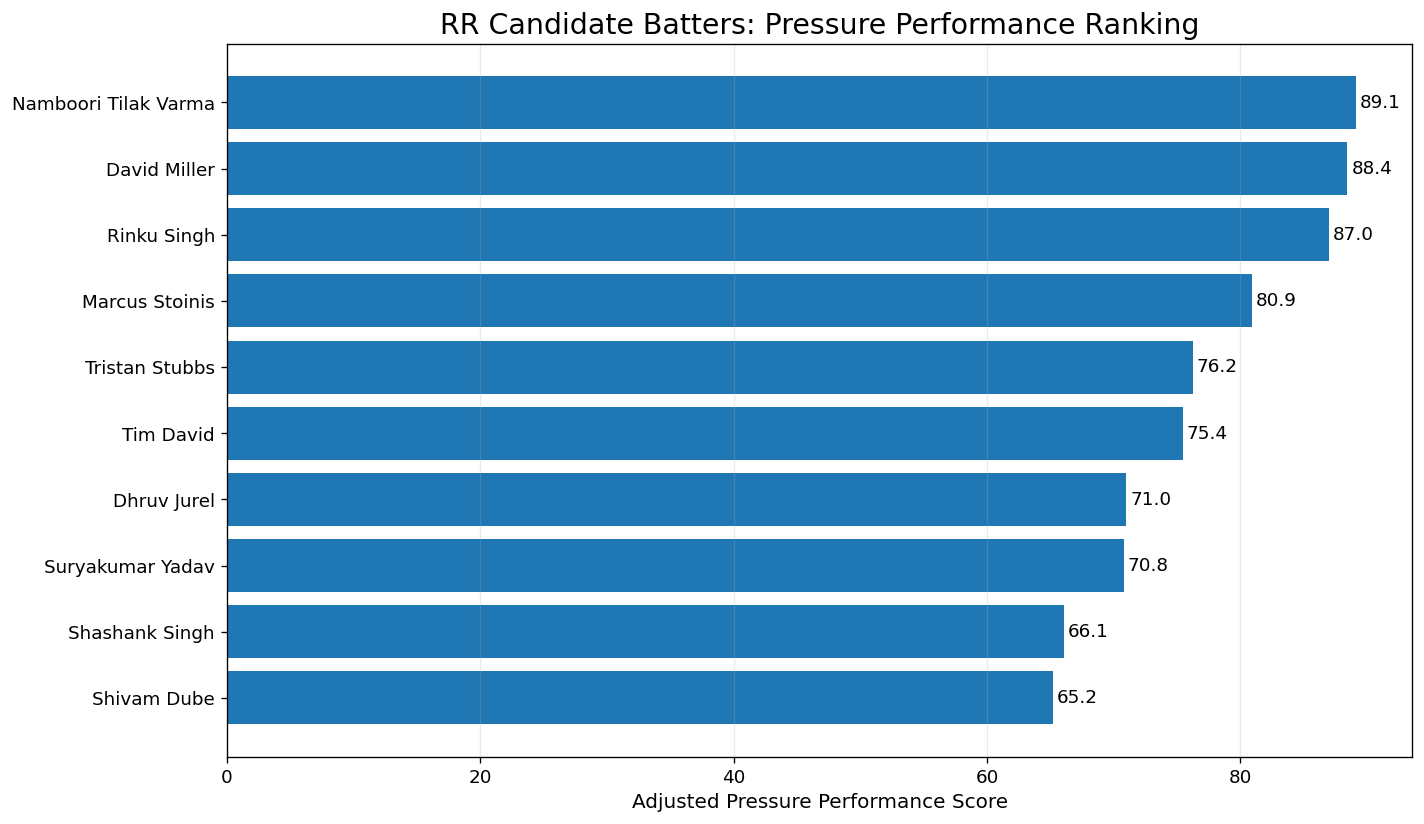

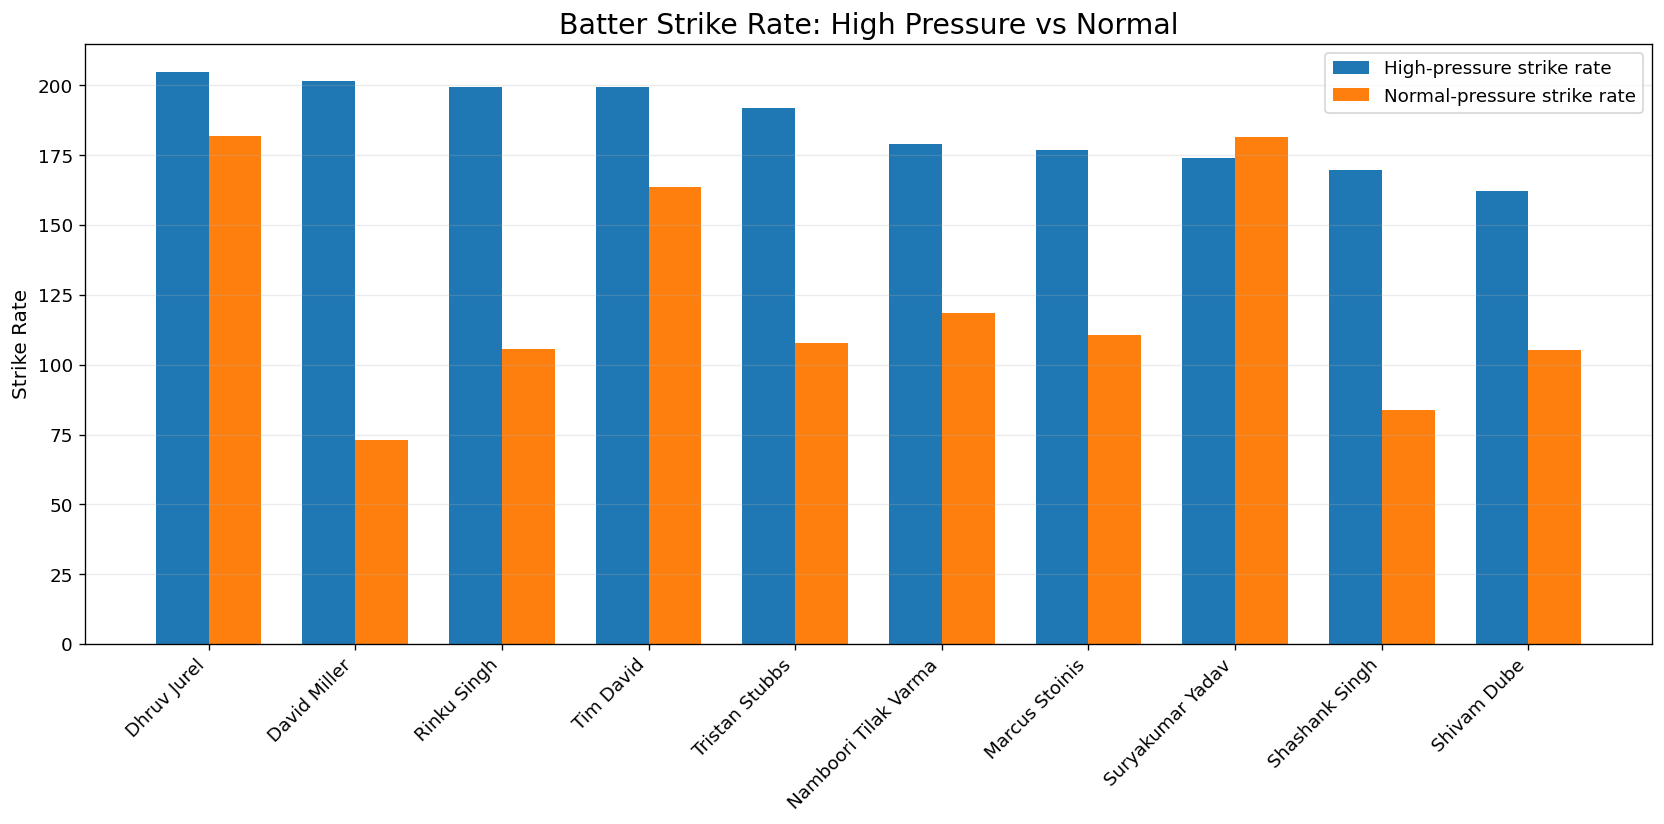

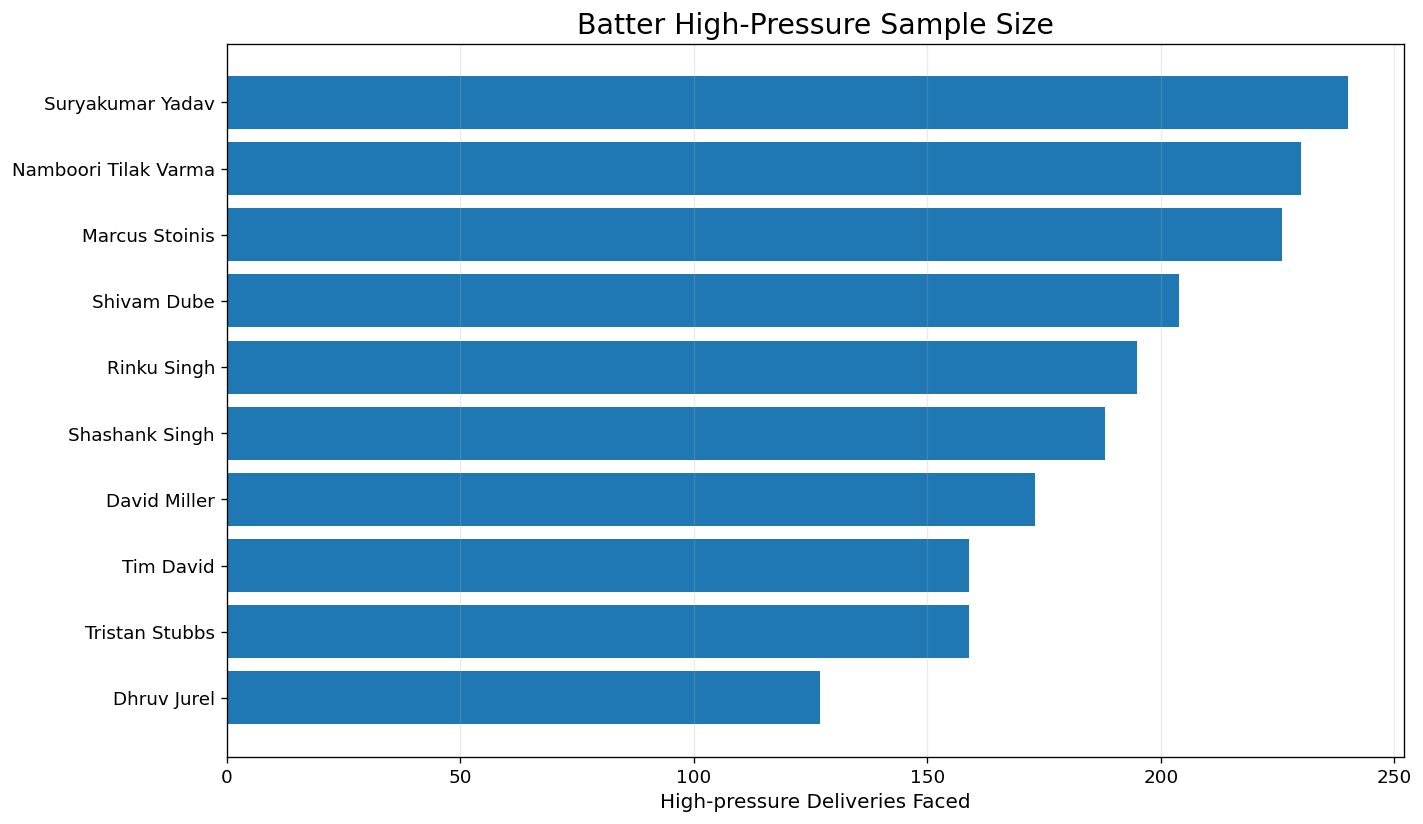

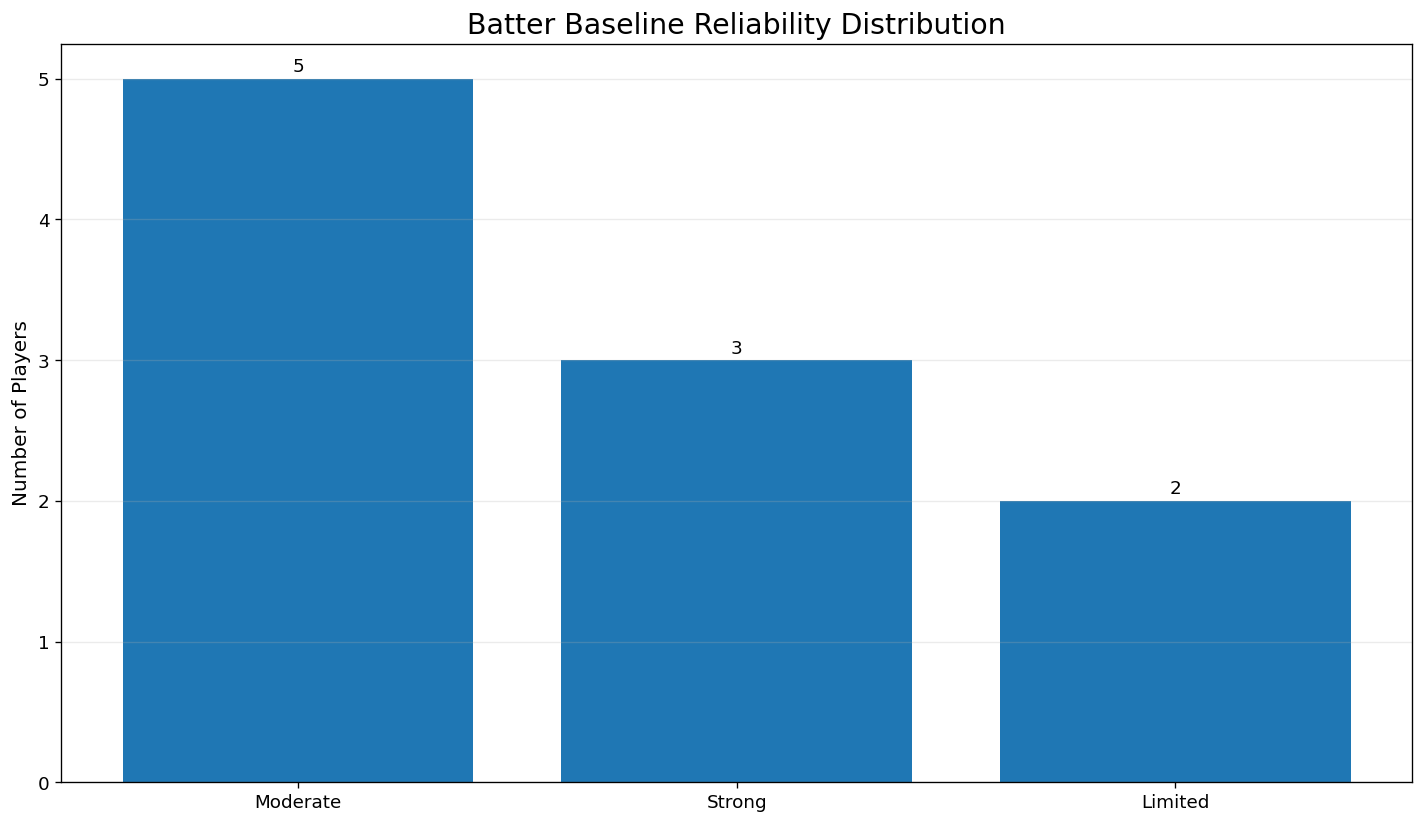

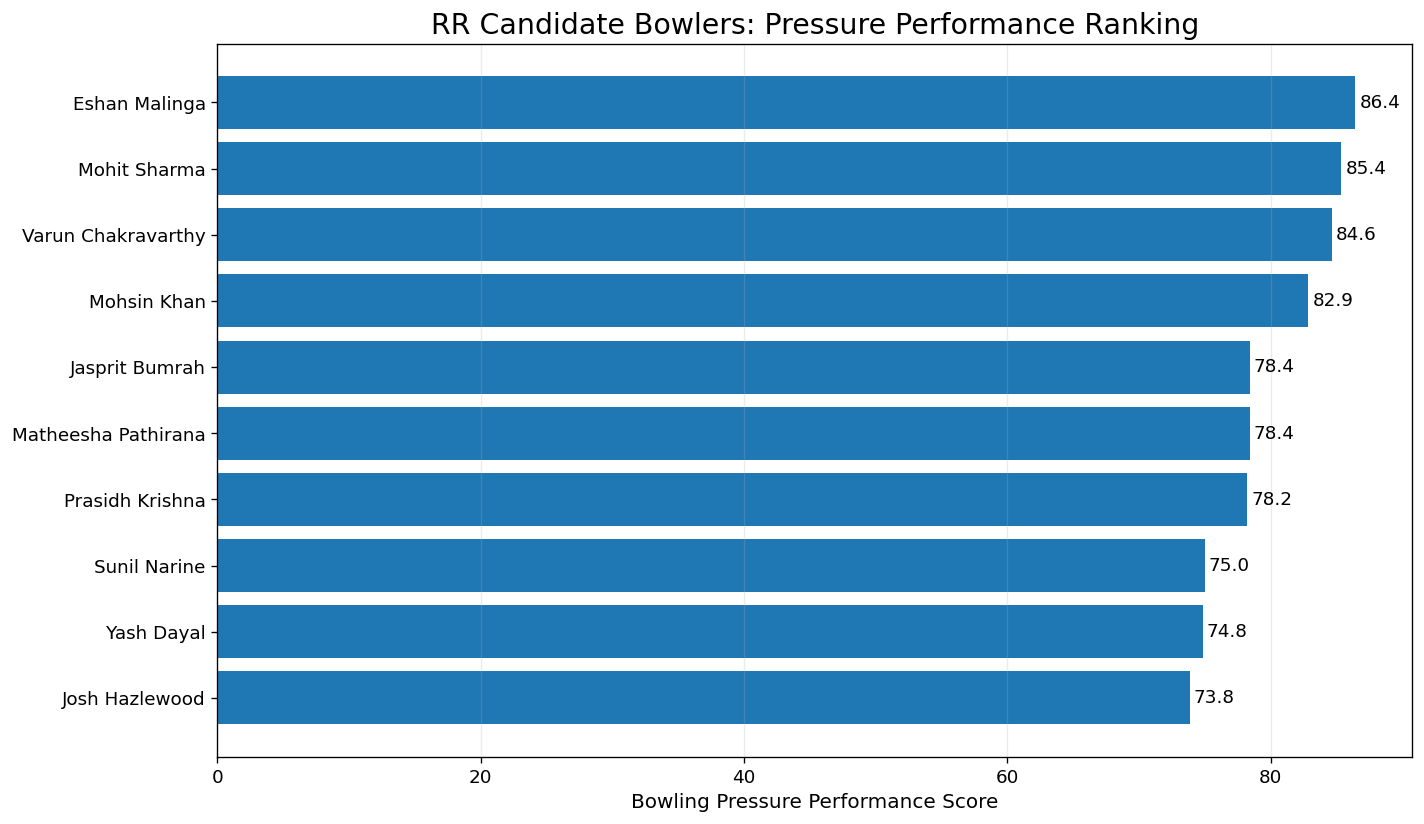

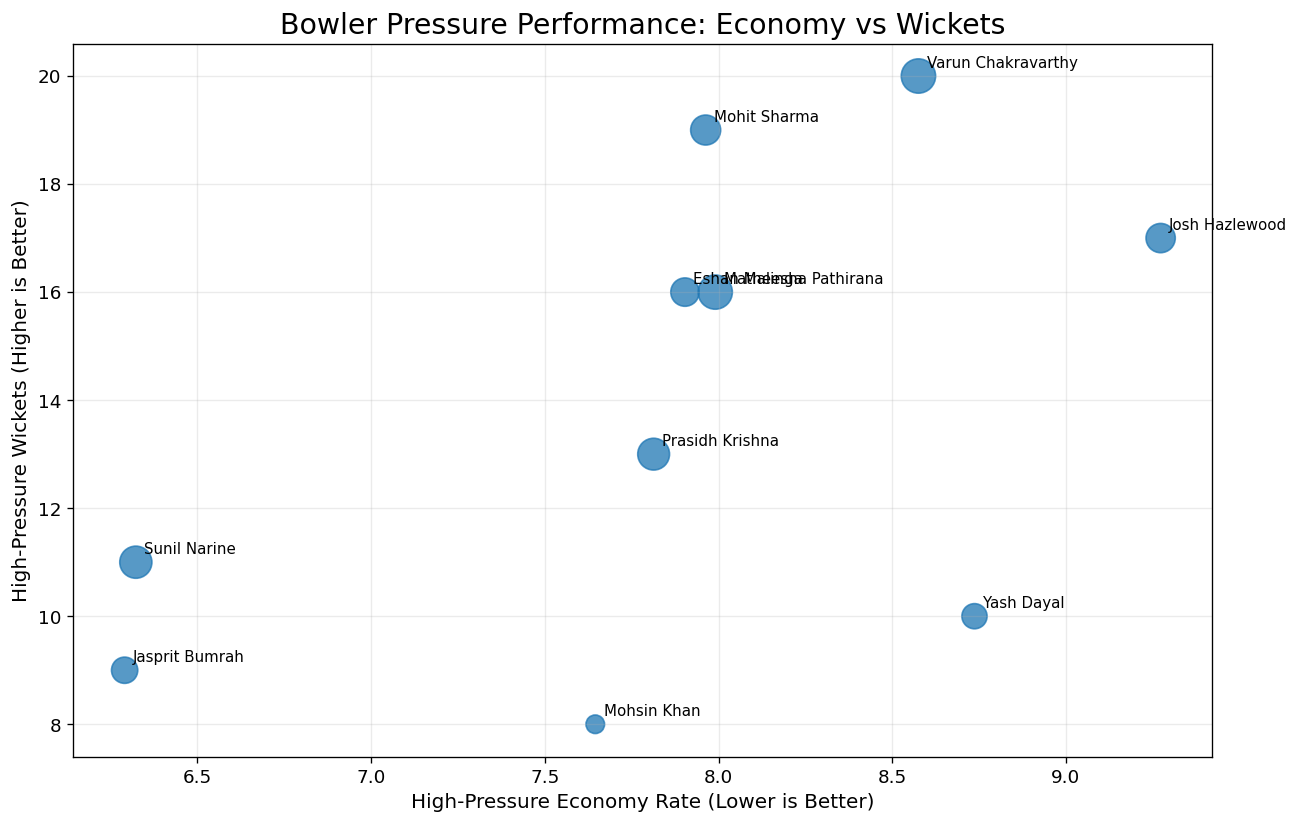

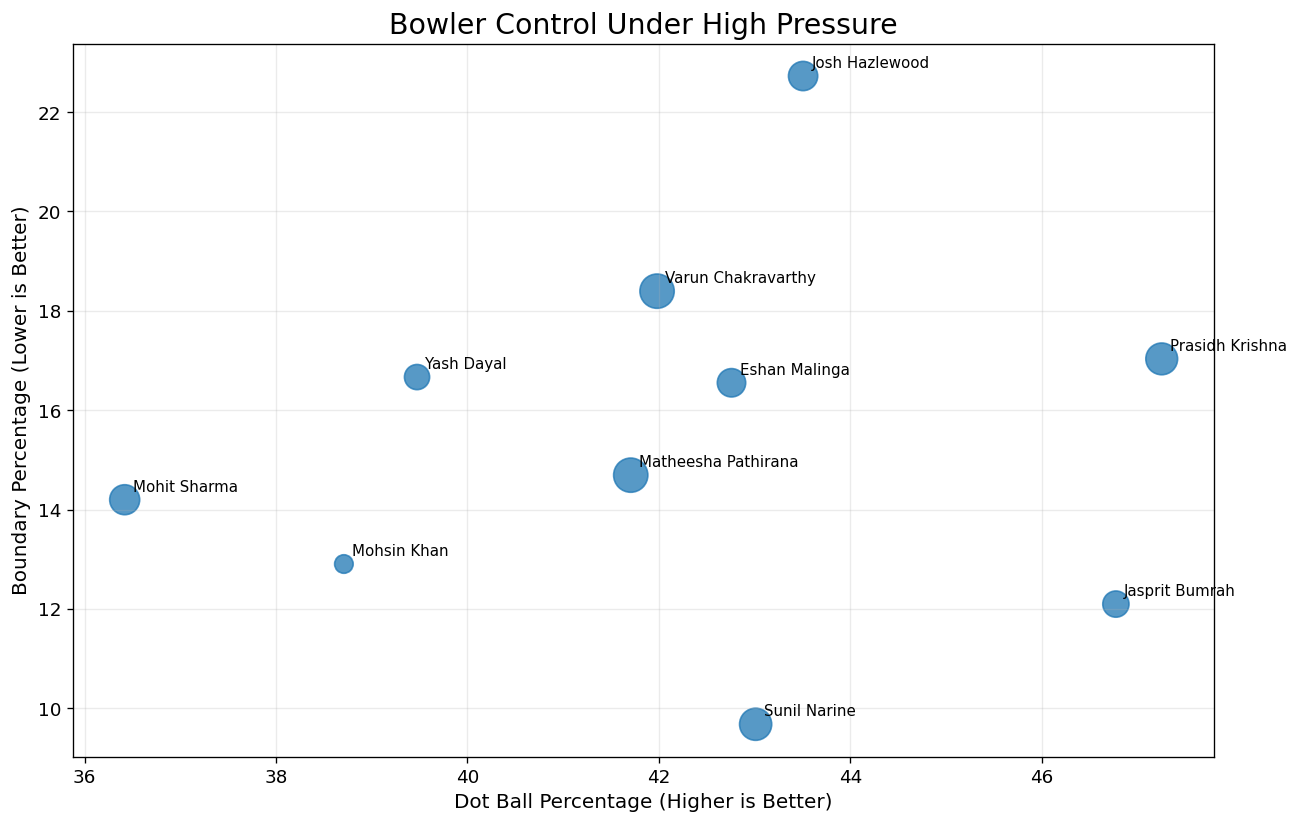

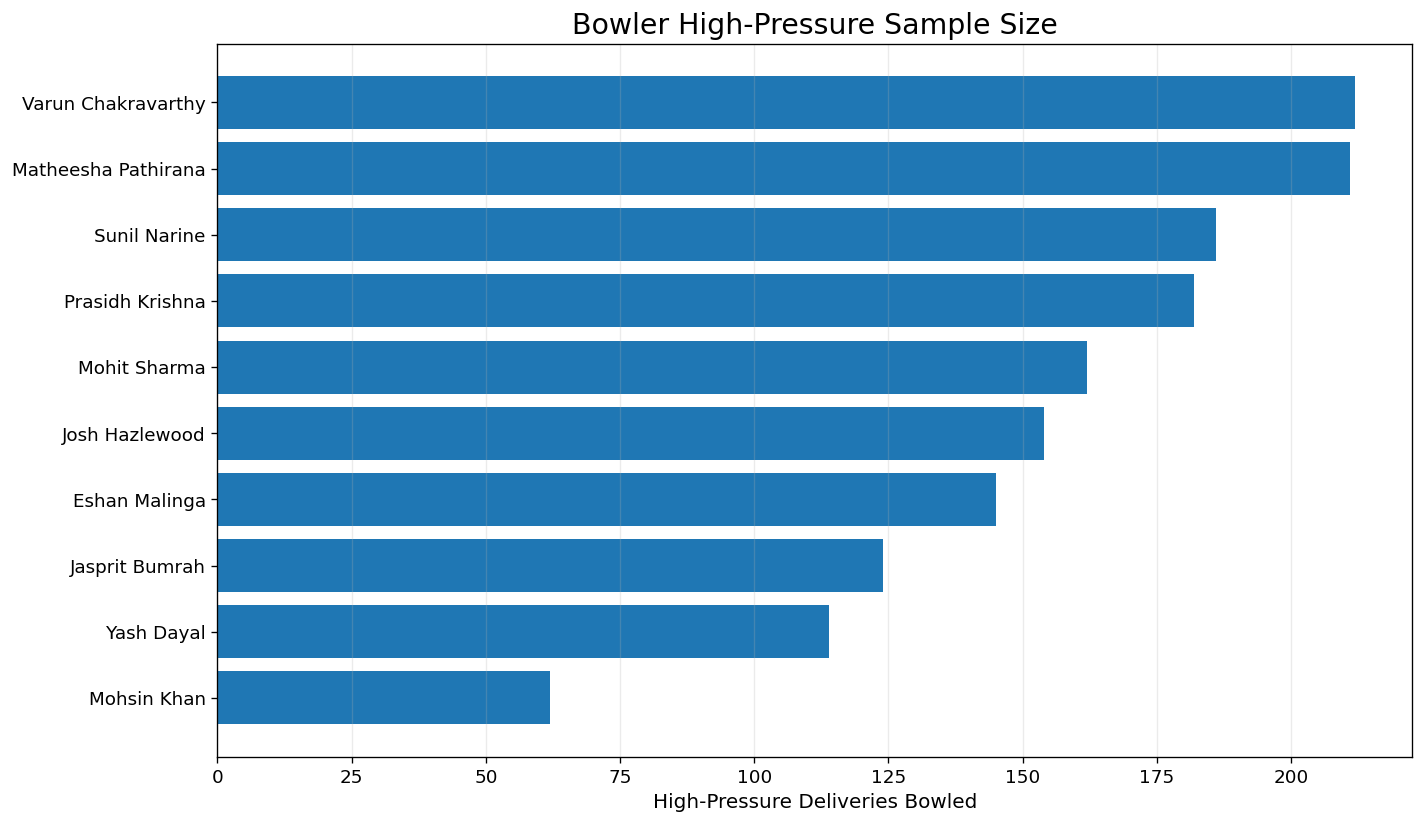

Successfully generated 8 charts.
Download: RR_All_Analytics_Charts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [174]:

import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. LOAD DATA
# ==========================================

BAT_FILE = "RR_Final_Role_Balanced_Batter_Top10.csv"
BOWL_FILE = "RR_Final_Role_Balanced_Bowler_Top10.csv"

bat = pd.read_csv(BAT_FILE)
bowl = pd.read_csv(BOWL_FILE)

OUT = "RR_Analytics_Charts"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (12, 7),
    "font.size": 11,
    "axes.titlesize": 17,
    "axes.labelsize": 12,
    "figure.dpi": 120
})

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{filename}.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# ==========================================
# 2. BATTER: PRESSURE SCORE RANKING
# ==========================================

d = bat.sort_values("adjusted_gap_score")

plt.figure()
plt.barh(d["striker_name"], d["adjusted_gap_score"])
plt.xlabel("Adjusted Pressure Performance Score")
plt.title("RR Candidate Batters: Pressure Performance Ranking")
plt.grid(axis="x", alpha=0.25)

for i, v in enumerate(d["adjusted_gap_score"]):
    plt.text(v + 0.3, i, f"{v:.1f}", va="center")

save_chart("01_Batter_Pressure_Ranking")

# ==========================================
# 3. BATTER: HIGH PRESSURE VS NORMAL SR
# ==========================================

d = bat.sort_values("high_sr", ascending=False)

x = np.arange(len(d))
width = 0.36

plt.figure(figsize=(14, 7))
plt.bar(x - width/2, d["high_sr"], width,
        label="High-pressure strike rate")
plt.bar(x + width/2, d["normal_sr"], width,
        label="Normal-pressure strike rate")

plt.xticks(x, d["striker_name"], rotation=45, ha="right")
plt.ylabel("Strike Rate")
plt.title("Batter Strike Rate: High Pressure vs Normal")
plt.legend()
plt.grid(axis="y", alpha=0.25)

save_chart("02_Batter_High_vs_Normal_SR")

# ==========================================
# 4. BATTER: HIGH PRESSURE SAMPLE SIZE
# ==========================================

d = bat.sort_values("high_balls")

plt.figure()
plt.barh(d["striker_name"], d["high_balls"])
plt.xlabel("High-pressure Deliveries Faced")
plt.title("Batter High-Pressure Sample Size")
plt.grid(axis="x", alpha=0.25)

save_chart("03_Batter_Pressure_Sample_Size")

# ==========================================
# 5. BATTER: BASELINE RELIABILITY
# ==========================================

quality = bat["baseline_quality"].value_counts()

plt.figure()
plt.bar(quality.index, quality.values)
plt.ylabel("Number of Players")
plt.title("Batter Baseline Reliability Distribution")
plt.grid(axis="y", alpha=0.25)

for i, v in enumerate(quality.values):
    plt.text(i, v + 0.05, str(v), ha="center")

save_chart("04_Batter_Baseline_Reliability")

# ==========================================
# 6. BOWLER: PRESSURE PERFORMANCE RANKING
# ==========================================

d = bowl.sort_values("gap_score")

plt.figure()
plt.barh(d["bowler_name"], d["gap_score"])
plt.xlabel("Bowling Pressure Performance Score")
plt.title("RR Candidate Bowlers: Pressure Performance Ranking")
plt.grid(axis="x", alpha=0.25)

for i, v in enumerate(d["gap_score"]):
    plt.text(v + 0.3, i, f"{v:.1f}", va="center")

save_chart("05_Bowler_Pressure_Ranking")

# ==========================================
# 7. BOWLER: ECONOMY VS WICKETS
# ==========================================

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    bowl["high_economy"],
    bowl["high_wickets"],
    s=bowl["high_balls"] * 2,
    alpha=0.75
)

for _, r in bowl.iterrows():
    plt.annotate(
        r["bowler_name"],
        (r["high_economy"], r["high_wickets"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("High-Pressure Economy Rate (Lower is Better)")
plt.ylabel("High-Pressure Wickets (Higher is Better)")
plt.title("Bowler Pressure Performance: Economy vs Wickets")
plt.grid(alpha=0.25)

save_chart("06_Bowler_Economy_vs_Wickets")

# ==========================================
# 8. BOWLER: DOT BALL VS BOUNDARY %
# ==========================================

plt.figure(figsize=(11, 7))

plt.scatter(
    bowl["dot_pct"],
    bowl["boundary_pct"],
    s=bowl["high_balls"] * 2,
    alpha=0.75
)

for _, r in bowl.iterrows():
    plt.annotate(
        r["bowler_name"],
        (r["dot_pct"], r["boundary_pct"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Dot Ball Percentage (Higher is Better)")
plt.ylabel("Boundary Percentage (Lower is Better)")
plt.title("Bowler Control Under High Pressure")
plt.grid(alpha=0.25)

save_chart("07_Bowler_Dot_vs_Boundary")

# ==========================================
# 9. BOWLER: HIGH PRESSURE SAMPLE SIZE
# ==========================================

d = bowl.sort_values("high_balls")

plt.figure()
plt.barh(d["bowler_name"], d["high_balls"])
plt.xlabel("High-Pressure Deliveries Bowled")
plt.title("Bowler High-Pressure Sample Size")
plt.grid(axis="x", alpha=0.25)

save_chart("08_Bowler_Pressure_Sample_Size")

# ==========================================
# 10. EXPORT ALL CHARTS AS ZIP
# ==========================================

zip_name = "RR_All_Analytics_Charts.zip"

with zipfile.ZipFile(zip_name, "w",
                     zipfile.ZIP_DEFLATED) as z:
    for file in os.listdir(OUT):
        if file.endswith(".png"):
            z.write(os.path.join(OUT, file), file)

print("Successfully generated", len(os.listdir(OUT)), "charts.")
print("Download:", zip_name)

files.download(zip_name)
